# Modelo de Deep Learning: previsão das encomendas do mês seguinte

**Âmbito:** Online ES e Online PT, cada um previsto em separado e somados. Dados de 2024-01-01 a 2025-12-31. Por agora só encomendas.

**Definição de encomenda:** pelo menos uma linha de venda (SALE) e unidades líquidas (vendidas menos canceladas) maiores que zero. As devoluções não reduzem encomendas. Ficam de fora 11.711 encomendas (2024-2025, ES + PT) que têm linhas de venda, mas unidades líquidas ≤ 0 depois dos cancelamentos. O critério é o mesmo do notebook baseline.

**Regras fixadas (iguais às do notebook baseline):**
- Para prever o mês M só se usam dados até ao último dia de M-2. O modelo é refeito todos os meses com dados até ao corte.
- Training: meses a prever de janeiro a julho de 2025 (para escolher). Test: agosto a dezembro de 2025, usado uma só vez (para reportar).
- Medidas: WAPE, Bias, RMSE e R², por mês, por mercado e ES + PT. O WAPE é a métrica de seleção e as outras três são reportadas. Se o RMSE ou o R² apontarem para uma configuração diferente da do WAPE, reportam-se as duas. O R² calcula-se também ao nível diário. Previsões diárias ou semanais somam-se a totais mensais antes de medir o erro.

**Referência a bater no Test (ES + PT, encomendas):** Baseline 3. No Test (5 meses), o WAPE é de 7,4% (diária) e 10,4% (mensal), e o Bias de 4,6% (diária) e 4,1% (mensal), reproduzidos neste notebook (prova DL1). O RMSE e o R² da Baseline 3 estão por preencher. A Baseline 6 serve só de informação.

**Decisões fixadas:**
- **Protocolo de seleção:** validação cruzada rolante nos 7 passos de janeiro a julho de 2025, sem mês de Validation separado. Grelha pequena, definida antes de ver resultados, com várias sementes. Escolhe-se pela média do WAPE e reporta-se a dispersão. O Test abre-se uma só vez, no fim.
- **Número de épocas:** tratado como hiperparâmetro, em vez de paragem antecipada (a testar).
- **Campanhas:** só as fixas (Black Friday, Natal, Dia da Mãe, Reyes, Valentim, Páscoa) entram como conhecidas de antemão. As pontuais não.
- **Categoria de produto:** fica de fora por agora.

**Perguntas a responder:**
1. O modelo de Deep Learning bate a Baseline 3 no Test?
2. Que variáveis, conhecidas no corte, ajudam a prever as encomendas?
3. Compensa prever por dia ou por semana?
4. Com tão pouca história, chega um modelo pequeno feito de raiz, ou ajuda um modelo já treinado?

## 1. Preparar o notebook

**O que vamos fazer:** construir a tabela diária a partir da camada silver (`slv_order_cab` e `slv_order_det`), criar a tabela mensal, copiar as ferramentas de avaliação (corte, `history`, WAPE, Bias, RMSE, R², `run`, `scorecard`) e ver que pacotes de Deep Learning existem neste computador.

**Objetivo:** garantir que este notebook mede exatamente como o baseline, antes de treinar qualquer modelo.

**Valores de controlo:**
- 731 dias por mercado.
- Encomendas mensais de Online ES e Online PT em janeiro de 2024 (80.536 e 33.096), novembro de 2025 (167.029 e 58.003) e dezembro de 2025 (129.546 e 35.111).
- Total ES + PT em 2024 (1.222.450 com a silver; eram 1.222.452 antes de a silver retirar linhas repetidas) e em 2025 (1.565.117).
- Uma linha por encomenda em `slv_order_cab` (2.799.278 encomendas no âmbito).
- Teste das ferramentas: com a previsão igual ao valor real, WAPE e Bias de 0,0%, RMSE de 0 e R² de 1; com o valor real + 10%, WAPE e Bias de 10,0%, e RMSE e R² iguais aos calculados à mão.

In [49]:
import importlib.metadata as md
import numpy as np
import pandas as pd
import duckdb
from pathlib import Path
import matplotlib.pyplot as plt
from lakehouse import LakeConfig, connect

# ---------- âmbito e regras (iguais ao notebook baseline) ----------
MARKETS = ['Online ES', 'Online PT']
START, END = '2024-01-01', '2025-12-31'
TARGET = 'orders'                      # por agora só encomendas

def fmt(n):
    # separador de milhares com ponto; int(round()) aceita inteiros e decimais
    return f"{int(round(n)):,}".replace(',', '.') if n is not None and not pd.isna(n) else '-'

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')     # percentagem com vírgula decimal
dec = lambda x, n=3: f"{x:.{n}f}".replace('.', ',') if x is not None and not pd.isna(x) else '-'     # número com vírgula decimal (R²)

# ---------- pasta de provas do notebook DL (separada da do baseline) ----------
EVID = Path('evidence_dl'); EVID.mkdir(exist_ok=True)
LOG = EVID / 'evidence_log.csv'
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
                     'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})

def _log(eid, kind, title, scope, filename):
    row = pd.DataFrame([{'id': eid, 'kind': kind, 'title': title, 'scope': scope, 'file': filename}])
    if LOG.exists():
        old = pd.read_csv(LOG)
        row = pd.concat([old[old['id'] != eid], row], ignore_index=True)   # substitui se o ID já existe
    row.to_csv(LOG, index=False)

def save_table(df, eid, title, scope):
    df.to_csv(EVID / f'{eid}.csv', index=False); _log(eid, 'table', title, scope, f'{eid}.csv'); print('Guardado:', EVID / f'{eid}.csv')

def save_fig(fig, eid, title, scope):
    fig.savefig(EVID / f'{eid}.png', dpi=200, bbox_inches='tight'); _log(eid, 'figure', title, scope, f'{eid}.png'); print('Guardado:', EVID / f'{eid}.png')

# ---------- tabela diária: construída aqui a partir da camada silver (slv_order_cab e slv_order_det) ----------
lake = LakeConfig.from_env()   # nomes dos buckets e credenciais vêm do cofre
con = connect()                # DuckDB em memória, já ligado ao lake
SILVER_CAB = f"'{lake.uri('silver', 'slv_order_cab')}.parquet'"
SILVER_DET = f"'{lake.uri('silver', 'slv_order_det')}.parquet'"
mk_in = ', '.join(f"'{m}'" for m in MARKETS)
mk_values = ', '.join(f"('{m}')" for m in MARKETS)

# 1) Encomendas do âmbito: a silver já tem uma linha por encomenda (order_id) e só de 2024 em diante.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_orders AS
SELECT order_id, mark_cod AS mark, order_date AS order_d
FROM read_parquet({SILVER_CAB})
WHERE mark_cod IN ({mk_in}) AND order_date BETWEEN DATE '{START}' AND DATE '{END}'
""")

# 2) Uma linha por encomenda: unidades e valor (com desconto, sem IVA, em euros). Cancelamentos têm sinal negativo.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_facts AS
SELECT s.order_id, s.mark, s.order_d,
       count(*) FILTER (WHERE d.type = 'SALE') AS sale_lines,
       COALESCE(sum(d.prod_qty) FILTER (WHERE d.type = 'SALE'), 0) AS sale_units,
       COALESCE(sum(d.prod_qty) FILTER (WHERE d.type = 'CANCELLED'), 0) AS cancel_units,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type IN ('SALE', 'CANCELLED')), 0) AS gross_value
FROM scope_orders s JOIN read_parquet({SILVER_DET}) d ON d.order_id = s.order_id
GROUP BY s.order_id, s.mark, s.order_d
""")

# 3) Devoluções por mercado e dia do movimento (só de encomendas do âmbito); unidades e valor em positivo.
#    Na silver, mov_date já é uma data (DATE): não se converte outra vez.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_returns AS
SELECT s.mark, d.mov_date AS ret_d,
       count(*) AS return_lines, -sum(d.prod_qty) AS return_units, -sum(d.amount_fixed_rate_w_disc_wo_vat) AS return_value
FROM read_parquet({SILVER_DET}) d JOIN scope_orders s ON d.order_id = s.order_id
WHERE d.type = 'RETURN' GROUP BY 1, 2
""")

# 4) Tabela diária por mercado (731 dias), com 0 nos dias sem registos; tipos explícitos (inteiros e decimais normais)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE daily_mk AS
WITH days AS (SELECT CAST(t AS DATE) AS day
              FROM generate_series(TIMESTAMP '{START}', TIMESTAMP '{END}', INTERVAL 1 DAY) AS g(t)),
mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
o AS (
  SELECT mark, order_d AS day,
         count(*) FILTER (WHERE sale_lines > 0) AS orders_with_sale,
         count(*) FILTER (WHERE sale_lines > 0 AND round(sale_units + cancel_units) > 0) AS orders,
         COALESCE(sum(sale_units + cancel_units) FILTER (WHERE sale_lines > 0), 0) AS net_units,
         COALESCE(sum(gross_value) FILTER (WHERE sale_lines > 0), 0) AS gross_sales
  FROM scope_facts GROUP BY 1, 2)
SELECT mk.mark, days.day,
       CAST(COALESCE(o.orders_with_sale, 0) AS BIGINT) AS orders_with_sale, CAST(COALESCE(o.orders, 0) AS BIGINT) AS orders,
       CAST(COALESCE(o.net_units, 0) AS DOUBLE) AS net_units, CAST(COALESCE(o.gross_sales, 0) AS DOUBLE) AS gross_sales,
       CAST(COALESCE(r.return_lines, 0) AS BIGINT) AS return_lines, CAST(COALESCE(r.return_units, 0) AS DOUBLE) AS return_units,
       CAST(COALESCE(r.return_value, 0) AS DOUBLE) AS return_value
FROM days CROSS JOIN mk
LEFT JOIN o ON o.mark = mk.mark AND o.day = days.day
LEFT JOIN scope_returns r ON r.mark = mk.mark AND r.ret_d = days.day
ORDER BY mk.mark, days.day
""")
daily = con.sql("SELECT * FROM daily_mk").df()
daily['day'] = pd.to_datetime(daily['day'])
daily['month'] = daily['day'].dt.to_period('M')
daily['net_sales'] = daily['gross_sales'] - daily['return_value']      # Net = Gross - devoluções registadas no dia

# ---------- tabela mensal por mercado (valores reais) ----------
VALUE_COLS = ['orders_with_sale', 'orders', 'net_units', 'gross_sales', 'return_lines', 'return_units', 'return_value']
monthly = daily.groupby(['mark', 'month'])[VALUE_COLS].sum().reset_index()
monthly['net_sales'] = monthly['gross_sales'] - monthly['return_value']

# ---------- controlo 1: estrutura (731 dias por mercado, datas completas) ----------
est = daily.groupby('mark').agg(dias=('day', 'nunique'), primeiro=('day', 'min'), ultimo=('day', 'max')).reset_index()
est['bate'] = (est['dias'] == 731) & (est['primeiro'] == pd.Timestamp(START)) & (est['ultimo'] == pd.Timestamp(END))
print('--- Controlo 1: estrutura da tabela diária (esperado 731 dias por mercado, de 2024-01-01 a 2025-12-31) ---')
display(est)

# ---------- controlo 2: encomendas mensais iguais às do notebook baseline (M1 do notebook de exploração) ----------
ref = {('Online ES', '2024-01'): 80536, ('Online PT', '2024-01'): 33096,
       ('Online ES', '2025-11'): 167029, ('Online PT', '2025-11'): 58003,
       ('Online ES', '2025-12'): 129546, ('Online PT', '2025-12'): 35111}
ck = pd.DataFrame([{'mercado': k[0], 'mês': k[1],
                    'medido': int(monthly[(monthly['mark'] == k[0]) & (monthly['month'] == pd.Period(k[1], 'M'))]['orders'].iloc[0]),
                    'esperado': v} for k, v in ref.items()])
ck['bate'] = ck['medido'] == ck['esperado']
print('\n--- Controlo 2: encomendas mensais (iguais às do notebook baseline) ---')
display(ck)
tot_year = monthly.groupby(monthly['month'].dt.year)['orders'].sum()
esp_ano = {2024: 1222450, 2025: 1565117}          # com a silver (antes da silver: 2024 = 1.222.452, porque a silver retira linhas repetidas)
print('Encomendas ES + PT por ano:', {int(y): fmt(v) for y, v in tot_year.items()},
      '(esperado com a silver: 2024: 1.222.450 | 2025: 1.565.117) | bate:', all(int(tot_year[y]) == v for y, v in esp_ano.items()))

# ---------- controlo 2b: sanidade da leitura da silver ----------
n_o, n_u = con.execute("SELECT count(*), count(DISTINCT order_id) FROM scope_orders").fetchall()[0]
print('\nEncomendas no âmbito (slv_order_cab):', fmt(n_o), '| order_id distintos:', fmt(n_u), '| bate (uma linha por encomenda):', bool(n_o == n_u))
ret_m = daily[daily['day'] < '2024-07-01'].groupby(daily['day'].dt.to_period('M'))['return_lines'].sum()
print('Linhas de devolução de janeiro a junho de 2024 (ES + PT):', [fmt(v) for v in ret_m.tolist()],
      '(antes da silver: 28.104, 25.614, 18.651, 20.347, 27.351, 33.770; pode diferir um pouco, a silver retira linhas repetidas)')

# ---------- regras do teste (decisões fixadas; iguais às do notebook baseline) ----------
FIRST = pd.Period('2024-01', 'M')
TARGETS = [pd.Period(f'2025-{i:02d}', 'M') for i in range(1, 13)]      # 12 meses-alvo de 2025

def cutoff_date(m):
    # corte: último dia do mês M-2. Ex.: para prever setembro usamos dados até 31 de julho.
    return (pd.Period(m, 'M') - 2).end_time.normalize()

def split_of(m):
    # Training (jan a jul de 2025) para escolher; Test (ago a dez de 2025) só para reportar, uma única vez
    return 'Training' if pd.Period(m, 'M') <= pd.Period('2025-07', 'M') else 'Test'

def history(df, m):
    # devolve só os dias até ao corte do mês-alvo; nunca devolve dados do futuro
    h = df[df['day'] <= cutoff_date(m)]
    assert h['day'].max() <= cutoff_date(m), 'fuga de informação: dados depois do corte'
    return h

# ---------- controlo 3: a função history corta bem ----------
h = history(daily, pd.Period('2025-09', 'M'))
print('\nÚltimo dia visível ao prever setembro de 2025:', h['day'].max().date(), '(esperado 2025-07-31)')

# ---------- métricas (iguais às do notebook baseline) ----------
def wape(actual, forecast):
    # soma dos erros absolutos a dividir pela soma dos valores reais
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return np.abs(f - a).sum() / a.sum()

def bias(actual, forecast):
    # positivo = prevê acima do real; negativo = prevê abaixo
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return (f - a).sum() / a.sum()

def rmse(actual, forecast):
    # raiz do erro quadrático médio, na unidade do alvo (encomendas); penaliza mais os erros grandes
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return float(np.sqrt(np.mean((f - a) ** 2)))

def r2(actual, forecast):
    # 1 - (soma dos erros ao quadrado) / (soma dos desvios dos valores reais à sua média); 1 = perfeito, 0 = tão bom como prever a média, < 0 = pior
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    sst = ((a - a.mean()) ** 2).sum()
    return float(1 - ((f - a) ** 2).sum() / sst) if sst > 0 else float('nan')

assert abs(wape([100, 200], [110, 180]) - 30 / 300) < 1e-12      # 10 + 20 de erro sobre 300 reais
assert abs(bias([100, 200], [110, 180]) - (-10 / 300)) < 1e-12
assert abs(rmse([100, 200], [110, 180]) - np.sqrt((100 + 400) / 2)) < 1e-12      # erros 10 e -20
assert abs(r2([100, 200], [110, 180]) - (1 - 500 / 5000)) < 1e-12                # desvios à média (150): 50 e 50, soma dos quadrados 5000

# ---------- ferramentas de avaliação (iguais às do notebook baseline) ----------
def run(method_name, func, target='orders', markets=None):
    # func(h_mercado, mês_alvo, coluna_alvo) devolve a previsão mensal ou None se o método não existe nesse mês.
    rows = []
    for m in TARGETS:
        hh = history(daily, m)
        for mk in (markets or MARKETS):
            f = func(hh[hh['mark'] == mk], m, target)
            if f is not None:
                rows.append({'method': method_name, 'mark': mk, 'month': m, 'forecast': float(f)})
    return pd.DataFrame(rows)

def _metricas(d, n_name):
    # d tem forecast, actual, method, mark e split (uma linha por mês ou por dia); devolve as 4 métricas por método, mercado e período
    d = d.copy()
    d['abs_err'] = (d['forecast'] - d['actual']).abs(); d['err'] = d['forecast'] - d['actual']; d['sq_err'] = d['err'] ** 2
    d['sq_dev'] = d.groupby(['method', 'mark', 'split'])['actual'].transform(lambda x: (x - x.mean()) ** 2)      # desvio à média do próprio período (para o R²)
    g = d.groupby(['method', 'mark', 'split'], as_index=False).agg(
        abs_err=('abs_err', 'sum'), err=('err', 'sum'), sq_err=('sq_err', 'sum'), sq_dev=('sq_dev', 'sum'),
        actual=('actual', 'sum'), n=('actual', 'count'))
    g[n_name] = g['n']
    g['WAPE'] = g['abs_err'] / g['actual']; g['Bias'] = g['err'] / g['actual']
    g['RMSE'] = np.sqrt(g['sq_err'] / g['n'])
    g['R2'] = np.where(g['sq_dev'] > 0, 1 - g['sq_err'] / g['sq_dev'].where(g['sq_dev'] > 0), np.nan)
    return g[['method', 'mark', 'split', n_name, 'WAPE', 'Bias', 'RMSE', 'R2']]

def scorecard(fc, target='orders'):
    # previsões mensais: junta o valor real, soma os dois mercados (ES + PT) e calcula WAPE, viés, RMSE e R² por método, mercado e período
    act = monthly.set_index(['mark', 'month'])[target].rename('actual')
    d = fc.join(act, on=['mark', 'month'])
    tot = d.groupby(['method', 'month'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')      # o total só conta meses com previsão dos dois mercados
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['month'].map(split_of)
    return _metricas(d, 'months')

def scorecard_daily(fcd, target='orders'):
    # previsões diárias (colunas method, mark, day, forecast): mede ao nível do dia, para o R² diário pedido. ES + PT soma os mercados dia a dia.
    act = daily.set_index(['mark', 'day'])[target].rename('actual')
    d = fcd.join(act, on=['mark', 'day'])
    tot = d.groupby(['method', 'day'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['day'].dt.to_period('M').map(split_of)
    return _metricas(d, 'days')

# ---------- controlo 4: testar as ferramentas com previsões de brincadeira ----------
# valor real: WAPE 0,0%, viés 0,0%, RMSE 0 e R² 1 | valor real + 10%: WAPE e viés 10,0%; RMSE e R² calculados à mão abaixo
fc_ok = monthly[monthly['month'].isin(TARGETS)][['mark', 'month', 'orders']].rename(columns={'orders': 'forecast'})
fc_ok['method'] = 'test: real value'
fc_up = fc_ok.copy(); fc_up['forecast'] *= 1.10; fc_up['method'] = 'test: real value + 10%'
sc = scorecard(pd.concat([fc_ok, fc_up], ignore_index=True))

# valores esperados à mão, ES + PT, Training (janeiro a julho de 2025), só com numpy: com previsão = 1,10 × real, erro = 0,10 × real
real_tr = monthly[monthly['month'].isin([m for m in TARGETS if split_of(m) == 'Training'])].groupby('month')['orders'].sum().to_numpy(float)
rmse_esp = 0.10 * np.sqrt(np.mean(real_tr ** 2))
r2_esp = 1 - 0.01 * (real_tr ** 2).sum() / ((real_tr - real_tr.mean()) ** 2).sum()
um = sc[(sc['method'] == 'test: real value + 10%') & (sc['mark'] == 'ES + PT') & (sc['split'] == 'Training')].iloc[0]
zero = sc[(sc['method'] == 'test: real value')]
ok4 = bool(np.allclose(zero[['WAPE', 'Bias', 'RMSE']].to_numpy(float), 0) and np.allclose(zero['R2'].to_numpy(float), 1)
           and abs(um['WAPE'] - 0.10) < 1e-12 and abs(um['Bias'] - 0.10) < 1e-12
           and abs(um['RMSE'] - rmse_esp) < 1e-6 and abs(um['R2'] - r2_esp) < 1e-12)
sc_show = sc.copy()
for c in ('WAPE', 'Bias'): sc_show[c] = sc_show[c].map(pct)
sc_show['RMSE'] = sc_show['RMSE'].map(fmt); sc_show['R2'] = sc_show['R2'].map(dec)
print('\n--- Controlo 4: teste das ferramentas, ao nível do mês (valor real: 0,0%, 0,0%, RMSE 0, R² 1 | valor real + 10%: 10,0%, 10,0%) ---')
display(sc_show)
print('ES + PT, Training, valor real + 10%: RMSE', fmt(um['RMSE']), '(à mão:', fmt(rmse_esp) + ') | R²', dec(um['R2']), '(à mão:', dec(r2_esp) + ')')
print('Controlo 4 (mensal) bate:', ok4)

# o mesmo teste ao nível do dia (o R² diário)
fcd_ok = daily[daily['day'] >= '2025-01-01'][['mark', 'day', 'orders']].rename(columns={'orders': 'forecast'})
fcd_ok['method'] = 'test: real value'
fcd_up = fcd_ok.copy(); fcd_up['forecast'] *= 1.10; fcd_up['method'] = 'test: real value + 10%'
scd = scorecard_daily(pd.concat([fcd_ok, fcd_up], ignore_index=True))
real_d = daily[(daily['day'] >= '2025-01-01') & (daily['day'] <= '2025-07-31')].groupby('day')['orders'].sum().to_numpy(float)
r2d_esp = 1 - 0.01 * (real_d ** 2).sum() / ((real_d - real_d.mean()) ** 2).sum()
ud = scd[(scd['method'] == 'test: real value + 10%') & (scd['mark'] == 'ES + PT') & (scd['split'] == 'Training')].iloc[0]
okd = bool(abs(ud['WAPE'] - 0.10) < 1e-12 and abs(ud['R2'] - r2d_esp) < 1e-12
           and np.allclose(scd[scd['method'] == 'test: real value']['R2'].to_numpy(float), 1))
print('Controlo 4 (diário): ES + PT, Training, valor real + 10%: WAPE', pct(ud['WAPE']), '| R² diário', dec(ud['R2']), '(à mão:', dec(r2d_esp) + ') | bate:', okd)
t = run('test: constant', lambda hh, m, tgt: 1.0)
print('Previsões geradas pelo método de teste:', len(t), '(esperado 12 meses x 2 mercados = 24)')

# ---------- ferramentas de Deep Learning instaladas neste ambiente ----------
def versao(pacote):
    try:
        return md.version(pacote)
    except md.PackageNotFoundError:
        return 'não instalado'

libs = pd.DataFrame({'pacote': ['torch', 'tensorflow', 'keras', 'scikit-learn', 'duckdb'],
                     'versão': [versao(p) for p in ['torch', 'tensorflow', 'keras', 'scikit-learn', 'duckdb']]})
print('\n--- Pacotes disponíveis para o modelo ---')
display(libs)
if versao('torch') != 'não instalado':
    import torch
    print('PyTorch: GPU CUDA =', torch.cuda.is_available(), '| GPU Apple (MPS) =', torch.backends.mps.is_available(),
          '| nº de threads de CPU =', torch.get_num_threads())

# Eficiência: a construção da tabela diária percorre slv_order_det (n linhas, O(n)) com 3 junções por order_id; as agregações seguintes são O(d·m) sobre a tabela diária (731 dias × 2 mercados = 1.462 linhas); cada chamada a history()
# filtra a tabela uma vez, O(d·m); run() faz 12 meses × 2 mercados = 24 filtros; scorecard() é O(k) com k = nº de previsões mensais; scorecard_daily() é O(k·log k) por causa dos
# agrupamentos, com k = nº de previsões diárias (até 365 por mercado e método). Espaço O(d·m).

--- Controlo 1: estrutura da tabela diária (esperado 731 dias por mercado, de 2024-01-01 a 2025-12-31) ---


,mark,dias,primeiro,ultimo,bate
0,Online ES,731,2024-01-01,2025-12-31,True
1,Online PT,731,2024-01-01,2025-12-31,True



--- Controlo 2: encomendas mensais (iguais às do notebook baseline) ---


,mercado,mês,medido,esperado,bate
0,Online ES,2024-01,80536,80536,True
1,Online PT,2024-01,33096,33096,True
2,Online ES,2025-11,167029,167029,True
3,Online PT,2025-11,58003,58003,True
4,Online ES,2025-12,129546,129546,True
5,Online PT,2025-12,35111,35111,True


Encomendas ES + PT por ano: {2024: '1.222.450', 2025: '1.565.117'} (esperado com a silver: 2024: 1.222.450 | 2025: 1.565.117) | bate: True

Encomendas no âmbito (slv_order_cab): 2.799.278 | order_id distintos: 2.799.278 | bate (uma linha por encomenda): True
Linhas de devolução de janeiro a junho de 2024 (ES + PT): ['27.803', '25.255', '18.527', '20.190', '27.184', '33.612'] (antes da silver: 28.104, 25.614, 18.651, 20.347, 27.351, 33.770; pode diferir um pouco, a silver retira linhas repetidas)

Último dia visível ao prever setembro de 2025: 2025-07-31 (esperado 2025-07-31)

--- Controlo 4: teste das ferramentas, ao nível do mês (valor real: 0,0%, 0,0%, RMSE 0, R² 1 | valor real + 10%: 10,0%, 10,0%) ---


,method,mark,split,months,WAPE,Bias,RMSE,R2
0,test: real value,ES + PT,Test,5,"0,0%","0,0%",0,"1,000"
1,test: real value,ES + PT,Training,7,"0,0%","0,0%",0,"1,000"
2,test: real value,Online ES,Test,5,"0,0%","0,0%",0,"1,000"
3,test: real value,Online ES,Training,7,"0,0%","0,0%",0,"1,000"
4,test: real value,Online PT,Test,5,"0,0%","0,0%",0,"1,000"
5,test: real value,Online PT,Training,7,"0,0%","0,0%",0,"1,000"
6,test: real value + 10%,ES + PT,Test,5,"10,0%","10,0%",14.611,"0,920"
7,test: real value + 10%,ES + PT,Training,7,"10,0%","10,0%",13.134,"0,876"
8,test: real value + 10%,Online ES,Test,5,"10,0%","10,0%",11.028,"0,919"
9,test: real value + 10%,Online ES,Training,7,"10,0%","10,0%",9.698,"0,861"


ES + PT, Training, valor real + 10%: RMSE 13.134 (à mão: 13.134) | R² 0,876 (à mão: 0,876)
Controlo 4 (mensal) bate: True
Controlo 4 (diário): ES + PT, Training, valor real + 10%: WAPE 10,0% | R² diário 0,948 (à mão: 0,948) | bate: True
Previsões geradas pelo método de teste: 24 (esperado 12 meses x 2 mercados = 24)

--- Pacotes disponíveis para o modelo ---


,pacote,versão
0,torch,2.15.0+cpu
1,tensorflow,não instalado
2,keras,não instalado
3,scikit-learn,1.9.1
4,duckdb,1.5.6


PyTorch: GPU CUDA = False | GPU Apple (MPS) = False | nº de threads de CPU = 1


### 1a. Conclusões do ponto 1

**A base de dados está certa.** Construímos a tabela diária a partir da camada silver, e os totais coincidem com os do notebook baseline: os meses de controlo, o total de cada ano e uma linha por encomenda. Só há 2 encomendas de diferença em 2024, porque a silver retirou linhas repetidas.

**Algumas encomendas não contam.** Cerca de 11.700 encomendas foram vendidas e depois totalmente canceladas. Pela nossa regra, não são encomendas.

**As ferramentas de medição funcionam.** Medimos o erro de 4 formas: WAPE, Bias, RMSE e R². Testámo-las com previsões de brincadeira, e os resultados coincidem com o cálculo feito à mão, ao nível do mês e do dia.


## 2. Instalar e verificar o PyTorch

**O que vamos fazer:** instalar o PyTorch (versão CPU), reiniciar o kernel e verificar duas coisas: que treina uma rede minúscula e que a mesma semente dá exatamente o mesmo resultado.

**Objetivo:** garantir que o ambiente de Deep Learning funciona e que as corridas com sementes são repetíveis, porque o relatório vai comparar várias sementes.

**Valores de controlo:** a mesma semente (42 e 42) dá o mesmo resultado; sementes diferentes (42 e 7) dão resultados diferentes; o erro da rede de teste desce com o treino.

In [2]:
# Instala o PyTorch (versão CPU). Depois: Kernel > Restart Kernel e volta a correr a célula 1.
%pip install torch --index-url https://download.pytorch.org/whl/cpu

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.


In [4]:
import random
import importlib.metadata as md
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ---------- versão e hardware ----------
print('PyTorch:', torch.__version__, '| GPU CUDA =', torch.cuda.is_available(),
      '| GPU Apple (MPS) =', torch.backends.mps.is_available(), '| threads de CPU =', torch.get_num_threads())
DEVICE = 'cpu'     # modelos pequenos: o CPU chega e dá resultados mais repetíveis

# ---------- sementes: a mesma semente tem de dar exatamente o mesmo resultado ----------
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)       # falha em vez de dar resultados diferentes em silêncio

def mini_treino(seed, passos=200):
    # rede minúscula (8 -> 16 -> 1) treinada com perda de erro absoluto sobre dados sintéticos de teste
    set_seed(seed)
    g = torch.Generator().manual_seed(123)         # dados de teste iguais em todas as corridas
    X = torch.randn(256, 8, generator=g)
    y = X[:, :1] * 2.0 + 0.5 + 0.1 * torch.randn(256, 1, generator=g)
    net = nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, 1))     # a inicialização depende da semente
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    perda = nn.L1Loss()
    antes = perda(net(X), y).item()
    for _ in range(passos):
        opt.zero_grad(); l = perda(net(X), y); l.backward(); opt.step()
    return antes, l.item(), sum(p.numel() for p in net.parameters())

a, b, c = mini_treino(42), mini_treino(42), mini_treino(7)
chk = pd.DataFrame([
    {'teste': 'mesma semente (42 e 42) dá o mesmo resultado', 'bate': a == b},
    {'teste': 'semente diferente (42 e 7) dá resultado diferente', 'bate': a != c},
    {'teste': 'o erro desce com o treino (L1: antes > depois)', 'bate': a[1] < a[0]},
])
print('\n--- Controlo: PyTorch e sementes ---')
display(chk)
print(f'Erro L1 antes e depois do treino (semente 42): {a[0]:.3f} -> {a[1]:.3f} | parâmetros da rede de teste: {a[2]}')

# ---------- MLflow (registo das corridas): só vemos se está instalado ----------
try:
    print('MLflow:', md.version('mlflow'))
except md.PackageNotFoundError:
    print('MLflow: não instalado')

# Eficiência: cada treino é O(passos · n · p) em tempo (n = 256 exemplos, p = 161 parâmetros) e O(n · p) em espaço; é de milissegundos.

PyTorch: 2.15.0+cpu | GPU CUDA = False | GPU Apple (MPS) = False | threads de CPU = 12

--- Controlo: PyTorch e sementes ---


,teste,bate
0,mesma semente (42 e 42) dá o mesmo resultado,True
1,semente diferente (42 e 7) dá resultado diferente,True
2,o erro desce com o treino (L1: antes > depois),True


Erro L1 antes e depois do treino (semente 42): 1.702 -> 0.063 | parâmetros da rede de teste: 161
MLflow: 3.17.0


### 2a. Conclusões

**Confirmado (tabela inteira):**
- O PyTorch 2.15.0 (versão CPU) está instalado e treina. A CPU chega para o nosso modelo pequeno.
- A mesma semente dá exatamente o mesmo resultado, e uma semente diferente dá um resultado diferente. As corridas com várias sementes vão ser repetíveis neste computador.
- O erro de uma rede de teste desce com o treino, por isso o ambiente treina como esperado. Isto não diz nada ainda sobre a qualidade da previsão.
- O MLflow (versão 3.17.0) já está instalado neste ambiente.

## 3. Ligar ao MLflow do pipeline

**O que vamos fazer:** ligar ao servidor MLflow do pipeline, criar a experiência deste trabalho e escrever e ler de volta uma corrida de teste (que depois se apaga).

**Objetivo:** garantir que as corridas do modelo (parâmetros, sementes, erros por mês) ficam registadas e comparáveis, para mostrar as várias tentativas.


In [5]:
import os
import mlflow
from mlflow import MlflowClient

# ---------- endereço do servidor: no Jupyter do pipeline vem da variável MLFLOW_TRACKING_URI ----------
URI = os.environ.get('MLFLOW_TRACKING_URI')
if not URI:
    raise RuntimeError("A variável MLFLOW_TRACKING_URI não está definida. No Jupyter do pipeline devia ser http://mlflow:5000.")
os.environ.setdefault('MLFLOW_HTTP_REQUEST_TIMEOUT', '10')       # falha depressa se o servidor não responder
os.environ.setdefault('MLFLOW_HTTP_REQUEST_MAX_RETRIES', '1')
mlflow.set_tracking_uri(URI)
EXPERIMENT = 'dl_encomendas_parfois'                               # nome da experiência deste trabalho
print('Servidor MLflow:', mlflow.get_tracking_uri(), '| cliente:', mlflow.__version__)

# ---------- controlo 1: o servidor responde ----------
client = MlflowClient()
n_exp = len(client.search_experiments())
print('Controlo 1: o servidor responde; experiências existentes:', n_exp)

# ---------- controlo 2: escrever e ler de volta uma corrida de teste ----------
mlflow.set_experiment(EXPERIMENT)
with mlflow.start_run(run_name='teste_ligacao') as r:
    mlflow.log_param('seed', 42)
    mlflow.log_metric('wape_teste', 0.0)
    mlflow.set_tag('notebook', 'modelo DL')
lido = client.get_run(r.info.run_id)
ok = lido.data.params.get('seed') == '42' and lido.data.metrics.get('wape_teste') == 0.0
print('Controlo 2: corrida de teste escrita e lida de volta:', ok)
client.delete_run(r.info.run_id)                                  # a corrida de teste não fica na lista de resultados
print("Controlo 3: corrida de teste apagada; a experiência '" + EXPERIMENT + "' fica pronta para as corridas a sério")

# Eficiência: 4 a 6 pedidos HTTP ao servidor, O(1) em tempo e espaço; independente do tamanho dos dados.

Servidor MLflow: http://mlflow:5000 | cliente: 3.17.0
Controlo 1: o servidor responde; experiências existentes: 3
🏃 View run teste_ligacao at: http://mlflow:5000/#/experiments/1/runs/318668433cd64731994dc0bf160c5ab9
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Controlo 2: corrida de teste escrita e lida de volta: True
Controlo 3: corrida de teste apagada; a experiência 'dl_encomendas_parfois' fica pronta para as corridas a sério


### 3a. Conclusões

**Confirmado (tabela inteira):**
- O servidor MLflow do pipeline responde, aceita escrever e ler uma corrida de teste, e a corrida de teste ficou apagada.
- A experiência `dl_encomendas_parfois` já existe e está pronta para as corridas a sério. Vê-se na interface web, em http://localhost:5000.
- Cada corrida vai guardar os parâmetros, a semente e os erros por mês, para podermos comparar as várias tentativas.

## 4. Preparar o notebook

**O que vamos fazer:** recriar neste notebook a Baseline 3 (o mesmo período do ano anterior, ajustado ao crescimento recente), na versão mensal e na diária, e medi-la com as 4 métricas (WAPE, Bias, RMSE e R²), por mercado e em ES + PT.

**Objetivo:** confirmar que este notebook mede como o notebook baseline e fixar a referência que o modelo de Deep Learning tem de bater.

**Valores de controlo:**
- A Baseline 3 mensal, recalculada do zero a partir da tabela mensal, dá o mesmo valor da função.
- A Baseline 3 diária dá o mesmo que o cálculo feito dia a dia, e a soma das previsões diárias é igual à previsão do mês.
- O WAPE e o Bias reproduzem os do notebook baseline (ES + PT, Training e Test).
- A Baseline 3 só tem previsão de maio a dezembro de 2025, por isso compara-se com o modelo em 3 meses de Training e 5 de Test.

In [6]:
import pandas as pd
import numpy as np

# Usa daily, monthly, TARGETS, TARGET, MARKETS, run(), scorecard(), scorecard_daily(), split_of(), history(), cutoff_date(), pct(), fmt(), dec(), save_table() (célula 1).
# Se reiniciaste o kernel, volta a correr a célula 1.
for nome in ['daily', 'monthly', 'TARGETS', 'TARGET', 'MARKETS', 'run', 'scorecard', 'scorecard_daily', 'split_of', 'history',
             'cutoff_date', 'pct', 'fmt', 'dec', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e depois esta.")

# ---------- referência a bater: Baseline 3 (decisão do grupo) ----------
K_B3 = 3                                    # meses recentes para medir o crescimento (decisão do grupo)

# ---------- Baseline 3: mesmo mês (ou dia da semana) do ano anterior x crescimento recente (igual ao notebook baseline) ----------
def b3_monthly(h, m, target):
    # previsão = valor do mesmo mês do ano anterior x (soma dos K_B3 meses até ao corte / soma dos mesmos meses um ano antes)
    mt = h.groupby('month')[target].sum()
    last = pd.Period(m, 'M') - 2
    recent = [last - i for i in range(K_B3)]
    prior = [p - 12 for p in recent]
    base = pd.Period(m, 'M') - 12
    if any(p not in mt.index for p in recent + prior + [base]):
        return None                                       # sem histórico suficiente (antes de maio de 2025)
    return mt[base] * mt[recent].sum() / mt[prior].sum()

def b3_daily_series(h, m, target):
    # cada dia do mês-alvo copia o dia 364 dias antes (mesmo dia da semana), com o crescimento recente; devolve uma previsão por dia
    s = h.set_index('day')[target]
    start = (pd.Period(m, 'M') - 2 - (K_B3 - 1)).start_time
    win = pd.date_range(start, cutoff_date(m))
    month_days = pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize())
    shift = pd.Timedelta(days=364)
    if (win - shift).min() < s.index.min() or (month_days - shift).min() < s.index.min():
        return None                                       # sem histórico suficiente (antes de maio de 2025)
    growth = s.reindex(win).sum() / s.reindex(win - shift).sum()
    return pd.Series(s.reindex(month_days - shift).to_numpy(float) * growth, index=month_days)

def b3_daily(h, m, target):
    # previsão do mês = soma das previsões diárias
    sr = b3_daily_series(h, m, target)
    return None if sr is None else float(sr.sum())

# ---------- previsões da Baseline 3 ----------
fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)

def previsoes_diarias(nome, func):
    # previsão dia a dia de cada mês-alvo e mercado (só meses em que o método existe), no formato de scorecard_daily
    parts = []
    for m in TARGETS:
        hh = history(daily, m)
        for mk in MARKETS:
            sr = func(hh[hh['mark'] == mk], m)
            if sr is not None:
                parts.append(pd.DataFrame({'method': nome, 'mark': mk, 'day': sr.index, 'forecast': sr.to_numpy(float)}))
    return pd.concat(parts, ignore_index=True)

fcd_b3 = previsoes_diarias('B3 daily', lambda h, m: b3_daily_series(h, m, TARGET))
meses_b3 = sorted(set(fc_b3.loc[fc_b3['method'] == 'B3 monthly', 'month']))
print('Meses com previsão da B3 (mensal):', [str(m) for m in meses_b3], '(esperado: maio a dezembro de 2025)')

# ---------- controlo 1: B3 mensal recalculada do zero a partir da tabela mensal (ES + PT, encomendas) ----------
# Caminho independente da função b3_monthly: usa só a tabela `monthly`. O valor antigo do notebook baseline (antes da silver) fica ao lado, só como informação.
ANTIGO = {'2025-05': 141180.2, '2025-08': 115441.9, '2025-11': 203633.4}
tot_b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].groupby('month')['forecast'].sum()
def b3_do_zero(mth):
    m = pd.Period(mth, 'M'); total = 0.0
    for mk in MARKETS:
        mt = monthly[monthly['mark'] == mk].set_index('month')['orders']
        recentes = [m - 2, m - 3, m - 4]                                  # os 3 meses até ao corte (M-2, M-3, M-4)
        total += mt[m - 12] * sum(mt[p] for p in recentes) / sum(mt[p - 12] for p in recentes)
    return total
ck = pd.DataFrame([{'mês-alvo': mth, 'função': round(tot_b3.loc[pd.Period(mth, 'M')], 1), 'recalculada do zero': round(b3_do_zero(mth), 1),
                    'valor antigo (antes da silver)': antigo, 'bate': abs(tot_b3.loc[pd.Period(mth, 'M')] - b3_do_zero(mth)) < 1e-6,
                    'diferença para o antigo': round(tot_b3.loc[pd.Period(mth, 'M')] - antigo, 1)} for mth, antigo in ANTIGO.items()])
print('\n--- Controlo 1 (ES + PT, encomendas): B3 mensal recalculada do zero ---')
display(ck)
# para perceber a diferença em novembro: encomendas de novembro de 2024 (a base da B3) e o rácio de crescimento de cada mercado
m_nov = pd.Period('2025-11', 'M'); lin = []
for mk in MARKETS:
    mt = monthly[monthly['mark'] == mk].set_index('month')['orders']
    rec = [m_nov - 2, m_nov - 3, m_nov - 4]
    lin.append({'mercado': mk, 'encomendas nov 2024 (base)': int(mt[m_nov - 12]), 'rácio de crescimento': round(sum(mt[p] for p in rec) / sum(mt[p - 12] for p in rec), 4)})
display(pd.DataFrame(lin))

# ---------- controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ----------
def b3_daily_loop(h, m, target):
    s = dict(zip(h['day'], h[target]))
    cut = cutoff_date(m)
    d = (pd.Period(m, 'M') - 2 - (K_B3 - 1)).start_time
    num = den = 0.0
    while d <= cut:
        num += s[d]; den += s[d - pd.Timedelta(days=364)]
        d += pd.Timedelta(days=1)
    base = sum(s[d - pd.Timedelta(days=364)] for d in pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize()))
    return base * num / den

rows = []
for mth in ['2025-05', '2025-08', '2025-11']:
    mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == 'Online ES']
    a, b = b3_daily(hh, mm, TARGET), b3_daily_loop(hh, mm, TARGET)
    rows.append({'mês-alvo': mth, 'mercado': 'Online ES', 'função': round(a, 2), 'ciclo dia a dia': round(b, 2), 'bate': abs(a - b) < 1e-6})
print('\n--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---')
display(pd.DataFrame(rows))

# ---------- controlo 3: a soma das previsões diárias é igual à previsão do mês da função ----------
tot_dia = fcd_b3.groupby(['mark', fcd_b3['day'].dt.to_period('M')])['forecast'].sum()
fc_dia_mes = fc_b3[fc_b3['method'] == 'B3 daily'].set_index(['mark', 'month'])['forecast']
dif = (tot_dia.rename_axis(['mark', 'month']) - fc_dia_mes).abs().max()
print('\n--- Controlo 3: soma das previsões diárias contra a previsão do mês (B3 diária, todos os meses e mercados) ---')
print('Maior diferença:', f"{dif:.2e}", '| bate:', bool(dif < 1e-6))

# ---------- controlo 4: o WAPE e o viés reproduzem os do notebook baseline (ES + PT); RMSE e R² são novos ----------
# esperado[(método, período)] = (meses, WAPE, viés), copiado das tabelas do notebook baseline (B3 só existe de maio a dezembro de 2025)
EXP_B3 = {('B3 monthly', 'Training'): (3, '21,4%', '12,7%'), ('B3 monthly', 'Test'): (5, '10,4%', '4,1%'),
          ('B3 daily', 'Training'): (3, '24,9%', '15,2%'),   ('B3 daily', 'Test'): (5, '7,4%', '4,6%')}

sc = scorecard(fc_b3, TARGET); sc = sc[sc['mark'] == 'ES + PT']
sd = scorecard_daily(fcd_b3, TARGET); sd = sd[sd['mark'] == 'ES + PT']
rows = []
for (meth, split), (n, w, b) in EXP_B3.items():
    r = sc[(sc['method'] == meth) & (sc['split'] == split)].iloc[0]
    rd = sd[(sd['method'] == meth) & (sd['split'] == split)]
    rows.append({'Method': meth, 'Period': split, 'Months': int(r['months']), 'WAPE': pct(r['WAPE']), 'Bias': pct(r['Bias']),
                 'RMSE': fmt(r['RMSE']), 'R2 (monthly)': dec(r['R2']), 'R2 (daily)': dec(rd.iloc[0]['R2']) if len(rd) else '-',
                 'Expected WAPE': w, 'Expected bias': b,
                 'bate': int(r['months']) == n and pct(r['WAPE']) == w and pct(r['Bias']) == b})
dl1 = pd.DataFrame(rows)
print('\n--- Controlo 4: Baseline 3 em ES + PT (3 meses de Training, de maio a julho, e 5 de Test) ---')
display(dl1)
print('\nO WAPE e o viés reproduzem o notebook baseline:', bool(dl1['bate'].all()))

# a referência por mercado, para comparar mais tarde com o modelo de Deep Learning
sc_mk = scorecard(fc_b3, TARGET)
sc_mk_show = sc_mk.copy()
for c in ('WAPE', 'Bias'): sc_mk_show[c] = sc_mk_show[c].map(pct)
sc_mk_show['RMSE'] = sc_mk_show['RMSE'].map(fmt); sc_mk_show['R2'] = sc_mk_show['R2'].map(dec)
print('\n--- Baseline 3 (mensal): todas as medidas, por mercado e em ES + PT ---')
display(sc_mk_show[sc_mk_show['method'] == 'B3 monthly'])

save_table(dl1[['Method', 'Period', 'Months', 'WAPE', 'Bias', 'RMSE', 'R2 (monthly)', 'R2 (daily)']],
           'DL1', f'Reference baseline (B3) reproduced in the Deep Learning notebook (target: {TARGET}), ES + PT', 'May to December 2025 (3 months of Training and 5 of Test)')

# Eficiência: a B3 mensal é O(d) por mês-alvo e mercado (d = 731 dias da tabela diária); a B3 diária também, com 24 chamadas (12 meses × 2 mercados);
# os controlos repetem 3 a 6 cálculos; espaço O(d).

Meses com previsão da B3 (mensal): ['2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12'] (esperado: maio a dezembro de 2025)

--- Controlo 1 (ES + PT, encomendas): B3 mensal recalculada do zero ---


,mês-alvo,função,recalculada do zero,valor antigo (antes da silver),bate,diferença para o antigo
0,2025-05,141180.2,141180.2,141180.2,True,0.0
1,2025-08,115441.9,115441.9,115441.9,True,0.0
2,2025-11,203633.4,203633.4,203633.4,True,-0.0


,mercado,encomendas nov 2024 (base),rácio de crescimento
0,Online ES,119482,1.2382
1,Online PT,47775,1.1657



--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---


,mês-alvo,mercado,função,ciclo dia a dia,bate
0,2025-05,Online ES,112182.90,112182.90,True
1,2025-08,Online ES,80953.71,80953.71,True
2,2025-11,Online ES,160018.03,160018.03,True



--- Controlo 3: soma das previsões diárias contra a previsão do mês (B3 diária, todos os meses e mercados) ---
Maior diferença: 2.91e-11 | bate: True

--- Controlo 4: Baseline 3 em ES + PT (3 meses de Training, de maio a julho, e 5 de Test) ---


,Method,Period,Months,WAPE,Bias,RMSE,R2 (monthly),R2 (daily),Expected WAPE,Expected bias,bate
0,B3 monthly,Training,3,"21,4%","12,7%",30.175,"-0,124",-,"21,4%","12,7%",True
1,B3 monthly,Test,5,"10,4%","4,1%",16.108,"0,902",-,"10,4%","4,1%",True
2,B3 daily,Training,3,"24,9%","15,2%",34.947,"-0,508","0,561","24,9%","15,2%",True
3,B3 daily,Test,5,"7,4%","4,6%",12.521,"0,941","0,937","7,4%","4,6%",True



O WAPE e o viés reproduzem o notebook baseline: True

--- Baseline 3 (mensal): todas as medidas, por mercado e em ES + PT ---


,method,mark,split,months,WAPE,Bias,RMSE,R2
6,B3 monthly,ES + PT,Test,5,"10,4%","4,1%",16.108,"0,902"
7,B3 monthly,ES + PT,Training,3,"21,4%","12,7%",30.175,"-0,124"
8,B3 monthly,Online ES,Test,5,"10,9%","2,8%",13.296,"0,883"
9,B3 monthly,Online ES,Training,3,"21,7%","13,2%",23.222,"-0,390"
10,B3 monthly,Online PT,Test,5,"10,8%","8,1%",3.876,"0,913"
11,B3 monthly,Online PT,Training,3,"20,5%","11,1%",6.965,"0,387"


Guardado: evidence_dl/DL1.csv


### 4a. Conclusões

**Confirmado (tabela inteira):**
- Os controlos coincidem. A Baseline 3 mensal, recalculada do zero, dá o mesmo valor da função; a diária dá o mesmo que o cálculo dia a dia; e a soma dos dias é igual à previsão do mês.
- O WAPE e o Bias reproduzem os do notebook baseline, em ES + PT, no Training e no Test.
- A Baseline 3 só tem previsão de maio a dezembro de 2025, por isso compara-se com o modelo em 3 meses de Training e 5 de Test.

**A referência a bater (Test, ES + PT):**
- A versão mensal erra 10,4% (WAPE) e a diária 7,4%. Em ambas, o erro é pequeno e prevê um pouco acima do real (Bias de cerca de 4%).
- O R² é alto no Test (0,90 na mensal e 0,94 na diária), por isso a Baseline 3 acompanha bem a evolução dos meses.
- No Training, a Baseline 3 erra mais (21,4% na mensal e 24,9% na diária) e prevê claramente acima do real. O R² é negativo, mas com só 3 meses não é significativo.
- Espanha e Portugal erram de forma parecida no Test (cerca de 11% na mensal).

## 5. Dia da semana

**O que vamos fazer:** medir quanto o dia da semana pesa nas encomendas diárias de cada mercado e se o padrão é igual em 2024 e em 2025 (janeiro a julho).

**Objetivo:** decidir se o dia da semana entra como variável do modelo. É uma variável de calendário, por isso é conhecida de antemão para qualquer mês a prever.

**Regra do estudo de variáveis (este ponto e os seguintes):** só se usam dados até 31/7/2025 (fim do Training); o Test fica fechado. Cada variável candidata passa por três perguntas:
1. Conhece-se no corte para todos os dias do mês a prever?
2. O padrão é estável entre 2024 e 2025?
3. Ajuda a reduzir o erro no Training (WAPE, com Bias, RMSE e R² ao lado)? Mede-se mais tarde, repetindo o modelo com e sem a variável.

**Definições:**
- **Índice do dia da semana:** encomendas do dia a dividir pela média dos 7 dias centrados nesse dia. Assim, o nível, a tendência e a sazonalidade lenta ficam de fora, e sobra só o efeito do dia da semana. O índice de cada dia da semana é a mediana desses rácios (robusta a dias de campanha), ajustada para a média dos 7 dias ser 1,00.
- **Dias usados:** a média móvel perde 3 dias em cada ponta, por isso ficam 572 dias por mercado.

**Valores de controlo:** com um efeito do dia da semana conhecido (série sintética), o índice recuperado coincide com o efeito; o último dia usado é 28/7/2025 (31/7 menos 3 dias da média móvel); 572 dias por mercado.

--- Controlo 1: efeito do dia da semana conhecido (série sintética) ---
Erro máximo do índice recuperado: 0.00e+00 | bate: True

--- Controlo 2: dados usados ---
Último dia usado: 2025-07-28 (esperado 2025-07-31 menos 3 dias de média móvel = 2025-07-28)
Dias usados por mercado: {'Online ES': 572, 'Online PT': 572} (esperado 572 = 578 dias até 31/7/2025 menos 6 da média móvel)

--- Índice do dia da semana (1,00 = média da semana) ---


mark      Online ES                Online PT               
Period         2024 2025 (Jan-Jul)      2024 2025 (Jan-Jul)
Monday         1,09           1,02      1,05           0,98
Tuesday        1,13           1,08      1,09           1,05
Wednesday      1,02           1,02      1,02           1,00
Thursday       1,02           1,11      1,02           1,12
Friday         0,95           1,01      0,98           1,01
Saturday       0,95           0,94      0,87           0,92
Sunday         0,84           0,82      0,98           0,93

Guardado: evidence_dl/DL2.csv

--- Estabilidade do padrão e peso do dia da semana ---


,Market,Correlation 2024 vs 2025,Largest difference (index points),Share of daily variation explained by weekday,"Weekday range, 2024 (max - min)","Weekday range, 2025 (max - min)"
0,Online ES,"0,82","0,09","9,1%","0,29","0,29"
1,Online PT,"0,66","0,09","8,4%","0,21","0,20"


Guardado: evidence_dl/DL3.csv
Guardado: evidence_dl/DL4.png


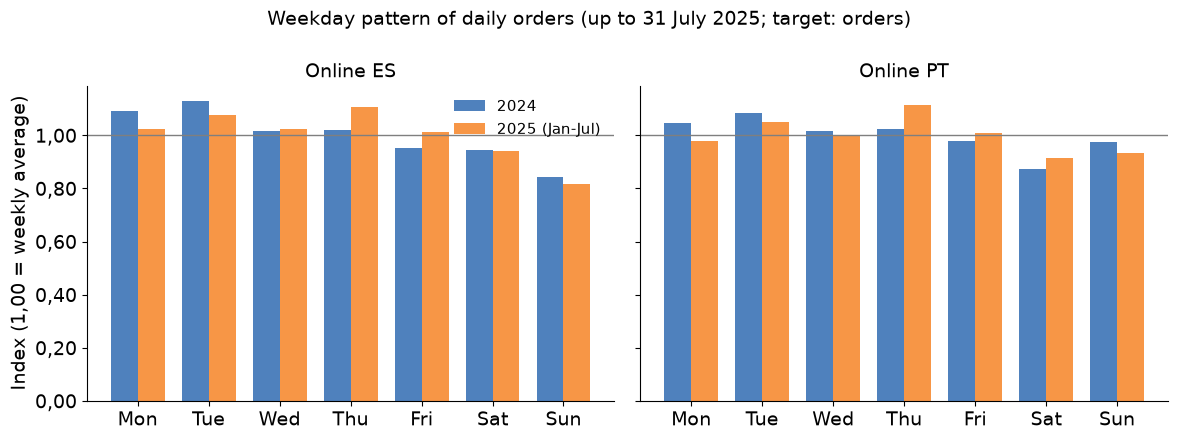

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Usa daily, TARGET, MARKETS, pct(), fmt(), save_table(), save_fig() (célula 1).
# Se reiniciaste o kernel, volta a correr a célula 1.
for nome in ['daily', 'TARGET', 'MARKETS', 'pct', 'fmt', 'save_table', 'save_fig']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e depois esta.")

# ---------- regra do estudo de variáveis: só dados até 31/7/2025 (fim do Training); o Test fica fechado ----------
TRAIN_END = pd.Timestamp('2025-07-31')

def train_only(df):
    out = df[df['day'] <= TRAIN_END]
    assert out['day'].max() <= TRAIN_END, 'fuga de informação: dados do Test no estudo de variáveis'
    return out

WEEKDAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dec = lambda v: f"{v:.2f}".replace('.', ',')                       # número com vírgula decimal

def weekday_ratios(df, target):
    # rácio de cada dia ao valor médio da semana centrada nele (7 dias, cada dia da semana aparece uma vez).
    # Assim o nível, a tendência e a sazonalidade lenta ficam de fora e sobra o efeito do dia da semana.
    d = df[['mark', 'day', target]].sort_values(['mark', 'day']).copy()
    d['ma7'] = d.groupby('mark')[target].transform(lambda s: s.rolling(7, center=True).mean())
    d['ratio'] = d[target] / d['ma7']
    d = d.dropna(subset=['ratio']).copy()                           # perde 3 dias em cada ponta de cada mercado
    d['weekday'] = d['day'].dt.dayofweek                           # 0 = segunda-feira
    d['year'] = d['day'].dt.year
    return d

def weekday_index(d):
    # índice por mercado, ano e dia da semana: mediana dos rácios (robusta a dias de campanha), com média 1,00 nos 7 dias
    idx = d.groupby(['mark', 'year', 'weekday'])['ratio'].median().rename('index').reset_index()
    idx['index'] = idx['index'] / idx.groupby(['mark', 'year'])['index'].transform('mean')
    idx['days'] = d.groupby(['mark', 'year', 'weekday'])['ratio'].count().values
    return idx

# ---------- controlo 1: com um efeito do dia da semana conhecido, o método recupera-o ----------
f_true = np.array([1.2, 1.1, 1.0, 1.0, 1.1, 0.9, 0.7])             # média 1,00
dias = pd.date_range('2024-01-01', '2024-12-31')
sint = pd.DataFrame({'mark': 'teste', 'day': dias, 'v': 1000 * f_true[dias.dayofweek]})
i_t = weekday_index(weekday_ratios(sint, 'v'))
print('--- Controlo 1: efeito do dia da semana conhecido (série sintética) ---')
print('Erro máximo do índice recuperado:', f"{np.abs(i_t['index'].to_numpy() - f_true).max():.2e}",
      '| bate:', bool(np.abs(i_t['index'].to_numpy() - f_true).max() < 1e-9))

# ---------- dados do estudo: só até 31/7/2025 ----------
d = weekday_ratios(train_only(daily), TARGET)
print('\n--- Controlo 2: dados usados ---')
print('Último dia usado:', d['day'].max().date(), '(esperado 2025-07-31 menos 3 dias de média móvel = 2025-07-28)')
cont = d.groupby('mark')['day'].count()
print('Dias usados por mercado:', cont.to_dict(), '(esperado 572 = 578 dias até 31/7/2025 menos 6 da média móvel)')

# ---------- índice do dia da semana por mercado e ano ----------
idx = weekday_index(d)
idx['Weekday'] = idx['weekday'].map(dict(enumerate(WEEKDAYS)))
idx['Period'] = idx['year'].map({2024: '2024', 2025: '2025 (Jan-Jul)'})
dl2 = idx[['mark', 'Period', 'Weekday', 'index', 'days']].rename(columns={'mark': 'Market', 'index': 'Index (1,00 = weekly average)', 'days': 'Days'})
dl2['Index (1,00 = weekly average)'] = dl2['Index (1,00 = weekly average)'].map(dec)
print('\n--- Índice do dia da semana (1,00 = média da semana) ---')
show = idx.pivot_table(index='weekday', columns=['mark', 'Period'], values='index').map(dec)
show.index = WEEKDAYS
display(show)
save_table(dl2, 'DL2', f'Weekday index of daily orders by market and period, up to 31 July 2025 (target: {TARGET})', 'whole table')

# ---------- estabilidade entre 2024 e 2025 e quanto o dia da semana explica ----------
rows = []
for mk in MARKETS:
    a = idx[(idx['mark'] == mk) & (idx['year'] == 2024)].sort_values('weekday')['index'].to_numpy()
    b = idx[(idx['mark'] == mk) & (idx['year'] == 2025)].sort_values('weekday')['index'].to_numpy()
    x = np.log(d.loc[d['mark'] == mk, 'ratio'])
    g = x.groupby(d.loc[d['mark'] == mk, 'weekday']).transform('mean')
    r2 = 1 - ((x - g) ** 2).sum() / ((x - x.mean()) ** 2).sum()
    rows.append({'Market': mk, 'Correlation 2024 vs 2025': dec(np.corrcoef(a, b)[0, 1]),
                 'Largest difference (index points)': dec(np.abs(a - b).max()),
                 'Share of daily variation explained by weekday': pct(r2),
                 'Weekday range, 2024 (max - min)': dec(a.max() - a.min()), 'Weekday range, 2025 (max - min)': dec(b.max() - b.min())})
dl3 = pd.DataFrame(rows)
print('\n--- Estabilidade do padrão e peso do dia da semana ---')
display(dl3)
save_table(dl3, 'DL3', f'Weekday pattern: stability between 2024 and 2025 and share of daily variation explained (target: {TARGET})', 'whole table')

# ---------- gráfico ----------
fig, axes = plt.subplots(1, len(MARKETS), sharey=True, figsize=(12, 4.5))
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    for k, (yr, cor, lab) in enumerate([(2024, '#4F81BD', '2024'), (2025, '#F79646', '2025 (Jan-Jul)')]):
        v = idx[(idx['mark'] == mk) & (idx['year'] == yr)].sort_values('weekday')['index'].to_numpy()
        ax.bar(np.arange(7) + (k - 0.5) * 0.38, v, width=0.38, color=cor, label=lab)
    ax.axhline(1, color='#7F7F7F', linewidth=1)
    ax.set_xticks(range(7)); ax.set_xticklabels([w[:3] for w in WEEKDAYS])
    ax.set_title(mk, fontsize=14); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: dec(v)))
np.atleast_1d(axes)[0].set_ylabel('Index (1,00 = weekly average)')
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=11)
fig.suptitle(f'Weekday pattern of daily orders (up to 31 July 2025; target: {TARGET})', fontsize=14)
fig.tight_layout()
save_fig(fig, 'DL4', f'Weekday pattern of daily orders by market, 2024 and 2025 (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: média móvel e agrupamentos O(d·m) com d = 578 dias e m = 2 mercados (≈1.150 linhas); cálculo do índice O(d·m); espaço O(d·m).

### 5a. Conclusões

**Confirmado (tabela inteira):**
- Os controlos coincidem.
- O dia da semana tem um efeito pequeno: explica menos de 10% da variação diária das encomendas, em Espanha e em Portugal.
- O padrão geral é parecido nos dois anos: a terça-feira é forte e o fim de semana é o mais fraco (o domingo em Espanha e o sábado em Portugal). O melhor dia fica cerca de 20% a 30% acima do pior.
- Há também mudanças de 2024 para 2025: a quinta-feira sobe nos dois mercados e a segunda-feira desce. O padrão é razoavelmente estável em Espanha e menos estável em Portugal.
- Para o total do mês, o efeito é pequeno: um mês só difere de outro por ter mais uma ocorrência de um dia da semana, o que muda o total em cerca de 1% no máximo.

**Filtro das variáveis:**
- Conhece-se no corte? Sim.
- É estável entre 2024 e 2025? Razoavelmente em Espanha, menos em Portugal.
- Ajuda a reduzir o erro no Training? Ainda não se sabe, vê-se mais tarde, repetindo o modelo com e sem a variável.

## 6. Dia da semana: os mesmos meses nos dois anos

**O que vamos fazer:** repetir o índice do dia da semana só com janeiro a julho de 2024 e janeiro a julho de 2025, e medir a margem de erro de cada índice.

**Objetivo:** ver se as diferenças entre anos encontradas no ponto 5 são reais ou vêm só de comparar meses diferentes e de ruído.

**Definições:**
- **Margem de erro de cada índice (erro-padrão):** voltam-se a sortear os rácios de cada dia da semana (1.000 vezes, semente 42), recalcula-se o índice e mede-se quanto ele varia. Cada índice assenta em cerca de 30 dias.
- **Regra prática:** uma diferença maior do que 2 erros-padrão é provavelmente real. Com 14 comparações (7 dias da semana x 2 mercados), é normal uma ou outra passar essa fasquia por acaso.
- **Limite do método:** o sorteio trata cada dia como independente, mas dias seguidos são parecidos. As margens de erro podem estar um pouco subestimadas, por isso as diferenças podem parecer mais certas do que são.

**Valores de controlo:** com um efeito conhecido e sem ruído, o índice é recuperado e o erro-padrão é 0; dias usados por mercado: 210 em 2024 (213 dias menos 3 do início da média móvel) e 209 em 2025 (212 dias menos 3 do fim).

--- Controlo 1: efeito conhecido, sem ruído ---
Erro-padrão máximo: 1.35e-15 (esperado 0) | índice recuperado: True

--- Controlo 2: dias usados por mercado e ano ---


year,2024,2025
mark,,
Online ES,210,209
Online PT,210,209


(esperado 210 em 2024 = 213 dias de janeiro a julho menos 3 do início da média móvel; 209 em 2025 = 212 menos 3 do fim)

--- Índice do dia da semana: janeiro a julho de 2024 contra janeiro a julho de 2025 ---


,Market,Weekday,Index Jan-Jul 2024,Index Jan-Jul 2025,Difference,Standard error of the difference,Larger than 2 standard errors
0,Online ES,Monday,"1,07","1,02","-0,05","0,03",No
1,Online ES,Tuesday,"1,12","1,08","-0,04","0,03",No
2,Online ES,Wednesday,"1,01","1,02","0,01","0,02",No
3,Online ES,Thursday,"1,02","1,11","0,08","0,04",Yes
4,Online ES,Friday,"0,94","1,01","0,07","0,03",Yes
5,Online ES,Saturday,"0,98","0,94","-0,04","0,02",No
6,Online ES,Sunday,"0,85","0,82","-0,04","0,03",No
7,Online PT,Monday,"1,04","0,98","-0,06","0,02",Yes
8,Online PT,Tuesday,"1,10","1,05","-0,05","0,02",No
9,Online PT,Wednesday,"0,99","1,00","0,01","0,03",No


Guardado: evidence_dl/DL5.csv

--- Resumo por mercado (mesmos meses) ---


,Market,Correlation 2024 vs 2025,Largest difference (index points),Weekdays with difference > 2 standard errors,Typical standard error of one index
0,Online ES,"0,81","0,08",2 of 7,"0,02"
1,Online PT,"0,72","0,06",4 of 7,"0,02"


Guardado: evidence_dl/DL6.csv
Guardado: evidence_dl/DL7.png


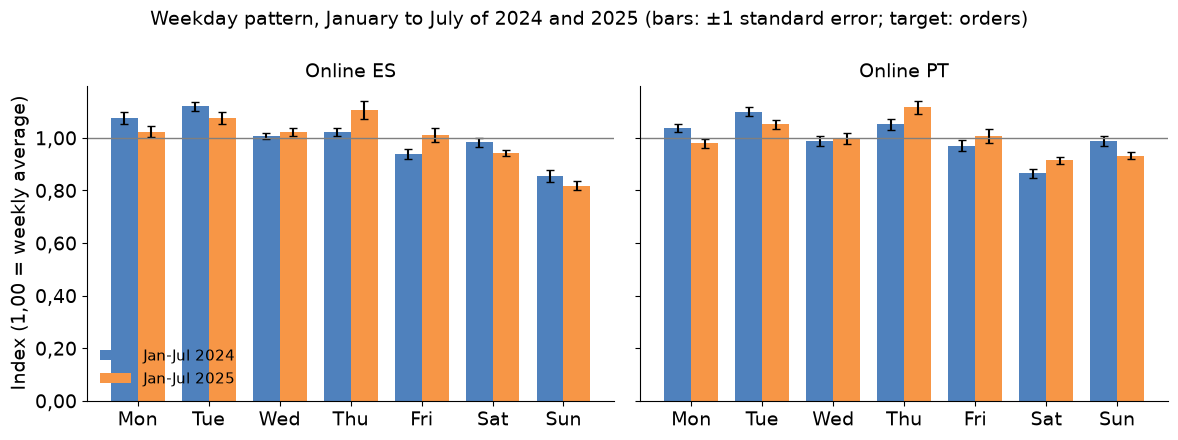

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Usa daily, TARGET, MARKETS, pct(), save_table(), save_fig() (célula 1) e train_only(), weekday_ratios(), weekday_index(), dec(), WEEKDAYS (célula 5).
# Se reiniciaste o kernel, volta a correr as células 1 e 5.
for nome in ['daily', 'TARGET', 'MARKETS', 'save_table', 'save_fig', 'train_only', 'weekday_ratios', 'weekday_index', 'dec', 'WEEKDAYS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 e 5 e depois esta.")

def boot_se(d, B=1000, seed=42):
    # erro-padrão do índice por reamostragem: em cada mercado, ano e dia da semana, volta-se a sortear os rácios (com reposição),
    # recalcula-se o índice (mediana normalizada para média 1,00) e mede-se quanto ele varia. Os rácios do mesmo dia da semana
    # estão afastados 7 dias, por isso as médias móveis não se sobrepõem e tratá-los como independentes é razoável.
    rng = np.random.default_rng(seed)
    out = []
    for (mk, yr), g in d.groupby(['mark', 'year']):
        arrs = [g.loc[g['weekday'] == w, 'ratio'].to_numpy() for w in range(7)]
        meds = np.empty((B, 7))
        for b in range(B):
            meds[b] = [np.median(rng.choice(a, size=len(a), replace=True)) for a in arrs]
        meds = meds / meds.mean(axis=1, keepdims=True)
        out.append(pd.DataFrame({'mark': mk, 'year': yr, 'weekday': range(7), 'se': meds.std(axis=0, ddof=1)}))
    return pd.concat(out, ignore_index=True)

# ---------- controlo 1: com um efeito conhecido e sem ruído, o índice é recuperado e o erro-padrão é 0 ----------
f_true = np.array([1.2, 1.1, 1.0, 1.0, 1.1, 0.9, 0.7])
dias = pd.date_range('2024-01-01', '2024-12-31')
d_t = weekday_ratios(pd.DataFrame({'mark': 'teste', 'day': dias, 'v': 1000 * f_true[dias.dayofweek]}), 'v')
print('--- Controlo 1: efeito conhecido, sem ruído ---')
print('Erro-padrão máximo:', f"{boot_se(d_t, B=50)['se'].max():.2e}", '(esperado 0)',
      '| índice recuperado:', bool(np.abs(weekday_index(d_t)['index'].to_numpy() - f_true).max() < 1e-9))

# ---------- dados: só janeiro a julho de 2024 e de 2025 (mesmos meses), até 31/7/2025 ----------
d_all = weekday_ratios(train_only(daily), TARGET)
d_jj = d_all[d_all['day'].dt.month <= 7].copy()
cont = d_jj.groupby(['mark', 'year'])['day'].count().unstack('year')
print('\n--- Controlo 2: dias usados por mercado e ano ---')
display(cont)
print('(esperado 210 em 2024 = 213 dias de janeiro a julho menos 3 do início da média móvel; 209 em 2025 = 212 menos 3 do fim)')

# ---------- índice, erro-padrão e diferença entre os dois anos ----------
idx = weekday_index(d_jj).merge(boot_se(d_jj), on=['mark', 'year', 'weekday'])
rows = []
for mk in MARKETS:
    for w in range(7):
        a = idx[(idx['mark'] == mk) & (idx['year'] == 2024) & (idx['weekday'] == w)].iloc[0]
        b = idx[(idx['mark'] == mk) & (idx['year'] == 2025) & (idx['weekday'] == w)].iloc[0]
        diff, se_d = b['index'] - a['index'], float(np.hypot(a['se'], b['se']))
        rows.append({'Market': mk, 'Weekday': WEEKDAYS[w], 'Index Jan-Jul 2024': dec(a['index']), 'Index Jan-Jul 2025': dec(b['index']),
                     'Difference': dec(diff), 'Standard error of the difference': dec(se_d),
                     'Larger than 2 standard errors': 'Yes' if abs(diff) > 2 * se_d else 'No'})
dl5 = pd.DataFrame(rows)
print('\n--- Índice do dia da semana: janeiro a julho de 2024 contra janeiro a julho de 2025 ---')
display(dl5)
save_table(dl5, 'DL5', f'Weekday index, January to July of 2024 and 2025, with standard error of the difference (target: {TARGET})', 'whole table')

# ---------- resumo por mercado ----------
rows = []
for mk in MARKETS:
    a = idx[(idx['mark'] == mk) & (idx['year'] == 2024)].sort_values('weekday')
    b = idx[(idx['mark'] == mk) & (idx['year'] == 2025)].sort_values('weekday')
    n_sig = int((dl5[dl5['Market'] == mk]['Larger than 2 standard errors'] == 'Yes').sum())
    rows.append({'Market': mk, 'Correlation 2024 vs 2025': dec(np.corrcoef(a['index'], b['index'])[0, 1]),
                 'Largest difference (index points)': dec(np.abs(a['index'].to_numpy() - b['index'].to_numpy()).max()),
                 'Weekdays with difference > 2 standard errors': f'{n_sig} of 7',
                 'Typical standard error of one index': dec(float(np.mean(np.concatenate([a['se'], b['se']]))))})
dl6 = pd.DataFrame(rows)
print('\n--- Resumo por mercado (mesmos meses) ---')
display(dl6)
save_table(dl6, 'DL6', f'Weekday pattern, same months in both years: stability summary (target: {TARGET})', 'whole table')

# ---------- gráfico (barras de erro = 1 erro-padrão) ----------
fig, axes = plt.subplots(1, len(MARKETS), sharey=True, figsize=(12, 4.5))
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    for k, (yr, cor, lab) in enumerate([(2024, '#4F81BD', 'Jan-Jul 2024'), (2025, '#F79646', 'Jan-Jul 2025')]):
        g = idx[(idx['mark'] == mk) & (idx['year'] == yr)].sort_values('weekday')
        ax.bar(np.arange(7) + (k - 0.5) * 0.38, g['index'], width=0.38, color=cor, label=lab, yerr=g['se'], capsize=3)
    ax.axhline(1, color='#7F7F7F', linewidth=1)
    ax.set_xticks(range(7)); ax.set_xticklabels([w[:3] for w in WEEKDAYS])
    ax.set_title(mk, fontsize=14); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: dec(v)))
np.atleast_1d(axes)[0].set_ylabel('Index (1,00 = weekly average)')
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=11, loc='lower left')
fig.suptitle(f'Weekday pattern, January to July of 2024 and 2025 (bars: ±1 standard error; target: {TARGET})', fontsize=14)
fig.tight_layout()
save_fig(fig, 'DL7', f'Weekday pattern in the same months of 2024 and 2025, with standard errors (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: o índice é O(d·m) (d ≈ 420 dias, m = 2 mercados); a reamostragem faz B = 1.000 sorteios × 7 dias da semana × 2 mercados × 2 anos
# = 28.000 sorteios de ~30 valores, O(B·n); espaço O(B·7).

### 6a. Conclusões

**Confirmado (tabela inteira):**
- Os controlos coincidem.
- Comparando os mesmos meses (janeiro a julho), o padrão do dia da semana mudou de 2024 para 2025. Em Espanha, 2 dos 7 dias mudaram mais do que a margem de erro. Em Portugal, foram 4 dos 7.
- Só por acaso, esperava-se menos de 1 dia assim em 14 comparações, e há 6. A mudança é real, e não vem de comparar meses diferentes.
- A quinta-feira sobe nos dois mercados e a segunda-feira desce.
- As mudanças são pequenas: valem entre 4% e 8% de um dia médio.
- Ressalva: o método trata os dias como independentes, mas dias seguidos são parecidos. As margens de erro podem estar um pouco subestimadas, por isso as diferenças podem parecer mais certas do que são.

**Filtro das variáveis:**
- Conhece-se no corte? Sim.
- É estável entre 2024 e 2025? O padrão geral mantém-se (terça forte, fim de semana mais fraco), mas há deslocações reais em alguns dias.
- Ajuda a reduzir o erro no Training? Ainda não se sabe, e o efeito no total do mês é pequeno, cerca de 1% no máximo.

## 7. Campanhas de calendário

**O que vamos fazer:** ler a tabela `slv_events` da camada silver, marcar os dias das seis campanhas que seguem o calendário (Black Friday, Natal, Dia da Mãe, Reyes, Valentines e Páscoa/Semana Santa) em Online ES e Online PT, e medir quanto cada uma mexe nas encomendas diárias (dados até 31/7/2025). Contamos também quantas vezes cada campanha dos meses de Test já tinha aparecido antes do corte.

**Objetivo:** decidir se as campanhas de calendário entram como variável e perceber o limite: com dados só desde 2024, o modelo vê cada campanha poucas vezes.

**Definições:**
- **Fator da campanha:** encomendas dos dias de campanha a dividir pela média dos dias normais dos 28 dias anteriores (mínimo de 7 dias normais). Dias normais são os que não pertencem a nenhuma das seis campanhas. Um fator de 1,00 quer dizer sem efeito, e 2,00 quer dizer o dobro das encomendas de um dia normal.
- **Ocorrências:** o quadro usa só o calendário (as datas) dos meses de Test, nunca as encomendas do Test.

**Filtro das variáveis:**
1. Conhece-se no corte? A Parfois disse que as campanhas que seguem o calendário são conhecidas no início do ano. As datas exatas vêm da tabela `slv_events`, e convém confirmá-las.
2. É estável entre 2024 e 2025?
3. Ajuda a reduzir o erro no Training? (medido mais tarde).

**Valores de controlo:**
- Na `slv_events` não há eventos com o fim antes do início (a silver já os corrige) nem linhas imputadas em Online ES e Online PT.
- A Black Friday tem 6 dias por ano e mercado (26/11 a 01/12 de 2024 e 25/11 a 30/11 de 2025).
- Uma série sintética com fator conhecido (2,5) devolve 2,5.
- Os fatores de 2024 da Black Friday e do Natal comparam-se com os do notebook baseline (que usa os dados antes da silver); pequenas diferenças são esperadas e têm de ser explicadas.

Linhas de slv_events: 845 | com fim antes do início: 0 (esperado 0, a silver já corrige) | linhas imputadas em ES/PT: 0 (esperado 0)
Eventos de todos os mercados (mark = All), por família: [('Black Friday', 4), ('Clearance', 1), ('Free shipping', 6), ('Other', 16), ('Special prices', 3), ('Stock 1', 1)] (só a Black Friday entra como campanha de todos os mercados)

--- Controlo 1: dias da Black Friday por mercado e ano ---


,mark,year,dias,primeiro,ultimo,bate
0,Online ES,2024,6,2024-11-26,2024-12-01,True
1,Online ES,2025,6,2025-11-25,2025-11-30,True
2,Online PT,2024,6,2024-11-26,2024-12-01,True
3,Online PT,2025,6,2025-11-25,2025-11-30,True



--- Controlo 2: série sintética com fator conhecido ---
Fator recuperado: 2.500000 (esperado 2,5) | dias medidos: 3 (esperado 3) | bate: True

--- Fator de cada campanha (encomendas dos dias de campanha / dias normais), dados até 31/7/2025 ---


,Campaign,Market,Year,Campaign days (up to 31 Jul 2025),Days measured,Orders on campaign days vs normal days
0,Black Friday,Online ES,2024,6,6,"6,72"
1,Black Friday,Online PT,2024,6,6,"8,21"
2,Christmas,Online ES,2024,4,4,"1,55"
3,Christmas,Online PT,2024,4,4,"1,07"
4,Mothers Day,Online ES,2024,3,3,"1,33"
5,Mothers Day,Online ES,2025,5,5,"0,92"
6,Mothers Day,Online PT,2024,3,3,"1,30"
7,Mothers Day,Online PT,2025,6,5,"0,81"
8,Reyes,Online ES,2024,4,4,"1,17"
9,Reyes,Online ES,2025,2,2,"0,60"


Guardado: evidence_dl/DL8.csv

--- Controlo 3: fatores de 2024 contra os do notebook baseline ---


,campanha,mercado,medido,esperado (baseline),bate
0,Black Friday,Online ES,"6,72","6,72",True
1,Black Friday,Online PT,"8,21","8,21",True
2,Christmas,Online ES,"1,55","1,55",True
3,Christmas,Online PT,"1,07","1,07",True



--- Quantas vezes cada campanha do Test já tinha aparecido no histórico (antes do corte) ---


,Month to forecast,Campaign,Market,Campaign days in the month,Times seen before the cut-off
0,Nov 2025,Black Friday,Online ES,6,1
1,Nov 2025,Black Friday,Online PT,6,1
2,Dec 2025,Christmas,Online ES,4,1
3,Dec 2025,Christmas,Online PT,4,1
4,Dec 2025,Reyes,Online ES,4,2


Guardado: evidence_dl/DL9.csv
Guardado: evidence_dl/DL10.png


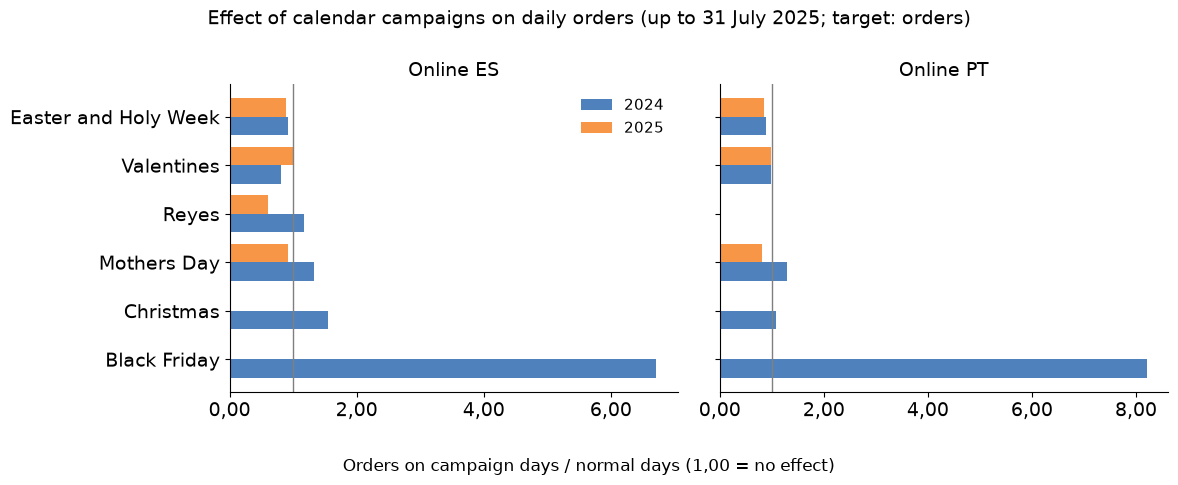

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from lakehouse import LakeConfig, connect

# Usa daily, TARGET, MARKETS, START, END, TARGETS, fmt(), pct(), cutoff_date(), save_table(), save_fig() (célula 1) e TRAIN_END, train_only(), dec() (célula 5).
# Se reiniciaste o kernel, volta a correr as células 1 e 5.
for nome in ['daily', 'TARGET', 'MARKETS', 'START', 'END', 'TARGETS', 'fmt', 'pct', 'cutoff_date', 'save_table', 'save_fig',
             'TRAIN_END', 'train_only', 'dec']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 e 5 e depois esta.")

# ---------- ligação ao data lake (só leitura da tabela slv_events da camada silver) ----------
lake = LakeConfig.from_env()   # nomes dos buckets e credenciais vêm do cofre
con = connect()                # DuckDB em memória, já ligado ao lake
SILVER_EV = f"'{lake.uri('silver', 'slv_events')}.parquet'"
mk_in = ', '.join(f"'{m}'" for m in MARKETS)
mk_values = ', '.join(f"('{m}')" for m in MARKETS)

# ---------- campanhas que seguem o calendário (mesmas seis do notebook baseline) ----------
FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Easter and Holy Week']     # ordem = prioridade se dois eventos caírem no mesmo dia
fam_in = ', '.join(f"'{f}'" for f in FAMS)
WIN, MIN_REF = 28, 7     # referência de cada dia de campanha: média dos dias normais dos 28 dias anteriores (mínimo 7 dias)

con.execute(f"""
CREATE OR REPLACE TEMP TABLE ev_dl AS
SELECT mark, clean_name, start_d, end_d, (end_d >= start_d) AS valid, is_imputed,
  CASE
    WHEN clean_name ILIKE 'Black Friday%'            THEN 'Black Friday'
    WHEN clean_name ILIKE 'Clearance%'               THEN 'Clearance'
    WHEN clean_name ILIKE 'Special Prices%'          THEN 'Special prices'
    WHEN clean_name ILIKE 'Free Shipping%'           THEN 'Free shipping'
    WHEN clean_name ILIKE '%Valentines%'             THEN 'Valentines'
    WHEN clean_name ILIKE '%Mothers Day%'            THEN 'Mothers Day'
    WHEN clean_name ILIKE '%Christmas%'              THEN 'Christmas'
    WHEN clean_name ILIKE '%Reyes%'                  THEN 'Reyes'
    WHEN clean_name IN ('Easter Weeks', 'Holy Week') THEN 'Easter and Holy Week'
    WHEN clean_name = 'Get your basket ready'        THEN 'Get your basket ready'
    WHEN clean_name = 'Stock 1'                      THEN 'Stock 1'
    WHEN clean_name ILIKE 'Apag%'                    THEN 'Iberian blackout'
    ELSE 'Other'
  END AS family
FROM (SELECT mark_cod AS mark, event AS clean_name, start_date AS start_d, end_date AS end_d, is_imputed
      FROM read_parquet({SILVER_EV}))     -- a silver já normaliza o nome, corrige as datas e usa 'All' para os eventos de todos os mercados
""")
n_ev, n_inv, n_imp = con.execute(f"""SELECT count(*), count(*) FILTER (WHERE NOT valid),
                                       count(*) FILTER (WHERE is_imputed AND mark IN ({mk_in})) FROM ev_dl""").fetchall()[0]
print('Linhas de slv_events:', fmt(n_ev), '| com fim antes do início:', n_inv, '(esperado 0, a silver já corrige) | linhas imputadas em ES/PT:', n_imp, '(esperado 0)')
print('Eventos de todos os mercados (mark = All), por família:', con.execute("SELECT family, count(*) FROM ev_dl WHERE mark = 'All' GROUP BY 1 ORDER BY 1").fetchall(),
      '(só a Black Friday entra como campanha de todos os mercados)')

# dias de campanha por mercado: eventos com mercado + linhas da Black Friday de todos os mercados (mark = 'All', valem para os dois mercados)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE camp_days_dl AS
WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
rows_m AS (
  SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
    SELECT mark, family,
           unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                  CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
    FROM ev_dl WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
rows_g AS (
  SELECT mk.mark, g.family, g.day FROM (
    SELECT family, CAST(day_ts AS DATE) AS day FROM (
      SELECT family,
             unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                    CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
      FROM ev_dl WHERE valid AND mark = 'All' AND family = 'Black Friday')) g
  CROSS JOIN mk)
SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
""")
camp = con.sql("SELECT mark, family, day FROM camp_days_dl").df()
camp['day'] = pd.to_datetime(camp['day'])
camp['p'] = camp['family'].map({f: i for i, f in enumerate(FAMS)})
camp = camp.sort_values(['mark', 'day', 'p']).drop_duplicates(['mark', 'day']).drop(columns='p').reset_index(drop=True)
camp['year'] = camp['day'].dt.year

# ---------- controlo 1: a Black Friday tem 6 dias por ano e mercado (26/11 a 01/12 de 2024 e 25/11 a 30/11 de 2025) ----------
bf = camp[camp['family'] == 'Black Friday'].groupby(['mark', 'year']).agg(dias=('day', 'count'), primeiro=('day', 'min'), ultimo=('day', 'max')).reset_index()
bf['bate'] = (bf['dias'] == 6) & (((bf['year'] == 2024) & (bf['primeiro'] == pd.Timestamp('2024-11-26')) & (bf['ultimo'] == pd.Timestamp('2024-12-01')))
                                  | ((bf['year'] == 2025) & (bf['primeiro'] == pd.Timestamp('2025-11-25')) & (bf['ultimo'] == pd.Timestamp('2025-11-30'))))
print('\n--- Controlo 1: dias da Black Friday por mercado e ano ---')
display(bf)

# ---------- fator de cada campanha: encomendas dos dias de campanha / média dos dias normais dos 28 dias anteriores ----------
def campaign_factors(daily_df, camp_df, target):
    # por campanha, mercado e ano: soma das encomendas dos dias de campanha a dividir pela soma das referências (mesma regra da B4)
    acc = {}
    for mk, g in daily_df.groupby('mark'):
        s = g.set_index('day')[target].sort_index()
        sub = camp_df[camp_df['mark'] == mk]
        fam_of = dict(zip(sub['day'], sub['family']))
        flag = np.array([d in fam_of for d in s.index])
        normal = s[~flag]                                        # dias sem nenhuma das seis campanhas
        for d in s.index[flag]:
            w = normal.loc[d - pd.Timedelta(days=WIN): d - pd.Timedelta(days=1)]
            if len(w) >= MIN_REF:
                a = acc.setdefault((fam_of[d], mk, d.year), [0.0, 0.0, 0])
                a[0] += s[d]; a[1] += w.mean(); a[2] += 1
    return pd.DataFrame([{'family': k[0], 'mark': k[1], 'year': k[2], 'days_measured': v[2], 'factor': v[0] / v[1]} for k, v in acc.items()])

# controlo 2: série sintética com fator conhecido (campanha de 3 dias com 2,5 vezes o nível normal) -> fator 2,5
dias_t = pd.date_range('2024-01-01', periods=80)
y_t = np.full(80, 100.0); y_t[40:43] = 250.0
camp_t = pd.DataFrame({'mark': 'teste', 'family': 'X', 'day': dias_t[40:43]})
f_t = campaign_factors(pd.DataFrame({'mark': 'teste', 'day': dias_t, 'v': y_t}), camp_t, 'v')
print('\n--- Controlo 2: série sintética com fator conhecido ---')
print('Fator recuperado:', f"{f_t['factor'].iloc[0]:.6f}", '(esperado 2,5) | dias medidos:', int(f_t['days_measured'].iloc[0]), '(esperado 3)',
      '| bate:', bool(abs(f_t['factor'].iloc[0] - 2.5) < 1e-9 and f_t['days_measured'].iloc[0] == 3))

# ---------- dados do estudo: encomendas só até 31/7/2025; campanhas só até essa data ----------
d_study = train_only(daily)
camp_study = camp[camp['day'] <= TRAIN_END]
fac = campaign_factors(d_study, camp_study, TARGET)
days_n = camp_study.groupby(['family', 'mark', 'year']).size().rename('campaign_days').reset_index()
tab = days_n.merge(fac, on=['family', 'mark', 'year'], how='left')
tab['family'] = pd.Categorical(tab['family'], FAMS, ordered=True)
tab = tab.sort_values(['family', 'mark', 'year']).reset_index(drop=True)
dl8 = pd.DataFrame({'Campaign': tab['family'].astype(str), 'Market': tab['mark'], 'Year': tab['year'],
                    'Campaign days (up to 31 Jul 2025)': tab['campaign_days'],
                    'Days measured': tab['days_measured'].fillna(0).astype(int),
                    'Orders on campaign days vs normal days': tab['factor'].map(lambda v: '-' if pd.isna(v) else dec(v))})
print('\n--- Fator de cada campanha (encomendas dos dias de campanha / dias normais), dados até 31/7/2025 ---')
display(dl8)
save_table(dl8, 'DL8', f'Effect of each calendar campaign on daily orders, by market and year, up to 31 July 2025 (target: {TARGET})', 'whole table')

# ---------- controlo 3: Black Friday e Natal de 2024 coincidem com os fatores do notebook baseline (BL12) ----------
ref = {('Black Friday', 'Online ES'): 6.72, ('Black Friday', 'Online PT'): 8.21, ('Christmas', 'Online ES'): 1.55, ('Christmas', 'Online PT'): 1.07}
rows = []
for (fam, mk), esp in ref.items():
    r = fac[(fac['family'] == fam) & (fac['mark'] == mk) & (fac['year'] == 2024)]
    got = float(r['factor'].iloc[0]) if len(r) else np.nan
    rows.append({'campanha': fam, 'mercado': mk, 'medido': dec(got), 'esperado (baseline)': dec(esp), 'bate': (not np.isnan(got)) and round(got, 2) == esp})
print('\n--- Controlo 3: fatores de 2024 contra os do notebook baseline ---')
display(pd.DataFrame(rows))

# ---------- quantas vezes o modelo viu cada campanha antes do corte de cada mês de Test ----------
rows = []
for m in [t for t in TARGETS if t >= pd.Period('2025-08', 'M')]:                 # só o calendário (datas) dos meses de Test, nunca as encomendas
    cut = cutoff_date(m)
    in_m = camp[(camp['day'] >= m.start_time) & (camp['day'] <= m.end_time.normalize())]
    for (fam, mk), g in in_m.groupby(['family', 'mark']):
        seen = camp[(camp['family'] == fam) & (camp['mark'] == mk) & (camp['day'] <= cut)]['year'].nunique()
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Campaign': fam, 'Market': mk, 'Campaign days in the month': len(g),
                     'Times seen before the cut-off': seen})
dl9 = pd.DataFrame(rows)
print('\n--- Quantas vezes cada campanha do Test já tinha aparecido no histórico (antes do corte) ---')
display(dl9)
save_table(dl9, 'DL9', 'Calendar campaigns in the Test months and how many times each had been seen before the cut-off', 'whole table')

# ---------- gráfico: fator de cada campanha, por mercado e ano ----------
fig, axes = plt.subplots(1, len(MARKETS), sharey=True, figsize=(12, 4.8))
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    for k, (yr, cor) in enumerate([(2024, '#4F81BD'), (2025, '#F79646')]):
        v = [fac[(fac['family'] == f) & (fac['mark'] == mk) & (fac['year'] == yr)]['factor'].tolist() for f in FAMS]
        vals = [x[0] if x else np.nan for x in v]
        ax.barh(np.arange(len(FAMS)) + (k - 0.5) * 0.38, vals, height=0.38, color=cor, label=str(yr))
    ax.axvline(1, color='#7F7F7F', linewidth=1)
    ax.set_yticks(range(len(FAMS))); ax.set_yticklabels(FAMS); ax.invert_yaxis()
    ax.set_title(mk, fontsize=14); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: dec(v)))
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=11, loc='upper right')     # canto livre (as barras longas ficam em baixo)
fig.suptitle(f'Effect of calendar campaigns on daily orders (up to 31 July 2025; target: {TARGET})', fontsize=14)
fig.supxlabel('Orders on campaign days / normal days (1,00 = no effect)', fontsize=12)   # um só rótulo para os dois painéis
fig.tight_layout()
save_fig(fig, 'DL10', f'Effect of calendar campaigns on daily orders by market and year (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: o fator percorre os dias de campanha do histórico (≤ ~150 por mercado) com uma janela de 28 dias, O(c·28) com c = dias de campanha;
# a leitura de slv_events é O(e), com e = nº de linhas da tabela; o quadro dos meses de Test é O(5 · c). Espaço O(d), com d = 731 dias.

### 7a. Conclusões sobre as campanhas de calendário

**Confirmado (tabela inteira):**
- Os controlos coincidem. A silver não alterou os fatores de 2024 da Black Friday nem do Natal em relação ao notebook baseline.

**Derivado do que vimos:**
- **Black Friday:** é de longe o maior efeito (cerca de 7 a 8 vezes um dia normal), mas o modelo só a tinha visto uma vez antes do corte de novembro de 2025. Sabemos que o efeito é enorme; o tamanho exato aprende-se de uma única observação por mercado.
- **Natal:** o efeito é muito diferente entre mercados (claramente acima do normal em ES, quase igual ao normal em PT) e também só foi visto uma vez.
- **Dia da Mãe e Reyes:** não são estáveis. Em 2024 estavam acima do normal, e em 2025 ficam abaixo. No caso dos Reyes, o valor de 2025 assenta em apenas 2 dias. Pelo filtro, não são candidatas a variável.
- **Valentines:** estável em PT (perto de um dia normal) e a mexer um pouco em ES. O efeito é pequeno.
- **Páscoa e Semana Santa:** cerca de 10% abaixo de um dia normal, parecido nos dois anos e nos dois mercados. É pequeno, mas dura 17 dias, por isso pesa no total do mês.
- **Ponto importante:** o Training (janeiro a julho de 2025) nunca contém Black Friday nem Natal. A utilidade destas duas campanhas não se consegue provar no Training, só o Test (novembro e dezembro) as põe à prova, e só uma vez.

**Filtro das variáveis:**
- Conhece-se no corte? Sim, se a empresa confirmar que as datas são fixadas no início do ano.
- É estável entre 2024 e 2025? Só a Páscoa e os Valentines em PT. A Black Friday e o Natal só foram vistos uma vez.
- Ajuda a reduzir o erro no Training? Só se vê mais tarde, e a Black Friday e o Natal não estão no Training.

## 8. Feriados nacionais

**O que vamos fazer:** ler os feriados nacionais de Espanha e Portugal (2024 e 2025) com o pacote `holidays`, medir quanto cada feriado, os dois dias antes e os 2 dias depois mexem nas encomendas diárias de janeiro a julho (dados até 31/7/2025), e contar quantos feriados caem em cada mês a prever de 2025, no total e em dias úteis (segunda a sexta). A `slv_calendar` da silver não serve: tem feriados do Brasil e não tem mercado.

**Objetivo:** decidir se os feriados entram como variável. Ao contrário da Black Friday e do Natal, os feriados de janeiro a julho caem no Training, por isso a sua utilidade pode ser provada lá.

**Definições:**
- **Efeito de um dia:** encomendas do dia a dividir pela média do mesmo dia da semana 1 a 4 semanas antes (mínimo 2 dias). Só contam dias normais: sem campanhas e sem outros feriados. Assim, o dia da semana não baralha a medição. 1,00 quer dizer sem efeito.
- **Efeito conjunto:** soma das encomendas a dividir pela soma das referências.
- **Estado de cada feriado:** medido; dentro de uma campanha de calendário fixo (já fica marcado pela variável das campanhas); dentro de outra campanha apenas (Clearance, Free shipping, etc., que não entram como variável); ou sem dias normais de referência suficientes.
- **Âmbito:** só feriados nacionais. Ficam de fora os regionais de Espanha e as mudanças para segunda-feira que algumas regiões fazem (por exemplo, o 12/10/2025).
- **Comparação:** janeiro a julho de 2024 contra janeiro a julho de 2025, os mesmos meses.

**Filtro das variáveis:**
1. Conhece-se no corte? Sim, o calendário de feriados é fixo por lei (e a Páscoa calcula-se).
2. É estável entre 2024 e 2025?
3. Ajuda a reduzir o erro no Training? (medido mais tarde).

**Valores de controlo:**
- Os feriados que conhecemos estão no calendário (por exemplo, 06/01, 18/04, 15/08 e 08/12 de 2025 em Espanha; 25/04, 10/06, 01/12 e 25/12 de 2025 em Portugal).
- O pacote dá 9 feriados nacionais por ano em Espanha e 13 em Portugal. O 12/10/2024 (sábado) conta em Espanha e o 12/10/2025 (domingo) não.
- O último dia medido é anterior ou igual a 31/7/2025.

Pacote holidays, versão: 0.108

--- Controlo 1: feriados que conhecemos estão no calendário ---


,mercado,data,feriado,bate
0,Online ES,2025-01-06,Epiphany,True
1,Online ES,2025-04-18,Good Friday,True
2,Online ES,2025-08-15,Assumption Day,True
3,Online ES,2025-12-08,Immaculate Conception,True
4,Online PT,2025-04-25,Freedom Day,True
5,Online PT,2025-06-10,"Day of Portugal, Camões, and the Portuguese Co...",True
6,Online PT,2025-12-01,Restoration of Independence Day,True
7,Online PT,2025-12-25,Christmas Day,True


12/10/2024 (sábado) é feriado em ES: True | 12/10/2025 (domingo) não é feriado nacional em ES: True
Feriados nacionais por mercado e ano (2024 / 2025): {'Online ES': (9, 9), 'Online PT': (13, 13)}

--- Controlo 2: série sintética com fator conhecido ---
Fator recuperado: 0.700000 (esperado 0,7) | bate: True

--- Cada feriado nacional de janeiro a julho: encomendas do dia / mesmo dia da semana 1 a 4 semanas antes ---


,Market,Year,Holiday,Date,Weekday,Campaigns that day,Status,Orders vs same weekday 1-4 weeks before
0,Online ES,2024,New Year's Day,01/01/2024,Mon,-,too few normal reference days,-
1,Online ES,2024,Epiphany,06/01/2024,Sat,Clearance,in another campaign only,-
2,Online ES,2024,Good Friday,29/03/2024,Fri,Easter and Holy Week,in a fixed-calendar campaign,-
3,Online ES,2024,Labor Day,01/05/2024,Wed,-,measured,"0,90"
4,Online ES,2025,New Year's Day,01/01/2025,Wed,Reyes,in a fixed-calendar campaign,-
5,Online ES,2025,Epiphany,06/01/2025,Mon,Clearance,in another campaign only,-
6,Online ES,2025,Good Friday,18/04/2025,Fri,Easter and Holy Week,in a fixed-calendar campaign,-
7,Online ES,2025,Labor Day,01/05/2025,Thu,-,too few normal reference days,-
8,Online PT,2024,New Year's Day,01/01/2024,Mon,Clearance,in another campaign only,-
9,Online PT,2024,Good Friday,29/03/2024,Fri,Easter and Holy Week,in a fixed-calendar campaign,-



--- Estado dos feriados de janeiro a julho, por mercado ---


Status,in a fixed-calendar campaign,in another campaign only,measured,too few normal reference days
Market,,,,
Online ES,3,2,1,2
Online PT,5,2,6,1


Guardado: evidence_dl/DL11.csv

--- Resumo (janeiro a julho): efeito do feriado, da véspera e do dia depois ---


,Market,Day type,2024: days,2024: effect,2024: below reference,2025: days,2025: effect,2025: below reference
0,Online ES,2 days before,0,-,0 of 0,1,"1,05",0 of 1
1,Online ES,Day before,0,-,0 of 0,1,"1,44",0 of 1
2,Online ES,Holiday,1,"0,90",1 of 1,0,-,0 of 0
3,Online ES,Day after,1,"1,20",0 of 1,0,-,0 of 0
4,Online ES,2 days after,1,"1,08",0 of 1,0,-,0 of 0
5,Online PT,2 days before,1,"0,99",1 of 1,4,"0,64",4 of 4
6,Online PT,Day before,1,"0,90",1 of 1,3,"0,92",2 of 3
7,Online PT,Holiday,4,"0,95",3 of 4,2,"0,92",2 of 2
8,Online PT,Day after,3,"1,04",1 of 3,2,"0,89",2 of 2
9,Online PT,2 days after,4,"1,01",1 of 4,3,"0,93",3 of 3


Guardado: evidence_dl/DL12.csv

--- Controlo 3: último dia medido: 2025-06-21 | bate (<= 31/7/2025): True

--- Feriados nacionais por mês-alvo de 2025 (só calendário) ---


,Month to forecast,Set,Online ES,Online ES: Mon-Fri,Online PT,Online PT: Mon-Fri
0,Jan 2025,Training,2,2,1,1
1,Feb 2025,Training,0,0,0,0
2,Mar 2025,Training,0,0,0,0
3,Apr 2025,Training,1,1,3,2
4,May 2025,Training,1,1,1,1
5,Jun 2025,Training,0,0,2,2
6,Jul 2025,Training,0,0,0,0
7,Aug 2025,Test,1,1,1,1
8,Sep 2025,Test,0,0,0,0
9,Oct 2025,Test,0,0,1,0


Guardado: evidence_dl/DL13.csv
Guardado: evidence_dl/DL14.png


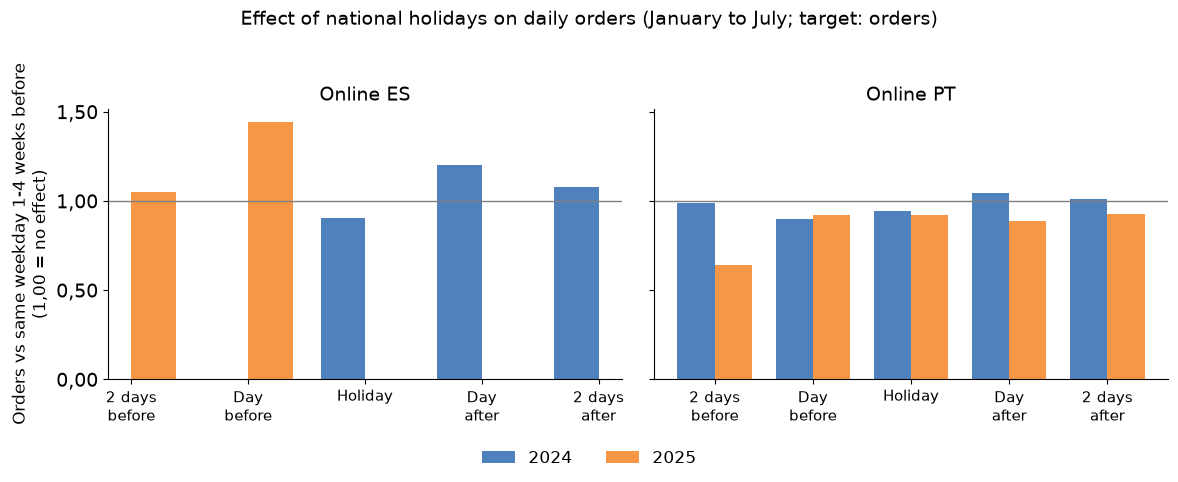

In [10]:
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
try:
    import holidays                       # calendário de feriados nacionais; se faltar, corre %pip install holidays numa célula nova
except ImportError:
    raise ImportError("Falta o pacote holidays. Corre %pip install holidays numa célula nova e volta a correr esta.")

# Usa daily, TARGET, MARKETS, START, END, TARGETS, fmt(), pct(), cutoff_date(), split_of(), save_table(), save_fig() (célula 1), TRAIN_END, train_only(), dec() (célula 5)
# e con, mk_in, mk_values, FAMS e a tabela ev_dl (célula 7). Se reiniciaste o kernel, volta a correr as células 1, 5 e 7.
for nome in ['daily', 'TARGET', 'MARKETS', 'START', 'END', 'TARGETS', 'fmt', 'pct', 'cutoff_date', 'split_of', 'save_table', 'save_fig',
             'TRAIN_END', 'train_only', 'dec', 'con', 'mk_in', 'mk_values', 'FAMS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 5 e 7 e depois esta.")
try:
    con.execute("SELECT count(*) FROM ev_dl").fetchall()          # ev_dl é uma tabela do DuckDB criada na célula 7
except Exception:
    raise RuntimeError("A tabela ev_dl não existe. Volta a correr a célula 7 e depois esta.")
print('Pacote holidays, versão:', md.version('holidays'))

COUNTRY = {'Online ES': 'ES', 'Online PT': 'PT'}
REF_LAGS, MIN_REF = (1, 2, 3, 4), 2     # referência de um dia: o mesmo dia da semana 1 a 4 semanas antes (mínimo 2 dias normais), como na B5
# Campanhas (todas) que ficam fora da referência: o passado é conhecido ao corte (lista igual à da B5 do notebook baseline)
REMOVE_FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Free shipping', 'Get your basket ready',
               'Stock 1', 'Special prices', 'Easter and Holy Week', 'Clearance', 'Iberian blackout']

def build_days(fams):
    # dias de campanha por mercado: eventos válidos com mercado + linhas da Black Friday sem mercado (valem para os dois mercados)
    fam_in = ', '.join(f"'{f}'" for f in fams)
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE camp_days_8 AS
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    rows_m AS (
      SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
        SELECT mark, family,
               unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                      CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
        FROM ev_dl WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
    rows_g AS (
      SELECT mk.mark, g.family, g.day FROM (
        SELECT family, CAST(day_ts AS DATE) AS day FROM (
          SELECT family,
                 unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                        CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
          FROM ev_dl WHERE valid AND mark = 'All' AND family = 'Black Friday' AND 'Black Friday' IN ({fam_in}))) g
      CROSS JOIN mk)
    SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
    """)
    d = con.sql("SELECT mark, family, day FROM camp_days_8").df()
    d['day'] = pd.to_datetime(d['day'])
    return d

rem_df = build_days(REMOVE_FAMS)
camp_days = {mk: set(rem_df.loc[rem_df['mark'] == mk, 'day']) for mk in MARKETS}

# ---------- feriados nacionais (só o calendário: conhecem-se para qualquer data futura) ----------
def national_holidays(country):
    try:
        h = holidays.country_holidays(country, years=[2024, 2025], language='en_US')    # nomes em inglês
    except Exception:
        h = holidays.country_holidays(country, years=[2024, 2025])
    return {pd.Timestamp(d): n for d, n in h.items() if pd.Timestamp(START) <= pd.Timestamp(d) <= pd.Timestamp(END)}

hol = {mk: national_holidays(COUNTRY[mk]) for mk in MARKETS}
hol_days = {mk: set(hol[mk]) for mk in MARKETS}

# ---------- controlo 1: feriados conhecidos existem no calendário do pacote ----------
known = {'Online ES': ['2025-01-06', '2025-04-18', '2025-08-15', '2025-12-08'],
         'Online PT': ['2025-04-25', '2025-06-10', '2025-12-01', '2025-12-25']}
rows = [{'mercado': mk, 'data': d, 'feriado': hol[mk].get(pd.Timestamp(d), '-'), 'bate': pd.Timestamp(d) in hol_days[mk]} for mk in MARKETS for d in known[mk]]
print('\n--- Controlo 1: feriados que conhecemos estão no calendário ---')
display(pd.DataFrame(rows))
print('12/10/2024 (sábado) é feriado em ES:', pd.Timestamp('2024-10-12') in hol_days['Online ES'],
      '| 12/10/2025 (domingo) não é feriado nacional em ES:', pd.Timestamp('2025-10-12') not in hol_days['Online ES'])
print('Feriados nacionais por mercado e ano (2024 / 2025):',
      {mk: (sum(d.year == 2024 for d in hol_days[mk]), sum(d.year == 2025 for d in hol_days[mk])) for mk in MARKETS})

# ---------- fator de um dia: encomendas do dia / média do mesmo dia da semana 1 a 4 semanas antes (só dias normais) ----------
def day_pairs(s, days, excl):
    # s: encomendas por dia; days: dias a medir; excl: dias que não servem de referência (campanhas e feriados)
    out = {}
    for d in days:
        if d not in s.index:
            continue
        refs = [s[d - pd.Timedelta(days=7 * k)] for k in REF_LAGS
                if (d - pd.Timedelta(days=7 * k)) in s.index and (d - pd.Timedelta(days=7 * k)) not in excl]
        if len(refs) >= MIN_REF:
            out[d] = (float(s[d]), float(np.mean(refs)))       # (real, referência); a referência só usa dias anteriores a d
    return out

# controlo 2: série sintética com padrão semanal e um feriado com fator conhecido (0,7) -> o método devolve 0,7
dt = pd.date_range('2024-01-01', periods=100)
s_t = pd.Series([100.0 + 30 * x.weekday() for x in dt], index=dt)
hd = dt[50]; s_t[hd] = s_t[hd] * 0.7
p_t = day_pairs(s_t, [hd], {hd})
print('\n--- Controlo 2: série sintética com fator conhecido ---')
print('Fator recuperado:', f"{p_t[hd][0] / p_t[hd][1]:.6f}", '(esperado 0,7) | bate:', bool(abs(p_t[hd][0] / p_t[hd][1] - 0.7) < 1e-9))

# ---------- estudo: encomendas só até 31/7/2025; compara janeiro a julho de 2024 com janeiro a julho de 2025 ----------
d_study = train_only(daily)
series = {mk: g.set_index('day')[TARGET].sort_index() for mk, g in d_study.groupby('mark')}
DAY_TYPES = [('2 days before', -2), ('Day before', -1), ('Holiday', 0), ('Day after', 1), ('2 days after', 2)]
FIXED_FAMS = set(FAMS)      # só as seis campanhas de calendário fixo (célula 7) entram como variável; as outras (Clearance, Free shipping, etc.) não
camp_fams = rem_df.groupby(['mark', 'day'])['family'].apply(lambda x: sorted(set(x))).to_dict()      # (mercado, dia) -> campanhas desse dia
meas, rows11 = [], []
for mk in MARKETS:
    s = series[mk]
    excl = camp_days[mk] | hol_days[mk]
    for h_day, h_name in sorted(hol[mk].items()):
        if h_day.month > 7 or h_day > TRAIN_END:
            continue                                            # só janeiro a julho (mesmos meses nos dois anos)
        for tipo, off in DAY_TYPES:
            d = h_day + pd.Timedelta(days=off)
            if d in excl and off != 0:
                continue                                        # véspera/dia depois que seja outro feriado ou campanha não serve
            em_campanha = d in camp_days[mk]
            pr = {} if em_campanha else day_pairs(s, [d], excl)
            meas.append({'mark': mk, 'year': h_day.year, 'type': tipo, 'day': d, 'real': pr[d][0] if d in pr else np.nan,
                         'ref': pr[d][1] if d in pr else np.nan})
            if off == 0:
                r = meas[-1]                                    # o registo do próprio feriado (a véspera ou o dia depois podem ter sido saltados)
        fams_dia = camp_fams.get((mk, h_day), [])
        if not np.isnan(r['real']):
            estado = 'measured'
        elif any(f in FIXED_FAMS for f in fams_dia):
            estado = 'in a fixed-calendar campaign'
        elif fams_dia:
            estado = 'in another campaign only'
        else:
            estado = 'too few normal reference days'
        rows11.append({'Market': mk, 'Year': h_day.year, 'Holiday': h_name, 'Date': h_day.strftime('%d/%m/%Y'), 'Weekday': h_day.day_name()[:3],
                       'Campaigns that day': ', '.join(fams_dia) if fams_dia else '-', 'Status': estado,
                       'Orders vs same weekday 1-4 weeks before': '-' if np.isnan(r['real']) else dec(r['real'] / r['ref'])})
meas = pd.DataFrame(meas)
dl11 = pd.DataFrame(rows11)
print('\n--- Cada feriado nacional de janeiro a julho: encomendas do dia / mesmo dia da semana 1 a 4 semanas antes ---')
display(dl11)
print('\n--- Estado dos feriados de janeiro a julho, por mercado ---')
display(dl11.groupby(['Market', 'Status']).size().unstack(fill_value=0))
save_table(dl11, 'DL11', f'Effect of each national holiday (January to July) on daily orders (target: {TARGET})', 'whole table')

# resumo: fator conjunto = soma das encomendas / soma das referências; dias medidos e quantos ficaram abaixo da referência
rows12 = []
for mk in MARKETS:
    for tipo, _ in DAY_TYPES:
        row = {'Market': mk, 'Day type': tipo}
        for yr in (2024, 2025):
            g = meas[(meas['mark'] == mk) & (meas['type'] == tipo) & (meas['year'] == yr)].dropna(subset=['real'])
            row[f'{yr}: days'] = len(g)
            row[f'{yr}: effect'] = dec(g['real'].sum() / g['ref'].sum()) if len(g) else '-'
            row[f'{yr}: below reference'] = f"{int((g['real'] < g['ref']).sum())} of {len(g)}"
        rows12.append(row)
dl12 = pd.DataFrame(rows12)
print('\n--- Resumo (janeiro a julho): efeito do feriado, da véspera e do dia depois ---')
display(dl12)
save_table(dl12, 'DL12', f'Summary of the national-holiday effect on daily orders by market and year, January to July (target: {TARGET})', 'whole table')

# ---------- controlo 3: sem fugas (só dias até 31/7/2025; as referências são sempre anteriores ao dia medido) ----------
ult = meas.dropna(subset=['real'])['day'].max()
print('\n--- Controlo 3: último dia medido:', ult.date(), '| bate (<= 31/7/2025):', bool(ult <= TRAIN_END))

# ---------- calendário: quantos feriados nacionais caem em cada mês-alvo de 2025 (só datas, nunca encomendas) ----------
rows13 = []
for m in TARGETS:
    row = {'Month to forecast': m.strftime('%b %Y'), 'Set': split_of(m)}
    for mk in MARKETS:
        dias = [d for d in hol_days[mk] if d.year == m.year and d.month == m.month]
        row[mk] = len(dias)
        row[f'{mk}: Mon-Fri'] = sum(d.weekday() < 5 for d in dias)      # os que caem ao fim de semana mexem pouco nas encomendas de um dia útil
    rows13.append(row)
dl13 = pd.DataFrame(rows13)
print('\n--- Feriados nacionais por mês-alvo de 2025 (só calendário) ---')
display(dl13)
save_table(dl13, 'DL13', 'National holidays in each 2025 target month, by market (calendar only)', 'whole table')

# ---------- gráfico: efeito de véspera, feriado e dia depois, por mercado e ano ----------
fig, axes = plt.subplots(1, len(MARKETS), sharey=True, figsize=(12, 4.8))
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    for k, (yr, cor) in enumerate([(2024, '#4F81BD'), (2025, '#F79646')]):
        vals = []
        for tipo, _ in DAY_TYPES:
            g = meas[(meas['mark'] == mk) & (meas['type'] == tipo) & (meas['year'] == yr)].dropna(subset=['real'])
            vals.append(g['real'].sum() / g['ref'].sum() if len(g) else np.nan)
        ax.bar(np.arange(len(DAY_TYPES)) + (k - 0.5) * 0.38, vals, width=0.38, color=cor, label=str(yr))
    ax.axhline(1, color='#7F7F7F', linewidth=1)
    ax.set_xticks(range(len(DAY_TYPES))); ax.set_xticklabels([t.replace(' before', '\nbefore').replace(' after', '\nafter') for t, _ in DAY_TYPES], fontsize=11)
    ax.set_title(mk, fontsize=14); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: dec(v)))
np.atleast_1d(axes)[0].set_ylabel('Orders vs same weekday 1-4 weeks before\n(1,00 = no effect)', fontsize=12)
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=12)
fig.suptitle(f'Effect of national holidays on daily orders (January to July; target: {TARGET})', fontsize=14)
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
save_fig(fig, 'DL14', f'Effect of national holidays on daily orders by market and year, January to July (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: cada feriado mede 3 dias com no máximo 4 referências: O(h·3·4) com h ≈ 40 feriados; o calendário por mês é O(12·h); agrupar as campanhas por dia é O(c), c = linhas campanha-dia.
# Espaço O(d + h + c), com d = 731 dias por mercado.

In [11]:
# Os dias medidos de "2 days before" em Portugal, 2025: que dias são e quanto vale cada um
x = meas[(meas['mark'] == 'Online PT') & (meas['type'] == '2 days before') & (meas['year'] == 2025)].dropna(subset=['real']).copy()
x['weekday'] = x['day'].dt.day_name().str[:3]
x['holiday'] = (x['day'] + pd.Timedelta(days=2)).dt.strftime('%d/%m/%Y')       # o feriado a que o dia se refere
x['effect'] = x['real'] / x['ref']
display(x[['day', 'weekday', 'holiday', 'real', 'ref', 'effect']].assign(day=x['day'].dt.strftime('%d/%m/%Y')))

# Eficiência: filtro O(m) sobre as m linhas de meas (poucas centenas); espaço O(k), com k = 4 dias.

,day,weekday,holiday,real,ref,effect
45,30/12/2024,Mon,01/01/2025,536.0,1563.000000,0.342930
50,23/04/2025,Wed,25/04/2025,685.0,696.000000,0.984195
56,08/06/2025,Sun,10/06/2025,581.0,751.000000,0.773635
61,17/06/2025,Tue,19/06/2025,652.0,830.333333,0.785227


### 8a. Conclusões sobre os feriados nacionais

**Confirmado (tabela inteira):**
- Os controlos coincidem. O pacote dá 9 feriados nacionais por ano em Espanha e 13 em Portugal. O 12/10/2024 (sábado) conta em Espanha e o 12/10/2025 (domingo) não. O último dia medido é 21/6/2025.
- Dos 22 feriados de janeiro a julho, só 7 puderam ser medidos (1 em Espanha, 6 em Portugal). Dos outros 15, 8 caem numa campanha de calendário fixo (já marcada pela variável das campanhas), 4 só numa campanha de saldos (Clearance, que não entra como variável) e 3 não têm dias normais de referência suficientes.
- No Test, só agosto e dezembro têm feriados em dias úteis: 1 em agosto nos dois mercados, e em dezembro 2 em Espanha e 3 em Portugal. Outubro e novembro só têm feriados ao fim de semana.

**Derivado do que vimos:**
- **Espanha:** não se pode concluir nada. Cada tipo de dia tem 1 dia no máximo, e cada barra do gráfico é um dia isolado.
- **Portugal, feriado e véspera:** ficam um pouco abaixo de um dia normal nos dois anos (feriado 0,95 e 0,92; véspera 0,90 e 0,92). É o único padrão que se repete, e assenta em poucos dias (4 e 2 feriados, 1 e 3 vésperas).
- **Portugal, dia depois e 2 dias depois:** mudam de tamanho ou de sinal de 2024 para 2025 (1,04 e 0,89; 1,01 e 0,93). Não são estáveis.
- **Portugal, 2 dias antes:** o 0,64 de 2025 vem de um só dia (30/12/2024, efeito 0,34), cuja referência é alta por ser dezembro. Sem esse dia, o valor é 0,84 com 3 dias, contra 0,99 de 2024. Não há padrão.
- **Limite do método:** a referência assume um nível parecido nas 4 semanas anteriores, o que falha em épocas de subida ou descida forte, como dezembro.
- **Tamanho:** um dia vale cerca de 3% do mês, por isso um efeito de −5% a −10% custa 0,2% a 0,3% do mês por feriado. No pior caso (dezembro em Portugal, com 3 feriados em dias úteis) chega a cerca de 1%.

**Filtro das variáveis:**
- Conhece-se no corte? Sim, o calendário é fixo por lei.
- É estável entre 2024 e 2025? Só o feriado e a véspera em Portugal, com poucos dias. Os dias à volta não são estáveis, e em Espanha não se pode dizer.
- Ajuda a reduzir o erro no Training? Só se vê mais tarde, e o Training só tem 7 feriados medidos.

**Decisão:**
- Só feriados nacionais (sem os regionais nem as transferências para segunda-feira).
- Os feriados entram como candidata a variável, numa flag simples: 1 se o dia é feriado nacional e cai de segunda a sexta, 0 nos restantes dias (incluindo feriados ao fim de semana). Os dias à volta do feriado não entram.
- Ainda não sabemos se ajuda. Vai ser medido no Training do modelo de Deep Learning, com e sem a flag, com as mesmas sementes e a mesma grelha. Decide-se pela média do WAPE e pela dispersão entre sementes.

### 8b. Verificação dos feriados com a API do pipeline

**O que vamos fazer:** ler da bronze os feriados de Espanha e Portugal (2024 e 2025) que o DAG `nager_date_to_bronze` foi buscar à API Nager.Date, ficar com os nacionais (`global = true`) e compará-los com os do pacote `holidays`.

**Objetivo:** confirmar que a lista de feriados usada no ponto 8 (e na variável de feriado em dia útil) coincide com uma segunda fonte.

**Valores de controlo:**
- O pacote e a API devem dar as mesmas datas: 9 feriados nacionais por ano em Espanha e 13 em Portugal.
- Se houver diferenças, cada uma é analisada à mão e decide-se qual das fontes está certa.

In [12]:
import pandas as pd

# Usa MARKETS, START, END (célula 1), lake, con (célula 7), COUNTRY, hol, hol_days (célula 8).
# Se reiniciaste o kernel, volta a correr as células 1, 7 e 8.
for nome in ['MARKETS', 'START', 'END', 'lake', 'con', 'COUNTRY', 'hol', 'hol_days']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 7 e 8 e depois esta.")

# ---------- feriados da API Nager.Date, como o DAG nager_date_to_bronze os guardou na bronze ----------
NAGER = lake.uri('bronze', 'nager_date', 'public_holidays') + '/*/*.parquet'
try:
    api = con.sql(f"""
        SELECT CAST("date" AS DATE) AS day, "name", "countryCode" AS country, "global" AS is_national,
               CAST("counties" AS VARCHAR) AS counties, _ingested_at
        FROM read_parquet('{NAGER}', hive_partitioning = true, union_by_name = true)
        WHERE "countryCode" IN ('ES', 'PT') AND CAST("date" AS DATE) BETWEEN DATE '{START}' AND DATE '{END}'
        QUALIFY row_number() OVER (PARTITION BY "countryCode", "date", "name" ORDER BY _ingested_at DESC) = 1
    """).df()          # fica a última versão de cada feriado (como o latest_by_key do dbt)
except Exception as e:
    raise RuntimeError("Não consegui ler a bronze nager_date. Confirma que o DAG nager_date_to_bronze já correu e que a variável "
                       f"'lake' aponta para o lake certo. Erro original: {e}") from e
api['day'] = pd.to_datetime(api['day'])
print('Linhas lidas da API (ES + PT, 2024-2025):', len(api), '| última ingestão:', api['_ingested_at'].max())
print('Feriados por país e ano (todos, nacionais e regionais):')
display(api.groupby(['country', api['day'].dt.year]).size().rename('rows').reset_index().rename(columns={'day': 'year'}))

# ---------- comparação: feriados nacionais da API (global = true) contra os do pacote holidays ----------
nat = api[api['is_national']]
rows, diff = [], []
for mk in MARKETS:
    cc = COUNTRY[mk]
    a = nat[nat['country'] == cc]
    api_days, pkg_days = set(a['day']), hol_days[mk]
    rows.append({'Market': mk,
                 'API 2024': sum(d.year == 2024 for d in api_days), 'API 2025': sum(d.year == 2025 for d in api_days),
                 'Package 2024': sum(d.year == 2024 for d in pkg_days), 'Package 2025': sum(d.year == 2025 for d in pkg_days),
                 'Only in API': len(api_days - pkg_days), 'Only in package': len(pkg_days - api_days)})
    for d in sorted(api_days - pkg_days):
        diff.append({'Market': mk, 'Date': d.strftime('%d/%m/%Y'), 'Weekday': d.day_name()[:3], 'Only in': 'API',
                     'Name': ', '.join(a.loc[a['day'] == d, 'name'])})
    for d in sorted(pkg_days - api_days):
        diff.append({'Market': mk, 'Date': d.strftime('%d/%m/%Y'), 'Weekday': d.day_name()[:3], 'Only in': 'package', 'Name': hol[mk][d]})
print('\n--- Feriados nacionais: API contra pacote holidays ---')
display(pd.DataFrame(rows))
print('Datas que só existem de um dos lados (vazio = coincidem):')
display(pd.DataFrame(diff) if diff else pd.DataFrame({'result': ['no differences']}))

# informação: feriados regionais da API (fora do nosso âmbito)
print('Feriados regionais da API (global = false), por país e ano:')
display(api[~api['is_national']].groupby(['country', api['day'].dt.year]).size().rename('rows').reset_index().rename(columns={'day': 'year'}))

# Eficiência: leitura e deduplicação O(n log n) sobre as n linhas da bronze (centenas para ES e PT); comparação de conjuntos O(h), h = feriados.
# Espaço O(n).

Linhas lidas da API (ES + PT, 2024-2025): 98 | última ingestão: 2026-11-16 22:54:37
Feriados por país e ano (todos, nacionais e regionais):


,country,year,rows
0,ES,2024,32
1,ES,2025,32
2,PT,2024,17
3,PT,2025,17



--- Feriados nacionais: API contra pacote holidays ---


,Market,API 2024,API 2025,Package 2024,Package 2025,Only in API,Only in package
0,Online ES,10,10,9,9,2,0
1,Online PT,14,14,13,13,2,0


Datas que só existem de um dos lados (vazio = coincidem):


,Market,Date,Weekday,Only in,Name
0,Online ES,08/12/2024,Sun,API,Immaculate Conception
1,Online ES,12/10/2025,Sun,API,National Day of Spain
2,Online PT,13/02/2024,Tue,API,Carnival
3,Online PT,04/03/2025,Tue,API,Carnival


Feriados regionais da API (global = false), por país e ano:


,country,year,rows
0,ES,2024,22
1,ES,2025,22
2,PT,2024,3
3,PT,2025,3


### 8b. Conclusões sobre a verificação com a API

**Confirmado (tabela inteira):**
- A bronze tem 98 linhas da API Nager.Date para Espanha e Portugal (2024 e 2025), ingeridas pela última vez a 16/11/2026.
- As datas nacionais coincidem com as do pacote `holidays`, exceto 4: duas em Espanha (08/12/2024 e 12/10/2025, ambas domingo) e duas em Portugal (o Carnaval, 13/02/2024 e 04/03/2025, ambos terça-feira). A API tem 10 e 14 feriados por ano (ES e PT), o pacote 9 e 13.

**Derivado do que vimos:**
- **Espanha:** o pacote segue o calendário oficial, que não conta como nacional o feriado que cai a domingo. A API lista a data nominal. Como são domingos, a flag de feriado em dia útil não muda.
- **Portugal:** o Carnaval não é feriado oficial. O Governo tem concedido tolerância de ponto aos funcionários públicos, mas não obriga o privado. Cai a um dia útil, por isso a decisão conta.
- O Carnaval não foi dia de referência de nenhum feriado medido, e não há Carnaval nos meses de Test.

**Decisão:**
- A lista do pacote `holidays` mantém-se como fonte dos feriados nacionais. A API confirma-a.
- O Carnaval fica fora da flag, por não ser feriado nacional.

## 9. Mês do ano e dia do mês

**O que vamos fazer:** estudar duas variáveis de calendário puro, com dados só até 31/7/2025: (1) o dia do mês (por exemplo, se o início e o fim do mês, perto do dia de pagamento, vendem mais) e (2) o mês do ano (a forma da sazonalidade ao longo do ano).

**Objetivo:** decidir se entram como variáveis e perceber até onde a sazonalidade se consegue confirmar com dois anos de história.

**Definições:**
- **Dia do mês:** só dias normais (sem campanhas nem feriados), já sem o efeito do dia da semana. Cada dia divide-se pela média dos dias normais do mesmo mês, e agrupa-se por faixas do mês (1-5, 6-10, 11-15, 16-20, 21-25, 26-fim). 1,00 quer dizer sem efeito. Um mês só entra se tiver pelo menos 15 dias normais.
- **Efeito "claro":** o erro-padrão mede o quanto o efeito varia de mês para mês. Consideramos "claro" um efeito cujo intervalo de 95% não inclui 1,00. O intervalo é o erro-padrão vezes o valor t de Student com (meses − 1) graus de liberdade. Com poucos meses o intervalo alarga: com 3 meses o fator é 4,3 e não 2.
- **Mês do ano:** encomendas por dia de cada mês, divididas pela média de janeiro a julho do mesmo ano. Assim o crescimento de um ano para o outro fica de fora e comparamos só a forma. Aqui entram todos os dias, com as campanhas incluídas, porque fazem parte da sazonalidade (por exemplo, a Black Friday em novembro).
- Agosto a dezembro de 2025 fica fechado (é Test); só se vê agosto a dezembro de 2024.

**Filtro das variáveis:** 1) Conhece-se no corte? Sim, é calendário. 2) É estável entre 2024 e 2025? 3) Ajuda a reduzir o WAPE no Training? (medido mais tarde).

**Valores de controlo:** uma série sintética com efeito conhecido devolve a razão exata de 1,2 entre as faixas 26-fim e 11-15; o intervalo de [1, 2, 3] tem meia-largura 2,484; os meses usados são até 19 por mercado (janeiro de 2024 a julho de 2025, só os que têm 15 dias normais); o último dia usado é 31/7/2025.

--- Controlo 1: efeito do dia do mês conhecido (série sintética) ---
Razão 26-fim / 11-15 em cada mês, mínimo e máximo: 1.200000 e 1.200000 (esperado 1,2) | bate: True
Controlo 1b: meia-largura do intervalo para [1, 2, 3]: 2.484 (esperado 2,484) | bate: True

--- Efeito do dia do mês nas encomendas (dias normais, sem o efeito do dia da semana; 1,00 = média do mês) ---


,Market,Day of the month,Effect (all months),Standard error,95% interval,"Clear? (95% interval excludes 1,00)",Jan-Jul 2024,Jan-Jul 2025,Months used
0,Online ES,1-5,"0,99","0,03","0,91 to 1,07",no,"0,97","1,06",8
1,Online ES,6-10,"1,01","0,02","0,98 to 1,05",no,"1,02","1,03",8
2,Online ES,11-15,"1,01","0,02","0,96 to 1,05",no,"1,01","0,98",8
3,Online ES,16-20,"1,00","0,03","0,93 to 1,08",no,"0,96","0,98",7
4,Online ES,21-25,"0,95","0,03","0,88 to 1,02",no,"0,97","0,92",7
5,Online ES,26-end,"1,10","0,05","0,87 to 1,34",no,"1,21","1,05",3
6,Online PT,1-5,"1,02","0,04","0,93 to 1,11",no,"0,99","1,06",8
7,Online PT,6-10,"1,00","0,02","0,94 to 1,06",no,"1,00","1,01",8
8,Online PT,11-15,"0,99","0,02","0,95 to 1,02",no,"0,98","0,97",8
9,Online PT,16-20,"0,97","0,02","0,93 to 1,01",no,"1,00","0,96",7


Guardado: evidence_dl/DL15.csv

--- Mês do ano: encomendas por dia, relativas à média de janeiro a julho do mesmo ano (agosto a dezembro de 2025 fica fechado) ---


,Month,Online ES 2024,Online ES 2025,Online PT 2024,Online PT 2025
0,Jan,"1,21","1,39","1,35","1,58"
1,Feb,"0,78","1,09","0,95","1,19"
2,Mar,"0,61","0,66","0,62","0,66"
3,Apr,"0,86","0,68","0,76","0,59"
4,May,"0,96","0,80","0,85","0,70"
5,Jun,"1,24","1,08","1,09","0,93"
6,Jul,"1,33","1,30","1,37","1,34"
7,Aug,"1,04",-,"1,16",-
8,Sep,"0,99",-,"0,89",-
9,Oct,"1,04",-,"0,93",-


Guardado: evidence_dl/DL16.csv

--- Estabilidade do perfil mensal entre 2024 e 2025 (janeiro a julho) ---


,Market,"Correlation of the Jan-Jul profile, 2024 vs 2025",Largest difference (index points)
0,Online ES,"0,78","0,30"
1,Online PT,"0,89","0,24"


Guardado: evidence_dl/DL17.csv

--- Controlo 2: meses usados no dia do mês por mercado (esperado até 19, de janeiro de 2024 a julho de 2025): {'Online ES': 8, 'Online PT': 8}
Controlo 3: último dia usado: 2025-07-31 | bate (<= 31/7/2025): True
Guardado: evidence_dl/DL18.png


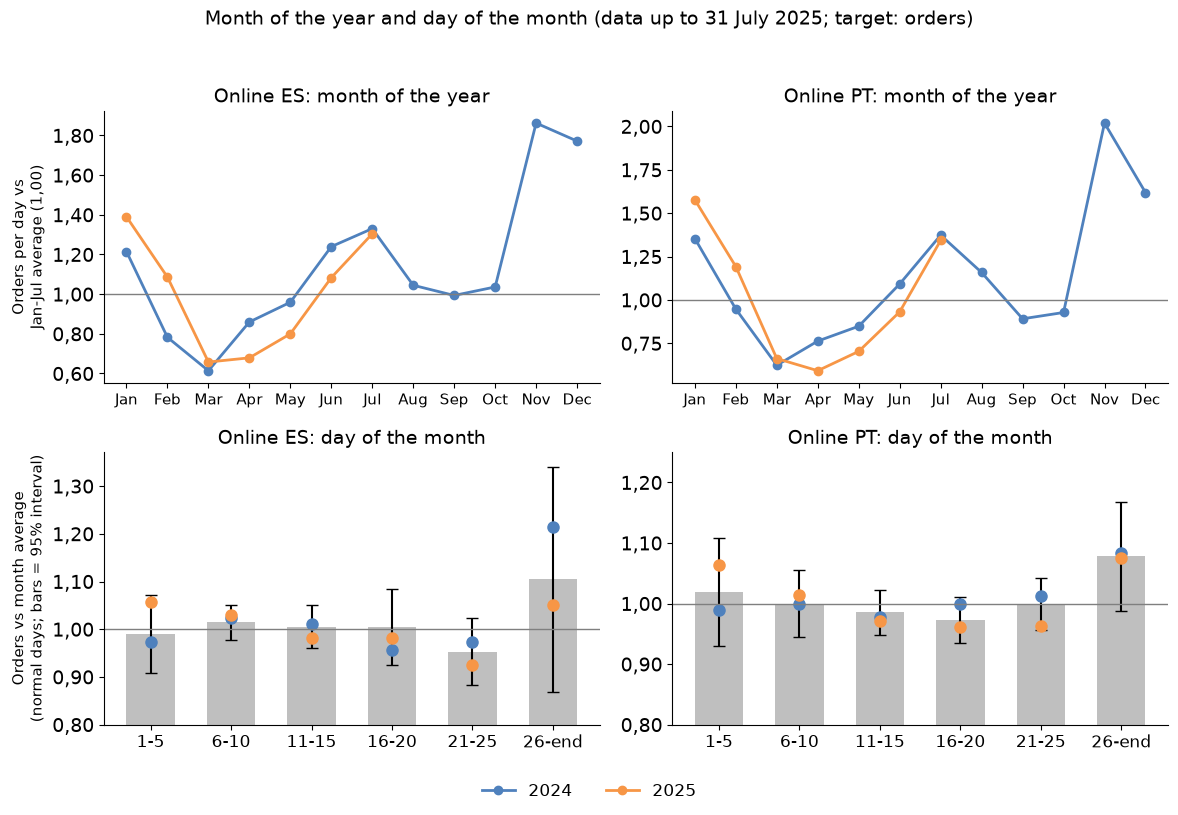

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Usa daily, TARGET, MARKETS, START, END, fmt(), pct(), save_table(), save_fig() (célula 1), TRAIN_END, train_only(), dec(), weekday_ratios(), weekday_index() (célula 5)
# e camp_days, hol_days (célula 8). Se reiniciaste o kernel, volta a correr as células 1, 5, 7 e 8.
for nome in ['daily', 'TARGET', 'MARKETS', 'START', 'END', 'fmt', 'pct', 'save_table', 'save_fig', 'TRAIN_END', 'train_only', 'dec',
             'weekday_ratios', 'weekday_index', 'camp_days', 'hol_days']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 5, 7 e 8 e depois esta.")

MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
BANDS = [(1, 5, '1-5'), (6, 10, '6-10'), (11, 15, '11-15'), (16, 20, '16-20'), (21, 25, '21-25'), (26, 31, '26-end')]
MIN_NORMAL = 15      # um mês só entra no estudo do dia do mês se tiver pelo menos 15 dias normais

# valor crítico t de Student (95%, bilateral) por graus de liberdade: com poucos meses, "2 erros-padrão" fica curto demais
T975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306, 9: 2.262, 10: 2.228, 11: 2.201, 12: 2.179}

def half_ci(v):
    # meia-largura do intervalo de 95% da média de v: t(n-1) x erro-padrão
    v = np.asarray(v, dtype=float)
    return T975.get(len(v) - 1, 1.96) * v.std(ddof=1) / np.sqrt(len(v))

def band_of(day):
    return next(lbl for lo, hi, lbl in BANDS if lo <= day <= hi)

def band_effects(adj, normal):
    # adj: encomendas por dia, já ajustadas ao dia da semana (índice = dia); normal: máscara de dias normais (sem campanha nem feriado).
    # Para cada mês: cada dia normal a dividir pela média dos dias normais desse mês; depois média por faixa do mês.
    # Assim o nível do mês (sazonalidade, tendência) fica de fora e sobra o efeito do dia do mês.
    x = adj[normal]
    rows = []
    for (y, m), g in x.groupby([x.index.year, x.index.month]):
        if len(g) < MIN_NORMAL:
            continue
        rel = g / g.mean()
        b = rel.groupby([band_of(d.day) for d in rel.index]).mean().to_dict()
        b.update({'year': y, 'month': m})
        rows.append(b)
    return pd.DataFrame(rows)

# ---------- controlo 1: com um efeito do dia do mês conhecido, o método recupera-o ----------
dt = pd.date_range('2024-01-01', '2025-06-30')
mf = pd.Series([1.0 + 0.05 * (d.month % 5) for d in dt], index=dt)                       # nível diferente em cada mês
bf_t = pd.Series([1.2 if d.day >= 26 else (1.0 if 11 <= d.day <= 15 else 1.05) for d in dt], index=dt)
sint = 1000 * mf * bf_t
be_t = band_effects(sint, pd.Series(True, index=dt))
razao = (be_t['26-end'] / be_t['11-15']).to_numpy()                                       # em cada mês a razão entre faixas tem de ser 1,2
print('--- Controlo 1: efeito do dia do mês conhecido (série sintética) ---')
print('Razão 26-fim / 11-15 em cada mês, mínimo e máximo:', f"{razao.min():.6f} e {razao.max():.6f}", '(esperado 1,2) | bate:',
      bool(np.abs(razao - 1.2).max() < 1e-9))

# controlo 1b: com 3 valores (1, 2, 3) o desvio-padrão é 1 e a meia-largura é 4,303 / raiz(3) = 2,484
print('Controlo 1b: meia-largura do intervalo para [1, 2, 3]:', f"{half_ci([1, 2, 3]):.3f}", '(esperado 2,484) | bate:', bool(abs(half_ci([1, 2, 3]) - 4.303 / np.sqrt(3)) < 1e-9))

# ---------- dados do estudo: só até 31/7/2025 ----------
d_study = train_only(daily)
wd = weekday_ratios(d_study, TARGET).assign(year=0)                  # índice do dia da semana por mercado, com todos os dias juntos
widx = weekday_index(wd).set_index(['mark', 'weekday'])['index']
series, adj, normal = {}, {}, {}
for mk, g in d_study.groupby('mark'):
    s = g.set_index('day')[TARGET].sort_index()
    series[mk] = s
    adj[mk] = s / np.array([widx[(mk, w)] for w in s.index.dayofweek])        # encomendas sem o efeito do dia da semana
    normal[mk] = pd.Series([(d not in camp_days[mk]) and (d not in hol_days[mk]) for d in s.index], index=s.index)

# ---------- 1) dia do mês ----------
rows15, be_all = [], {}
for mk in MARKETS:
    be = band_effects(adj[mk], normal[mk])
    be_all[mk] = be
    for lo, hi, lbl in BANDS:
        v = be[lbl].dropna()
        eff, se, h = v.mean(), v.std(ddof=1) / np.sqrt(len(v)), half_ci(v)
        v24 = be[(be['year'] == 2024) & (be['month'] <= 7)][lbl].dropna()
        v25 = be[(be['year'] == 2025) & (be['month'] <= 7)][lbl].dropna()
        rows15.append({'Market': mk, 'Day of the month': lbl, 'Effect (all months)': dec(eff), 'Standard error': dec(se),
                       '95% interval': f"{dec(eff - h)} to {dec(eff + h)}",
                       'Clear? (95% interval excludes 1,00)': 'yes' if abs(eff - 1) > h else 'no',
                       'Jan-Jul 2024': dec(v24.mean()) if len(v24) else '-', 'Jan-Jul 2025': dec(v25.mean()) if len(v25) else '-', 'Months used': len(v)})
dl15 = pd.DataFrame(rows15)
print('\n--- Efeito do dia do mês nas encomendas (dias normais, sem o efeito do dia da semana; 1,00 = média do mês) ---')
display(dl15)
save_table(dl15, 'DL15', f'Effect of the day of the month on daily orders by market, normal days up to 31 July 2025 (target: {TARGET})', 'whole table')

# ---------- 2) mês do ano: encomendas por dia de cada mês, relativas à média de janeiro a julho do próprio ano ----------
prof = {}
for mk in MARKETS:
    s = series[mk]
    pm = s.groupby([s.index.year, s.index.month]).mean()                              # encomendas por dia de cada mês (todos os dias, campanhas incluídas)
    for yr in (2024, 2025):
        media_jan_jul = np.mean([pm[(yr, m)] for m in range(1, 8)])                    # média de janeiro a julho desse ano
        prof[(mk, yr)] = {m: pm[(yr, m)] / media_jan_jul for m in range(1, 13) if (yr, m) in pm.index}
rows16 = []
for m in range(1, 13):
    row = {'Month': MONTHS[m - 1]}
    for mk in MARKETS:
        for yr in (2024, 2025):
            row[f'{mk} {yr}'] = dec(prof[(mk, yr)][m]) if m in prof[(mk, yr)] else '-'
    rows16.append(row)
dl16 = pd.DataFrame(rows16)
print('\n--- Mês do ano: encomendas por dia, relativas à média de janeiro a julho do mesmo ano (agosto a dezembro de 2025 fica fechado) ---')
display(dl16)
save_table(dl16, 'DL16', f'Orders per day by month relative to the January to July average of the same year, by market (target: {TARGET})', 'whole table')

rows17 = []
for mk in MARKETS:
    a = np.array([prof[(mk, 2024)][m] for m in range(1, 8)])
    b = np.array([prof[(mk, 2025)][m] for m in range(1, 8)])
    rows17.append({'Market': mk, 'Correlation of the Jan-Jul profile, 2024 vs 2025': dec(np.corrcoef(a, b)[0, 1]),
                   'Largest difference (index points)': dec(np.abs(a - b).max())})
dl17 = pd.DataFrame(rows17)
print('\n--- Estabilidade do perfil mensal entre 2024 e 2025 (janeiro a julho) ---')
display(dl17)
save_table(dl17, 'DL17', 'Stability of the monthly profile between 2024 and 2025, January to July, by market', 'whole table')

# ---------- controlo 2: meses usados e sem fugas ----------
print('\n--- Controlo 2: meses usados no dia do mês por mercado (esperado até 19, de janeiro de 2024 a julho de 2025):',
      {mk: len(be_all[mk]) for mk in MARKETS})
ult = max(series[mk].index.max() for mk in MARKETS)
print('Controlo 3: último dia usado:', ult.date(), '| bate (<= 31/7/2025):', bool(ult <= TRAIN_END))

# ---------- gráfico: mês do ano (em cima) e dia do mês (em baixo) ----------
fig, axes = plt.subplots(2, len(MARKETS), figsize=(12, 8.2))
for j, mk in enumerate(MARKETS):
    ax = axes[0, j]
    for yr, cor in [(2024, '#4F81BD'), (2025, '#F79646')]:
        ms = sorted(prof[(mk, yr)])
        ax.plot([m - 1 for m in ms], [prof[(mk, yr)][m] for m in ms], marker='o', color=cor, linewidth=2, label=str(yr))
    ax.axhline(1, color='#7F7F7F', linewidth=1)
    ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS, fontsize=11)
    ax.set_title(f'{mk}: month of the year', fontsize=14); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: dec(v)))
    if j == 0:
        ax.set_ylabel('Orders per day vs\nJan-Jul average (1,00)', fontsize=11)
    ax2 = axes[1, j]
    be = be_all[mk]
    eff = [be[lbl].dropna().mean() for _, _, lbl in BANDS]
    se2 = [half_ci(be[lbl].dropna()) for _, _, lbl in BANDS]
    ax2.bar(range(len(BANDS)), eff, yerr=se2, capsize=4, color='#BFBFBF', width=0.6)
    for yr, cor in [(2024, '#4F81BD'), (2025, '#F79646')]:
        vals = [be[(be['year'] == yr) & (be['month'] <= 7)][lbl].dropna().mean() for _, _, lbl in BANDS]
        ax2.plot(range(len(BANDS)), vals, marker='o', linestyle='none', color=cor, markersize=8)
    ax2.axhline(1, color='#7F7F7F', linewidth=1)
    todos = np.array(eff + [e + h for e, h in zip(eff, se2)] + [e - h for e, h in zip(eff, se2)]
                     + [be[(be['year'] == yr) & (be['month'] <= 7)][lbl].dropna().mean() for yr in (2024, 2025) for _, _, lbl in BANDS], dtype=float)
    ax2.set_ylim(min(0.8, np.nanmin(todos) - 0.03), max(1.25, np.nanmax(todos) + 0.03))      # o eixo nunca corta os valores nem os intervalos
    ax2.set_xticks(range(len(BANDS))); ax2.set_xticklabels([b for _, _, b in BANDS], fontsize=12)
    ax2.set_title(f'{mk}: day of the month', fontsize=14); ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: dec(v)))
    if j == 0:
        ax2.set_ylabel('Orders vs month average\n(normal days; bars = 95% interval)', fontsize=11)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=12)
fig.suptitle(f'Month of the year and day of the month (data up to 31 July 2025; target: {TARGET})', fontsize=14)
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_fig(fig, 'DL18', f'Month-of-the-year profile and day-of-the-month effect on daily orders by market (target: {TARGET})', 'whole table')
plt.show()

# Eficiência: o ajuste ao dia da semana é O(d); cada mês é percorrido uma vez, O(d) no total; os perfis mensais e a correlação são O(12·mercados).
# Espaço O(d), com d = 578 dias por mercado até 31/7/2025.

### 9a. Conclusões sobre o mês do ano e o dia do mês

**Confirmado (tabela inteira):**
- Os controlos coincidem: o efeito conhecido do dia do mês (razão 1,2) é recuperado, e o intervalo de 95% dá o valor esperado (2,484 para [1, 2, 3]). O último dia usado é 31/7/2025.
- Só 8 dos 19 meses (janeiro de 2024 a julho de 2025) têm 15 dias normais, em cada mercado. Cerca de 60% dos dias são campanha ou feriado, e a faixa 26-fim só tem 3 meses (abril de 2024, março e maio de 2025).
- No fim do mês, 84% dos dias ficam fora do estudo (17% a 20% em campanha fixa e 63% a 67% noutras campanhas ou feriados), contra 43% a 65% nas outras faixas.

**Derivado do que vimos:**
- **Dia do mês:** nenhuma faixa é clara (o intervalo de 95% inclui sempre 1,00). A mais afastada é o fim do mês: Portugal 1,08 (intervalo 0,99 a 1,17) e Espanha 1,10 (0,87 a 1,34). Fora o fim do mês, os valores ficam entre 0,95 e 1,02.
- **Fim do mês:** os seis valores mensais são acima de 1,03, mas vêm de 3 meses de primavera. Em Portugal 2024 e 2025 coincidem (1,08), mas 2024 é um só mês. Em Espanha não (1,21 e 1,05). Escolher a maior de 12 faixas também sobrestima o efeito.
- **Campanhas no fim do mês:** é onde mais se concentram as campanhas fora do calendário fixo, que o modelo não conhece. Uma variável de dia do mês pode apanhar parte delas.
- **Mês do ano:** a forma geral repete-se (janeiro alto, março baixo, julho alto). Em 2025, janeiro e fevereiro sobem (+0,18 a +0,31) e abril a junho descem (−0,15 a −0,18), nos dois mercados e no mesmo sentido. A correlação entre anos é 0,78 em Espanha e 0,89 em Portugal. A Páscoa (31/3/2024 e 20/4/2025) só explicaria março e abril. A causa não foi testada.
- **Agosto a dezembro:** só existe em 2024, uma vez por mês. Novembro e dezembro (1,6 a 2,0) vêm da Black Friday e do Natal.
- Com dois anos, o efeito de cada mês não se separa do das campanhas e da tendência.

**Filtro das variáveis:**
- Conhece-se no corte? Sim, é calendário.
- É estável entre 2024 e 2025? Dia do mês: só em Portugal, e com 1 mês em 2024. Mês do ano: a forma geral sim, o detalhe não.
- Ajuda a reduzir o erro no Training? Só se vê mais tarde.


### 9b. Que meses sustentam o fim do mês, e quanto fica de fora?

**O que vamos fazer:** (1) listar os meses usados na faixa 26-fim e o valor de cada um; (2) medir, por faixa do mês, que parte dos dias fica fora do estudo por ser campanha ou feriado (janeiro de 2024 a julho de 2025).

**Objetivo:** perceber porque a faixa 26-fim só tem 3 meses e se as campanhas se concentram no fim do mês. Se se concentrarem, uma variável de dia do mês pode estar a apanhar campanhas que o modelo não conhece.

In [14]:
import numpy as np
import pandas as pd

# Usa MARKETS, dec(), pct() (célula 1/5), series, normal, be_all, BANDS, band_of() (célula 9) e camp_fams, FIXED_FAMS (célula 8).
# Se reiniciaste o kernel, volta a correr as células 1, 5, 7, 8 e 9.
for nome in ['MARKETS', 'dec', 'pct', 'series', 'normal', 'be_all', 'BANDS', 'band_of', 'camp_fams', 'FIXED_FAMS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 5, 7, 8 e 9 e depois esta.")

# ---------- 1) os meses que sustentam a faixa 26-fim: quais são e quanto vale cada um ----------
print('--- Faixa 26-fim: valor de cada mês usado (dias normais, sem o efeito do dia da semana) ---')
for mk in MARKETS:
    v = be_all[mk][['year', 'month', '26-end']].dropna()
    v['26-end'] = v['26-end'].map(dec)
    print(mk); display(v.reset_index(drop=True))

# ---------- 2) que parte de cada faixa do mês fica de fora por ser campanha ou feriado ----------
rows = []
for mk in MARKETS:
    days = series[mk].index                                         # dias de janeiro de 2024 a 31/7/2025
    for lo, hi, lbl in BANDS:
        dd = [d for d in days if band_of(d.day) == lbl]
        n_not_normal = sum(not normal[mk][d] for d in dd)
        n_fixed = sum(any(f in FIXED_FAMS for f in camp_fams.get((mk, d), [])) for d in dd)
        rows.append({'Market': mk, 'Day of the month': lbl, 'Days': len(dd),
                     'Not normal (campaign or holiday)': pct(n_not_normal / len(dd)),
                     'of which in a fixed-calendar campaign': pct(n_fixed / len(dd)),
                     'in another campaign or holiday only': pct((n_not_normal - n_fixed) / len(dd))})
print('\n--- Parte de cada faixa do mês que fica de fora do estudo do dia do mês (janeiro de 2024 a julho de 2025) ---')
display(pd.DataFrame(rows))

# Eficiência: percorre cada dia uma vez por faixa e mercado, O(d·b) com b = 6 faixas; espaço O(d), com d = 578 dias por mercado.

--- Faixa 26-fim: valor de cada mês usado (dias normais, sem o efeito do dia da semana) ---
Online ES


,year,month,26-end
0,2024,4,"1,21"
1,2025,3,"1,04"
2,2025,5,"1,06"


Online PT


,year,month,26-end
0,2024,4,"1,08"
1,2025,3,"1,04"
2,2025,5,"1,11"



--- Parte de cada faixa do mês que fica de fora do estudo do dia do mês (janeiro de 2024 a julho de 2025) ---


,Market,Day of the month,Days,Not normal (campaign or holiday),of which in a fixed-calendar campaign,in another campaign or holiday only
0,Online ES,1-5,95,"43,2%","5,3%","37,9%"
1,Online ES,6-10,95,"49,5%","11,6%","37,9%"
2,Online ES,11-15,95,"60,0%","6,3%","53,7%"
3,Online ES,16-20,95,"65,3%","14,7%","50,5%"
4,Online ES,21-25,95,"65,3%","8,4%","56,8%"
5,Online ES,26-end,103,"83,5%","20,4%","63,1%"
6,Online PT,1-5,95,"48,4%","3,2%","45,3%"
7,Online PT,6-10,95,"51,6%","11,6%","40,0%"
8,Online PT,11-15,95,"60,0%","6,3%","53,7%"
9,Online PT,16-20,95,"65,3%","14,7%","50,5%"


**Decisão:**
- **Dia do mês:** entra como candidata a variável, numa flag simples: 1 do dia 26 em diante, 0 nos restantes dias.
- **Mês do ano:** entra como candidata a variável cíclica: seno e cosseno do mês (2 colunas).
- Cada uma é medida no Training do modelo de Deep Learning, com e sem a variável, com as mesmas sementes e a mesma grelha. Decide-se pela média do WAPE e pela dispersão entre sementes. Se não ajudar no Training, sai.
- Se a flag do fim do mês ajudar, não saberemos se é o efeito do dia de pagamento ou de campanhas que se concentram no fim do mês e que o modelo não conhece.
- O mês do ano pode contar duas vezes o que a Black Friday e o Natal já explicam. Novembro e dezembro só se vêem uma vez, em 2024. O teste com e sem mede isso.

## 10. Categoria de produto: reconhecimento das tabelas

**O que vamos fazer:** ver como a tabela de produtos da camada silver (`slv_product`) se liga às linhas de venda (`slv_order_det`): que colunas existem, a chave de ligação (`prod_sfk` nas vendas = `prod_spk` nos produtos), quantas linhas de venda encontram o produto e que colunas de categoria existem (categoria, grupo, subgrupo, coleção, época), e se formam uma hierarquia. As duas tabelas são lidas inteiras (todos os mercados e datas): este ponto só reconhece as tabelas.

**Objetivo:** perceber se a categoria pode ser usada sem erros, e como, para decidir mais tarde. A categoria **fica fora do modelo por agora**. A ideia que fica para depois (ainda por provar): em cada corte, medir o peso de cada categoria nas vendas recentes, por exemplo a quota de cada categoria nas últimas 4 semanas. A categoria do produto vendido é conhecida no corte; o que não se conhece é a categoria das vendas futuras.

**Pontos de cuidado:**
- A silver já tem uma linha por produto (`prod_spk`), por isso a ligação não duplica vendas. Retirou também os produtos sem subgrupo e os que não são mercadoria (por exemplo, Marketing ou Consumíveis): as linhas de venda desses produtos não encontram produto, e convém ver quantas são.
- A tabela guarda uma só versão de cada produto. Se a empresa reclassificar um produto, o histórico usaria a classificação atual (por confirmar com a empresa).
- A categoria só entra com dados até ao corte de cada mês; o estudo posterior usa só dados até 31/7/2025.

**Valores de controlo:** uma linha por produto em `slv_product`; a quota de linhas de venda com produto encontrado deve ser próxima de 100% (a diferença são os produtos que a silver retirou), e a coluna "Lines not found" mostra quantas linhas faltam em cada tipo.


In [15]:
import numpy as np
import pandas as pd
from lakehouse import LakeConfig, connect

# Usa fmt(), pct(), save_table() (célula 1). Se reiniciaste o kernel, volta a correr a célula 1.
for nome in ['fmt', 'pct', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e depois esta.")

lake = LakeConfig.from_env()   # nomes dos buckets e credenciais vêm do cofre
con = connect()                # DuckDB em memória, já ligado ao lake
SILVER_DET = f"'{lake.uri('silver', 'slv_order_det')}.parquet'"
SILVER_PROD = f"'{lake.uri('silver', 'slv_product')}.parquet'"
con.execute(f"CREATE OR REPLACE TEMP VIEW det10 AS SELECT * FROM read_parquet({SILVER_DET})")
con.execute(f"CREATE OR REPLACE TEMP VIEW prod10 AS SELECT * FROM read_parquet({SILVER_PROD})")

# ---------- 1) colunas e tamanho das duas tabelas ----------
cols_det = con.sql("DESCRIBE SELECT * FROM det10").df()[['column_name', 'column_type']]
cols_prod = con.sql("DESCRIBE SELECT * FROM prod10").df()[['column_name', 'column_type']]
n_det = con.execute("SELECT count(*) FROM det10").fetchall()[0][0]
n_prod = con.execute("SELECT count(*) FROM prod10").fetchall()[0][0]
print('--- Linhas: slv_order_det', fmt(n_det), '| slv_product', fmt(n_prod))
print('\n--- Colunas de slv_order_det ---'); display(cols_det)
print('--- Colunas de slv_product ---'); display(cols_prod)

# ---------- 2) a chave de ligação: slv_order_det.prod_sfk aponta para slv_product.prod_spk (documentação da silver) ----------
rows_p, uniq_p = con.execute("SELECT count(*), count(DISTINCT prod_spk) FROM prod10").fetchall()[0]
print('\nChave: prod_sfk (vendas) = prod_spk (produtos). Linhas em slv_product:', fmt(rows_p), '| chaves distintas:', fmt(uniq_p),
      '| bate (uma linha por produto):', bool(rows_p == uniq_p))

# ---------- 3) quantas linhas de venda encontram o produto? (os produtos sem subgrupo e os que não são mercadoria foram retirados da silver) ----------
t = con.execute("""
    SELECT d.type, count(*) AS lines, sum(d.prod_qty) AS units, count(p.prod_spk) AS lines_found,
           sum(CASE WHEN p.prod_spk IS NOT NULL THEN d.prod_qty ELSE 0 END) AS units_found,
           count(DISTINCT d.prod_sfk) FILTER (WHERE p.prod_spk IS NULL) AS products_not_found
    FROM det10 d LEFT JOIN prod10 p ON d.prod_sfk = p.prod_spk
    GROUP BY d.type ORDER BY d.type""").df()
dl20 = pd.DataFrame({'Line type': t['type'], 'Lines': t['lines'].map(fmt), 'Lines with a product': t['lines_found'].map(fmt),
                     'Lines not found': (t['lines'] - t['lines_found']).map(fmt),
                     'Share of lines found': (t['lines_found'] / t['lines']).map(pct),
                     'Share of units found': (t['units_found'].astype(float) / t['units'].astype(float)).map(pct),
                     'Distinct products not found': t['products_not_found'].map(fmt)})
print('\n--- Ligação entre as linhas de venda e os produtos (prod_sfk = prod_spk), por tipo de linha ---')
display(dl20)
save_table(dl20, 'DL19', 'Join between order lines and the product table (prod_sfk = prod_spk), by line type', 'whole table')

# ---------- 4) valores de active_record e cat_active (booleanos) ----------
for c in ['active_record', 'cat_active']:
    if c in set(cols_prod['column_name']):
        print(f'\n--- Valores de {c} em slv_product ---')
        display(con.sql(f'SELECT "{c}" AS valor, count(*) AS linhas FROM prod10 GROUP BY 1 ORDER BY 2 DESC').df())

# ---------- 5) colunas de categoria: valores distintos, vazios e os mais frequentes ----------
CAT_COLS = [c for c in ['cat_des_en', 'gfa_des_en', 'gfs_des_en', 'collection_type', 'sea_cod', 'fashiontype', 'tar_des'] if c in set(cols_prod['column_name'])]
rows19 = []
for c in CAT_COLS:
    q = f'"{c}"'
    dist, nulls = con.execute(f"SELECT count(DISTINCT {q}), count(*) FILTER (WHERE {q} IS NULL) FROM prod10").fetchall()[0]
    top = con.execute(f"SELECT {q}, count(*) AS n FROM prod10 WHERE {q} IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 5").fetchall()
    rows19.append({'Column': c, 'Distinct values': dist, 'Empty share': pct(nulls / n_prod) if n_prod else '-',
                   'Most frequent values (product rows)': '; '.join(f"{v} ({fmt(n)})" for v, n in top)})
dl19 = pd.DataFrame(rows19)
print('\n--- Colunas de categoria da tabela slv_product ---')
display(dl19)
save_table(dl19, 'DL20', 'Category columns of the product table: distinct values, empty share and most frequent values', 'whole table')

# ---------- 6) hierarquia: cada valor de uma coluna pertence a um só valor da coluna "acima"? (categoria > grupo > subgrupo) ----------
rows21 = []
hier = [(a, b) for a in ['gfs_des_en', 'gfa_des_en'] for b in ['gfa_des_en', 'cat_des_en'] if a != b and a in CAT_COLS and b in CAT_COLS]
for child, parent in hier:
    n_child, n_multi = con.execute(f"""
        SELECT count(*), count(*) FILTER (WHERE np > 1) FROM (
          SELECT "{child}", count(DISTINCT "{parent}") AS np FROM prod10
          WHERE "{child}" IS NOT NULL AND "{parent}" IS NOT NULL GROUP BY 1)""").fetchall()[0]
    rows21.append({'Child column': child, 'Parent column': parent, 'Child values': n_child, 'With more than one parent': n_multi,
                   'Is it a hierarchy?': 'yes' if n_multi == 0 else 'no'})
dl21 = pd.DataFrame(rows21)
print('\n--- Hierarquia entre as colunas de categoria ---')
display(dl21)
save_table(dl21, 'DL21', 'Is each category value inside a single value of the level above?', 'whole table')

# Eficiência: cada verificação é uma passagem por slv_order_det (O(n), n ≈ 9 milhões de linhas) ou por slv_product (O(p)); a junção usa a chave única prod_spk, O(n + p).
# Espaço O(p) para a tabela hash dos produtos.

--- Linhas: slv_order_det 9.011.416 | slv_product 246.821

--- Colunas de slv_order_det ---


,column_name,column_type
0,type,VARCHAR
1,order_id,VARCHAR
2,prod_sfk,BIGINT
3,prod_qty,INTEGER
4,mov_date,DATE
5,mov_date_key,BIGINT
6,amount_fixed_rate_w_disc_wo_vat,"DECIMAL(18,5)"
7,amount_fixed_rate_wo_disc_wo_vat,"DECIMAL(18,5)"
8,_ingested_at,TIMESTAMP
9,_batch_id,VARCHAR


--- Colunas de slv_product ---


,column_name,column_type
0,prod_spk,BIGINT
1,prod_cod,VARCHAR
2,cat_des_en,VARCHAR
3,gfa_des_en,VARCHAR
4,gfs_des_en,VARCHAR
5,collection_type,VARCHAR
6,sea_cod,SMALLINT
7,active_record,BOOLEAN
8,cat_active,BOOLEAN
9,fashiontype,VARCHAR



Chave: prod_sfk (vendas) = prod_spk (produtos). Linhas em slv_product: 246.821 | chaves distintas: 246.821 | bate (uma linha por produto): True

--- Ligação entre as linhas de venda e os produtos (prod_sfk = prod_spk), por tipo de linha ---


,Line type,Lines,Lines with a product,Lines not found,Share of lines found,Share of units found,Distinct products not found
0,CANCELLED,45.044,45.044,0,"100,0%","100,0%",0
1,RETURN,1.483.745,1.483.388,357,"100,0%","100,0%",2
2,SALE,7.482.627,7.482.627,0,"100,0%","100,0%",0


... (5 outputs left out)

,Column,Distinct values,Empty share,Most frequent values (product rows)
0,cat_des_en,21,"0,0%",Apparel (67.327); Jewellery (57.946); Hand Bag...
1,gfa_des_en,163,"0,0%",Earrings (33.001); Rings (18.911); Necklaces (...
2,gfs_des_en,223,"0,0%",Woven (35.923); Plain PU (15.992); Knit (15.57...
3,collection_type,20,"0,0%",Core Collection (196.635); Exclusive Online (1...
4,sea_cod,9,"0,0%",242 (40.640); 251 (31.739); 241 (31.070); 232 ...
5,fashiontype,20,"0,0%",Fashion (95.726); Basic (53.233); Fashion Basi...
6,tar_des,3,"0,0%",Finished Product (245.674); Packs (1.145); Wor...


Guardado: evidence_dl/DL20.csv

--- Hierarquia entre as colunas de categoria ---


,Child column,Parent column,Child values,With more than one parent,Is it a hierarchy?
0,gfs_des_en,gfa_des_en,223,87,no
1,gfs_des_en,cat_des_en,223,95,no
2,gfa_des_en,cat_des_en,163,22,no


Guardado: evidence_dl/DL21.csv


### 10a. Conclusões

**Confirmado (tabela inteira):**
- As duas tabelas têm 9.011.416 linhas de venda (`slv_order_det`) e 246.821 produtos (`slv_product`). A chave `prod_spk` é única (246.821 linhas, 246.821 chaves distintas), por isso a junção `prod_sfk = prod_spk` não duplica linhas de venda.
- Linhas SALE: 7.482.627, todas com produto encontrado (0 sem produto). Linhas CANCELLED: 45.044, todas encontradas. Nada se perde nas linhas que contam para as encomendas.
- Linhas RETURN: 357 de 1.483.745 não encontram produto (2 produtos distintos). A percentagem arredonda para 100,0%, mas a coluna "Lines not found" mostra o valor exato. Como as devoluções não reduzem encomendas, isto não afeta o alvo.
- Todas as colunas de categoria estão preenchidas (0,0% de vazios). Valores distintos: categoria `cat_des_en` 21, grupo `gfa_des_en` 163, subgrupo `gfs_des_en` 223, `collection_type` 20, `sea_cod` 9, `fashiontype` 20, `tar_des` 3.
- Não é uma hierarquia: 87 dos 223 subgrupos (39%) aparecem em mais de um grupo, 95 dos 223 (43%) em mais de uma categoria, e 22 dos 163 grupos (13%) em mais de uma categoria.
- `active_record` é falso em 175.204 produtos (71%) e verdadeiro em 71.617. `cat_active` é falso em apenas 2.

**Decisão:**
- A categoria de produto fica fora do modelo por agora, como definido.
- Se voltar a entrar, o nível mais seguro é a categoria (`cat_des_en`, 21 valores), porque grupos e subgrupos não se encaixam uns nos outros.
- Uma encomenda com produtos de duas categorias contaria nas duas, por isso a soma das encomendas por categoria não daria o total de encomendas. Isto teria de ser resolvido antes de prever por categoria.
- O significado de `active_record` não está documentado nos dados que vimos. Não o usamos nem o interpretamos.

## 11. Paid media: reconhecimento da tabela

**O que vamos fazer:** ver a tabela `slv_paid_media` da camada silver (investimento diário em paid media por mercado): que colunas tem, que mercados e datas cobre, se há dias em falta, repetidos, vazios ou negativos, e como o investimento mensal se compara com as encomendas.

**Objetivo:** decidir se o paid media pode entrar no modelo e de que forma. Só olhamos para os dados até 31/7/2025 (fim do Training); agosto a dezembro continua reservado para o Test.

**Pontos de cuidado:**
- A tabela tem o investimento **realizado** em cada dia. Para prever o mês M com dados até ao fim de M-2, o investimento de M só pode entrar se a empresa o souber (planeado) antes do corte. Assumimos que sim, mas falta confirmar com a empresa. O investimento de M-2 e anteriores é sempre conhecido.
- A unidade de `amount_paid_media` não está documentada na silver. Não assumimos euros.
- Correlação não é efeito: o investimento tende a subir nas alturas das campanhas, que já temos assinaladas.
- Os dias sem linha na tabela ficam vazios, não zero, para não esconder falhas nos dados.

**Valores de controlo:** Online ES e Online PT existem em `marketplace`; 731 dias por mercado em 2024-2025; sem valores negativos (se houver, vemos quantos).

--- Linhas em slv_paid_media: 14.252
--- Colunas de slv_paid_media ---


,column_name,column_type
0,paid_media_date,DATE
1,paid_media_date_key,BIGINT
2,marketplace,VARCHAR
3,amount_paid_media,"DECIMAL(18,3)"
4,_ingested_at,TIMESTAMP
5,_batch_id,VARCHAR



--- Mercados em slv_paid_media ---


,marketplace,table_rows,days,first_day,last_day
0,Online AT,727,727,2024-01-01,2025-12-31
1,Online BE,727,727,2024-01-01,2025-12-31
2,Online CH,464,464,2024-09-20,2025-12-31
3,Online CZ,538,538,2024-07-08,2025-12-31
4,Online DE,727,727,2024-01-01,2025-12-31
5,Online DK,258,258,2025-04-14,2025-12-31
6,Online EE,478,478,2024-09-06,2025-12-31
7,Online ES,731,731,2024-01-01,2025-12-31
8,Online FR,731,731,2024-01-01,2025-12-31
9,Online HU,727,727,2024-01-01,2025-12-31



--- Cobertura e qualidade da tabela de paid media, por mercado ---


,Market,Table rows (all dates),First day in table,Last day in table,Rows after the end of the scope,Days with a row in 2024-2025,Days with more than one row,Days with an empty amount,Days with zero spend,Days with negative spend
0,Online ES,731,2024-01-01,2025-12-31,0,731 of 731,0,0,0,0
1,Online PT,731,2024-01-01,2025-12-31,0,731 of 731,0,0,0,0


Guardado: evidence_dl/DL22.csv

--- Paid media e encomendas por mês (até 2025-07-31; unidade do valor = a da fonte) ---


,Market,Month,Orders,Paid media,Days with spend data,Paid media per order
0,Online ES,2024-01,80.536,95.625,31 of 31,"1,19"
1,Online ES,2024-02,48.517,57.710,29 of 29,"1,19"
2,Online ES,2024-03,40.708,65.923,31 of 31,"1,62"
3,Online ES,2024-04,55.157,83.555,30 of 30,"1,51"
4,Online ES,2024-05,63.580,106.288,31 of 31,"1,67"
5,Online ES,2024-06,79.528,132.424,30 of 30,"1,67"
6,Online ES,2024-07,88.191,114.783,31 of 31,"1,30"
7,Online ES,2024-08,69.262,87.542,31 of 31,"1,26"
8,Online ES,2024-09,63.736,129.724,30 of 30,"2,04"
9,Online ES,2024-10,68.697,115.482,31 of 31,"1,68"


Guardado: evidence_dl/DL23.csv

--- Correlação entre paid media e encomendas (até 2025-07-31) ---


,Market,"Daily, same day","Monthly, level","Monthly, change vs previous month",Spend of month M-2 vs orders of month M
0,Online ES,"0,72 (578 days)","0,91 (19 months)","0,78 (18 months)","0,39 (17 months)"
1,Online PT,"0,69 (578 days)","0,89 (19 months)","0,78 (18 months)","0,26 (17 months)"
2,ES+PT,"0,74 (578 days)","0,91 (19 months)","0,79 (18 months)","0,36 (17 months)"


Guardado: evidence_dl/DL24.csv


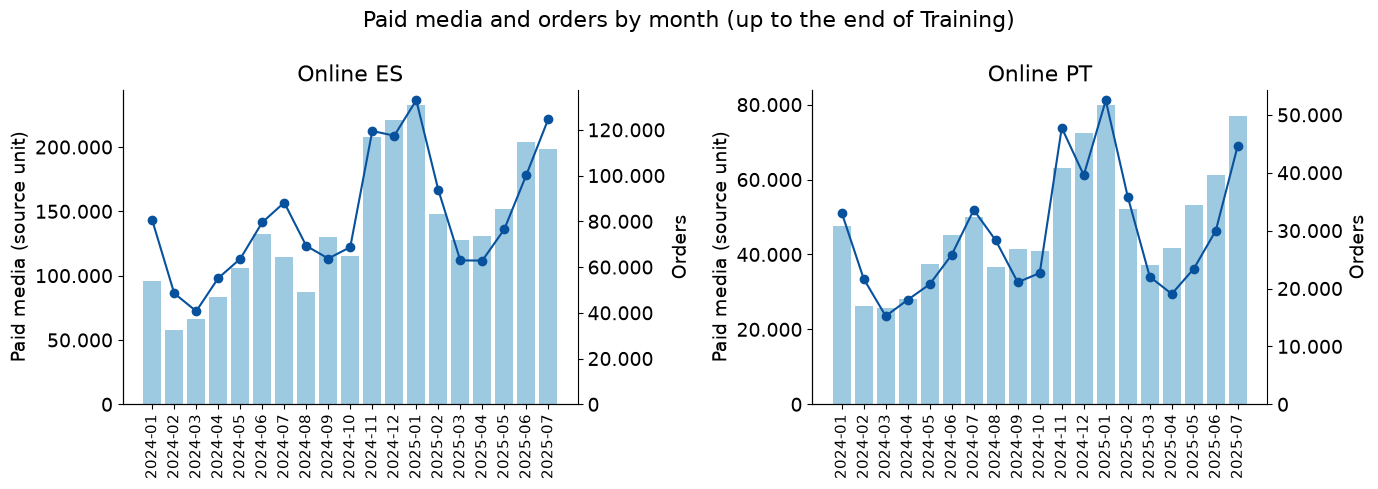

Guardado: evidence_dl/DL25.png


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from lakehouse import LakeConfig, connect

# Usa daily, MARKETS, START, END, fmt(), dec(), save_table(), save_fig() (célula 1) e TRAIN_END (célula 5).
# Se reiniciaste o kernel, volta a correr as células 1 e 5.
for nome in ['daily', 'MARKETS', 'START', 'END', 'fmt', 'save_table', 'save_fig', 'TRAIN_END']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 e 5 e depois esta.")

lake = LakeConfig.from_env()   # nomes dos buckets e credenciais vêm do cofre
con = connect()                # DuckDB em memória, já ligado ao lake
SILVER_PM = f"'{lake.uri('silver', 'slv_paid_media')}.parquet'"
con.execute(f"CREATE OR REPLACE TEMP VIEW pm11 AS SELECT * FROM read_parquet({SILVER_PM})")
mk_in11 = ', '.join(f"'{m}'" for m in MARKETS)
TR = pd.Timestamp(TRAIN_END)                      # a análise só usa dados até ao fim do Training
dec2 = lambda x: f"{x:.2f}".replace('.', ',') if x is not None and not pd.isna(x) else '-'   # 2 casas decimais, vírgula decimal (não mexe no dec das células anteriores)

# ---------- 1) colunas e tamanho da tabela ----------
cols_pm = con.sql("DESCRIBE SELECT * FROM pm11").df()[['column_name', 'column_type']]
n_pm = con.execute("SELECT count(*) FROM pm11").fetchall()[0][0]
print('--- Linhas em slv_paid_media:', fmt(n_pm))
print('--- Colunas de slv_paid_media ---'); display(cols_pm)

# ---------- 2) que mercados existem (para confirmar os nomes) ----------
mk_all = con.sql("""SELECT marketplace, count(*) AS table_rows, count(DISTINCT paid_media_date) AS days,
                           min(paid_media_date) AS first_day, max(paid_media_date) AS last_day
                    FROM pm11 GROUP BY 1 ORDER BY 1""").df()
mk_all['table_rows'] = mk_all['table_rows'].map(fmt); mk_all['days'] = mk_all['days'].map(fmt)
print('\n--- Mercados em slv_paid_media ---'); display(mk_all)
em_falta = [m for m in MARKETS if m not in set(mk_all['marketplace'])]
if em_falta:
    raise RuntimeError(f"Os mercados {em_falta} não existem em slv_paid_media.marketplace. Confirma os nomes na tabela acima.")

# ---------- 3) uma linha por mercado e dia ----------
pm = con.execute(f"""
    SELECT marketplace AS mark, paid_media_date AS day, count(*) AS n_rows, sum(amount_paid_media) AS spend,
           count(*) FILTER (WHERE amount_paid_media IS NULL) AS n_null
    FROM pm11 WHERE marketplace IN ({mk_in11}) AND paid_media_date IS NOT NULL GROUP BY 1, 2""").df()
pm['day'] = pd.to_datetime(pm['day']); pm['spend'] = pm['spend'].astype(float)

# ---------- 4) DL22: cobertura e qualidade, por mercado ----------
N_SCOPE = int((pd.Timestamp(END) - pd.Timestamp(START)).days) + 1   # dias do âmbito (731)
rows22 = []
for m in MARKETS:
    g = pm[pm['mark'] == m]
    w = g[(g['day'] >= START) & (g['day'] <= END)]
    rows22.append({'Market': m, 'Table rows (all dates)': fmt(g['n_rows'].sum()),
                   'First day in table': g['day'].min().date(), 'Last day in table': g['day'].max().date(),
                   'Rows after the end of the scope': fmt(g.loc[g['day'] > END, 'n_rows'].sum()),
                   'Days with a row in 2024-2025': f"{fmt(w.shape[0])} of {fmt(N_SCOPE)}",
                   'Days with more than one row': fmt((w['n_rows'] > 1).sum()),
                   'Days with an empty amount': fmt((w['n_null'] > 0).sum()),
                   'Days with zero spend': fmt((w['spend'] == 0).sum()),
                   'Days with negative spend': fmt((w['spend'] < 0).sum())})
dl22 = pd.DataFrame(rows22)
print('\n--- Cobertura e qualidade da tabela de paid media, por mercado ---')
display(dl22)
save_table(dl22, 'DL22', 'Paid media table: coverage and quality by market (2024-2025)', 'whole table')

# ---------- 5) tabela diária com o investimento ao lado das encomendas (só até ao fim do Training) ----------
d = daily[['mark', 'day', 'month', 'orders']].merge(pm[['mark', 'day', 'spend']], on=['mark', 'day'], how='left')
d = d[d['day'] <= TR].copy()                       # os dias sem linha em paid media ficam vazios (não são zero)

# ---------- 6) DL23: mês a mês, por mercado ----------
mo = (d.groupby(['mark', 'month'])
        .agg(orders=('orders', 'sum'), spend=('spend', lambda s: s.sum(min_count=1)),
             days_spend=('spend', 'count'), days=('day', 'size')).reset_index())
mo['complete'] = mo['days_spend'] == mo['days']
dl23 = pd.DataFrame({'Market': mo['mark'], 'Month': mo['month'].astype(str), 'Orders': mo['orders'].map(fmt),
                     'Paid media': mo['spend'].map(fmt), 'Days with spend data': mo['days_spend'].astype(str) + ' of ' + mo['days'].astype(str),
                     'Paid media per order': (mo['spend'] / mo['orders']).map(dec2)})
print('\n--- Paid media e encomendas por mês (até ' + str(TR.date()) + '; unidade do valor = a da fonte) ---')
display(dl23)
save_table(dl23, 'DL23', 'Paid media and orders by month and market, up to the end of Training', 'whole table')

# ---------- 7) DL24: correlações (só descrição; não prova efeito) ----------
def corr(a, b):
    ok = a.notna() & b.notna()
    return (a[ok].corr(b[ok]) if ok.sum() >= 3 else np.nan), int(ok.sum())

def monthly_view(mkt):
    # mkt = nome do mercado ou 'ES+PT'. Meses incompletos ficam com investimento vazio.
    if mkt == 'ES+PT':
        t = mo.groupby('month').agg(orders=('orders', 'sum'), spend=('spend', 'sum'), complete=('complete', 'all')).reset_index()
        t = t.sort_values('month')
    else:
        t = mo[mo['mark'] == mkt].sort_values('month').copy()
    t['spend'] = t['spend'].where(t['complete'])
    return t.reset_index(drop=True)

rows24 = []
for mkt in MARKETS + ['ES+PT']:
    if mkt == 'ES+PT':
        dd = d.groupby('day').agg(orders=('orders', 'sum'), spend=('spend', lambda s: s.sum(min_count=len(s)))).reset_index()
    else:
        dd = d[d['mark'] == mkt]
    r_day, n_day = corr(dd['orders'].astype(float), dd['spend'])
    t = monthly_view(mkt)
    r_lvl, n_lvl = corr(t['orders'].astype(float), t['spend'])
    ch_o = t['orders'].astype(float).pct_change().replace([np.inf, -np.inf], np.nan)
    ch_s = t['spend'].pct_change().replace([np.inf, -np.inf], np.nan)
    r_chg, n_chg = corr(ch_o, ch_s)
    r_lag, n_lag = corr(t['orders'].astype(float), t['spend'].shift(2))     # investimento de M-2 contra encomendas de M
    rows24.append({'Market': mkt,
                   'Daily, same day': f"{dec2(r_day)} ({n_day} days)",
                   'Monthly, level': f"{dec2(r_lvl)} ({n_lvl} months)",
                   'Monthly, change vs previous month': f"{dec2(r_chg)} ({n_chg} months)",
                   'Spend of month M-2 vs orders of month M': f"{dec2(r_lag)} ({n_lag} months)"})
dl24 = pd.DataFrame(rows24)
print('\n--- Correlação entre paid media e encomendas (até ' + str(TR.date()) + ') ---')
display(dl24)
save_table(dl24, 'DL24', 'Correlation between paid media and orders (daily, monthly level, monthly change, spend two months before)', 'whole table')

# ---------- 8) gráfico: investimento (barras) e encomendas (linha) por mês ----------
fig, axes = plt.subplots(1, len(MARKETS), figsize=(14, 5))
for ax, m in zip(np.atleast_1d(axes), MARKETS):
    t = mo[mo['mark'] == m].sort_values('month')
    x = np.arange(len(t))
    ax.bar(x, t['spend'].fillna(0), color='#9ecae1', label='Paid media (bars)')
    ax.set_xticks(x); ax.set_xticklabels(t['month'].astype(str), rotation=90, fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(v)))
    ax.set_title(m); ax.set_ylabel('Paid media (source unit)')
    ax2 = ax.twinx(); ax2.spines['right'].set_visible(True)
    ax2.plot(x, t['orders'], color='#08519c', marker='o', label='Orders (line)')
    ax2.set_ylim(bottom=0); ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(v))); ax2.set_ylabel('Orders')
fig.suptitle('Paid media and orders by month (up to the end of Training)', fontsize=16)
fig.tight_layout()
plt.show()
save_fig(fig, 'DL25', 'Paid media (bars) and orders (line) by month and market, up to the end of Training', 'ES, PT')

# Eficiência: lê slv_paid_media uma vez (O(p), p = linhas da tabela); as junções e agrupamentos em pandas são O(D log D) com D = dias × mercados (≈ 1.462).
# Espaço O(p + D).

### 11a. Conclusões

**Confirmado (tabela inteira):**
- Online ES e Online PT têm uma linha por dia de 1/1/2024 a 31/12/2025, sem dias em falta, repetidos, vazios, a zero ou negativos. A tabela não tem plataforma nem canal, e não tem linhas depois de 31/12/2025 (não traz orçamento futuro).
- O valor está em euros.
- Até 31/7/2025, investimento e encomendas sobem e descem juntos: correlação mensal de cerca de 0,9 nos dois mercados, com picos de novembro de 2024 a janeiro de 2025 e uma subida em junho-julho de 2025.
- O investimento por encomenda não é fixo: varia entre cerca de 1,2 e 2,3 euros ao longo dos meses.
- Com o investimento de dois meses antes (M-2) contra as encomendas de M, a correlação é de 0,26 a 0,39 (17 meses), e com tão poucos meses não se distingue de zero.

**Derivado do que vimos:**
- A ligação forte é a do mesmo mês, e a correlação não diz o que causa o quê: o investimento também sobe quando se esperam mais encomendas (campanhas, épocas altas).
- Com estes dados, o investimento de M-2 não mostra efeito claro sobre M. Isto não prova que não exista: são 17 meses e a sazonalidade mistura-se com ele.
- O que pode ajudar o modelo é o investimento previsto para o mês M, se for conhecido no corte.

**Decisão:**
- O modelo é testado em três cenários, com as mesmas sementes e grelha, decididos pelo WAPE médio e pela dispersão entre sementes: (A) sem paid media; (B) com o investimento só até M-2, que se conhece sempre; (C) com o investimento do mês M, assumido como conhecido no corte.
- O valor de conhecer o investimento de M mede-se por C contra A (e contra B). A apresentação indica que C é um pressuposto escolhido, permitido pela empresa.
- Nos dados não existe o investimento planeado, só o realizado. Em C usamos o realizado de M, que já reage à procura do próprio mês e pode favorecer C. O relatório assinala-o.

## 12. Tabela de variáveis para o modelo

**O que vamos fazer:** montar a tabela que o modelo vai ler: uma linha por mercado e dia (731 dias × 2 mercados), com o alvo (encomendas do dia) e as variáveis já decididas, cada uma só com informação que existe no corte.

**Decisões já fixadas:**
- Previsão diária, somada a mensal antes de medir o erro.
- Alvo absoluto (encomendas do dia), com o nível recente como pista: a média dos últimos 28 dias até ao corte.
- Um modelo por mercado e um modelo partilhado comparam-se no Training, um eixo de cada vez.
- Variáveis candidatas, testadas com e sem: dia da semana, mês do ano, fim do mês, feriado nacional em dia útil, campanhas fixas e paid media.
- Paid media em três cenários: (A) sem; (B) investimento recente até ao corte; (C) investimento do mês a prever, assumido conhecido (a empresa permitiu assumir, desde que o digamos na apresentação).

**Como o corte entra:** cada linha tem o seu corte, o último dia do mês do dia menos 2. Calendário, feriados e campanhas são datas, conhecidas de antemão. O nível recente e o investimento recente usam só dados até esse corte. O investimento do dia e do mês (cenário C) é a exceção assumida e vem do valor realizado.

**Pontos de cuidado:**
- Janeiro e fevereiro de 2024 ficam sem nível, porque o corte cai antes de haver 28 dias de dados. Só se usam as linhas a partir de março de 2024.
- A coluna `campaign` é só para ler; não é variável do modelo.
- Os exemplos mostram apenas dias até 31/7/2025. As encomendas do Test não se mostram.

**Valores de controlo:** 731 linhas por mercado; total de encomendas igual ao da tabela diária; sem vazios nas linhas com nível; o teste de fuga (alterar encomendas e investimento depois de 31/3/2025) tem de dar "bate: True".


In [23]:
import numpy as np
import pandas as pd

# Usa daily, TARGET, MARKETS, TARGETS, fmt(), save_table(), cutoff_date(), split_of() (célula 1), TRAIN_END, dec() (célula 5),
# camp (célula 7), hol_days (célula 8) e pm (célula 11). Se reiniciaste o kernel, volta a correr as células 1, 5, 7, 8 e 11.
for nome in ['daily', 'TARGET', 'MARKETS', 'TARGETS', 'fmt', 'dec', 'save_table', 'cutoff_date', 'split_of', 'TRAIN_END', 'camp', 'hol_days', 'pm']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 5, 7, 8 e 11 e depois esta.")

WIN_LEVEL = 28                                                   # janela do nível recente: últimos 28 dias até ao corte
CAMP_COLS = {'Black Friday': 'camp_black_friday', 'Christmas': 'camp_christmas', 'Mothers Day': 'camp_mothers_day',
             'Reyes': 'camp_reyes', 'Valentines': 'camp_valentines', 'Easter and Holy Week': 'camp_easter'}
DOW_COLS = [f'dow_{k}' for k in range(7)]                        # 0 = segunda-feira

def build_features(orders_df, spend_df, camp_df, hol):
    # Uma linha por mercado e dia. As colunas vindas das encomendas e do investimento passado usam só dados até ao corte da linha
    # (último dia do mês do dia menos 2). Calendário, feriados e campanhas são datas, conhecidas de antemão.
    f = orders_df[['mark', 'day', TARGET]].rename(columns={TARGET: 'orders'}).copy()
    f = f.merge(spend_df[['mark', 'day', 'spend']].rename(columns={'spend': 'spend_day'}), on=['mark', 'day'], how='left')
    f = f.sort_values(['mark', 'day']).reset_index(drop=True)
    f['month'] = f['day'].dt.to_period('M')
    f['cutoff'] = (f['month'] - 2).dt.end_time.dt.normalize()   # corte desta linha

    # --- nível recente e investimento recente, medidos no corte (média móvel de 28 dias; só existe com os 28 dias completos) ---
    g = f.groupby('mark')
    f['r28_orders'] = g['orders'].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    f['r28_spend'] = g['spend_day'].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    look = f.set_index(['mark', 'day'])[['r28_orders', 'r28_spend']]
    key = pd.MultiIndex.from_arrays([f['mark'], f['cutoff']])    # (mercado, dia do corte); cortes antes do início dos dados dão vazio
    f['level_28d'] = look['r28_orders'].reindex(key).to_numpy()
    f['spend_28d_cut'] = look['r28_spend'].reindex(key).to_numpy()

    # --- investimento do próprio mês (cenário C: assumido conhecido; vazio se o mês não tem todos os dias) ---
    grp = f.groupby(['mark', 'month'])['spend_day']
    f['spend_month'] = grp.transform('sum').where(grp.transform('count') == grp.transform('size'))

    # --- calendário ---
    dow = f['day'].dt.dayofweek
    for k, c in enumerate(DOW_COLS):
        f[c] = (dow == k).astype(int)
    mo = f['day'].dt.month
    f['month_sin'] = np.sin(2 * np.pi * mo / 12)
    f['month_cos'] = np.cos(2 * np.pi * mo / 12)
    f['eom'] = (f['day'].dt.day >= 26).astype(int)                # fim do mês: dia 26 em diante
    f['hol_wd'] = [int((d in hol[m]) and d.dayofweek < 5) for m, d in zip(f['mark'], f['day'])]   # feriado nacional em dia útil (segunda a sexta)

    # --- campanhas fixas (uma por dia, pela prioridade já aplicada na célula 7) ---
    cp = camp_df.set_index(['mark', 'day'])['family']
    fam = pd.Series(cp.reindex(pd.MultiIndex.from_arrays([f['mark'], f['day']])).to_numpy(), index=f.index)
    for name, c in CAMP_COLS.items():
        f[c] = (fam == name).astype(int)
    f['campaign'] = fam.fillna('-')                               # só para ler; não é variável do modelo
    return f.drop(columns=['r28_orders', 'r28_spend'])

FEATURE_GROUPS = {
    'weekday': DOW_COLS,
    'month_of_year': ['month_sin', 'month_cos'],
    'end_of_month': ['eom'],
    'holiday': ['hol_wd'],
    'campaigns': list(CAMP_COLS.values()),
    'level': ['level_28d'],
    'paid_B_until_cutoff': ['spend_28d_cut'],
    'paid_C_month_M': ['spend_day', 'spend_month'],
}
FEATURE_COLS = [c for cols in FEATURE_GROUPS.values() for c in cols]

feat = build_features(daily, pm, camp, hol_days)

# ---------- controlo 1: estrutura e totais ----------
est = feat.groupby('mark').agg(days=('day', 'nunique'), first=('day', 'min'), last=('day', 'max'), orders=('orders', 'sum')).reset_index()
tot_ok = int(feat['orders'].sum()) == int(daily[TARGET].sum())
print('--- Controlo 1: uma linha por mercado e dia (esperado 731 por mercado) e o total de encomendas igual ao da tabela diária ---')
display(est.assign(orders=est['orders'].map(fmt)))
print('Total de encomendas igual ao da tabela diária:', tot_ok, '| linhas:', fmt(len(feat)), '| variáveis:', len(FEATURE_COLS))

# ---------- DL26: dicionário das variáveis ----------
DOC = [('weekday', 'dow_0 ... dow_6', 'Day of the week (one column per day, 1 = yes)', 'Yes: calendar date'),
       ('month_of_year', 'month_sin, month_cos', 'Month of the year as a circle (so December is next to January)', 'Yes: calendar date'),
       ('end_of_month', 'eom', '1 from the 26th of the month onwards', 'Yes: calendar date'),
       ('holiday', 'hol_wd', '1 if it is a national holiday on Monday to Friday', 'Yes: calendar date'),
       ('campaigns', ', '.join(CAMP_COLS.values()), 'One column per fixed-calendar campaign, 1 = the day is in it', 'Yes: dates fixed at the start of the year (company)'),
       ('level', 'level_28d', 'Mean daily orders of the 28 days up to the cut-off', 'Yes: only orders up to the cut-off'),
       ('paid_B_until_cutoff', 'spend_28d_cut', 'Mean daily paid media (euros) of the 28 days up to the cut-off', 'Yes: only spend up to the cut-off'),
       ('paid_C_month_M', 'spend_day, spend_month', 'Paid media (euros) of the day and of the whole month being forecast', 'By assumption: the company allowed us to assume it is known')]
dl26 = pd.DataFrame(DOC, columns=['Group', 'Columns', 'Meaning', 'Known at the cut-off?'])
print('\n--- Variáveis da tabela, por grupo ---')
display(dl26)
save_table(dl26, 'DL26', 'Model variables by group, with what each one means and why it is known at the cut-off', 'whole table')

# ---------- DL27: linhas de treino e a prever em cada passo ----------
rows = []
for m in TARGETS:
    use = feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]       # dias com resultado conhecido no corte e com o nível calculável
    tgt = feat[feat['month'] == m]
    r = {'Month to forecast': m.strftime('%b %Y'), 'Set': split_of(m), 'Cut-off': cutoff_date(m).date(),
         'First training day': use['day'].min().date() if len(use) else '-'}
    for mk in MARKETS:
        r[f'Training rows {mk}'] = len(use[use['mark'] == mk])
    r['Days to forecast per market'] = int(len(tgt) / len(MARKETS))
    rows.append(r)
dl27 = pd.DataFrame(rows)
print('\n--- Linhas de treino e dias a prever em cada passo (a tabela já traz o corte de cada linha) ---')
display(dl27)
save_table(dl27, 'DL27', 'Training rows and days to forecast at each monthly step', 'whole table')

# ---------- DL28: exemplos de linhas (só dias até ao fim do Training; as encomendas do Test não se mostram) ----------
def first_row(mk, mask):
    s = feat[(feat['mark'] == mk) & mask & (feat['day'] <= TRAIN_END) & feat['level_28d'].notna()]
    return s.iloc[0] if len(s) else None

normal = (feat['campaign'] == '-') & (feat['hol_wd'] == 0) & (feat['eom'] == 0)
tipos = [('Normal weekday', normal & (feat['dow_2'] == 1) & (feat['day'] >= '2025-02-01')),
         ('Weekend', normal & (feat['dow_5'] == 1) & (feat['day'] >= '2025-02-01')),
         ('National holiday on a weekday', feat['hol_wd'] == 1),
         ('Black Friday day', feat['campaign'] == 'Black Friday'),
         ('End of month (26th onwards)', (feat['eom'] == 1) & (feat['campaign'] == '-') & (feat['hol_wd'] == 0) & (feat['dow_1'] == 1))]
ex = []
for mk in MARKETS:
    for nome, mask in tipos:
        r = first_row(mk, mask)
        if r is not None:
            ex.append({'Example': nome, 'Market': mk, 'Day': r['day'].date(), 'Weekday': r['day'].day_name(), 'Orders (target)': fmt(r['orders']),
                       'Cut-off': r['cutoff'].date(), 'Campaign': r['campaign'], 'Holiday weekday': int(r['hol_wd']), 'End of month': int(r['eom']),
                       'month_sin': dec(r['month_sin']), 'month_cos': dec(r['month_cos']),
                       'Level 28d': fmt(r['level_28d']), 'Paid 28d to cut-off': fmt(r['spend_28d_cut']),
                       'Paid day': fmt(r['spend_day']), 'Paid month': fmt(r['spend_month'])})
dl28 = pd.DataFrame(ex)
print('\n--- Exemplos de linhas da tabela (uma por tipo de dia e mercado) ---')
display(dl28)
save_table(dl28, 'DL28', 'Example rows of the model table by type of day and market (up to the end of Training)', 'whole table')

# ---------- controlo 2: vazios nas linhas usáveis (a partir do 1.º mês com nível calculável) ----------
usable = feat[feat['level_28d'].notna()]
nulos = usable[FEATURE_COLS].isna().sum()
print('\n--- Controlo 2: linhas com nível calculável:', fmt(len(usable)), 'de', fmt(len(feat)), '| colunas com vazios nessas linhas:',
      nulos[nulos > 0].to_dict() or 'nenhuma')
sem_nivel = feat[feat['level_28d'].isna()]
print('Linhas sem nível (corte antes de haver 28 dias de dados):', fmt(len(sem_nivel)), '| meses:', sorted({str(x) for x in sem_nivel['month']}))

# ---------- controlo 3: teste de fuga ----------
# Alteramos encomendas e investimento depois de 31/3/2025. As colunas vindas do passado (nível e investimento recente) das linhas cujo corte
# é até essa data não podem mudar. Como prova de que o teste deteta fugas, as linhas com corte depois dessa data têm de mudar.
CUT_X = pd.Timestamp('2025-03-31')
rng = np.random.default_rng(0)
dp = daily[['mark', 'day', TARGET]].copy()
mk_after = dp['day'] > CUT_X
dp.loc[mk_after, TARGET] = dp.loc[mk_after, TARGET] + rng.integers(500, 5000, int(mk_after.sum()))
sp = pm[['mark', 'day', 'spend']].copy()
sp.loc[sp['day'] > CUT_X, 'spend'] = sp.loc[sp['day'] > CUT_X, 'spend'] + rng.integers(500, 5000, int((sp['day'] > CUT_X).sum()))
feat_p = build_features(dp, sp, camp, hol_days)
PAST = ['level_28d', 'spend_28d_cut']
antes = (feat['cutoff'] <= CUT_X).to_numpy()
iguais = feat.loc[antes, PAST].reset_index(drop=True).equals(feat_p.loc[antes, PAST].reset_index(drop=True))
mudam = bool((feat.loc[~antes, 'level_28d'].to_numpy() != feat_p.loc[~antes, 'level_28d'].to_numpy()).any())
print('\n--- Controlo 3: teste de fuga (alterámos encomendas e investimento depois de 31/3/2025) ---')
print('Linhas com corte até 31/3/2025:', fmt(antes.sum()), '| colunas do passado inalteradas:', iguais,
      '| linhas com corte posterior mudam (prova do teste):', mudam, '| bate:', bool(iguais and mudam))

# Eficiência: a tabela tem D = 1.462 linhas (731 dias × 2 mercados); as médias móveis de 28 dias custam O(28·D) e o resto são operações por linha, O(D).
# O teste de fuga reconstrói a tabela uma vez, mais O(28·D). Espaço O(D·C), com C ≈ 30 colunas.

--- Controlo 1: uma linha por mercado e dia (esperado 731 por mercado) e o total de encomendas igual ao da tabela diária ---


,mark,days,first,last,orders
0,Online ES,731,2024-01-01,2025-12-31,2.064.895
1,Online PT,731,2024-01-01,2025-12-31,722.672


Total de encomendas igual ao da tabela diária: True | linhas: 1.462 | variáveis: 21

--- Variáveis da tabela, por grupo ---


,Group,Columns,Meaning,Known at the cut-off?
0,weekday,dow_0 ... dow_6,"Day of the week (one column per day, 1 = yes)",Yes: calendar date
1,month_of_year,"month_sin, month_cos",Month of the year as a circle (so December is ...,Yes: calendar date
2,end_of_month,eom,1 from the 26th of the month onwards,Yes: calendar date
3,holiday,hol_wd,1 if it is a national holiday on Monday to Friday,Yes: calendar date
4,campaigns,"camp_black_friday, camp_christmas, camp_mother...","One column per fixed-calendar campaign, 1 = th...",Yes: dates fixed at the start of the year (com...
5,level,level_28d,Mean daily orders of the 28 days up to the cut...,Yes: only orders up to the cut-off
6,paid_B_until_cutoff,spend_28d_cut,Mean daily paid media (euros) of the 28 days u...,Yes: only spend up to the cut-off
7,paid_C_month_M,"spend_day, spend_month",Paid media (euros) of the day and of the whole...,By assumption: the company allowed us to assum...


Guardado: evidence_dl/DL26.csv

--- Linhas de treino e dias a prever em cada passo (a tabela já traz o corte de cada linha) ---


,Month to forecast,Set,Cut-off,First training day,Training rows Online ES,Training rows Online PT,Days to forecast per market
0,Jan 2025,Training,2024-11-30,2024-03-01,275,275,31
1,Feb 2025,Training,2024-12-31,2024-03-01,306,306,28
2,Mar 2025,Training,2025-01-31,2024-03-01,337,337,31
3,Apr 2025,Training,2025-02-28,2024-03-01,365,365,30
4,May 2025,Training,2025-03-31,2024-03-01,396,396,31
5,Jun 2025,Training,2025-04-30,2024-03-01,426,426,30
6,Jul 2025,Training,2025-05-31,2024-03-01,457,457,31
7,Aug 2025,Test,2025-06-30,2024-03-01,487,487,31
8,Sep 2025,Test,2025-07-31,2024-03-01,518,518,30
9,Oct 2025,Test,2025-08-31,2024-03-01,549,549,31


Guardado: evidence_dl/DL27.csv

--- Exemplos de linhas da tabela (uma por tipo de dia e mercado) ---


,Example,Market,Day,Weekday,Orders (target),Cut-off,Campaign,Holiday weekday,End of month,month_sin,month_cos,Level 28d,Paid 28d to cut-off,Paid day,Paid month
0,Normal weekday,Online ES,2025-02-05,Wednesday,3.776,2024-12-31,-,0,0,"0,87","0,50",3.659,6.633,5.043,147.626
1,Weekend,Online ES,2025-02-01,Saturday,4.226,2024-12-31,-,0,0,"0,87","0,50",3.659,6.633,4.937,147.626
2,National holiday on a weekday,Online ES,2024-03-29,Friday,755,2024-01-31,Easter and Holy Week,1,1,"1,00","0,00",2.642,2.748,1.766,65.923
3,Black Friday day,Online ES,2024-11-26,Tuesday,1.784,2024-09-30,Black Friday,0,1,"-0,50","0,87",2.142,4.403,6.962,207.644
4,End of month (26th onwards),Online ES,2024-05-28,Tuesday,2.387,2024-03-31,-,0,1,"0,50","-0,87",1.339,2.180,3.621,106.288
5,Normal weekday,Online PT,2025-02-05,Wednesday,1.623,2024-12-31,-,0,0,"0,87","0,50",1.155,2.194,1.874,52.239
6,Weekend,Online PT,2025-02-01,Saturday,1.614,2024-12-31,-,0,0,"0,87","0,50",1.155,2.194,1.861,52.239
7,National holiday on a weekday,Online PT,2024-03-29,Friday,454,2024-01-31,Easter and Holy Week,1,1,"1,00","0,00",955,1.533,713,25.699
8,Black Friday day,Online PT,2024-11-26,Tuesday,699,2024-09-30,Black Friday,0,1,"-0,50","0,87",700,1.389,1.838,63.035
9,End of month (26th onwards),Online PT,2024-05-28,Tuesday,798,2024-03-31,-,0,1,"0,50","-0,87",500,837,1.495,37.334


Guardado: evidence_dl/DL28.csv

--- Controlo 2: linhas com nível calculável: 1.342 de 1.462 | colunas com vazios nessas linhas: nenhuma
Linhas sem nível (corte antes de haver 28 dias de dados): 120 | meses: ['2024-01', '2024-02']

--- Controlo 3: teste de fuga (alterámos encomendas e investimento depois de 31/3/2025) ---
Linhas com corte até 31/3/2025: 1.034 | colunas do passado inalteradas: True | linhas com corte posterior mudam (prova do teste): True | bate: True


### 12a. Conclusões

**Confirmado (tabela inteira):**
- A tabela tem 1.462 linhas (731 por mercado, de 1/1/2024 a 31/12/2025) e 21 variáveis. O total de encomendas coincide com o da tabela diária.
- Cada linha traz o seu corte. O teste de fuga passou: alterar encomendas e investimento depois de uma data não muda o nível nem o investimento recente das linhas cujo corte é anterior, e muda nas posteriores (prova de que o teste deteta fugas).
- O nível recente só existe a partir de março de 2024. Janeiro e fevereiro de 2024 (120 linhas) ficam de fora e as restantes 1.342 não têm vazios.
- O primeiro passo (prever janeiro de 2025) treina com 275 linhas por mercado, de março a novembro de 2024. O último do Training (julho de 2025) treina com 457.
- Os exemplos de linhas foram conferidos: cortes, mês em seno e cosseno e investimento do mês batem com as tabelas anteriores.

**Derivado do que vimos:**
- O arranque tem poucos dados. No primeiro passo, o nível recente só tem cerca de 9 valores diferentes por mercado (um por mês), e a rede pode decorar cada mês pelo seu nível.
- Algumas variáveis sobrepõem-se. A Sexta-feira Santa é feriado, está na campanha da Páscoa e cai no dia 29. A Black Friday de 2024 cai quase toda a partir do dia 26. O teste com e sem de cada variável pode não separar bem os efeitos.
- A flag de campanha vale 1 em toda a janela. No exemplo da Black Friday de 2024, o primeiro dia da janela (terça, 26/11) não está acima do nível em nenhum mercado, por isso o pico dentro da janela pode não ser plano. É um só dia e não chega para concluir.

**Decisão:**
- A tabela fica como base para o treino. Os grupos de variáveis ficam em `FEATURE_GROUPS`, para ligar e desligar nos testes com e sem.
- A forma da flag de campanha dentro da janela fica como está por agora.

## 13. Rede base: treinar e prever um passo

**O que vamos fazer:** escrever a rede (uma MLP), a função que treina e prevê um mês seguindo a regra do corte, e testar que funciona: aprende uma regra conhecida, dá o mesmo resultado com a mesma semente, não usa o futuro, corre de ponta a ponta e quanto tempo demora cada configuração da grelha.

**Objetivo:** ter a máquina de treino pronta e validada antes de correr a grelha toda (ponto 14). Os números da tabela DL29 só servem para ver que corre; não são resultados e não se usam para escolher nada.

**Decisões fixadas:**
- **Grelha (12 combinações):** perda (erro absoluto, erro quadrático, Huber) × tamanho (um andar de 32, ou dois andares de 32 e 16) × épocas (100 ou 300).
- **Fixo:** Adam com taxa de 0,001, decaimento de pesos de 0,0001, lotes de 32 linhas, limite do Huber igual a 1 (na escala normalizada).
- **Sementes:** 5 por combinação; escolhe-se pela média e reporta-se a dispersão.
- **Modos:** um modelo por mercado e um modelo partilhado (com uma coluna "é Online PT"), comparados como um eixo.

**Pontos de cuidado:**
- Em cada passo, variáveis e alvo normalizam-se só com as linhas de treino desse passo.
- As previsões negativas passam a 0, porque as encomendas não são negativas.
- Os grupos de variáveis usados neste ponto são provisórios, só para o teste. A configuração base decide-se no ponto seguinte.

**Valores de controlo:** o R² da rede na regra conhecida fica perto de 1,00; a mesma semente dá diferença 0; o último dia de treino coincide com o corte; e vem uma estimativa do tempo total da grelha.

In [24]:
import time
import numpy as np
import pandas as pd
import torch
from torch import nn

# Usa feat, FEATURE_GROUPS (célula 12), daily, monthly, MARKETS, TARGETS, fmt(), pct(), save_table(), cutoff_date(), split_of() (célula 1) e dec() (célula 5).
# Se reiniciaste o kernel, volta a correr as células 1, 5, 7, 8, 11 e 12.
for nome in ['feat', 'FEATURE_GROUPS', 'daily', 'monthly', 'MARKETS', 'TARGETS', 'fmt', 'pct', 'dec', 'save_table', 'cutoff_date', 'split_of']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1, 5, 7, 8, 11 e 12 e depois esta.")

torch.set_num_threads(1)     # redes minúsculas: uma só linha de processamento é mais rápida e dá sempre o mesmo resultado

# ---------- grelha fixada de antemão (decisão tomada antes de ver resultados) ----------
GRID = {'loss': ['l1', 'mse', 'huber'], 'layers': [(32,), (32, 16)], 'epochs': [100, 300]}
FIXED = {'lr': 1e-3, 'weight_decay': 1e-4, 'batch': 32, 'huber_delta': 1.0}     # Adam; Huber na escala dos dados normalizados
SEEDS = [0, 1, 2, 3, 4]
CONFIGS = [{'loss': l, 'layers': ly, 'epochs': e} for l in GRID['loss'] for ly in GRID['layers'] for e in GRID['epochs']]
cfg_name = lambda c: f"{c['loss']}_{'x'.join(map(str, c['layers']))}_e{c['epochs']}"
LOSSES = {'l1': lambda: nn.L1Loss(), 'mse': lambda: nn.MSELoss(), 'huber': lambda: nn.HuberLoss(delta=FIXED['huber_delta'])}

def make_net(d, layers):
    # MLP: d variáveis -> camadas escondidas com ReLU -> 1 número (encomendas do dia, já normalizadas)
    mods, prev = [], d
    for h in layers:
        mods += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    return nn.Sequential(*mods, nn.Linear(prev, 1))

def fit_mlp(X, y, cfg, seed):
    # Treina uma rede com a semente dada. A semente fixa os pesos iniciais e a ordem das linhas em cada época.
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = make_net(X.shape[1], cfg['layers'])
    opt = torch.optim.Adam(net.parameters(), lr=FIXED['lr'], weight_decay=FIXED['weight_decay'])
    lossf = LOSSES[cfg['loss']]()
    Xt = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), FIXED['batch']
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lossf(net(Xt[idx]), yt[idx]).backward()
            opt.step()
    return net

def predict(net, X):
    net.eval()
    with torch.no_grad():
        return net(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))).numpy().ravel()

def design(df, groups, shared):
    # matriz de variáveis dos grupos escolhidos; no modelo partilhado junta-se a coluna "é Online PT" (0/1)
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    X = df[cols].to_numpy(float)
    if shared:
        X = np.column_stack([X, (df['mark'] == MARKETS[1]).to_numpy(float)])
    return X

def forecast_step(m, groups, cfg, seed, shared=False):
    # Previsão diária de todos os dias do mês m, só com linhas cujo resultado já se conhecia no corte (meses até M-2).
    tr_all = feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]
    assert tr_all['day'].max() <= cutoff_date(m), 'fuga de informação: linhas de treino depois do corte'
    tg_all = feat[feat['month'] == m]
    out = []
    for mk in ([None] if shared else MARKETS):
        tr = tr_all if mk is None else tr_all[tr_all['mark'] == mk]
        tg = tg_all if mk is None else tg_all[tg_all['mark'] == mk]
        Xtr, Xtg = design(tr, groups, shared), design(tg, groups, shared)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0                                   # coluna constante no treino (por exemplo, campanha que ainda não apareceu)
        ytr = tr['orders'].to_numpy(float)
        ymu, ysd = ytr.mean(), ytr.std()                    # normalização só com as linhas de treino deste passo
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pred = predict(net, (Xtg - mu) / sd) * ysd + ymu
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(), 'forecast': np.maximum(pred, 0.0)}))   # encomendas não são negativas
    return pd.concat(out, ignore_index=True)

def to_monthly(fcd, method):
    # soma as previsões diárias a mensais (regra fixada) no formato que o scorecard do ponto 1 espera
    g = fcd.assign(month=fcd['day'].dt.to_period('M')).groupby(['mark', 'month'], as_index=False)['forecast'].sum()
    g.insert(0, 'method', method)
    return g

# ---------- configuração provisória só para este teste (a configuração base a sério decide-se depois) ----------
TEST_GROUPS = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'level']
print('Configurações da grelha:', len(CONFIGS), '| sementes:', len(SEEDS), '| passos do Training:', len([t for t in TARGETS if split_of(t) == 'Training']))

# ---------- controlo 1: a rede aprende uma regra conhecida ----------
rng = np.random.default_rng(0)
Xs = rng.normal(size=(300, 3)); ys = 100 + 50 * Xs[:, 0] - 20 * Xs[:, 1]
net_s = fit_mlp(Xs, (ys - ys.mean()) / ys.std(), {'loss': 'mse', 'layers': (32,), 'epochs': 300}, 0)
ps = predict(net_s, Xs) * ys.std() + ys.mean()
r2_s = 1 - ((ps - ys) ** 2).sum() / ((ys - ys.mean()) ** 2).sum()
print('\n--- Controlo 1: regra conhecida (y = 100 + 50·x1 − 20·x2) ---')
print('R² da rede nos dados sintéticos:', dec(r2_s), '(esperado perto de 1,00) | bate:', bool(r2_s > 0.99))

# ---------- controlo 2: a mesma semente dá o mesmo resultado, sementes diferentes dão resultados diferentes ----------
CFG_T = {'loss': 'huber', 'layers': (32,), 'epochs': 100}
M_JUL, M_JAN = pd.Period('2025-07', 'M'), pd.Period('2025-01', 'M')
a = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 0)
b = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 0)
c = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 1)
print('\n--- Controlo 2: repetibilidade ---')
print('Mesma semente, diferença máxima entre as duas previsões:', float(np.abs(a['forecast'] - b['forecast']).max()), '(esperado 0)',
      '| sementes 0 e 1 diferem:', bool(np.abs(a['forecast'] - c['forecast']).max() > 0))

# ---------- controlo 3: sem informação do futuro nas linhas de treino ----------
for m in (M_JAN, M_JUL):
    tr = feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]
    print(f"Controlo 3: {m.strftime('%b %Y')}: último dia de treino {tr['day'].max().date()} | corte {cutoff_date(m).date()} | bate:", bool(tr['day'].max() <= cutoff_date(m)))

# ---------- DL29: um passo de ponta a ponta (só para ver que corre; 1 semente, 1 configuração, NÃO é resultado) ----------
rows = []
for m in (M_JAN, M_JUL):
    for shared in (False, True):
        fcd = forecast_step(m, TEST_GROUPS, CFG_T, 0, shared)
        fm = to_monthly(fcd, 'test')
        for _, r in fm.iterrows():
            real = float(monthly[(monthly['mark'] == r['mark']) & (monthly['month'] == m)]['orders'].iloc[0])
            rows.append({'Month to forecast': m.strftime('%b %Y'), 'Model': 'shared' if shared else 'per market', 'Market': r['mark'],
                         'Forecast': fmt(r['forecast']), 'Actual': fmt(real), 'Error': pct((r['forecast'] - real) / real)})
dl29 = pd.DataFrame(rows)
print('\n--- Um passo de ponta a ponta (huber, 1 andar de 32, 100 épocas, semente 0): só para ver que corre ---')
display(dl29)
save_table(dl29, 'DL29', 'End-to-end check of one forecasting step (one configuration, one seed; not a result)', 'Jan and Jul 2025')

# ---------- DL30: tempo de cada configuração e estimativa do tempo total da grelha ----------
tempos = []
for cfg in CONFIGS:
    t0 = time.perf_counter()
    forecast_step(M_JUL, TEST_GROUPS, cfg, 0, shared=False)       # passo mais pesado do Training (mais linhas); 2 modelos (um por mercado)
    tempos.append(time.perf_counter() - t0)
n_train = {m: len(feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]) for m in TARGETS if split_of(m) == 'Training'}
fator = np.mean(list(n_train.values())) / n_train[M_JUL]         # os outros passos têm menos linhas: o tempo médio é uma fração do do passo de julho
total_s = sum(tempos) * 2 * len(SEEDS) * len(n_train) * fator     # x2: por mercado + partilhado (custo parecido); x sementes x passos
dl30 = pd.DataFrame({'Configuration': [cfg_name(c) for c in CONFIGS], 'Seconds, one step (2 models)': [f"{t:.1f}".replace('.', ',') for t in tempos]})
print('\n--- Tempo de cada configuração (passo de julho de 2025, uma semente, dois modelos) ---')
display(dl30)
print(f"Estimativa do tempo total da grelha (12 configurações × {len(SEEDS)} sementes × {len(n_train)} passos × por mercado e partilhado): "
      f"{total_s / 60:.0f} minutos (estimativa; depende da tua máquina)".replace('.', ','))
save_table(dl30, 'DL30', 'Training time of each grid configuration on the heaviest Training step', 'Jul 2025')

# Eficiência: treinar uma rede custa O(E·n·P), com E épocas, n linhas de treino (≤ ~900) e P parâmetros (≈ 1.000 a 2.000 com estas camadas).
# A grelha completa são 12 × 5 × 7 = 420 treinos por modo (840 por mercado, 420 partilhado). Espaço O(n·d + P), com d ≈ 20 variáveis.

Configurações da grelha: 12 | sementes: 5 | passos do Training: 7

--- Controlo 1: regra conhecida (y = 100 + 50·x1 − 20·x2) ---
R² da rede nos dados sintéticos: 1,00 (esperado perto de 1,00) | bate: True

--- Controlo 2: repetibilidade ---
Mesma semente, diferença máxima entre as duas previsões: 0.0 (esperado 0) | sementes 0 e 1 diferem: True
Controlo 3: Jan 2025: último dia de treino 2024-11-30 | corte 2024-11-30 | bate: True
Controlo 3: Jul 2025: último dia de treino 2025-05-31 | corte 2025-05-31 | bate: True

--- Um passo de ponta a ponta (huber, 1 andar de 32, 100 épocas, semente 0): só para ver que corre ---


,Month to forecast,Model,Market,Forecast,Actual,Error
0,Jan 2025,per market,Online ES,4.155,132.945,"-96,9%"
1,Jan 2025,per market,Online PT,1.825,52.485,"-96,5%"
2,Jan 2025,shared,Online ES,24.594,132.945,"-81,5%"
3,Jan 2025,shared,Online PT,21.697,52.485,"-58,7%"
4,Jul 2025,per market,Online ES,89.774,124.729,"-28,0%"
5,Jul 2025,per market,Online PT,33.702,44.695,"-24,6%"
6,Jul 2025,shared,Online ES,84.614,124.729,"-32,2%"
7,Jul 2025,shared,Online PT,33.260,44.695,"-25,6%"


Guardado: evidence_dl/DL29.csv

--- Tempo de cada configuração (passo de julho de 2025, uma semente, dois modelos) ---


,Configuration,"Seconds, one step (2 models)"
0,l1_32_e100,"0,7"
1,l1_32_e300,"2,3"
2,l1_32x16_e100,"0,9"
3,l1_32x16_e300,"2,9"
4,mse_32_e100,"0,7"
5,mse_32_e300,"2,1"
6,mse_32x16_e100,"0,9"
7,mse_32x16_e300,"2,7"
8,huber_32_e100,"0,7"
9,huber_32_e300,"2,0"


Estimativa do tempo total da grelha (12 configurações × 5 sementes × 7 passos × por mercado e partilhado): 18 minutos (estimativa; depende da tua máquina)
Guardado: evidence_dl/DL30.csv


### 13a. Conclusões

**Confirmado (tabela inteira):**
- A rede aprende uma regra conhecida (R² de 1,00 em dados sintéticos).
- A mesma semente dá exatamente o mesmo resultado, e sementes diferentes dão resultados diferentes.
- Em cada passo, o último dia de treino coincide com o corte.
- A grelha completa (12 configurações × 5 sementes × 7 passos, por mercado e partilhado) demora cerca de 20 minutos.

**Derivado do que vimos:**
- No passo de teste, a previsão de janeiro de 2025 sai quase zero (cerca de −97% nos dois mercados em modo por mercado). É uma configuração e uma semente, por isso não é resultado, mas mostra que há um problema a perceber antes da grelha.

**Decisão:**
- Antes de correr a grelha, diagnosticamos o passo de janeiro de 2025 (ponto 13b).

## 13b. Diagnóstico do passo de janeiro de 2025

**O que vamos fazer:** para cada passo do Training, ver se o nível no corte e o mês do ano ficam fora do que a rede viu em treino, e que parte dos dias fica prevista a zero.

**Objetivo:** perceber se a previsão quase nula de janeiro vem de variáveis fora do intervalo de treino ou de outra causa, antes de fixar a configuração base.

**Valores de controlo:** o diagnóstico não altera nada; só lê a tabela e treina redes de teste.

In [25]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (célula 12), TEST_GROUPS, CFG_T, design(), fit_mlp(), predict() (célula 13), monthly, TARGETS, MARKETS, split_of(), fmt(), dec(), save_table() (células 1 e 5).
for nome in ['feat', 'FEATURE_GROUPS', 'TEST_GROUPS', 'CFG_T', 'design', 'fit_mlp', 'predict', 'monthly', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'dec', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12 e 13) e depois esta.")

cols = [c for g in TEST_GROUPS for c in FEATURE_GROUPS[g]]
idx_cont = [cols.index(c) for c in ['level_28d', 'month_sin', 'month_cos']]      # só as variáveis contínuas (as de 0/1 raras dão sempre z grande)
rows = []
for m in [t for t in TARGETS if split_of(t) == 'Training']:
    tr_all = feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]
    for mk in MARKETS:
        tr, tg = tr_all[tr_all['mark'] == mk], feat[(feat['month'] == m) & (feat['mark'] == mk)]
        Xtr, Xtg = design(tr, TEST_GROUPS, False), design(tg, TEST_GROUPS, False)
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1.0
        ytr = tr['orders'].to_numpy(float); ymu, ysd = ytr.mean(), ytr.std()
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, CFG_T, 0)
        raw = predict(net, (Xtg - mu) / sd) * ysd + ymu                   # previsão antes de cortar os negativos a zero
        z = (Xtg - mu) / sd
        lv = float(tg['level_28d'].iloc[0])
        real = float(monthly[(monthly['mark'] == mk) & (monthly['month'] == m)]['orders'].iloc[0])
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk,
                     'Level at cut-off': fmt(lv), 'Training level range': f"{fmt(tr['level_28d'].min())} to {fmt(tr['level_28d'].max())}",
                     'Level z-score': dec(z[:, cols.index('level_28d')][0]),
                     'Max |z| of month_sin/cos': dec(np.abs(z[:, idx_cont[1:]]).max()),
                     'Days forecast below zero': f"{int((raw < 0).sum())} of {len(raw)}",
                     'Forecast per day': fmt(np.maximum(raw, 0).mean()), 'Actual per day': fmt(real / len(tg))})
dl31 = pd.DataFrame(rows)
print('--- Diagnóstico por passo do Training (huber, 1 andar de 32, 100 épocas, semente 0) ---')
display(dl31)
save_table(dl31, 'DL31', 'Diagnosis of each Training step: level and month inside the training range, days forecast below zero', 'Training')

# Eficiência: 14 treinos pequenos, O(14·E·n·P), mais passagens O(n·d) pelas linhas. Espaço O(n·d + P).

--- Diagnóstico por passo do Training (huber, 1 andar de 32, 100 épocas, semente 0) ---


,Month to forecast,Market,Level at cut-off,Training level range,Level z-score,Max |z| of month_sin/cos,Days forecast below zero,Forecast per day,Actual per day
0,Jan 2025,Online ES,4.159,1.339 to 2.780,"4,32","1,85",16 of 31,134,4.289
1,Jan 2025,Online PT,1.662,500 to 1.069,"5,12","1,85",26 of 31,59,1.693
2,Feb 2025,Online ES,3.659,1.339 to 2.780,"3,42","1,44",0 of 28,1.284,3.350
3,Feb 2025,Online PT,1.155,500 to 1.069,"2,32","1,44",0 of 28,689,1.280
4,Mar 2025,Online ES,4.544,1.339 to 4.159,"3,08","1,57",0 of 31,2.772,2.029
5,Mar 2025,Online PT,1.548,500 to 1.662,"2,30","1,57",0 of 31,1.124,711
6,Apr 2025,Online ES,3.350,1.339 to 4.159,"1,18","1,23",0 of 30,1.598,2.095
7,Apr 2025,Online PT,1.280,500 to 1.662,"1,34","1,23",0 of 30,677,636
8,May 2025,Online ES,2.047,1.339 to 4.544,"-0,60","1,27",0 of 31,1.857,2.467
9,May 2025,Online PT,714,500 to 1.662,"-0,63","1,27",0 of 31,625,755


Guardado: evidence_dl/DL31.csv


### 13b. Conclusões

**Confirmado (tabela inteira):**
- Em janeiro de 2025 o nível no corte (30/11) fica muito acima do que a rede viu em treino, nos dois mercados. É o único passo com dias previstos abaixo de zero (cortados a zero) e a previsão sai quase nula.
- Fevereiro e março também têm o nível fora do intervalo de treino, e os erros mudam de sentido: fevereiro fica bastante abaixo e março bastante acima do real.
- De abril a julho o nível está dentro do intervalo e não há dias negativos.
- Nesses quatro meses, a previsão fica abaixo do real em quase todas as linhas, entre cerca de 17% e 28%.

**Derivado do que vimos:**
- Os cortes de novembro a janeiro apanham a Black Friday, o Natal e as vendas de janeiro. O nível medido nesses cortes sobe por causa dessas campanhas, e não por o negócio estar maior dois meses depois.
- Sem tratamento, os três primeiros passos do Training medem o efeito dessa extrapolação, e a escolha pelo WAPE médio ficaria contaminada.
- A subestimação de abril a julho não está explicada: pode ser o crescimento de 2025, campanhas de Verão fora do calendário fixo, ou o facto de ser só uma semente e uma configuração.

**Verificar:**
- quais os meses que está a utilizar para o treino?
- talvez uma variável com as encomendas que houve no mesmo dia mas do anterior? Mesmo dia ou mesmo dia da semana
- e será que uma média de 7 dias à volta do dia de há um ano atrás não iria ajudar? Tenho de melhorar janeiro de 2025

### 13c. Manter janeiro e fevereiro de 2024 no treino

**O que vamos fazer:**
- Voltar a pôr no treino as 120 linhas de janeiro e fevereiro de 2024, que a tabela de variáveis deixava de fora por não terem nível (o corte delas cairia antes de 01/01/2024).
- Preencher o nível em falta com a média do treino e juntar uma coluna 0/1 "sem histórico", para a rede saber que essas linhas não trazem pista de nível.
- Comparar as previsões antes e depois, nos passos do Training (uma configuração, uma semente).

**Porquê:** nesses passos a rede nunca tinha visto um janeiro nem um fevereiro, e janeiro de 2025 saía quase a zero. Queremos saber se é essa a causa.

In [26]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (célula 12) e forecast_step, fit_mlp, predict, TEST_GROUPS, CFG_T (célula 13). Não altera nenhuma função anterior.
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step', 'fit_mlp', 'predict', 'TEST_GROUPS', 'CFG_T', 'MARKETS', 'TARGETS', 'split_of', 'monthly', 'fmt', 'dec', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12 e 13) e depois esta.")

# Variáveis que não existem nas linhas de jan/fev 2024 (o corte delas cairia antes de 01/01/2024)
SEM_HISTORICO = ['level_28d', 'spend_28d_cut']

def design_full(df, groups, shared, fill):
    # Igual a design(), mas as linhas sem nível/pago recebem a média do treino e uma coluna 0/1 "sem histórico"
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    X = df[cols].copy()
    miss = [c for c in cols if c in SEM_HISTORICO]
    flag = X[miss].isna().any(axis=1).to_numpy(float) if miss else None
    for c in miss:
        X[c] = X[c].fillna(fill[c])
    X = X.to_numpy(float)
    if flag is not None:
        X = np.column_stack([X, flag])                                # a rede aprende que estas linhas "não têm pista de nível"
    if shared:
        X = np.column_stack([X, (df['mark'] == MARKETS[1]).to_numpy(float)])
    return X

def forecast_step_full(m, groups, cfg, seed, shared=False, return_raw=False):
    # Igual a forecast_step(), mas sem descartar as linhas de jan/fev 2024
    tr_all = feat[feat['month'] <= m - 2]
    assert tr_all['day'].max() <= (pd.Period(m, 'M') - 2).end_time.normalize(), 'fuga de informação: linhas de treino depois do corte'
    tg_all = feat[feat['month'] == m]
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    out = []
    for mk in ([None] if shared else MARKETS):
        tr = tr_all if mk is None else tr_all[tr_all['mark'] == mk]
        tg = tg_all if mk is None else tg_all[tg_all['mark'] == mk]
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}      # média só das linhas de treino que têm valor
        Xtr, Xtg = design_full(tr, groups, shared, fill), design_full(tg, groups, shared, fill)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0
        ytr = tr['orders'].to_numpy(float)
        ymu, ysd = ytr.mean(), ytr.std()
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pred = predict(net, (Xtg - mu) / sd) * ysd + ymu
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(),
                                 'forecast': pred if return_raw else np.maximum(pred, 0.0)}))
    return pd.concat(out, ignore_index=True)

# ---------- controlo: linhas de treino do primeiro passo, antes e depois ----------
m1 = TARGETS[0]
antes = feat[(feat['month'] <= m1 - 2) & feat['level_28d'].notna()].groupby('mark').size()
depois = feat[feat['month'] <= m1 - 2].groupby('mark').size()
sem = feat[(feat['month'] <= m1 - 2) & feat['level_28d'].isna()]
print('--- Controlo: linhas de treino para prever', m1.strftime('%b %Y'), '(por mercado) ---')
display(pd.DataFrame({'Before': antes.map(fmt), 'After': depois.map(fmt), 'Added': (depois - antes).map(fmt)}))
print('As linhas acrescentadas são todas de jan/fev 2024:', bool((sem['month'] <= pd.Period('2024-02', 'M')).all()),
      '| e todas as linhas-alvo têm nível:', bool(feat[feat['month'] >= pd.Period('2025-01', 'M')]['level_28d'].notna().all()))

# ---------- DL32: previsão antes e depois, mesma configuração e mesma semente, nos passos do Training ----------
rows = []
for m in [t for t in TARGETS if split_of(t) == 'Training']:
    f_old = forecast_step(m, TEST_GROUPS, CFG_T, 0)
    f_new = forecast_step_full(m, TEST_GROUPS, CFG_T, 0)
    for mk in MARKETS:
        real = float(monthly[(monthly['mark'] == mk) & (monthly['month'] == m)]['orders'].iloc[0])
        o = float(f_old[f_old['mark'] == mk]['forecast'].sum()); n = float(f_new[f_new['mark'] == mk]['forecast'].sum())
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Actual': fmt(real),
                     'Forecast before': fmt(o), 'Error before': f"{100 * (o - real) / real:+.0f}%".replace('.', ','),
                     'Forecast after': fmt(n), 'Error after': f"{100 * (n - real) / real:+.0f}%".replace('.', ',')})
dl32 = pd.DataFrame(rows)
print('\n--- DL32: previsão mensal antes e depois de manter jan/fev 2024 no treino (huber, 1 andar de 32, 100 épocas, semente 0) ---')
display(dl32)
save_table(dl32, 'DL32', 'Effect of keeping Jan/Feb 2024 in training (rows without level get the training mean plus a flag)', 'Training')

# Eficiência: 14 treinos × 2 versões; cada treino O(E·n·P). Espaço O(n·d + P).

--- Controlo: linhas de treino para prever Jan 2025 (por mercado) ---


,Before,After,Added
mark,,,
Online ES,275,335,60
Online PT,275,335,60


As linhas acrescentadas são todas de jan/fev 2024: True | e todas as linhas-alvo têm nível: True

--- DL32: previsão mensal antes e depois de manter jan/fev 2024 no treino (huber, 1 andar de 32, 100 épocas, semente 0) ---


,Month to forecast,Market,Actual,Forecast before,Error before,Forecast after,Error after
0,Jan 2025,Online ES,132.945,4.155,-97%,1.856,-99%
1,Jan 2025,Online PT,52.485,1.825,-97%,2.370,-95%
2,Feb 2025,Online ES,93.805,35.940,-62%,37.420,-60%
3,Feb 2025,Online PT,35.840,19.303,-46%,15.883,-56%
4,Mar 2025,Online ES,62.908,85.924,+37%,80.990,+29%
5,Mar 2025,Online PT,22.031,34.836,+58%,31.896,+45%
6,Apr 2025,Online ES,62.837,47.929,-24%,46.471,-26%
7,Apr 2025,Online PT,19.065,20.324,+7%,18.743,-2%
8,May 2025,Online ES,76.489,57.578,-25%,53.186,-30%
9,May 2025,Online PT,23.412,19.361,-17%,18.682,-20%


Guardado: evidence_dl/DL32.csv


### 13c. Conclusões

**Confirmado (tabela inteira):**
- Manter janeiro e fevereiro de 2024 no treino (com o nível em falta preenchido pela média do treino e uma marca "sem histórico") quase não muda as previsões.
- Janeiro de 2025 continua a sair quase a zero nos dois mercados; fevereiro fica bastante abaixo e março bastante acima do real.
- De abril a julho a previsão fica abaixo do real em quase todas as linhas.

**Derivado do que vimos:**
- A falta de janeiros no treino não explica o erro de janeiro de 2025. A causa mais provável continua a ser o nível no corte, muito acima do que a rede viu em treino.
- Mantemos estas linhas no treino por princípio, porque a rede passa a ver meses normais de início de ano.

### 13d. Nível: média, média cortada e mediana cortada

**O que vamos fazer:**
- Criar o nível por mediana dos últimos 28 dias, com a mesma regra de corte, e verificar que não usa dados depois do corte.
- Cortar o nível ao mínimo e ao máximo vistos no treino, antes de o dar à rede.
- Comparar três versões nos passos do Training: A média sem corte, B média cortada, C mediana cortada.

**Porquê:** em janeiro de 2025 o nível no corte (que apanha a Black Friday) está muito acima do que a rede viu em treino. A mediana quase não se mexe com poucos dias de campanha, e o corte impede valores fora do intervalo.

**Nota:** uma configuração e uma semente servem para ver o efeito, não para escolher.

In [28]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (célula 12), design_full, SEM_HISTORICO (célula 13c) e fit_mlp, predict, TEST_GROUPS, CFG_T (célula 13).
for nome in ['feat', 'FEATURE_GROUPS', 'design_full', 'SEM_HISTORICO', 'fit_mlp', 'predict', 'TEST_GROUPS', 'CFG_T', 'WIN_LEVEL', 'MARKETS', 'TARGETS', 'split_of', 'monthly', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12, 13 e 13c) e depois esta.")

# ---------- nível por mediana (mesma regra do nível por média: janela de 28 dias medida no corte de cada linha) ----------
def add_level_median(f):
    f = f.copy()
    med = f.groupby('mark')['orders'].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).median())
    look = pd.Series(med.to_numpy(), index=pd.MultiIndex.from_arrays([f['mark'], f['day']]))
    f['level_med_28d'] = look.reindex(pd.MultiIndex.from_arrays([f['mark'], f['cutoff']])).to_numpy()
    return f

feat = add_level_median(feat)
FEATURE_GROUPS['level_median'] = ['level_med_28d']
SEM_HISTORICO = ['level_28d', 'level_med_28d', 'spend_28d_cut']
CLIP_COLS = ['level_28d', 'level_med_28d', 'spend_28d_cut', 'spend_day', 'spend_month']     # só as variáveis contínuas

# ---------- controlo de fuga: mudar encomendas depois de 31/03/2025 não pode mexer na mediana de linhas com corte até essa data ----------
LIM = pd.Timestamp('2025-03-31')
alt = feat.copy(); alt.loc[alt['day'] > LIM, 'orders'] = alt.loc[alt['day'] > LIM, 'orders'] * 3 + 500
alt = add_level_median(alt.drop(columns=['level_med_28d']))
antes = (feat['cutoff'] <= LIM) & feat['level_med_28d'].notna()
print('--- Controlo de fuga (mediana) ---')
print('Mediana igual nas linhas com corte até 31/03/2025:', bool(np.allclose(feat.loc[antes, 'level_med_28d'], alt.loc[antes, 'level_med_28d'])),
      '| muda nas linhas com corte depois:', bool((feat.loc[feat['cutoff'] > LIM, 'level_med_28d'].to_numpy() != alt.loc[feat['cutoff'] > LIM, 'level_med_28d'].to_numpy()).any()))

# ---------- previsão com a opção de cortar ao intervalo visto ----------
def forecast_step_clip(m, groups, cfg, seed, shared=False, clip=False, return_raw=False):
    tr_all = feat[feat['month'] <= m - 2]
    assert tr_all['day'].max() <= (pd.Period(m, 'M') - 2).end_time.normalize(), 'fuga de informação: linhas de treino depois do corte'
    tg_all = feat[feat['month'] == m]
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    out = []
    for mk in ([None] if shared else MARKETS):
        tr = tr_all if mk is None else tr_all[tr_all['mark'] == mk]
        tg = (tg_all if mk is None else tg_all[tg_all['mark'] == mk]).copy()
        if clip:                                                     # valores fora do intervalo do treino passam para o mínimo ou o máximo visto
            for c in [c for c in cols if c in CLIP_COLS]:
                tg[c] = tg[c].clip(tr[c].min(), tr[c].max())
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}
        Xtr, Xtg = design_full(tr, groups, shared, fill), design_full(tg, groups, shared, fill)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0
        ytr = tr['orders'].to_numpy(float)
        ymu, ysd = ytr.mean(), ytr.std()
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pred = predict(net, (Xtg - mu) / sd) * ysd + ymu
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(),
                                 'forecast': pred if return_raw else np.maximum(pred, 0.0)}))
    return pd.concat(out, ignore_index=True)

# ---------- DL33: três versões do nível, mesma configuração e mesma semente ----------
G_MEAN = TEST_GROUPS
G_MED = [g if g != 'level' else 'level_median' for g in TEST_GROUPS]
VERS = [('A. Mean, no clip', G_MEAN, False), ('B. Mean, clipped', G_MEAN, True), ('C. Median, clipped', G_MED, True)]
rows = []
for m in [t for t in TARGETS if split_of(t) == 'Training']:
    fc = {nome: forecast_step_clip(m, g, CFG_T, 0, clip=cl) for nome, g, cl in VERS}
    for mk in MARKETS:
        real = float(monthly[(monthly['mark'] == mk) & (monthly['month'] == m)]['orders'].iloc[0])
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Actual': fmt(real)}
        for nome, _, _ in VERS:
            v = float(fc[nome][fc[nome]['mark'] == mk]['forecast'].sum())
            r[nome] = f"{100 * (v - real) / real:+.0f}%".replace('.', ',')
        rows.append(r)
dl33 = pd.DataFrame(rows)
print('\n--- DL33: erro da previsão mensal (previsão face ao real) com três versões do nível (huber, 1 andar de 32, 100 épocas, semente 0) ---')
display(dl33)
save_table(dl33, 'DL33', 'Monthly forecast error with the level as mean, mean clipped to the seen range, and median clipped', 'Training')

# Eficiência: 3 versões × 14 treinos; cada treino O(E·n·P). Espaço O(n·d + P).

--- Controlo de fuga (mediana) ---
Mediana igual nas linhas com corte até 31/03/2025: True | muda nas linhas com corte depois: True

--- DL33: erro da previsão mensal (previsão face ao real) com três versões do nível (huber, 1 andar de 32, 100 épocas, semente 0) ---


,Month to forecast,Market,Actual,"A. Mean, no clip","B. Mean, clipped","C. Median, clipped"
0,Jan 2025,Online ES,132.945,-99%,-80%,-60%
1,Jan 2025,Online PT,52.485,-95%,-81%,-67%
2,Feb 2025,Online ES,93.805,-60%,-40%,-35%
3,Feb 2025,Online PT,35.840,-56%,-50%,-53%
4,Mar 2025,Online ES,62.908,+29%,+16%,-42%
5,Mar 2025,Online PT,22.031,+45%,+45%,-81%
6,Apr 2025,Online ES,62.837,-26%,-26%,-45%
7,Apr 2025,Online PT,19.065,-2%,-2%,-60%
8,May 2025,Online ES,76.489,-30%,-30%,-33%
9,May 2025,Online PT,23.412,-20%,-20%,-25%


Guardado: evidence_dl/DL33.csv


### 13d. Conclusões

**Confirmado (tabela inteira):**
- O controlo de fuga passa: alterar as encomendas depois de 31/03/2025 não mexe na mediana das linhas com corte até essa data.
- Cortar o nível ao intervalo visto (B) melhora janeiro a março face à média sem corte (A), e deixa abril a julho exatamente iguais, porque aí o nível já estava dentro do intervalo.
- Mesmo cortado, janeiro de 2025 continua cerca de 80% abaixo do real nos dois mercados.
- A mediana cortada (C) melhora janeiro e fevereiro, mas piora março e abril; não é melhor em geral.
- Nas versões A e B, abril a julho ficam abaixo do real em quase todas as linhas, entre cerca de 17% e 30%.

**Derivado do que vimos:**
- O nível fora do intervalo explica parte do erro de janeiro, mas não todo.
- Com uma só semente, a diferença entre média e mediana pode ser ruído; só com as 5 sementes se decide.
- A subestimação de abril a julho não depende do nível. Hipótese por testar: com um só ano de histórico por mês, a rede não aprende o padrão sazonal.

**Decisão:**
- A média cortada (B) fica como tratamento base do nível; a mediana fica como eixo a testar com as 5 sementes.

### 13e. Encomendas do ano anterior

**O que vamos fazer:**
- Criar três colunas com as encomendas do ano anterior: da mesma data (25 com 25), de 364 dias antes (mesmo dia da semana) e a média de 7 dias à volta desse dia.
- Verificar que o dia usado do ano anterior nunca passa do corte.
- Comparar, nos passos de abril a julho do Training, a base (nível por média cortada) contra a base com cada uma das três colunas.

**Porquê:** com um só ano de histórico por mês, a rede pode não aprender o padrão sazonal; a coluna do ano anterior dá-lhe esse padrão de forma direta.

**Cuidados:**
- Só as linhas de 2025 têm o valor (os dados começam a 01/01/2024), por isso abril a julho são os únicos passos com linhas suficientes (de 59 a 151 por mercado). As linhas de 2024 recebem a média do treino e a marca "sem histórico", como na 13c.
- Essa marca separa 2024 de 2025 e, só por isso, pode mexer nas previsões. Por isso há uma versão de controlo, com a marca e sem o valor: só se o ganho passar o do controlo é que o valor do ano anterior ajuda.
- Uma configuração e uma semente: serve para ver o efeito, não para escolher.

In [35]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (célula 12), design_full (13c), forecast_step_clip, CLIP_COLS, SEM_HISTORICO (13d) e CFG_T, TEST_GROUPS (13).
for nome in ['feat', 'FEATURE_GROUPS', 'design_full', 'forecast_step_clip', 'CLIP_COLS', 'SEM_HISTORICO', 'TEST_GROUPS', 'CFG_T', 'MARKETS', 'TARGETS', 'split_of', 'monthly', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12, 13, 13c e 13d) e depois esta.")

# ---------- encomendas do ano anterior (três versões) ----------
def add_last_year(f):
    f = f.copy()
    s = f.set_index(['mark', 'day'])['orders']
    ma7 = f.groupby('mark')['orders'].transform(lambda x: x.rolling(7, center=True, min_periods=7).mean())
    s7 = pd.Series(ma7.to_numpy(), index=s.index)
    d_same = f['day'] - pd.DateOffset(years=1)                       # mesma data do ano anterior (25 com 25)
    d_364 = f['day'] - pd.Timedelta(days=364)                         # 52 semanas antes: mesmo dia da semana
    f['ly_same_date'] = s.reindex(pd.MultiIndex.from_arrays([f['mark'], d_same])).to_numpy()
    f['ly_364'] = s.reindex(pd.MultiIndex.from_arrays([f['mark'], d_364])).to_numpy()
    f['ly_ma7'] = s7.reindex(pd.MultiIndex.from_arrays([f['mark'], d_364])).to_numpy()    # média dos 7 dias centrados em d−364
    f['has_ly'] = f['ly_same_date'].notna().astype(int)
    f['_d_same'], f['_d_364'] = d_same, d_364
    return f

feat = add_last_year(feat)
# controlo de datas: o dia usado do ano anterior (e a janela de 7 dias, até d−361) nunca passa do corte da linha
ok = feat['ly_same_date'].notna()
print('--- Controlo de datas ---')
print('Dia do ano anterior sempre antes do corte:', bool((feat.loc[ok, '_d_same'] <= feat.loc[ok, 'cutoff']).all()),
      '| 364 dias:', bool((feat.loc[feat['ly_364'].notna(), '_d_364'] <= feat.loc[feat['ly_364'].notna(), 'cutoff']).all()),
      '| janela de 7 dias (até d−361):', bool(((feat.loc[feat['ly_ma7'].notna(), '_d_364'] + pd.Timedelta(days=3)) <= feat.loc[feat['ly_ma7'].notna(), 'cutoff']).all()))
print('Linhas com valor do ano anterior: primeira data', feat.loc[ok, 'day'].min().date(), '| só 2025:', bool((feat.loc[ok, 'day'] >= pd.Timestamp('2025-01-01')).all()))
ex = feat[(feat['mark'] == MARKETS[0]) & feat['day'].isin(pd.to_datetime(['2025-03-15', '2025-03-16', '2025-12-25']))]
print('\nExemplos (encomendas do dia, da mesma data e de 364 dias antes):')
display(ex[['mark', 'day', 'orders', 'ly_same_date', 'ly_364', 'ly_ma7']].assign(day=ex['day'].dt.date))

FEATURE_GROUPS.update({'ly_date': ['ly_same_date'], 'ly_364': ['ly_364'], 'ly_ma7': ['ly_ma7'], 'ly_flag': ['has_ly']})
SEM_HISTORICO = ['level_28d', 'level_med_28d', 'spend_28d_cut', 'ly_same_date', 'ly_364', 'ly_ma7']      # sem valor em 2024: média do treino + marca
CLIP_COLS = ['level_28d', 'level_med_28d', 'spend_28d_cut', 'spend_day', 'spend_month', 'ly_same_date', 'ly_364', 'ly_ma7']

# ---------- DL34: base (B) contra base + ano anterior, só nos passos com valores no treino (abril a julho) ----------
# 'ly_flag' é o controlo: só a marca "há/não há ano anterior", sem o valor. Mostra se o ganho vem do valor ou só de separar 2024 de 2025.
BASE = TEST_GROUPS
VERS = [('B. Base', BASE), ('+ same date', BASE + ['ly_date']), ('+ 364 days', BASE + ['ly_364']),
        ('+ 7-day mean', BASE + ['ly_ma7']), ('Control: flag only', BASE + ['ly_flag'])]
STEPS = [pd.Period(p, 'M') for p in ['2025-04', '2025-05', '2025-06', '2025-07']]
rows = []
for m in STEPS:
    n_ly = feat[(feat['month'] <= m - 2) & (feat['has_ly'] == 1)].groupby('mark').size()
    fc = {nome: forecast_step_clip(m, g, CFG_T, 0, clip=True) for nome, g in VERS}
    for mk in MARKETS:
        real = float(monthly[(monthly['mark'] == mk) & (monthly['month'] == m)]['orders'].iloc[0])
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Training rows with last year': fmt(n_ly[mk]), 'Actual': fmt(real)}
        for nome, _ in VERS:
            v = float(fc[nome][fc[nome]['mark'] == mk]['forecast'].sum())
            r[nome] = f"{100 * (v - real) / real:+.0f}%".replace('.', ',')
        rows.append(r)
dl34 = pd.DataFrame(rows)
print('\n--- DL34: erro da previsão mensal com o ano anterior (huber, 1 andar de 32, 100 épocas, semente 0; nível por média cortada) ---')
display(dl34)
save_table(dl34, 'DL34', 'Monthly forecast error adding last-year orders (same date, 364 days, 7-day mean) to the base', 'Training')

# Eficiência: 5 versões × 4 passos × 2 mercados; cada treino O(E·n·P). Espaço O(n·d + P).

--- Controlo de datas ---
Dia do ano anterior sempre antes do corte: True | 364 dias: True | janela de 7 dias (até d−361): True
Linhas com valor do ano anterior: primeira data 2025-01-01 | só 2025: True

Exemplos (encomendas do dia, da mesma data e de 364 dias antes):


,mark,day,orders,ly_same_date,ly_364,ly_ma7
439,Online ES,2025-03-15,1962,1344.0,1388.0,1416.857143
440,Online ES,2025-03-16,1598,1388.0,1107.0,1409.000000
724,Online ES,2025-12-25,2944,2288.0,5185.0,4165.571429



--- DL34: erro da previsão mensal com o ano anterior (huber, 1 andar de 32, 100 épocas, semente 0; nível por média cortada) ---


,Month to forecast,Market,Training rows with last year,Actual,B. Base,+ same date,+ 364 days,+ 7-day mean,Control: flag only
0,Apr 2025,Online ES,59,62.837,-26%,+53%,+62%,+54%,+50%
1,Apr 2025,Online PT,59,19.065,-2%,+23%,-7%,+33%,+105%
2,May 2025,Online ES,90,76.489,-30%,+84%,+55%,+80%,+27%
3,May 2025,Online PT,90,23.412,-20%,+52%,+36%,+60%,-4%
4,Jun 2025,Online ES,120,100.234,-24%,+41%,-14%,+35%,+4%
5,Jun 2025,Online PT,120,29.991,-17%,+49%,+15%,+71%,+9%
6,Jul 2025,Online ES,151,124.729,-30%,-5%,-23%,-2%,-18%
7,Jul 2025,Online PT,151,44.695,-27%,-5%,-27%,+8%,-16%


Guardado: evidence_dl/DL34.csv


### 13e. Conclusões

**Confirmado (tabela inteira):**
- Os controlos de datas passam: o dia usado do ano anterior nunca passa do corte, e só as linhas de 2025 têm valor.
- Juntar o ano anterior muda muito as previsões de abril a junho, quase sempre de abaixo do real para acima.
- Em julho, a mesma data e a média de 7 dias aproximam-se do real; os 364 dias não.
- O controlo (só a marca "tem ano anterior", sem o valor) também mexe muito nas previsões, e em maio e junho fica mais perto do real do que as versões com valor.
- Na média simples dos erros das 8 linhas, a base tem o menor erro das cinco versões.

**Derivado do que vimos:**
- Não há prova de que o valor do ano anterior ajude: parte da mudança vem da marca, que separa 2024 de 2025.
- Que a marca sozinha mexa tanto sugere que as previsões são muito sensíveis a cada entrada, e que uma só semente é pouco para concluir.
- Hipótese por testar: o nível de 2025 é diferente do de 2024, e a marca dá à rede essa diferença.

**Decisão:**
- A coluna do ano anterior não entra na base. Fica por decidir se se testa com as 5 sementes.

### 13f. Ano anterior ajustado ao crescimento

**O que vamos fazer:**
- Criar o crescimento recente: nível de 28 dias no corte ÷ nível de 28 dias no mesmo corte um ano antes. A razão compara a mesma janela nos dois anos, por isso a Black Friday e o Natal inflacionam os dois lados e o valor deve ficar perto do normal.
- Criar a variável "ano anterior ajustado": encomendas da mesma data do ano anterior × esse crescimento (a ideia da Baseline 3, mas diária e com 28 dias).
- Verificar que nada disto usa dados depois do corte.
- Comparar, nos passos onde há linhas de treino com crescimento (maio a julho), a base contra a base com cada variável.

**Cuidados:**
- O crescimento só existe a partir de março de 2025 (a janela de há um ano precisa de dados desde janeiro de 2024). Para prever janeiro e fevereiro não há fator.
- Para março e abril, o treino ainda não tem linhas com crescimento: aí só se mostra a fórmula sozinha, sem rede.
- Há uma versão "só crescimento" (sem o ano anterior) e um controlo só com a marca "tem crescimento", para saber de onde vem o ganho.
- Uma configuração e uma semente: serve para ver o efeito, não para escolher.

In [36]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS, WIN_LEVEL (célula 12), add_last_year (13e), forecast_step_clip, CLIP_COLS, SEM_HISTORICO (13d/13e) e CFG_T, TEST_GROUPS (13).
for nome in ['feat', 'FEATURE_GROUPS', 'WIN_LEVEL', 'add_last_year', 'forecast_step_clip', 'CLIP_COLS', 'SEM_HISTORICO', 'TEST_GROUPS', 'CFG_T', 'MARKETS', 'monthly', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12, 13, 13c, 13d e 13e) e depois esta.")

# ---------- crescimento recente: nível de 28 dias no corte ÷ nível de 28 dias no mesmo corte um ano antes ----------
def add_growth(f):
    f = f.copy()
    r28 = f.groupby('mark')['orders'].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    look = pd.Series(r28.to_numpy(), index=pd.MultiIndex.from_arrays([f['mark'], f['day']]))
    now = look.reindex(pd.MultiIndex.from_arrays([f['mark'], f['cutoff']])).to_numpy()                                   # nível no corte
    ago = look.reindex(pd.MultiIndex.from_arrays([f['mark'], f['cutoff'] - pd.DateOffset(years=1)])).to_numpy()          # nível no mesmo corte, um ano antes
    f['growth_28d'] = now / ago
    f['ly_scaled'] = f['ly_same_date'] * f['growth_28d']              # mesma data do ano anterior × crescimento recente
    f['has_growth'] = f['growth_28d'].notna().astype(int)
    return f

feat = add_growth(feat)
ok = feat['growth_28d'].notna()
print('--- Controlo ---')
print('Primeiro mês com crescimento:', feat.loc[ok, 'month'].min(), '| linhas com crescimento só de mar/2025 em diante:', bool((feat.loc[ok, 'month'] >= pd.Period('2025-03', 'M')).all()))
# fuga: mudar as encomendas depois de 31/03/2025 não pode mexer no crescimento nem na variável das linhas com corte até essa data
LIM = pd.Timestamp('2025-03-31')
alt = feat.copy(); alt.loc[alt['day'] > LIM, 'orders'] = alt.loc[alt['day'] > LIM, 'orders'] * 3 + 500
alt = add_growth(add_last_year(alt))
a = (feat['cutoff'] <= LIM) & ok
print('Crescimento e variável iguais nas linhas com corte até 31/03/2025:', bool(np.allclose(feat.loc[a, 'growth_28d'], alt.loc[a, 'growth_28d']) and np.allclose(feat.loc[a, 'ly_scaled'], alt.loc[a, 'ly_scaled'])),
      '| mudam nas linhas com corte depois:', bool((feat.loc[feat['cutoff'] > LIM, 'growth_28d'].to_numpy() != alt.loc[feat['cutoff'] > LIM, 'growth_28d'].to_numpy()).any()))
ex = feat[(feat['mark'] == MARKETS[0]) & feat['day'].isin(pd.to_datetime(['2025-03-15', '2025-06-15', '2025-12-25']))]
print('\nExemplos (encomendas do dia, mesma data do ano anterior, crescimento e variável final):')
display(ex[['mark', 'day', 'orders', 'ly_same_date', 'growth_28d', 'ly_scaled']].assign(day=ex['day'].dt.date, growth_28d=ex['growth_28d'].round(2), ly_scaled=ex['ly_scaled'].round(0)))

FEATURE_GROUPS.update({'ly_scaled': ['ly_scaled'], 'growth': ['growth_28d'], 'growth_flag': ['has_growth']})
SEM_HISTORICO = SEM_HISTORICO + ['growth_28d', 'ly_scaled']
CLIP_COLS = CLIP_COLS + ['growth_28d', 'ly_scaled']

# ---------- DL35 ----------
# "Só a fórmula" = soma dos dias de ly_scaled (sem rede). Rede só onde o treino já tem linhas com crescimento (maio a julho).
# "Controlo" = só a marca "tem crescimento", sem o valor (separa as linhas de mar/2025 em diante das anteriores).
BASE = TEST_GROUPS
VERS = [('B. Base', BASE), ('+ ly_scaled', BASE + ['ly_scaled']), ('+ growth only', BASE + ['growth']), ('Control: flag only', BASE + ['growth_flag'])]
rows = []
for m in [pd.Period(p, 'M') for p in ['2025-03', '2025-04', '2025-05', '2025-06', '2025-07']]:
    n_g = feat[(feat['month'] <= m - 2) & (feat['has_growth'] == 1)].groupby('mark').size()
    tg = feat[feat['month'] == m]
    assert tg['ly_scaled'].notna().all(), 'faltam valores da fórmula no mês a prever'
    fc = {nome: forecast_step_clip(m, g, CFG_T, 0, clip=True) for nome, g in VERS} if not n_g.empty else {}
    for mk in MARKETS:
        real = float(monthly[(monthly['mark'] == mk) & (monthly['month'] == m)]['orders'].iloc[0])
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Training rows with growth': fmt(n_g.get(mk, 0)), 'Actual': fmt(real),
             'Formula only (no network)': f"{100 * (tg.loc[tg['mark'] == mk, 'ly_scaled'].sum() - real) / real:+.0f}%".replace('.', ',')}
        for nome, _ in VERS:
            if nome in fc:
                v = float(fc[nome][fc[nome]['mark'] == mk]['forecast'].sum())
                r[nome] = f"{100 * (v - real) / real:+.0f}%".replace('.', ',')
            else:
                r[nome] = '-'                                           # sem linhas de treino com crescimento
        rows.append(r)
dl35 = pd.DataFrame(rows)
print('\n--- DL35: erro da previsão mensal com o ano anterior ajustado ao crescimento (huber, 1 andar de 32, 100 épocas, semente 0; nível por média cortada) ---')
display(dl35)
save_table(dl35, 'DL35', 'Monthly forecast error with last-year orders scaled by recent growth, plus the formula alone', 'Training')

# Eficiência: 4 versões × até 3 passos × 2 mercados; cada treino O(E·n·P). Espaço O(n·d + P).

--- Controlo ---
Primeiro mês com crescimento: 2025-03 | linhas com crescimento só de mar/2025 em diante: True
Crescimento e variável iguais nas linhas com corte até 31/03/2025: True | mudam nas linhas com corte depois: True

Exemplos (encomendas do dia, mesma data do ano anterior, crescimento e variável final):


,mark,day,orders,ly_same_date,growth_28d,ly_scaled
439,Online ES,2025-03-15,1962,1344.0,1.72,2312.0
531,Online ES,2025-06-15,2223,1964.0,1.11,2186.0
724,Online ES,2025-12-25,2944,2288.0,1.03,2360.0



--- DL35: erro da previsão mensal com o ano anterior ajustado ao crescimento (huber, 1 andar de 32, 100 épocas, semente 0; nível por média cortada) ---


,Month to forecast,Market,Training rows with growth,Actual,Formula only (no network),B. Base,+ ly_scaled,+ growth only,Control: flag only
0,Mar 2025,Online ES,0,62.908,+11%,-,-,-,-
1,Mar 2025,Online PT,0,22.031,+12%,-,-,-,-
2,Apr 2025,Online ES,0,62.837,+78%,-,-,-,-
3,Apr 2025,Online PT,0,19.065,+60%,-,-,-,-
4,May 2025,Online ES,31,76.489,+27%,-30%,-38%,-25%,-53%
5,May 2025,Online PT,31,23.412,+27%,-20%,-72%,-44%,-85%
6,Jun 2025,Online ES,61,100.234,-12%,-24%,+11%,-27%,-4%
7,Jun 2025,Online PT,61,29.991,-10%,-17%,-20%,-44%,-30%
8,Jul 2025,Online ES,92,124.729,-15%,-30%,-24%,-17%,-28%
9,Jul 2025,Online PT,92,44.695,-15%,-27%,-42%,-25%,-28%


Guardado: evidence_dl/DL35.csv


### 13f. Conclusões

**Confirmado (tabela inteira):**
- Os controlos passam: o crescimento só existe de março de 2025 em diante, e alterar as encomendas depois de 31/03/2025 não mexe nas linhas com corte até essa data.
- A fórmula sozinha (sem rede) fica perto do real em março e de maio a julho, e erra muito em abril (+78% em ES e +60% em PT).
- Em maio a julho, nenhuma versão com rede melhora a base de forma consistente; há meses melhores e meses muito piores.
- O controlo (só a marca) também varia muito de mês para mês.
- Em maio a julho, a fórmula sozinha tem o menor erro médio das versões testadas.

**Derivado do que vimos:**
- Com 31 a 92 linhas de treino com crescimento, a rede não aprende a usar a variável; a fórmula, que não precisa de treino, faz melhor.
- O erro de abril na fórmula pode vir da Páscoa, que caiu em datas diferentes em 2024 e 2025 (por verificar).
- Para janeiro e fevereiro de 2025 não existe fator, por isso a fórmula não ajuda aí.


### 13g. Híbrido: a rede corrige a fórmula

**O que vamos fazer:**
- Usar a fórmula da 13f (mesma data do ano anterior × crescimento) como primeira estimativa de cada dia.
- Treinar a rede para prever "quantas vezes a fórmula" (encomendas ÷ fórmula, perto de 1), e prever fórmula × esse número.
- Comparar, em maio a julho do Training, com a fórmula sozinha, com a fórmula × uma correção média (sem rede) e com a base absoluta.

**Cuidados:**
- A fórmula só existe de março de 2025 em diante, por isso o treino tem 31 a 92 linhas por mercado, e o híbrido só cobre de maio em diante, como a Baseline 3.
- Só entram variáveis de calendário (dia da semana, fim de mês, feriado e campanhas). O mês do ano fica de fora, porque o treino só tem 1 a 3 meses e o mês seria uma entrada nunca vista.
- "Fórmula × correção média" é o controlo: se a rede não ganhar a ele, não aprendeu nada além da média.
- Uma configuração e uma semente: é curiosidade, não seleção. Muda o alvo absoluto, por isso é só mais um eixo.

In [37]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS, design_full (13c), forecast_step_clip (13d), fit_mlp, predict, TEST_GROUPS, CFG_T (13) e a variável ly_scaled (13f).
for nome in ['feat', 'FEATURE_GROUPS', 'design_full', 'forecast_step_clip', 'fit_mlp', 'predict', 'TEST_GROUPS', 'CFG_T', 'MARKETS', 'monthly', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12, 13, 13c, 13d, 13e e 13f) e depois esta.")

# ---------- híbrido: a rede aprende "quantas vezes a fórmula" (encomendas ÷ ly_scaled); a previsão é a fórmula × esse número ----------
def forecast_step_hybrid(m, groups, cfg, seed):
    tr_all = feat[(feat['month'] <= m - 2) & feat['ly_scaled'].notna()]          # só linhas conhecidas no corte e com a fórmula calculável
    assert tr_all['day'].max() <= (pd.Period(m, 'M') - 2).end_time.normalize(), 'fuga de informação: linhas de treino depois do corte'
    tg_all = feat[feat['month'] == m]
    out = []
    for mk in MARKETS:
        tr, tg = tr_all[tr_all['mark'] == mk], tg_all[tg_all['mark'] == mk]
        assert (tr['ly_scaled'] > 0).all() and (tg['ly_scaled'] > 0).all(), 'a fórmula tem de ser positiva'
        Xtr, Xtg = design_full(tr, groups, False, {}), design_full(tg, groups, False, {})      # só variáveis de calendário: sem valores em falta
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd < 1e-8] = 1.0                  # coluna constante no treino (ex.: um só mês): evita dividir por um desvio quase zero
        ytr = (tr['orders'] / tr['ly_scaled']).to_numpy(float)                                # o alvo é o múltiplo da fórmula (perto de 1)
        ymu, ysd = ytr.mean(), ytr.std()
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        ratio = np.maximum(predict(net, (Xtg - mu) / sd) * ysd + ymu, 0.0)
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(), 'forecast': tg['ly_scaled'].to_numpy() * ratio,
                                 'mean_correction': tg['ly_scaled'].to_numpy() * (tr['orders'].sum() / tr['ly_scaled'].sum())}))
    return pd.concat(out, ignore_index=True)

CAL = ['weekday', 'end_of_month', 'holiday', 'campaigns']          # calendário sem o mês do ano: o treino do híbrido só tem 1 a 3 meses, e o mês seria uma entrada nunca vista
rows = []
for m in [pd.Period(p, 'M') for p in ['2025-05', '2025-06', '2025-07']]:
    n_h = feat[(feat['month'] <= m - 2) & feat['ly_scaled'].notna()].groupby('mark').size()
    h1 = forecast_step_hybrid(m, CAL, CFG_T, 0)
    b = forecast_step_clip(m, TEST_GROUPS, CFG_T, 0, clip=True)
    tgm = feat[feat['month'] == m]
    for mk in MARKETS:
        real = float(monthly[(monthly['mark'] == mk) & (monthly['month'] == m)]['orders'].iloc[0])
        e = lambda v: f"{100 * (v - real) / real:+.0f}%".replace('.', ',')
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Training rows': fmt(n_h[mk]), 'Actual': fmt(real),
                     'Formula only': e(tgm.loc[tgm['mark'] == mk, 'ly_scaled'].sum()),
                     'Formula × mean correction': e(h1.loc[h1['mark'] == mk, 'mean_correction'].sum()),
                     'Hybrid (calendar)': e(h1.loc[h1['mark'] == mk, 'forecast'].sum()),
                     'B. Base (absolute)': e(b.loc[b['mark'] == mk, 'forecast'].sum())})
dl36 = pd.DataFrame(rows)
print('--- DL36: erro da previsão mensal do híbrido (huber, 1 andar de 32, 100 épocas, semente 0) ---')
display(dl36)
save_table(dl36, 'DL36', 'Monthly forecast error of the hybrid (network corrects the last-year formula) against the formula and the base', 'Training')

# Eficiência: 3 passos × 2 mercados × 2 treinos; cada treino O(E·n·P). Espaço O(n·d + P).

--- DL36: erro da previsão mensal do híbrido (huber, 1 andar de 32, 100 épocas, semente 0) ---


,Month to forecast,Market,Training rows,Actual,Formula only,Formula × mean correction,Hybrid (calendar),B. Base (absolute)
0,May 2025,Online ES,31,76.489,+27%,+14%,+15%,-30%
1,May 2025,Online PT,31,23.412,+27%,+13%,+12%,-20%
2,Jun 2025,Online ES,61,100.234,-12%,-39%,-21%,-24%
3,Jun 2025,Online PT,61,29.991,-10%,-33%,-21%,-17%
4,Jul 2025,Online ES,92,124.729,-15%,-39%,-31%,-30%
5,Jul 2025,Online PT,92,44.695,-15%,-35%,-30%,-27%


Guardado: evidence_dl/DL36.csv


### 13g. Conclusões

**Confirmado (tabela inteira):**
- Em maio o híbrido (+15% e +12%) fica mais perto do real do que a fórmula sozinha (+27%) e do que a base absoluta (−30% e −20%).
- Em junho e julho o híbrido (−21% a −31%) fica pior do que a fórmula sozinha (−10% a −15%) e parecido com a base (−17% a −30%).
- O controlo "fórmula × correção média" fica muito abaixo do real em junho e julho (−33% a −39%). O híbrido fica melhor do que ele, por isso a rede aprende algo além da média.

**Derivado do que vimos:**
- A correção média aprendida em poucos meses não serve para os meses seguintes. Hipótese por verificar: abril, com a Páscoa, exagera a fórmula e puxa a correção para baixo.
- Com 31 a 92 linhas de treino e uma só semente, a diferença entre as versões pode ser ruído.

**Decisão:**
- O híbrido fica como candidato e repete-se com 5 sementes na 13h. Nada se escolhe com uma só semente.

### 13h. As comparações pendentes, com as 5 sementes

**O que vamos fazer:**
- Repetir, com as 5 sementes, as comparações que até aqui só tinham uma: o nível (média sem corte, média cortada e mediana cortada), o ano anterior (13e), o ano anterior ajustado ao crescimento (13f) e o híbrido (13g).
- Cada comparação corre nos passos onde existe: os 7 passos do Training para o nível, março a julho para o ano anterior, maio a julho para o crescimento e o híbrido.
- Medir o WAPE e o Bias (ES + PT, mensais), a média das sementes, o intervalo entre a melhor e a pior semente, e em quantas das 5 sementes cada versão ganha à base.

**Regra de leitura, fixada antes de ver os resultados:**
- Uma versão só conta como melhor do que a base se tiver o WAPE médio menor e ganhar à base em pelo menos 4 das 5 sementes.
- Com os controlos (só a marca) e as fórmulas sem rede, comparamos para saber de onde vem o ganho.

**Cuidados:**
- Mesma receita para todas (Huber, 1 andar de 32, 100 épocas), para só mudarem as variáveis.
- A fórmula sozinha e a fórmula × correção média não usam rede, por isso não têm dispersão.
- Estas comparações exploratórias não vão para o MLflow. A grelha e os testes com e sem cada grupo, sim.

In [38]:
import time
import numpy as np
import pandas as pd

# Usa tudo o que as células 12 a 13g definiram. Nada é alterado; só se corre cada comparação com as 5 sementes.
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'forecast_step_hybrid', 'TEST_GROUPS', 'CFG_T', 'SEEDS', 'MARKETS', 'TARGETS', 'split_of', 'monthly', 'fmt', 'save_table', 'CAL']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1, 5, 7, 8, 11, 12, 13, 13c, 13d, 13e, 13f e 13g) e depois esta.")

REAL = {(r.mark, r.month): float(r.orders) for r in monthly.itertuples()}
ALL7 = [t for t in TARGETS if split_of(t) == 'Training']                       # jan a jul 2025
LY5 = [pd.Period(p, 'M') for p in ['2025-03', '2025-04', '2025-05', '2025-06', '2025-07']]
GR3 = [pd.Period(p, 'M') for p in ['2025-05', '2025-06', '2025-07']]
G_MED = [g if g != 'level' else 'level_median' for g in TEST_GROUPS]
msum = lambda fc: fc.groupby('mark')['forecast'].sum().to_dict()               # previsões diárias somadas a mensais (regra fixada)

F = {}                                                                          # F[versão][semente][(mês, mercado)] = previsão mensal
def collect(name, fn, steps):
    F.setdefault(name, {s: {} for s in SEEDS})
    for s in SEEDS:
        for m in steps:
            for mk, v in msum(fn(m, s)).items():
                F[name][s][(m, mk)] = v

t0 = time.time()
# --- A. nível: média sem corte, média cortada (base), mediana cortada: os 7 passos do Training ---
collect('A. Mean, no clip', lambda m, s: forecast_step_clip(m, TEST_GROUPS, CFG_T, s, clip=False), ALL7); print('A feito', round(time.time() - t0), 's')
collect('B. Mean, clipped (base)', lambda m, s: forecast_step_clip(m, TEST_GROUPS, CFG_T, s, clip=True), ALL7); print('B feito', round(time.time() - t0), 's')
collect('C. Median, clipped', lambda m, s: forecast_step_clip(m, G_MED, CFG_T, s, clip=True), ALL7); print('C feito', round(time.time() - t0), 's')
# --- ano anterior (13e): março a julho ---
for nome, g in [('+ same date', ['ly_date']), ('+ 364 days', ['ly_364']), ('+ 7-day mean', ['ly_ma7']), ('Control: ly flag only', ['ly_flag'])]:
    collect(nome, lambda m, s, g=g: forecast_step_clip(m, TEST_GROUPS + g, CFG_T, s, clip=True), LY5); print(nome, 'feito', round(time.time() - t0), 's')
# --- crescimento (13f) e híbrido (13g): maio a julho ---
for nome, g in [('+ ly_scaled', ['ly_scaled']), ('+ growth only', ['growth']), ('Control: growth flag only', ['growth_flag'])]:
    collect(nome, lambda m, s, g=g: forecast_step_clip(m, TEST_GROUPS + g, CFG_T, s, clip=True), GR3); print(nome, 'feito', round(time.time() - t0), 's')
HY = {(s, m): forecast_step_hybrid(m, CAL, CFG_T, s) for s in SEEDS for m in GR3}
F['Hybrid (calendar)'] = {s: {(m, mk): v for m in GR3 for mk, v in msum(HY[(s, m)]).items()} for s in SEEDS}
MC = {s: {(m, mk): float(HY[(s, m)].query('mark == @mk')['mean_correction'].sum()) for m in GR3 for mk in MARKETS} for s in SEEDS}
F['Formula × mean correction (no network)'] = MC                                  # não usa semente (o resultado é igual em todas)
FORM = {(m, mk): float(feat[(feat['month'] == m) & (feat['mark'] == mk)]['ly_scaled'].sum()) for m in GR3 for mk in MARKETS}
F['Formula only (no network)'] = {s: dict(FORM) for s in SEEDS}
print('Tempo total:', round((time.time() - t0) / 60, 1), 'min')

# ---------- métricas: WAPE e Bias (ES + PT, mensais, somados nos passos de cada comparação), por semente ----------
def wape_bias(fc, steps):
    a = np.array([REAL[(mk, m)] for m in steps for mk in MARKETS])
    f = np.array([fc[(m, mk)] for m in steps for mk in MARKETS])
    return np.abs(f - a).sum() / a.sum(), (f - a).sum() / a.sum()
pc = lambda x: f"{100 * x:.1f}%".replace('.', ',')

def summarize(names, steps, base, label):
    rows = []
    wb_base = [wape_bias(F[base][s], steps)[0] for s in SEEDS]
    for n in names:
        wb = [wape_bias(F[n][s], steps) for s in SEEDS]
        w = np.array([x[0] for x in wb]); b = np.array([x[1] for x in wb])
        det = n.endswith('(no network)')                                         # sem semente: não há dispersão nem comparação por semente
        rows.append({'Version': n, 'WAPE (mean of seeds)': pc(w.mean()),
                     'WAPE (min to max)': '-' if det else f"{pc(w.min())} to {pc(w.max())}",
                     'Bias (mean of seeds)': pc(b.mean()),
                     'Seeds better than base': '-' if (det or n == base) else f"{int((w < np.array(wb_base)).sum())} of {len(SEEDS)}"})
    d = pd.DataFrame(rows)
    print(f"\n--- {label} (steps: {', '.join(m.strftime('%b') for m in steps)}; {len(SEEDS)} seeds; huber, 1 layer of 32, 100 epochs) ---")
    display(d)
    return d

B = 'B. Mean, clipped (base)'
dl37 = summarize([B, 'A. Mean, no clip', 'C. Median, clipped'], ALL7, B, 'DL37: level as mean, mean clipped and median clipped')
save_table(dl37, 'DL37', 'Level treatment with 5 seeds: WAPE, bias and seeds better than the base', 'Training')
dl38 = summarize([B, '+ same date', '+ 364 days', '+ 7-day mean', 'Control: ly flag only'], LY5, B, 'DL38: last-year orders')
save_table(dl38, 'DL38', 'Last-year orders with 5 seeds: WAPE, bias and seeds better than the base', 'Training')
dl39 = summarize([B, '+ ly_scaled', '+ growth only', 'Control: growth flag only', 'Hybrid (calendar)', 'Formula × mean correction (no network)', 'Formula only (no network)'], GR3, B,
                 'DL39: growth-adjusted last year, hybrid and formula')
save_table(dl39, 'DL39', 'Growth-adjusted last year, hybrid and formula with 5 seeds', 'Training')

# erro médio por mês da versão base e das duas variantes do nível (média das sementes), para ver janeiro a fevereiro
rows = []
for m in ALL7:
    for mk in MARKETS:
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Actual': fmt(REAL[(mk, m)])}
        for n in ['A. Mean, no clip', B, 'C. Median, clipped']:
            r[n] = f"{100 * (np.mean([F[n][s][(m, mk)] for s in SEEDS]) - REAL[(mk, m)]) / REAL[(mk, m)]:+.0f}%".replace('.', ',')
        rows.append(r)
dl37b = pd.DataFrame(rows)
print('\n--- DL37b: erro médio por mês (média das sementes) com as três versões do nível ---')
display(dl37b)
save_table(dl37b, 'DL37b', 'Mean monthly error over seeds for the three level versions', 'Training')

# Eficiência: S sementes × (≈ 9 versões × 5 a 7 passos) treinos; cada treino O(E·n·P). Espaço O(n·d + P + versões·sementes·passos).

A feito 24 s
B feito 47 s
C feito 71 s
+ same date feito 89 s
+ 364 days feito 106 s
+ 7-day mean feito 124 s
Control: ly flag only feito 141 s
+ ly_scaled feito 152 s
+ growth only feito 164 s
Control: growth flag only feito 175 s
Tempo total: 2.9 min

--- DL37: level as mean, mean clipped and median clipped (steps: Jan, Feb, Mar, Apr, May, Jun, Jul; 5 seeds; huber, 1 layer of 32, 100 epochs) ---


,Version,WAPE (mean of seeds),WAPE (min to max),Bias (mean of seeds),Seeds better than base
0,"B. Mean, clipped (base)","37,5%","35,5% to 39,5%","-32,2%",-
1,"A. Mean, no clip","45,3%","43,4% to 46,5%","-38,2%",0 of 5
2,"C. Median, clipped","39,4%","36,4% to 43,8%","-39,4%",1 of 5


Guardado: evidence_dl/DL37.csv

--- DL38: last-year orders (steps: Mar, Apr, May, Jun, Jul; 5 seeds; huber, 1 layer of 32, 100 epochs) ---


,Version,WAPE (mean of seeds),WAPE (min to max),Bias (mean of seeds),Seeds better than base
0,"B. Mean, clipped (base)","23,9%","22,3% to 25,4%","-15,7%",-
1,+ same date,"34,0%","31,4% to 38,3%","21,5%",0 of 5
2,+ 364 days,"36,7%","32,0% to 41,6%","4,3%",0 of 5
3,+ 7-day mean,"38,1%","33,6% to 43,1%","32,2%",0 of 5
4,Control: ly flag only,"27,7%","18,8% to 32,1%","9,1%",1 of 5


Guardado: evidence_dl/DL38.csv

--- DL39: growth-adjusted last year, hybrid and formula (steps: May, Jun, Jul; 5 seeds; huber, 1 layer of 32, 100 epochs) ---


,Version,WAPE (mean of seeds),WAPE (min to max),Bias (mean of seeds),Seeds better than base
0,"B. Mean, clipped (base)","24,9%","23,7% to 26,8%","-24,9%",-
1,+ ly_scaled,"33,0%","28,0% to 38,3%","-31,3%",0 of 5
2,+ growth only,"31,1%","21,9% to 47,8%","-31,0%",3 of 5
3,Control: growth flag only,"33,9%","29,1% to 38,9%","-33,4%",0 of 5
4,Hybrid (calendar),"23,3%","22,9% to 23,5%","-15,8%",5 of 5
5,Formula × mean correction (no network),"31,8%",-,"-24,8%",-
6,Formula only (no network),"16,9%",-,"-3,4%",-


Guardado: evidence_dl/DL39.csv

--- DL37b: erro médio por mês (média das sementes) com as três versões do nível ---


,Month to forecast,Market,Actual,"A. Mean, no clip","B. Mean, clipped (base)","C. Median, clipped"
0,Jan 2025,Online ES,132.945,-97%,-73%,-61%
1,Jan 2025,Online PT,52.485,-95%,-79%,-67%
2,Feb 2025,Online ES,93.805,-60%,-40%,-36%
3,Feb 2025,Online PT,35.840,-58%,-53%,-51%
4,Mar 2025,Online ES,62.908,+28%,+15%,-40%
5,Mar 2025,Online PT,22.031,+49%,+49%,-75%
6,Apr 2025,Online ES,62.837,-20%,-20%,-35%
7,Apr 2025,Online PT,19.065,+14%,+14%,-51%
8,May 2025,Online ES,76.489,-25%,-25%,-33%
9,May 2025,Online PT,23.412,-18%,-18%,-25%


Guardado: evidence_dl/DL37b.csv


### 13h. Conclusões

**Confirmado (tabelas inteiras):**
- Cortar o nível ao intervalo visto (B) ganha à média sem corte em todas as 5 sementes, sem sobreposição. A mediana cortada só ganha em 1 de 5.
- As três versões do ano anterior (mesma data, 364 dias, média de 7 dias) ficam piores do que a base em todas as sementes.
- O ano anterior ajustado ao crescimento não ganha à base em nenhuma semente. O crescimento sozinho ganha em 3 de 5, com uma dispersão muito grande.
- O híbrido ganha à base nas 5 sementes, com pouca dispersão, mas só de maio a julho e por uma margem pequena.
- A fórmula sozinha, sem rede, tem o menor erro de maio a julho e um viés perto de zero.
- A base continua a errar muito em janeiro e fevereiro, e esses meses dominam o WAPE dos 7 passos.

**Derivado do que vimos:**
- Pela regra fixada, a base do nível é a média cortada. O ano anterior (todas as versões) e a mediana não entram.
- Com os dados que tem, a rede não bate a fórmula simples em maio a julho. Reporta-se com franqueza e vê-se no Test, aberto uma só vez, se continua assim.
- Hipótese por testar para janeiro e fevereiro: as linhas de 2024 sem nível levam a marca "sem histórico", e a rede não aprende com elas a prever janeiro de 2025, que traz sempre a marca a 0.

**Decisão:**
- Base: nível por média cortada, sem ano anterior. O híbrido fica como candidato à parte, de maio em diante.

## 14. Com e sem cada grupo de variáveis

**O que vamos fazer:**
- Partir da base (dia da semana, mês do ano, fim de mês, feriado, campanhas e nível por média cortada) e tirar um grupo de cada vez, para ver quanto cada um vale.
- Juntar à base, um de cada vez, o pago até ao corte (cenário B) e o pago do mês M, assumido conhecido (cenário C), para ver se saber o investimento ajuda.
- Correr tudo com as 5 sementes, nos 7 passos do Training, medindo o WAPE (total, janeiro a fevereiro e março a julho), o Bias e em quantas sementes cada versão ganha à base.

**Objetivo:** responder à pergunta 2 do notebook (que variáveis, conhecidas no corte, ajudam a prever as encomendas) e fechar a base antes da grelha.

**Regra de leitura, fixada antes de ver os resultados:**
- Um grupo só sai da base se, sem ele, o WAPE médio for menor e ganhar à base em pelo menos 4 das 5 sementes. Caso contrário, mantém-se.
- O pago só entra se, com ele, o WAPE médio for menor e ganhar à base em pelo menos 4 das 5 sementes.

**Cuidados:**
- Sem o nível, as linhas de janeiro e fevereiro de 2024 deixam de ter valores em falta, e a rede treina com elas como linhas normais. É o teste da hipótese para janeiro e fevereiro.
- Muda-se um grupo de cada vez, por isso não se veem interações entre grupos.
- No cenário C o investimento do mês M é assumido conhecido (a empresa permitiu, desde que fique dito na apresentação).
- Mesma receita para todas (Huber, 1 andar de 32, 100 épocas). Estas comparações não vão para o MLflow.

In [42]:
import time
import numpy as np
import pandas as pd

# Usa o que a 13h deixou em memória (F, collect, wape_bias, pc, REAL, ALL7, B) e as células 12 a 13d.
for nome in ['F', 'collect', 'wape_bias', 'pc', 'REAL', 'ALL7', 'B', 'forecast_step_clip', 'FEATURE_GROUPS', 'TEST_GROUPS', 'CFG_T', 'SEEDS', 'MARKETS', 'feat', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (até à 13h, inclusive) e depois esta.")

BASE_G = TEST_GROUPS                                                          # weekday, month_of_year, end_of_month, holiday, campaigns, level
# verificação: as variáveis do pago (cenário C) não têm valores em falta em nenhum dia
print('Pago do mês M sem valores em falta:', bool(feat[['spend_day', 'spend_month']].notna().all().all()))

VERS = [('Without ' + g, [x for x in BASE_G if x != g]) for g in BASE_G]
VERS += [('+ paid_B (spend until cut-off)', BASE_G + ['paid_B_until_cutoff']), ('+ paid_C (spend of month M, assumed known)', BASE_G + ['paid_C_month_M'])]
t0 = time.time()
for nome, g in VERS:
    collect(nome, lambda m, s, g=g: forecast_step_clip(m, g, CFG_T, s, clip=True), ALL7)
    print(nome, 'feito', round(time.time() - t0), 's')
print('Tempo total:', round((time.time() - t0) / 60, 1), 'min')

# ---------- DL40: WAPE e Bias (ES + PT, mensais), por semente; a base é a versão B da 13h ----------
JF = [m for m in ALL7 if m.month in (1, 2)]; MJ = [m for m in ALL7 if m.month >= 3]
wb_base = [wape_bias(F[B][s], ALL7)[0] for s in SEEDS]
rows = []
for n in [B] + [v[0] for v in VERS]:
    wb = [wape_bias(F[n][s], ALL7) for s in SEEDS]
    w = np.array([x[0] for x in wb]); b = np.array([x[1] for x in wb])
    rows.append({'Version': n, 'WAPE all 7 steps (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}",
                 'WAPE Jan-Feb': pc(np.mean([wape_bias(F[n][s], JF)[0] for s in SEEDS])), 'WAPE Mar-Jul': pc(np.mean([wape_bias(F[n][s], MJ)[0] for s in SEEDS])),
                 'Bias (mean of seeds)': pc(b.mean()),
                 'Seeds better than base': '-' if n == B else f"{int((w < np.array(wb_base)).sum())} of {len(SEEDS)}"})
dl40 = pd.DataFrame(rows)
print(f"\n--- DL40: com e sem cada grupo de variáveis ({len(SEEDS)} seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---")
display(dl40)
save_table(dl40, 'DL40', 'Leave-one-group-out and paid media scenarios with 5 seeds: WAPE, bias and seeds better than the base', 'Training')

# erro médio por mês (média das sementes) das versões que mais interessam para janeiro e fevereiro
SHOW = [B, 'Without level', 'Without month_of_year', '+ paid_B (spend until cut-off)', '+ paid_C (spend of month M, assumed known)']
rows = []
for m in ALL7:
    for mk in MARKETS:
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Actual': fmt(REAL[(mk, m)])}
        for n in SHOW:
            r[n] = f"{100 * (np.mean([F[n][s][(m, mk)] for s in SEEDS]) - REAL[(mk, m)]) / REAL[(mk, m)]:+.0f}%".replace('.', ',')
        rows.append(r)
dl40b = pd.DataFrame(rows)
print('\n--- DL40b: erro médio por mês (média das sementes) ---')
display(dl40b)
save_table(dl40b, 'DL40b', 'Mean monthly error over seeds for selected versions', 'Training')

# Eficiência: S sementes × 8 versões × 7 passos treinos; cada treino O(E·n·P). Espaço O(n·d + P + versões·sementes·passos).


Pago do mês M sem valores em falta: True
Without weekday feito 23 s
Without month_of_year feito 46 s
Without end_of_month feito 69 s
Without holiday feito 91 s
Without campaigns feito 114 s
Without level feito 137 s
+ paid_B (spend until cut-off) feito 160 s
+ paid_C (spend of month M, assumed known) feito 183 s
Tempo total: 3.0 min

--- DL40: com e sem cada grupo de variáveis (5 seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---


,Version,WAPE all 7 steps (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,Bias (mean of seeds),Seeds better than base
0,"B. Mean, clipped (base)","37,5%","35,5% to 39,5%","61,9%","23,9%","-32,2%",-
1,Without weekday,"36,8%","34,6% to 38,0%","55,3%","26,4%","-27,4%",3 of 5
2,Without month_of_year,"40,9%","40,2% to 41,6%","50,3%","35,7%","-20,1%",0 of 5
3,Without end_of_month,"36,7%","35,0% to 39,5%","58,1%","24,8%","-31,8%",2 of 5
4,Without holiday,"37,3%","35,6% to 39,2%","59,3%","25,1%","-33,2%",3 of 5
5,Without campaigns,"36,2%","35,9% to 37,2%","57,1%","24,6%","-33,7%",4 of 5
6,Without level,"31,6%","31,4% to 31,9%","45,2%","24,1%","-31,6%",5 of 5
7,+ paid_B (spend until cut-off),"41,8%","40,4% to 44,0%","61,6%","30,8%","-25,4%",0 of 5
8,"+ paid_C (spend of month M, assumed known)","26,2%","20,3% to 29,0%","40,8%","18,1%","-14,1%",5 of 5


Guardado: evidence_dl/DL40.csv

--- DL40b: erro médio por mês (média das sementes) ---


,Month to forecast,Market,Actual,"B. Mean, clipped (base)",Without level,Without month_of_year,+ paid_B (spend until cut-off),"+ paid_C (spend of month M, assumed known)"
0,Jan 2025,Online ES,132.945,-73%,-49%,-53%,-79%,-52%
1,Jan 2025,Online PT,52.485,-79%,-43%,-61%,-79%,-61%
2,Feb 2025,Online ES,93.805,-40%,-45%,-40%,-27%,-14%
3,Feb 2025,Online PT,35.840,-53%,-37%,-49%,-64%,-41%
4,Mar 2025,Online ES,62.908,+15%,-26%,+82%,+72%,+19%
5,Mar 2025,Online PT,22.031,+49%,-18%,+99%,+72%,+18%
6,Apr 2025,Online ES,62.837,-20%,-28%,+11%,+3%,+15%
7,Apr 2025,Online PT,19.065,+14%,-22%,+49%,+40%,+64%
8,May 2025,Online ES,76.489,-25%,-16%,-6%,-22%,+7%
9,May 2025,Online PT,23.412,-18%,-13%,+7%,-23%,+30%


Guardado: evidence_dl/DL40b.csv


### 14b. Repetir o teste a partir da base sem nível

**O que vamos fazer:**
- Partir da nova base, sem o nível (dia da semana, mês do ano, fim de mês, feriado e campanhas), e repetir o teste da 14a, porque o efeito de um grupo de cada vez pode mudar depois de outro sair.
- **Cenário A (sem pago):** tirar um grupo de cada vez e juntar o pago até ao corte (B) e o pago do mês M (C).
- **Cenário C (pago do mês M na base):** tirar um grupo de cada vez, para ver se as campanhas e os outros grupos valem o mesmo quando o pago do mês M está lá.
- Correr tudo com as 5 sementes, nos 7 passos do Training.

**Regra de leitura (a mesma da 14a, fixada antes de ver os resultados):**
- Um grupo só sai se, sem ele, o WAPE médio for menor e ganhar à referência em pelo menos 4 das 5 sementes. Caso contrário, mantém-se.
- O pago só entra se, com ele, o WAPE médio for menor e ganhar à referência em pelo menos 4 das 5 sementes.
- Cada cenário tem a sua referência: no A, a base sem nível; no C, essa base mais o pago do mês M.

**Cuidados:**
- Os dois cenários ficam em separado porque o C assume o gasto do mês conhecido (a empresa permitiu, desde que fique dito na apresentação).
- Mesma receita para todas (Huber, 1 andar de 32, 100 épocas). Não vai para o MLflow.

In [44]:
import time
import numpy as np
import pandas as pd

# Usa o que a 13h e a 14a deixaram em memória (F, collect, wape_bias, pc, REAL, ALL7, JF, MJ) e as células 12 a 13d.
for nome in ['F', 'collect', 'wape_bias', 'pc', 'REAL', 'ALL7', 'JF', 'MJ', 'forecast_step_clip', 'TEST_GROUPS', 'CFG_T', 'SEEDS', 'MARKETS', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (até à 14a, inclusive) e depois esta.")

G0 = [g for g in TEST_GROUPS if g != 'level']                                  # nova base: weekday, month_of_year, end_of_month, holiday, campaigns
GC = G0 + ['paid_C_month_M']                                                   # nova base do cenário C (pago do mês M assumido conhecido)

# controlo: a versão "Without level" da 14a é exatamente a nova base (mesmas variáveis, mesma semente, mesmo resultado)
m0 = ALL7[0]
chk = forecast_step_clip(m0, G0, CFG_T, 0, clip=True).groupby('mark')['forecast'].sum().to_dict()
print('A nova base repete o "Without level" da 14a:', all(abs(chk[mk] - F['Without level'][0][(m0, mk)]) < 1e-6 for mk in MARKETS))
F['A: base (no level)'] = F['Without level']

VA = [('A: without ' + g, [x for x in G0 if x != g]) for g in G0] + [('A: + paid_B', G0 + ['paid_B_until_cutoff']), ('A: + paid_C', GC)]
VC = [('C: without ' + g, [x for x in GC if x != g]) for g in G0]
t0 = time.time()
for nome, g in VA + VC:
    collect(nome, lambda m, s, g=g: forecast_step_clip(m, g, CFG_T, s, clip=True), ALL7)
    print(nome, 'feito', round(time.time() - t0), 's')
F['C: base (no level + paid_C)'] = F['A: + paid_C']
print('Tempo total:', round((time.time() - t0) / 60, 1), 'min')

def tabela(names, ref, label, ident, desc):
    w_ref = [wape_bias(F[ref][s], ALL7)[0] for s in SEEDS]
    rows = []
    for n in [ref] + names:
        wb = [wape_bias(F[n][s], ALL7) for s in SEEDS]
        w = np.array([x[0] for x in wb]); b = np.array([x[1] for x in wb])
        rows.append({'Version': n, 'WAPE all 7 steps (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}",
                     'WAPE Jan-Feb': pc(np.mean([wape_bias(F[n][s], JF)[0] for s in SEEDS])), 'WAPE Mar-Jul': pc(np.mean([wape_bias(F[n][s], MJ)[0] for s in SEEDS])),
                     'Bias (mean of seeds)': pc(b.mean()),
                     'Seeds better than reference': '-' if n == ref else f"{int((w < np.array(w_ref)).sum())} of {len(SEEDS)}"})
    d = pd.DataFrame(rows)
    print(f"\n--- {label} ({len(SEEDS)} seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---")
    display(d)
    save_table(d, ident, desc, 'Training')
    return d

dl41 = tabela([v[0] for v in VA], 'A: base (no level)', 'DL41: scenario A (no paid media in the base), starting from the base without level', 'DL41',
              'Scenario A: leave-one-group-out and paid media added to the base without level, 5 seeds')
dl42 = tabela([v[0] for v in VC], 'C: base (no level + paid_C)', 'DL42: scenario C (paid media of month M in the base), leave-one-group-out', 'DL42',
              'Scenario C: leave-one-group-out from the base without level plus paid media of month M, 5 seeds')

# erro médio por mês (média das sementes): as duas bases e o que sai sem campanhas
SHOW = ['A: base (no level)', 'A: without campaigns', 'C: base (no level + paid_C)', 'C: without campaigns']
rows = []
for m in ALL7:
    for mk in MARKETS:
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Actual': fmt(REAL[(mk, m)])}
        for n in SHOW:
            r[n] = f"{100 * (np.mean([F[n][s][(m, mk)] for s in SEEDS]) - REAL[(mk, m)]) / REAL[(mk, m)]:+.0f}%".replace('.', ',')
        rows.append(r)
dl42b = pd.DataFrame(rows)
print('\n--- DL42b: erro médio por mês (média das sementes) ---')
display(dl42b)
save_table(dl42b, 'DL42b', 'Mean monthly error over seeds for the two bases and without campaigns', 'Training')

# Eficiência: S sementes × 12 versões × 7 passos treinos; cada treino O(E·n·P). Espaço O(n·d + P + versões·sementes·passos).

A nova base repete o "Without level" da 14a: True
A: without weekday feito 23 s
A: without month_of_year feito 46 s
A: without end_of_month feito 69 s
A: without holiday feito 92 s
A: without campaigns feito 114 s
A: + paid_B feito 137 s
A: + paid_C feito 160 s
C: without weekday feito 182 s
C: without month_of_year feito 205 s
C: without end_of_month feito 227 s
C: without holiday feito 250 s
C: without campaigns feito 273 s
Tempo total: 4.5 min

--- DL41: scenario A (no paid media in the base), starting from the base without level (5 seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---


,Version,WAPE all 7 steps (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,Bias (mean of seeds),Seeds better than reference
0,A: base (no level),"31,6%","31,4% to 31,9%","45,2%","24,1%","-31,6%",-
1,A: without weekday,"31,7%","31,2% to 32,2%","45,2%","24,3%","-31,7%",3 of 5
2,A: without month_of_year,"31,1%","30,9% to 31,4%","44,3%","23,8%","-26,6%",5 of 5
3,A: without end_of_month,"32,5%","32,4% to 32,9%","45,6%","25,2%","-32,5%",0 of 5
4,A: without holiday,"31,7%","31,3% to 32,2%","44,5%","24,6%","-31,7%",3 of 5
5,A: without campaigns,"31,6%","31,3% to 32,4%","44,6%","24,4%","-31,6%",3 of 5
6,A: + paid_B,"39,2%","36,7% to 42,0%","52,3%","31,9%","-25,6%",0 of 5
7,A: + paid_C,"16,0%","14,7% to 17,3%","18,8%","14,5%","-8,2%",5 of 5


Guardado: evidence_dl/DL41.csv

--- DL42: scenario C (paid media of month M in the base), leave-one-group-out (5 seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---


,Version,WAPE all 7 steps (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,Bias (mean of seeds),Seeds better than reference
0,C: base (no level + paid_C),"16,0%","14,7% to 17,3%","18,8%","14,5%","-8,2%",-
1,C: without weekday,"16,9%","15,9% to 18,9%","25,2%","12,3%","-10,1%",0 of 5
2,C: without month_of_year,"18,3%","17,9% to 19,2%","30,3%","11,7%","-8,7%",0 of 5
3,C: without end_of_month,"17,3%","16,4% to 18,2%","21,6%","14,9%","-9,1%",0 of 5
4,C: without holiday,"16,7%","15,2% to 18,2%","22,6%","13,4%","-9,3%",2 of 5
5,C: without campaigns,"11,9%","10,7% to 13,7%","7,6%","14,3%","-4,9%",5 of 5


Guardado: evidence_dl/DL42.csv

--- DL42b: erro médio por mês (média das sementes) ---


,Month to forecast,Market,Actual,A: base (no level),A: without campaigns,C: base (no level + paid_C),C: without campaigns
0,Jan 2025,Online ES,132.945,-49%,-46%,-28%,-9%
1,Jan 2025,Online PT,52.485,-43%,-40%,-23%,-5%
2,Feb 2025,Online ES,93.805,-45%,-46%,-5%,-2%
3,Feb 2025,Online PT,35.840,-37%,-41%,-16%,-21%
4,Mar 2025,Online ES,62.908,-26%,-30%,+18%,+12%
5,Mar 2025,Online PT,22.031,-18%,-23%,+5%,-1%
6,Apr 2025,Online ES,62.837,-28%,-25%,+11%,+13%
7,Apr 2025,Online PT,19.065,-22%,-19%,+19%,+20%
8,May 2025,Online ES,76.489,-16%,-15%,+3%,+0%
9,May 2025,Online PT,23.412,-13%,-12%,+24%,+23%


Guardado: evidence_dl/DL42b.csv


### 14b. Conclusões

**Confirmado (tabelas inteiras):**
- No cenário A (sem pago), tirar o mês do ano passa a regra (5 de 5 sementes), mas por uma margem pequena, com intervalos que se tocam. Os restantes grupos ficam.
- O pago até ao corte (cenário B) continua a piorar o erro.
- O pago do mês M (cenário C) reduz o erro para metade e o viés para perto de zero, em 5 das 5 sementes.
- No cenário C, tirar as campanhas passa a regra e é o que mais ajuda, sobretudo em janeiro e fevereiro (WAPE de 18,8% para 7,6%).
- No cenário C, tirar o mês, o dia da semana ou o fim de mês piora o erro; tirar o feriado não passa a regra.
- Sem pago, janeiro e fevereiro continuam muito mal.

**Derivado do que vimos:**
- O mês do ano deixou de ajudar sem o nível, ao contrário da 14a: o efeito de um grupo depende dos outros, por isso se repetiu o teste.
- Com o pago do mês M, as campanhas parecem atrapalhar. Hipótese por confirmar: o gasto do mês já traz a informação das campanhas.
- A grande melhoria do cenário C depende de assumir o gasto conhecido, e tem de ficar dita na apresentação.
- Cada ronda de eliminação nos mesmos 7 passos aumenta o risco de escolher ruído; margens pequenas pedem cautela.

**Decisão:**
- Passam a ser duas bases, uma por cenário. A: dia da semana, fim de mês, feriado e campanhas. C: dia da semana, mês do ano, fim de mês, feriado e pago do mês M.

### 14c. Ronda final do teste com e sem cada grupo

**O que vamos fazer:**
- Partir das duas bases que saíram da 14b e tirar mais uma vez um grupo de cada vez, para ver se sai mais algum.
- **Cenário A (sem pago):** base com dia da semana, fim de mês, feriado e campanhas (sem nível e sem mês do ano).
- **Cenário C (pago do mês M):** base com dia da semana, mês do ano, fim de mês, feriado e pago do mês M (sem nível e sem campanhas). O pago do mês M não se tira, porque é o próprio cenário.
- Correr tudo com as 5 sementes, nos 7 passos do Training.

**Regra de leitura (a mesma da 14a e da 14b, fixada antes de ver os resultados):**
- Um grupo só sai se, sem ele, o WAPE médio for menor e ganhar à referência em pelo menos 4 das 5 sementes. Caso contrário, mantém-se.
- É a ronda final: o que ficar nas duas bases é o que vai para a grelha.

**Cuidados:**
- Cada ronda sobre os mesmos 7 passos aumenta o risco de escolher ruído, por isso paramos aqui, mesmo que alguma margem seja pequena.
- Mesma receita para todas (Huber, 1 andar de 32, 100 épocas). Não vai para o MLflow.

In [45]:
import time
import numpy as np
import pandas as pd

# Usa o que a 13h, a 14a e a 14b deixaram em memória (F, collect, tabela, REAL, ALL7) e as células 12 a 13d.
for nome in ['F', 'collect', 'tabela', 'REAL', 'ALL7', 'forecast_step_clip', 'TEST_GROUPS', 'CFG_T', 'SEEDS', 'MARKETS', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (até à 14b, inclusive) e depois esta.")

GA = ['weekday', 'end_of_month', 'holiday', 'campaigns']                       # base A da 14b: sem nível e sem mês do ano
GCC = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M']  # base C da 14b: sem nível e sem campanhas, com o pago do mês M

# controlo: as duas referências da 14b repetem-se exatamente (mesmas variáveis, mesma semente, mesmo resultado)
m0 = ALL7[0]
for g, nome in [(GA, 'A: without month_of_year'), (GCC, 'C: without campaigns')]:
    chk = forecast_step_clip(m0, g, CFG_T, 0, clip=True).groupby('mark')['forecast'].sum().to_dict()
    print(f"A referência repete o '{nome}' da 14b:", all(abs(chk[mk] - F[nome][0][(m0, mk)]) < 1e-6 for mk in MARKETS))
F['A1: base (no level, no month)'] = F['A: without month_of_year']
F['C1: base (no level, no campaigns, + paid_C)'] = F['C: without campaigns']

VA = [('A1: without ' + g, [x for x in GA if x != g]) for g in GA]
VC = [('C1: without ' + g, [x for x in GCC if x != g]) for g in GCC if g != 'paid_C_month_M']     # o pago do mês M é o próprio cenário: fica
t0 = time.time()
for nome, g in VA + VC:
    collect(nome, lambda m, s, g=g: forecast_step_clip(m, g, CFG_T, s, clip=True), ALL7)
    print(nome, 'feito', round(time.time() - t0), 's')
print('Tempo total:', round((time.time() - t0) / 60, 1), 'min')

dl43 = tabela([v[0] for v in VA], 'A1: base (no level, no month)', 'DL43: scenario A, final round of leave-one-group-out', 'DL43',
              'Scenario A, final round: leave-one-group-out from the base without level and month of year, 5 seeds')
dl44 = tabela([v[0] for v in VC], 'C1: base (no level, no campaigns, + paid_C)', 'DL44: scenario C, final round of leave-one-group-out', 'DL44',
              'Scenario C, final round: leave-one-group-out from the base without level and campaigns plus paid media of month M, 5 seeds')

# erro médio por mês (média das sementes) das duas bases finais
SHOW = ['A1: base (no level, no month)', 'C1: base (no level, no campaigns, + paid_C)']
rows = []
for m in ALL7:
    for mk in MARKETS:
        r = {'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Actual': fmt(REAL[(mk, m)])}
        for n in SHOW:
            r[n] = f"{100 * (np.mean([F[n][s][(m, mk)] for s in SEEDS]) - REAL[(mk, m)]) / REAL[(mk, m)]:+.0f}%".replace('.', ',')
        rows.append(r)
dl44b = pd.DataFrame(rows)
print('\n--- DL44b: erro médio por mês (média das sementes) das duas bases ---')
display(dl44b)
save_table(dl44b, 'DL44b', 'Mean monthly error over seeds for the two candidate bases', 'Training')

# Eficiência: S sementes × 8 versões × 7 passos treinos; cada treino O(E·n·P). Espaço O(n·d + P + versões·sementes·passos).

A referência repete o 'A: without month_of_year' da 14b: True
A referência repete o 'C: without campaigns' da 14b: True
A1: without weekday feito 23 s
A1: without end_of_month feito 46 s
A1: without holiday feito 69 s
A1: without campaigns feito 91 s
C1: without weekday feito 114 s
C1: without month_of_year feito 136 s
C1: without end_of_month feito 158 s
C1: without holiday feito 180 s
Tempo total: 3.0 min

--- DL43: scenario A, final round of leave-one-group-out (5 seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---


,Version,WAPE all 7 steps (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,Bias (mean of seeds),Seeds better than reference
0,"A1: base (no level, no month)","31,1%","30,9% to 31,4%","44,3%","23,8%","-26,6%",-
1,A1: without weekday,"31,2%","31,0% to 31,4%","44,6%","23,7%","-26,8%",1 of 5
2,A1: without end_of_month,"31,4%","31,0% to 31,8%","45,0%","23,8%","-27,3%",1 of 5
3,A1: without holiday,"31,2%","30,8% to 31,8%","44,5%","23,8%","-26,7%",2 of 5
4,A1: without campaigns,"31,8%","31,6% to 32,0%","44,0%","25,0%","-23,6%",0 of 5


Guardado: evidence_dl/DL43.csv

--- DL44: scenario C, final round of leave-one-group-out (5 seeds; huber, 1 layer of 32, 100 epochs; steps Jan to Jul 2025) ---


,Version,WAPE all 7 steps (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,Bias (mean of seeds),Seeds better than reference
0,"C1: base (no level, no campaigns, + paid_C)","11,9%","10,7% to 13,7%","7,6%","14,3%","-4,9%",-
1,C1: without weekday,"12,4%","11,1% to 13,9%","11,3%","13,0%","-5,4%",2 of 5
2,C1: without month_of_year,"15,5%","14,7% to 16,3%","18,5%","13,9%","-2,9%",0 of 5
3,C1: without end_of_month,"12,9%","12,0% to 14,4%","10,7%","14,2%","-5,1%",0 of 5
4,C1: without holiday,"12,3%","11,1% to 14,2%","10,5%","13,3%","-4,5%",2 of 5


Guardado: evidence_dl/DL44.csv

--- DL44b: erro médio por mês (média das sementes) das duas bases ---


,Month to forecast,Market,Actual,"A1: base (no level, no month)","C1: base (no level, no campaigns, + paid_C)"
0,Jan 2025,Online ES,132.945,-50%,-9%
1,Jan 2025,Online PT,52.485,-53%,-5%
2,Feb 2025,Online ES,93.805,-34%,-2%
3,Feb 2025,Online PT,35.840,-36%,-21%
4,Mar 2025,Online ES,62.908,+17%,+12%
5,Mar 2025,Online PT,22.031,+24%,-1%
6,Apr 2025,Online ES,62.837,-13%,+13%
7,Apr 2025,Online PT,19.065,+3%,+20%
8,May 2025,Online ES,76.489,-5%,+0%
9,May 2025,Online PT,23.412,+15%,+23%


Guardado: evidence_dl/DL44b.csv


### 14c. Conclusões

**Confirmado (tabelas inteiras):**
- Cenário A (sem pago): nenhum grupo sai, e tirar as campanhas piora o erro em todas as sementes.
- Cenário C (pago do mês M): nenhum grupo sai, e tirar o mês é o que mais piora o erro.
- As duas bases ficam fechadas: A com WAPE de 31,1% e viés de −26,6%; C com WAPE de 11,9% e viés de −4,9%.
- Em A, janeiro e fevereiro continuam muito abaixo do real; em C ficam bem mais perto.
- Em C, março a julho oscilam para os dois lados.

**Derivado do que vimos:**
- A diferença entre A e C mede o valor de saber o gasto do mês: o WAPE passa de 31,1% para 11,9%. A cautela mantém-se: o gasto realizado anda muito ligado às encomendas do mês, e o cenário tem de ficar dito na apresentação.
- Sem pago, o erro de janeiro e fevereiro continua a ser o problema principal. Hipótese por testar: o crescimento de 2025 face a 2024, que a rede não conhece sem nível.
- Os grupos foram escolhidos nos mesmos 7 passos que a grelha vai usar, por isso há algum risco de ruído nas margens pequenas. O Test continua por abrir.

**Decisão:**
- As duas bases ficam fechadas e seguem para a grelha. A (sem pago): dia da semana, fim de mês, feriado e campanhas. C (com o pago do mês M assumido conhecido): dia da semana, mês do ano, fim de mês, feriado e pago do mês M.
- Em ambas: nível fora, jan/fev de 2024 no treino, corte do que sair do intervalo visto.

## 15. A grelha de configurações

**O que vamos fazer:**
- Correr as 12 configurações da grelha fixada de antemão (3 perdas × 2 tamanhos de rede × 2 números de épocas), cada uma com 5 sementes e nos 7 passos do Training (janeiro a julho de 2025).
- Começar pelo cenário A (sem pago), com um modelo por mercado. Seguem-se o cenário C e, depois, o modelo partilhado como eixo.
- Registar tudo no MLflow: uma corrida mãe por configuração e uma filha por mês e semente.

**Medidas:** WAPE, Bias, RMSE e R², com ES e PT somados por mês (como na Baseline 3). A seleção é pelo WAPE médio das sementes, e reporta-se a dispersão. Junta-se o WAPE só de maio a julho, para comparar com a Baseline 3 nos mesmos meses.

**Regra de leitura, fixada antes de ver os resultados:**
- Escolhe-se a configuração com o menor WAPE médio.
- Se as duas melhores tiverem intervalos de sementes (mínimo a máximo) que se sobrepõem, escolhe-se a mais simples (menos camadas, depois menos épocas).
- Se o RMSE ou o R² apontarem para outra configuração, reportam-se as duas.

**Cuidados:**
- Perda, tamanho da rede e épocas são os únicos hiperparâmetros a variar. O resto fica fixo (Adam, taxa de aprendizagem 1e-3, decaimento de pesos 1e-4, lote de 32).
- O R² diário fica para as configurações finais, porque aqui só se guardam as previsões mensais.
- Os modelos não ficam guardados: só os parâmetros e os erros. O Test continua por abrir.
- Se o MLflow falhar a meio, o treino não se perde: a célula avisa e continua sem registar.

In [51]:
import time
import numpy as np
import pandas as pd
from mlflow.entities import Metric, Param, RunTag

# Usa o que as células anteriores deixaram em memória: CONFIGS, SEEDS, cfg_name, forecast_step_clip (13), REAL, ALL7, GR3, msum (13h), JF, MJ (14a), GA, GCC (14c),
# fc_b3 (célula 11), client, EXPERIMENT (célula 8).
for nome in ['CONFIGS', 'SEEDS', 'cfg_name', 'FIXED', 'forecast_step_clip', 'REAL', 'ALL7', 'GR3', 'msum', 'JF', 'MJ', 'GA', 'GCC', 'fc_b3', 'client', 'EXPERIMENT', 'MARKETS', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células anteriores (1 a 14c, incluindo a 3 do MLflow) e depois esta.")

# ---------- medidas a partir de agora: ES + PT somados por mês (como a Baseline 3), WAPE, Bias, RMSE e R² ----------
# Nota: as tabelas 13h a 14c juntavam as linhas de mercado e mês; aqui somam-se os dois mercados em cada mês, como no notebook baseline.
tot = lambda fc, m: sum(fc[(m, mk)] for mk in MARKETS)
rtot = lambda m: sum(REAL[(mk, m)] for mk in MARKETS)
def metricas(fc, steps):
    f = np.array([tot(fc, m) for m in steps]); a = np.array([rtot(m) for m in steps])
    wape = np.abs(f - a).sum() / a.sum(); bias = (f - a).sum() / a.sum(); rmse = float(np.sqrt(((f - a) ** 2).mean()))
    r2 = 1 - ((f - a) ** 2).sum() / ((a - a.mean()) ** 2).sum() if len(a) > 1 else float('nan')
    return wape, bias, rmse, r2
pc = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- controlo: a Baseline 3 mensal, medida da mesma maneira, dá o WAPE do Training da secção 4a (21,4%, maio a julho) ----------
b3m = fc_b3[fc_b3['method'] == 'B3 monthly'].groupby('month')['forecast'].sum()
b3_w = np.abs(np.array([b3m[m] for m in GR3]) - np.array([rtot(m) for m in GR3])).sum() / sum(rtot(m) for m in GR3)
b3_b = (np.array([b3m[m] for m in GR3]) - np.array([rtot(m) for m in GR3])).sum() / sum(rtot(m) for m in GR3)
print('Baseline 3 mensal, maio a julho, ES + PT: WAPE', pc(b3_w), '| viés', pc(b3_b), '| bate com os 21,4% da secção 4a:', abs(b3_w - 0.214) < 0.0005)

# ---------- MLflow: uma corrida "mãe" por configuração e uma "filha" por mês × semente ----------
EXP_ID = client.get_experiment_by_name(EXPERIMENT).experiment_id
MLF = {'on': True}
def mlf(fn, *a, **k):
    # se o registo falhar, o treino não se perde: avisa uma vez e continua sem registar
    if not MLF['on']:
        return None
    try:
        return fn(*a, **k)
    except Exception as e:
        MLF['on'] = False
        print('AVISO: o MLflow falhou e o resto fica sem registo:', repr(e)[:200])
        return None
now_ms = lambda: int(time.time() * 1000)
def novo_run(nome, tags, parent=None):
    t = dict(tags); t['mlflow.runName'] = nome
    if parent:
        t['mlflow.parentRunId'] = parent
    return client.create_run(EXP_ID, tags=t).info.run_id
def escrever(run_id, params, metrics):
    client.log_batch(run_id, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
    client.set_terminated(run_id)

# referência: a Baseline 3 fica registada uma vez
if mlf(lambda: len(client.search_runs([EXP_ID], filter_string="tags.kind = 'reference'", max_results=1))) == 0:
    mlf(lambda: escrever(novo_run('Baseline 3 (reference)', {'kind': 'reference'}), {'steps': 'May-Jul 2025', 'definition': 'same period last year x recent growth'},
                         {'wape_mayjul': b3_w, 'bias_mayjul': b3_b}))

RES = {}                                                                         # RES[(cenário, modo)][configuração][semente][(mês, mercado)] = previsão mensal
def run_grid(scenario, groups, shared, ident, desc):
    mode = 'shared' if shared else 'per_market'
    RES[(scenario, mode)] = {}
    rows, t0 = [], time.time()
    for ci, cfg in enumerate(CONFIGS):
        nome = cfg_name(cfg)
        tags = {'kind': 'parent', 'scenario': scenario, 'mode': mode, 'groups': ','.join(groups), 'loss': cfg['loss'], 'layers': str(cfg['layers']), 'epochs': cfg['epochs']}
        parent = mlf(novo_run, f"{scenario}|{mode}|{nome}", tags)
        res = {}
        for s in SEEDS:
            fc = {}
            for m in ALL7:
                for mk, v in msum(forecast_step_clip(m, groups, cfg, s, shared=shared, clip=True)).items():
                    fc[(m, mk)] = v
                if parent:                                                         # corrida filha: um mês, uma semente
                    mlf(lambda: escrever(novo_run(f"{m}|seed{s}", {'kind': 'child', 'scenario': scenario, 'mode': mode}, parent), {'month': m, 'seed': s},
                                         {**{f'forecast_{mk2}': fc[(m, mk2)] for mk2 in MARKETS}, **{f'actual_{mk2}': REAL[(mk2, m)] for mk2 in MARKETS},
                                          'err_pct_total': 100 * (tot(fc, m) - rtot(m)) / rtot(m)}))
            res[s] = fc
        RES[(scenario, mode)][nome] = res
        M = {k: [metricas(res[s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('mj', MJ), ('may', GR3)]}
        w = np.array([x[0] for x in M['all']])
        row = {'Configuration': nome, 'WAPE (mean of seeds)': w.mean(), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'WAPE May-Jul': np.mean([x[0] for x in M['may']]),
               'Bias': np.mean([x[1] for x in M['all']]), 'RMSE': np.mean([x[2] for x in M['all']]), 'R2': np.mean([x[3] for x in M['all']])}
        rows.append(row)
        if parent:
            mlf(lambda: escrever(parent, {**FIXED, 'seeds': str(SEEDS), 'steps': 'Jan-Jul 2025', 'clip_to_seen_range': True},
                                 {'wape_all_mean': w.mean(), 'wape_all_min': w.min(), 'wape_all_max': w.max(), 'wape_janfeb': np.mean([x[0] for x in M['jf']]),
                                  'wape_marjul': np.mean([x[0] for x in M['mj']]), 'wape_mayjul': row['WAPE May-Jul'], 'bias_all': row['Bias'], 'rmse_all': row['RMSE'], 'r2_all': row['R2']}))
        dt = time.time() - t0
        print(f"{ci + 1}/{len(CONFIGS)} {nome} feito | {round(dt)} s | estimativa total: {round(dt / (ci + 1) * len(CONFIGS) / 60, 1)} min")
    d = pd.DataFrame(rows).sort_values('WAPE (mean of seeds)').reset_index(drop=True)
    d.insert(0, 'Rank', d.index + 1)
    show = d.assign(**{'WAPE (mean of seeds)': d['WAPE (mean of seeds)'].map(pc), 'WAPE May-Jul': d['WAPE May-Jul'].map(pc), 'Bias': d['Bias'].map(pc),
                       'RMSE': d['RMSE'].map(fmt), 'R2': d['R2'].map(lambda x: f"{x:.2f}".replace('.', ','))})
    print(f"\n--- {ident}: grelha, cenário {scenario}, modelo {'partilhado' if shared else 'por mercado'} ({len(SEEDS)} seeds; ES + PT somados por mês; steps Jan to Jul 2025) ---")
    print('Referência Baseline 3 (maio a julho): WAPE', pc(b3_w), '| viés', pc(b3_b))
    display(show)
    save_table(show, ident, desc, 'Training')
    return d

dl45 = run_grid('A', GA, False, 'DL45', 'Grid scenario A (no paid media), one model per market: 12 configurations x 5 seeds')

# Eficiência: |configs| × |sementes| × 7 passos × 2 mercados treinos; cada treino O(E·n·P). Espaço O(n·d + P + configs·sementes·passos).

Baseline 3 mensal, maio a julho, ES + PT: WAPE 21,4% | viés 12,7% | bate com os 21,4% da secção 4a: True
AVISO: o MLflow falhou e o resto fica sem registo: TypeError('bad argument type for built-in operation')
1/12 l1_32_e100 feito | 24 s | estimativa total: 4.9 min
2/12 l1_32_e300 feito | 96 s | estimativa total: 9.6 min
3/12 l1_32x16_e100 feito | 127 s | estimativa total: 8.5 min
4/12 l1_32x16_e300 feito | 221 s | estimativa total: 11.0 min
5/12 mse_32_e100 feito | 244 s | estimativa total: 9.8 min
6/12 mse_32_e300 feito | 323 s | estimativa total: 10.8 min
7/12 mse_32x16_e100 feito | 363 s | estimativa total: 10.4 min
8/12 mse_32x16_e300 feito | 468 s | estimativa total: 11.7 min
9/12 huber_32_e100 feito | 495 s | estimativa total: 11.0 min
10/12 huber_32_e300 feito | 589 s | estimativa total: 11.8 min
11/12 huber_32x16_e100 feito | 652 s | estimativa total: 11.8 min
12/12 huber_32x16_e300 feito | 844 s | estimativa total: 14.1 min

--- DL45: grelha, cenário A, modelo por mercado (5

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,mse_32x16_e300,"29,0%","28,3% to 29,6%","24,8%","-23,9%",47.809,"-0,64"
1,2,mse_32_e300,"29,2%","28,5% to 29,9%","24,9%","-23,9%",47.824,"-0,64"
2,3,mse_32x16_e100,"29,3%","28,6% to 29,6%","25,0%","-24,3%",48.105,"-0,66"
3,4,huber_32x16_e300,"29,6%","29,4% to 30,1%","25,5%","-26,1%",49.290,"-0,74"
4,5,mse_32_e100,"29,8%","28,7% to 30,3%","25,5%","-24,7%",48.467,"-0,68"
5,6,huber_32_e300,"29,8%","29,2% to 30,5%","25,8%","-25,8%",49.365,"-0,75"
6,7,huber_32x16_e100,"30,0%","29,7% to 30,3%","25,8%","-26,5%",49.550,"-0,76"
7,8,huber_32_e100,"30,2%","29,8% to 30,6%","25,9%","-26,6%",49.678,"-0,77"
8,9,l1_32x16_e300,"33,1%","32,1% to 33,9%","32,5%","-32,0%",54.043,"-1,09"
9,10,l1_32_e300,"33,3%","32,8% to 34,3%","32,6%","-32,3%",54.150,"-1,10"


Guardado: evidence_dl/DL45.csv


In [29]:
import numpy as np

# Usa o que a 15a deixou em memória: RES, CONFIGS, cfg_name, SEEDS, ALL7, JF, MJ, GR3, REAL, MARKETS, FIXED, client, EXP_ID, MLF, escrever, metricas, tot, rtot, b3_w, b3_b.
for nome in ['RES', 'CONFIGS', 'cfg_name', 'SEEDS', 'ALL7', 'JF', 'MJ', 'GR3', 'REAL', 'MARKETS', 'FIXED', 'client', 'EXP_ID', 'MLF', 'escrever', 'metricas', 'tot', 'rtot', 'b3_w', 'b3_b']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a 15a até ao fim, no mesmo kernel.")

# ---------- correção: as etiquetas do MLflow têm de ser texto (o número de épocas ia como número) ----------
def novo_run(nome, tags, parent=None):
    t = {k: str(v) for k, v in tags.items()}
    t['mlflow.runName'] = nome
    if parent:
        t['mlflow.parentRunId'] = parent
    return client.create_run(EXP_ID, tags=t).info.run_id
MLF['on'] = True                                                                  # volta a ligar o registo (a 15a desligou-o depois do erro)

# ---------- teste da correção: uma corrida de teste com etiquetas numéricas, escrita e apagada; se falhar, mostra o erro completo ----------
try:
    r = novo_run('teste_tags', {'kind': 'teste', 'epochs': 100})
    escrever(r, {'seed': 0}, {'wape_teste': 0.0})
    client.delete_run(r)
    print('Teste da correção: passou. O MLflow aceita as corridas.')
except Exception:
    import traceback
    traceback.print_exc()
    raise

# ---------- registar o que a 15a já calculou (sem voltar a treinar) ----------
def existe(nome, kind):
    return len(client.search_runs([EXP_ID], filter_string=f"tags.mlflow.runName = '{nome}' and tags.kind = '{kind}'", max_results=1)) > 0

if not any(r.data.tags.get('kind') == 'reference' for r in client.search_runs([EXP_ID], filter_string="tags.kind = 'reference'", max_results=5)):
    escrever(novo_run('Baseline 3 (reference)', {'kind': 'reference'}), {'steps': 'May-Jul 2025', 'definition': 'same period last year x recent growth'},
             {'wape_mayjul': b3_w, 'bias_mayjul': b3_b})
    print('Baseline 3 registada como referência.')

def registar(scenario, mode, groups):
    por_nome = {cfg_name(c): c for c in CONFIGS}
    for nome, res in RES[(scenario, mode)].items():
        nome_mae = f"{scenario}|{mode}|{nome}"
        if existe(nome_mae, 'parent'):
            print('já existe, salto:', nome_mae)
            continue
        cfg = por_nome[nome]
        parent = novo_run(nome_mae, {'kind': 'parent', 'scenario': scenario, 'mode': mode, 'groups': ','.join(groups), 'loss': cfg['loss'], 'layers': cfg['layers'], 'epochs': cfg['epochs']})
        for s in SEEDS:
            for m in ALL7:                                                         # uma corrida filha por mês e semente
                escrever(novo_run(f"{m}|seed{s}", {'kind': 'child', 'scenario': scenario, 'mode': mode}, parent), {'month': m, 'seed': s},
                         {**{f'forecast_{mk}': res[s][(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS},
                          'err_pct_total': 100 * (tot(res[s], m) - rtot(m)) / rtot(m)})
        M = {k: [metricas(res[s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('mj', MJ), ('may', GR3)]}
        w = np.array([x[0] for x in M['all']])
        escrever(parent, {**FIXED, 'seeds': str(SEEDS), 'steps': 'Jan-Jul 2025', 'clip_to_seen_range': True},
                 {'wape_all_mean': w.mean(), 'wape_all_min': w.min(), 'wape_all_max': w.max(), 'wape_janfeb': np.mean([x[0] for x in M['jf']]),
                  'wape_marjul': np.mean([x[0] for x in M['mj']]), 'wape_mayjul': np.mean([x[0] for x in M['may']]), 'bias_all': np.mean([x[1] for x in M['all']]),
                  'rmse_all': np.mean([x[2] for x in M['all']]), 'r2_all': np.mean([x[3] for x in M['all']])})
        print('registada:', nome_mae)

registar('A', 'per_market', GA)
print('Feito. No MLflow: experiência dl_encomendas_parfois, 1 corrida de referência, 12 mãe e 12 × 5 × 7 = 420 filhas.')

# Eficiência: ~3 pedidos HTTP por corrida; 12 mãe + 420 filhas: O(configs·sementes·passos) em tempo; espaço O(1) além do que já está em RES.

🏃 View run teste_tags at: http://mlflow:5000/#/experiments/1/runs/124c058c424c45a2aa8d10095002b180
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Teste da correção: passou. O MLflow aceita as corridas.
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/2ef111a5717e431c9e4e45dc7b15d791
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/b58c0d6054484a3ab46905f446bd4513
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/c6315e63675749ba8bb69a1c5d616ca0
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/effdea48d94f46ddb4cf9256005e5c1c
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/694e9b1e8f84402bad6a6260d21427fc
🧪 View experiment at: http://mlflow:5000/#/experim

### 15a. Conclusões

- **Perda:** o L1 é claramente pior (cerca de 33%) do que o MSE e o Huber (29 a 30%).
- **Arquitetura e épocas:** as diferenças são de cerca de 1 ponto e os intervalos entre sementes sobrepõem-se; não há evidência para preferir a rede maior.
- **Regra de escolha:** as duas melhores sobrepõem-se, por isso fica a mais simples. Vencedora provisória do cenário A por mercado: **mse_32_e300** (WAPE 29,2%).
- **Face à Baseline 3 (maio a julho):** 24,8% contra 21,4%. A rede sem investimento pago não bate a referência e subestima (viés cerca de −24% nos 7 passos).
- **Estado:** escolha provisória; falta o cenário C e o modelo partilhado. O Teste não foi aberto.

### 15b. Grelha, cenário C, modelo por mercado (DL46)

**O que vamos fazer:** repetir exatamente a grelha da 15a (12 configurações × 5 sementes × 7 passos, Jan a Jul 2025), mas com a base do cenário C: `weekday`, `month_of_year`, `end_of_month`, `holiday` e `paid_C_month_M`.

**O que muda face ao cenário A:** passamos a assumir que o investimento pago do mês M é conhecido. Isto é um pressuposto de negócio, não um dado que exista à data de corte, e tem de ser dito na apresentação.

**Regra de leitura (a mesma de antes):** menor WAPE médio; se as duas melhores tiverem intervalos min–max sobrepostos, fica a mais simples (menos camadas, depois menos épocas). Se o RMSE ou o R² apontarem para outra, reportam-se as duas.

**Registo:** o MLflow regista em direto (corrida mãe por configuração, filhas por mês × semente). Tempo esperado: cerca de 11 minutos.

In [30]:
# Pré-requisitos: a 15a e a 15b (correção do MLflow) têm de ter sido corridas neste kernel.
for nome in ['run_grid', 'GCC', 'GA', 'MLF', 'novo_run']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a 15a e a 15b no mesmo kernel.")
assert MLF.get('on') is True, "O registo no MLflow está desligado: corre outra vez a 15b antes desta célula."

print('Base do cenário C:', GCC)   # confirma as variáveis: weekday, month_of_year, end_of_month, holiday, paid_C_month_M

# Mesma grelha da 15a, só muda a base (GCC em vez de GA); modelo por mercado (shared=False)
dl46 = run_grid('C', GCC, False, 'DL46', 'grelha, cenário C (investimento do mês M conhecido), modelo por mercado')

# Eficiência: O(configs · sementes · passos · mercados) treinos de MLP em tempo (12·5·7·2 = 840); espaço O(1) além de RES e do que o MLflow guarda.

Base do cenário C: ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M']
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/1c0359129f2a4732bf79095f237db293
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/35813444b7e64b18ae3128cea0650ca4
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/759eb2eb1b214bada297d4ad117ab0fd
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/99a27360432c483293e1078af70f691d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/bec0dada3b6d4e66a0e2dfa3397027fb
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06|seed0 at: http://mlflow:5000/#/experiments/1/runs/58cb4b4042e14127ab2d5efc2b4fe781
🧪 View exp

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,huber_32x16_e100,"9,8%","6,6% to 12,2%","12,2%","-2,4%",16.149,"0,80"
1,2,huber_32_e100,"10,9%","9,6% to 12,3%","13,5%","-4,9%",18.509,"0,75"
2,3,mse_32x16_e100,"11,2%","8,7% to 13,4%","12,5%","2,4%",17.208,"0,78"
3,4,mse_32x16_e300,"12,0%","9,8% to 16,2%","17,2%","-1,9%",20.886,"0,67"
4,5,mse_32_e100,"12,0%","9,5% to 13,4%","12,7%","2,4%",17.589,"0,77"
5,6,huber_32_e300,"13,0%","11,4% to 16,5%","17,4%","-8,1%",22.521,"0,63"
6,7,mse_32_e300,"13,7%","10,2% to 16,6%","16,2%","-3,1%",21.652,"0,66"
7,8,huber_32x16_e300,"14,1%","8,3% to 25,5%","15,3%","-3,7%",22.271,"0,59"
8,9,l1_32x16_e100,"16,3%","11,7% to 20,1%","18,3%","-14,9%",27.496,"0,44"
9,10,l1_32x16_e300,"17,6%","10,7% to 20,9%","19,9%","-16,4%",28.002,"0,40"


Guardado: evidence_dl/DL46.csv


### 15b. Conclusões

- **Perda:** o L1 é claramente pior (16 a 19%); o Huber e o MSE ficam entre 10 e 14%.
- **Épocas:** com o investimento do mês conhecido, 100 épocas são melhores do que 300 no Huber.
- **Regra de escolha:** as duas melhores sobrepõem-se, por isso fica a mais simples. Vencedora provisória do cenário C por mercado: **huber_32_e100** (WAPE 10,9%; maio a julho 13,5%; viés −4,9%; RMSE 18.509; R² 0,75).
- **Alternativa a reportar:** huber_32x16_e100 é melhor em RMSE e R² (0,80), mas muito menos estável entre sementes.
- **Face à Baseline 3 (maio a julho):** 12 a 13,5% contra 21,4%. Ressalva: o cenário C assume o investimento do mês M conhecido (correlação cerca de 0,9 com as encomendas).
- **Valor de conhecer o investimento (C contra A):** 10,9% contra 29,2% no WAPE médio.
- **Estado:** escolha provisória; falta o modelo partilhado. O Teste não foi aberto.

### 15c. Grelha, cenário A, modelo partilhado (DL47)

**O que vamos fazer:** repetir a grelha (12 configurações × 5 sementes × 7 passos, Jan a Jul 2025) com a base do cenário A (`weekday`, `end_of_month`, `holiday`, `campaigns`), mas com **uma só rede para os dois mercados**. A rede recebe uma variável extra, 0/1, que diz se a linha é do Online PT.

**Porquê:** o Online PT tem menos dados e a rede partilhada pode aproveitar o que vê no Online ES. Pode ajudar ou pode misturar comportamentos diferentes; é isso que a grelha mede.

**Regra de leitura (a mesma de antes):** menor WAPE médio; se as duas melhores tiverem intervalos min–max sobrepostos, fica a mais simples (menos camadas, depois menos épocas). A comparação relevante é com a melhor configuração por mercado do cenário A (mse_32_e300: WAPE 29,2%; maio a julho 24,9%).

**Registo:** o MLflow regista em direto (modo `shared`).

In [31]:
# Pré-requisitos: a 15a, a 15b (correção do MLflow) e a 15 do cenário C têm de ter sido corridas neste kernel.
for nome in ['run_grid', 'GA', 'MLF', 'novo_run', 'RES']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores da grelha no mesmo kernel.")
assert MLF.get('on') is True, "O registo no MLflow está desligado: corre outra vez a célula da correção do MLflow antes desta."

print('Base do cenário A:', GA, '+ indicador "é Online PT" (modelo partilhado)')

# Mesma grelha, mesma base A; shared=True junta os dois mercados numa só rede
dl47 = run_grid('A', GA, True, 'DL47', 'grelha, cenário A (sem investimento pago), modelo partilhado com indicador de mercado')

# Eficiência: O(configs · sementes · passos) treinos de MLP em tempo (12·5·7 = 420, cada um com as linhas dos dois mercados); espaço O(1) além de RES e do que o MLflow guarda.

Base do cenário A: ['weekday', 'end_of_month', 'holiday', 'campaigns'] + indicador "é Online PT" (modelo partilhado)
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/e6bde959c3894e4aa2e944d90e7107af
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/35a7e97f917642859545ccabfece45dd
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/8eed4a2b3c9846f1b65eec90ea07e1a3
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/edbc3b8bf89849adadd58d8fb5001076
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/ed583621cc9a4422bf9b743988ba2d8c
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06|seed0 at: http://mlflow:5000/#/experiments/1/runs/d1035b6e128d45acb93

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,mse_32_e100,"29,2%","28,7% to 30,0%","25,2%","-24,3%",47.780,"-0,64"
1,2,mse_32_e300,"29,4%","28,2% to 30,3%","25,5%","-24,3%",48.107,"-0,66"
2,3,mse_32x16_e300,"29,5%","28,6% to 30,7%","25,3%","-24,4%",48.206,"-0,67"
3,4,mse_32x16_e100,"29,6%","28,9% to 30,0%","25,5%","-24,6%",48.019,"-0,65"
4,5,huber_32x16_e300,"30,0%","29,6% to 30,6%","25,6%","-26,0%",49.401,"-0,75"
5,6,huber_32_e300,"30,0%","29,6% to 30,5%","25,8%","-26,0%",49.523,"-0,76"
6,7,huber_32x16_e100,"30,0%","29,5% to 30,6%","25,8%","-26,4%",49.163,"-0,73"
7,8,huber_32_e100,"30,1%","29,0% to 30,8%","25,7%","-26,5%",49.350,"-0,75"
8,9,l1_32_e300,"33,4%","32,5% to 33,7%","32,3%","-32,0%",54.151,"-1,10"
9,10,l1_32x16_e300,"33,5%","33,0% to 34,0%","32,3%","-32,2%",54.048,"-1,10"


Guardado: evidence_dl/DL47.csv


### 15c. Conclusões

- **Perda:** o L1 é o pior (33 a 34%); o MSE e o Huber ficam entre 29 e 30%.
- **Regra de escolha:** as duas melhores sobrepõem-se, por isso fica a mais simples. Vencedora do cenário A partilhado: **mse_32_e100** (WAPE 29,2%; maio a julho 25,2%; viés −24,3%; RMSE 47.780; R² −0,64).
- **Partilhado contra por mercado:** empate (29,2% nos dois; maio a julho 25,2% contra 24,9%). O modelo partilhado não traz ganho no cenário A.
- **Limite do cenário A:** o viés continua em cerca de −24% e o R² é negativo; o problema é falta de informação, não a arquitetura.
- **Estado:** escolha provisória; falta o modelo partilhado no cenário C. O Teste não foi aberto.

### 15d. Grelha, cenário C, modelo partilhado (DL48)

**O que vamos fazer:** a mesma grelha (12 configurações × 5 sementes × 7 passos) com a base do cenário C (`weekday`, `month_of_year`, `end_of_month`, `holiday`, `paid_C_month_M`) e uma só rede para os dois mercados, com o indicador "é Online PT".

**Porquê agora:** no cenário A o modelo partilhado empatou com o por mercado. No C pode ser diferente, porque o investimento pago do mês dá a cada mercado um sinal forte e a rede partilhada pode aproveitá-lo melhor, ou misturar escalas diferentes.

**Regra de leitura (a mesma):** menor WAPE médio; se as duas melhores se sobrepuserem, fica a mais simples. A comparação relevante é com a melhor por mercado do cenário C (huber_32_e100: WAPE 10,9%; maio a julho 13,5%; viés −4,9%).

**Ressalva que mantém:** o cenário C assume o investimento do mês M conhecido.

In [32]:
# Pré-requisitos: as células anteriores da grelha têm de ter sido corridas neste kernel.
for nome in ['run_grid', 'GCC', 'MLF', 'novo_run', 'RES']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores da grelha no mesmo kernel.")
assert MLF.get('on') is True, "O registo no MLflow está desligado: corre outra vez a célula da correção do MLflow antes desta."

print('Base do cenário C:', GCC, '+ indicador "é Online PT" (modelo partilhado)')

dl48 = run_grid('C', GCC, True, 'DL48', 'grelha, cenário C (investimento do mês M conhecido), modelo partilhado com indicador de mercado')

# Eficiência: O(configs · sementes · passos) treinos de MLP em tempo (12·5·7 = 420, com as linhas dos dois mercados); espaço O(1) além de RES e do MLflow.

Base do cenário C: ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M'] + indicador "é Online PT" (modelo partilhado)
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/38e8e14be3554ae0b0e46f317612f5a6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/8860515793f54cf58c4d8c675319d57f
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/a44ee43dafb2432daee33875b713a20d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/3ed87691422442d7a451e32b49368539
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/4c7eb812741e474eab69c456779775c5
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06|seed0 at: http://mlflow:5000/#/experiments/1/ru

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,huber_32x16_e100,"9,8%","8,8% to 13,0%","10,6%","-4,4%",16.073,"0,81"
1,2,huber_32_e100,"11,2%","9,4% to 12,4%","11,3%","-5,0%",17.793,"0,77"
2,3,mse_32x16_e100,"11,2%","7,9% to 16,7%","9,5%","6,4%",19.176,"0,72"
3,4,mse_32_e100,"11,3%","9,1% to 14,3%","11,2%","3,6%",16.105,"0,81"
4,5,mse_32x16_e300,"13,0%","9,7% to 17,3%","14,9%","4,4%",20.934,"0,68"
5,6,huber_32x16_e300,"13,2%","9,9% to 16,3%","12,5%","-5,4%",21.758,"0,65"
6,7,huber_32_e300,"13,4%","10,5% to 16,1%","14,4%","-5,9%",22.169,"0,64"
7,8,mse_32_e300,"14,7%","12,3% to 16,4%","13,7%","2,3%",20.964,"0,68"
8,9,l1_32_e100,"15,8%","14,4% to 16,6%","14,0%","-12,7%",27.526,"0,46"
9,10,l1_32x16_e100,"17,5%","16,1% to 19,4%","16,7%","-14,9%",28.871,"0,40"


Guardado: evidence_dl/DL48.csv


### 15d. Conclusões

- **Perda:** o L1 é o pior (16 a 20%); o Huber e o MSE ficam entre 10 e 15%.
- **Regra de escolha:** as duas melhores sobrepõem-se, por isso fica a mais simples. Vencedora do cenário C partilhado: **huber_32_e100** (WAPE 11,2%; maio a julho 11,3%; viés −5,0%; RMSE 17.793; R² 0,77).
- **Alternativa a reportar:** huber_32x16_e100 (e mse_32_e100) são melhores em RMSE e R² (16.073; 0,81).
- **Partilhado contra por mercado:** empate no WAPE médio (9,8% nas melhores redes); o partilhado é ligeiramente melhor em maio a julho e mais estável entre sementes, mas a diferença está dentro da dispersão.
- **Face à Baseline 3 (maio a julho):** 10 a 11% contra 21,4%. Ressalva: o cenário C assume o investimento do mês M conhecido.
- **Estado:** grelha concluída (4 eixos × 12 configurações × 5 sementes). O Teste não foi aberto.

### 15e. Decisão da grelha (fixada antes do Teste)

**Critério de seleção:** menor WAPE médio nos 7 passos (Jan a Jul 2025). Em caso de empate, ou de diferença dentro da dispersão entre sementes, fica o desenho base (um modelo por mercado) e, dentro dele, a configuração mais simples.

**Configurações que vão ao Teste (Ago a Dez 2025), uma vez:**

| Cenário | Desenho | Configuração | WAPE (7 passos) | Maio a julho |
|---|---|---|---|---|
| A (sem investimento pago) | por mercado | mse_32_e300 | 29,2% | 24,9% |
| C (investimento do mês M conhecido) | por mercado | huber_32_e100 | 10,9% | 13,5% |

**Alternativa reportada no C:** huber_32x16_e100 (melhor em RMSE e R², menos estável entre sementes).

**Ressalvas a manter na apresentação:** o cenário C assume o investimento do mês M conhecido (correlação cerca de 0,9 com as encomendas); o valor de conhecer o investimento é a diferença C contra A. A comparação com a Baseline 3 só é válida em maio a julho (Training) e, no Teste, em Ago a Dez.

### 16. Diagnóstico das campanhas de preço (DL49 a DL51)

**O que vamos fazer:** ainda sem modelo. Vamos olhar para a tabela de eventos e responder a quatro perguntas antes de criar a flag "campanha de preço":
1. Que famílias de eventos existem em Online ES e Online PT, e com que nomes?
2. Em que meses há campanha de preço (Clearance, Special Prices, Stock 1)? Há dias com e sem flag no Training, para o modelo poder aprender?
3. A flag sobrepõe-se a campanhas fixas já na base?
4. O ES e o PT têm as mesmas datas?

**Porquê:** a flag só é testável se tiver variação no Training (Jan 2024 a Jul 2025) e não for igual a outra variável que já temos.

**Ressalva:** a flag não é conhecida no corte (as datas não são fixadas no início do ano). Se entrar, é assumida conhecida do mês M, como o investimento no cenário C.

**Ainda sem conclusões.**

In [57]:
import pandas as pd

# Usa con, SILVER_EV, MARKETS, START, END (células 1 e 7) e, se existir, camp (campanhas fixas, com as colunas mark, day, family).
# Lê os eventos diretamente da silver (slv_events); a regra "valid" da célula 7 não é aplicada aqui.
for nome in ['con', 'SILVER_EV', 'MARKETS', 'START', 'END']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr as células 1 e 7 e depois esta.")
print('SILVER_EV =', repr(SILVER_EV)[:200])
if not isinstance(SILVER_EV, str):
    raise RuntimeError(f"SILVER_EV não é texto (é {type(SILVER_EV).__name__}). Envia-me este output e adapto a célula.")

# Resolve a fonte: expressão SQL, ficheiro/pasta parquet ou nome de tabela
src = SILVER_EV.strip()
if '(' in src:
    FROM = src
else:
    src = src.strip("'\"")                      # a SILVER_EV pode já trazer aspas à volta do caminho
    if src.lower().endswith('.parquet') or '/' in src:
        FROM = f"read_parquet('{src}')"
    else:
        FROM = src
cols = con.sql(f"DESCRIBE SELECT * FROM {FROM}").df()['column_name'].tolist()
print('Colunas encontradas:', cols)
precisa = ['mark_cod', 'event', 'start_date', 'end_date']
if any(c not in cols for c in precisa):
    raise RuntimeError(f"Faltam colunas {[c for c in precisa if c not in cols]} na fonte dos eventos. Envia-me este output e adapto a célula.")

PRICE_PATTERNS = ['%clearance%', '%special price%', '%stock 1%', '%petit prix%']     # nomes (sem distinguir maiúsculas) que contam como campanha de preço; ajusta depois de ver a DL49
cond = ' OR '.join(f"event ILIKE '{p}'" for p in PRICE_PATTERNS)
mk_list = ', '.join(f"'{m}'" for m in MARKETS)
mk_values_diag = ', '.join(f"('{m}')" for m in MARKETS)

# ---------- DL49: todos os eventos (por nome) com o que têm em ES, PT e em todos os mercados ----------
ev = con.sql(f"""
SELECT event,
       count(*) FILTER (WHERE mark_cod = '{MARKETS[0]}') AS rows_ES,
       count(*) FILTER (WHERE mark_cod = '{MARKETS[1]}') AS rows_PT,
       count(*) FILTER (WHERE mark_cod = 'All')          AS rows_all_markets,
       min(start_date) FILTER (WHERE mark_cod IN ({mk_list}, 'All')) AS first_start,
       max(end_date)   FILTER (WHERE mark_cod IN ({mk_list}, 'All')) AS last_end,
       bool_or({cond}) AS price_candidate
FROM {FROM} GROUP BY event ORDER BY event
""").df()
print('\n--- DL49: eventos da silver (slv_events), por nome; price_candidate = nome bate com PRICE_PATTERNS ---')
display(ev)
print('Candidatos a preço:', ev.loc[ev['price_candidate'], 'event'].tolist())

# ---------- dias com campanha de preço por mercado (eventos de um mercado + eventos de "todos os mercados") ----------
con.execute(f"""
CREATE OR REPLACE TEMP TABLE price_days_diag AS
WITH mk AS (SELECT * FROM (VALUES {mk_values_diag}) AS v(mark)),
e AS (SELECT mark_cod, start_date, end_date FROM {FROM} WHERE {cond}),
u AS (SELECT mark_cod AS mark, start_date, end_date FROM e WHERE mark_cod IN ({mk_list})
      UNION ALL
      SELECT mk.mark, e.start_date, e.end_date FROM e CROSS JOIN mk WHERE e.mark_cod = 'All')
SELECT DISTINCT mark, CAST(day_ts AS DATE) AS day FROM (
  SELECT mark, unnest(generate_series(CAST(greatest(start_date, DATE '{START}') AS TIMESTAMP),
                                      CAST(least(end_date, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
  FROM u)
""")
pdays = con.sql("SELECT mark, CAST(day AS DATE) AS day FROM price_days_diag").df()
pdays['day'] = pd.to_datetime(pdays['day'])

# ---------- DL50: dias de campanha de preço por mês e mercado ----------
meses = pd.period_range(START, END, freq='M')
pdays['month'] = pdays['day'].dt.to_period('M')
tab = (pdays.groupby(['month', 'mark']).size().unstack('mark').reindex(meses).fillna(0).astype(int)
       .reindex(columns=list(MARKETS), fill_value=0))
tab['dias_do_mes'] = [m.days_in_month for m in tab.index]
tab.index = tab.index.astype(str)
print('\n--- DL50: dias com campanha de preço por mês e mercado ---')
display(tab)

# ---------- DL51: a flag de preço sobrepõe-se a campanhas fixas? E ES e PT coincidem? ----------
if 'camp' in globals():
    ov = pdays.merge(camp[['mark', 'day', 'family']], on=['mark', 'day'], how='inner')
    ov_tab = ov.groupby(['mark', 'family']).size().rename('dias_de_preço_sobrepostos').reset_index()
    print('\n--- DL51a: dias de campanha de preço que caem em dias de campanha fixa ---')
    display(ov_tab if len(ov_tab) else pd.DataFrame({'resultado': ['nenhuma sobreposição']}))
a = set(pdays.loc[pdays['mark'] == MARKETS[0], 'day']); b = set(pdays.loc[pdays['mark'] == MARKETS[1], 'day'])
print(f'\nDL51b: dias de preço só em {MARKETS[0]}: {len(a - b)} | só em {MARKETS[1]}: {len(b - a)} | nos dois: {len(a & b)}')

# Eficiência: O(E·D) para expandir E eventos em dias (D = dias por evento) e O(N) para agrupar; espaço O(N) com N = dias de campanha.

SILVER_EV = "'s3://silver/slv_events.parquet'"
Colunas encontradas: ['mark_cod', 'mark_des', 'event', 'start_date', 'start_date_key', 'end_date', 'end_date_key', 'is_imputed', '_ingested_at', '_batch_id']

--- DL49: eventos da silver (slv_events), por nome; price_candidate = nome bate com PRICE_PATTERNS ---


,event,rows_ES,rows_PT,rows_all_markets,first_start,last_end,price_candidate
0,Apagão Ibérico,1,1,0,2025-04-28,2025-04-28,False
1,Avant-Premiere,0,0,0,NaT,NaT,False
2,Back to Work,0,0,1,2024-08-25,2024-08-25,False
3,Black Friday,0,0,0,NaT,NaT,False
4,Black Friday App 20% all + 50% selected,2,2,0,2024-11-27,2025-11-27,False
5,Black Friday Get your basket ready,2,2,0,2024-11-26,2025-11-26,False
6,Black Friday Store + Web + App 20% all + 50% s...,0,0,2,2024-11-29,2025-11-28,False
7,Black Friday Store + Web + App 50% selected,0,0,2,2024-11-30,2025-11-30,False
8,Black Friday Web + App 20% all + 50% selected,2,2,0,2024-11-28,2025-11-27,False
9,Campaign FW,0,0,1,2024-10-03,2024-10-03,False


Candidatos a preço: ['Clearance', 'Clearance Extended', 'Petit Prix', 'Special Prices FW', 'Special Prices SS', 'Stock 1']

--- DL50: dias com campanha de preço por mês e mercado ---


mark,Online ES,Online PT,dias_do_mes
2024-01,26,31,31
2024-02,28,28,29
2024-03,0,0,31
2024-04,0,0,30
2024-05,17,17,31
2024-06,5,5,30
2024-07,31,31,31
2024-08,31,31,31
2024-09,5,5,30
2024-10,30,30,31



--- DL51a: dias de campanha de preço que caem em dias de campanha fixa ---


,mark,family,dias_de_preço_sobrepostos
0,Online ES,Christmas,4
1,Online ES,Easter and Holy Week,17
2,Online ES,Mothers Day,5
3,Online ES,Valentines,7
4,Online PT,Christmas,4
5,Online PT,Easter and Holy Week,17
6,Online PT,Mothers Day,6
7,Online PT,Valentines,7



DL51b: dias de preço só em Online ES: 0 | só em Online PT: 10 | nos dois: 461


### 16a. Conclusões

- **Cobertura:** a flag de preço (Clearance, Special Prices, Stock 1 e Clearance Extended) está ligada em cerca de 63% dos dias e, em vários meses de 2025, em todos eles.
- **Stock 1:** são 13 eventos por mercado, só a partir de março de 2025; com o Clearance Extended explica a diferença entre 2024 e 2025.
- **Risco:** a flag pode funcionar como indicador de ano (2025 tem muito mais dias de preço), em vez de medir o efeito do preço.
- **Sobreposição:** a Páscoa de 2025 (17 dias) coincide inteiramente com a flag.
- **Mercados:** ES e PT têm as mesmas datas, exceto 10 dias em PT.
- **Decisão:** antes de criar a flag, perceber a duração e a natureza de cada evento (DL52).

In [58]:
import pandas as pd

# Usa FROM, cond e mk_list, criados na célula 16a (mesmo kernel). Lista cada evento de preço com a sua duração, para perceber o que é cada um.
for nome in ['con', 'FROM', 'cond', 'mk_list']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a célula 16a neste kernel.")

det = con.sql(f"""
SELECT mark_cod, event, start_date, end_date, datediff('day', start_date, end_date) + 1 AS duration_days
FROM {FROM}
WHERE ({cond}) AND mark_cod IN ({mk_list}, 'All')
ORDER BY event, mark_cod, start_date
""").df()

# ---------- DL52: duração dos eventos de preço, por nome ----------
resumo = (det.groupby('event')['duration_days'].agg(events='count', min_days='min', median_days='median', max_days='max').reset_index())
print('--- DL52a: eventos de preço (ES, PT e todos os mercados): quantos há e quantos dias duram ---')
display(resumo)
print('\n--- DL52b: cada evento de preço, com datas e duração ---')
display(det)

# Eficiência: O(E log E) para ordenar E eventos; espaço O(E).

--- DL52a: eventos de preço (ES, PT e todos os mercados): quantos há e quantos dias duram ---


,event,events,min_days,median_days,max_days
0,Clearance,8,54,63.0,68
1,Clearance Extended,1,31,31.0,31
2,Special Prices FW,5,14,35.0,48
3,Special Prices SS,4,17,23.5,83
4,Stock 1,27,4,4.0,4



--- DL52b: cada evento de preço, com datas e duração ---


,mark_cod,event,start_date,end_date,duration_days
0,Online ES,Clearance,2024-01-06,2024-02-28,54
1,Online ES,Clearance,2024-06-26,2024-08-31,67
2,Online ES,Clearance,2025-01-06,2025-02-28,54
3,Online ES,Clearance,2025-06-25,2025-08-31,68
4,Online PT,Clearance,2024-01-01,2024-02-28,59
5,Online PT,Clearance,2024-06-26,2024-08-31,67
6,Online PT,Clearance,2025-01-01,2025-02-28,59
7,Online PT,Clearance,2025-06-25,2025-08-31,68
8,All,Clearance Extended,2025-03-01,2025-03-31,31
9,All,Special Prices FW,2025-09-01,2025-10-18,48


### 16a. Conclusões (continuação, DL52)

- **Clearance:** dois períodos longos por ano (janeiro a fevereiro e final de junho a agosto), com datas quase iguais em 2024 e 2025 e em ES e PT. Comporta-se como calendário.
- **Special Prices FW e SS:** duração e datas irregulares entre anos (14 a 83 dias); promoção tática.
- **Stock 1:** 27 eventos de 4 dias, cerca de duas em duas semanas, só desde março de 2025.
- **Consequência:** uma flag única de preço mistura saldos regulares com promoções novas de 2025 e arrisca ser um indicador de ano. Testam-se duas flags separadas.

### 16b. Com e sem as flags de saldos e de promoção tática (DL53 e DL54)

**O que vamos fazer:** criar duas flags a partir dos eventos da silver e medir o efeito de cada uma, sozinha e as duas juntas, nas configurações vencedoras da grelha (A: mse_32_e300; C: huber_32_e100), por mercado, com 5 sementes e os 7 passos do Training.
- **Saldos:** só o evento Clearance (os dois períodos de saldos do ano).
- **Promoção tática:** Special Prices FW e SS, Stock 1 e Clearance Extended.

**Regra de decisão (fixada antes de ver os números):** uma flag entra só se o WAPE médio (ES + PT somados por mês) baixar **e** bater a referência em pelo menos 4 de 5 sementes. Se mais do que uma variante entrar, fica a de menor WAPE médio.

**Como ler:** além do WAPE geral, olhamos para janeiro e fevereiro (onde o Clearance de inverno devia ajudar) e para o erro mês a mês (DL54). Uma flag que só melhora meses de 2025 pode estar a funcionar como indicador de ano, e não a medir o efeito do preço.

**Ressalvas:** a promoção tática não é conhecida no corte; se entrar, é assumida conhecida do mês M. A flag de saldos só pode entrar na base do cenário A se a Parfois confirmar que as datas se repetem.

**Ainda sem conclusões.**

In [59]:
import time
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS, forecast_step_clip (célula 13), CONFIGS, SEEDS, cfg_name (13), REAL, ALL7, GR3, msum (13h), JF (14a), GA, GCC (14c),
# tot, rtot, metricas, pc, RES (15a), fmt, save_table, MARKETS, con e FROM (16a). Corre a 16a antes desta, no mesmo kernel.
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'CONFIGS', 'SEEDS', 'cfg_name', 'REAL', 'ALL7', 'GR3', 'msum', 'JF', 'GA', 'GCC',
             'tot', 'rtot', 'metricas', 'pc', 'RES', 'fmt', 'save_table', 'MARKETS', 'con', 'FROM']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (até à 15a e à 16a) no mesmo kernel e depois esta.")

# ---------- 1. as duas flags, construídas a partir dos eventos da silver ----------
SALDOS = ['Clearance']                                                                    # saldos: só o Clearance (não o Clearance Extended)
TATICA = ['Special Prices FW', 'Special Prices SS', 'Stock 1', 'Clearance Extended']       # promoção tática: assumida conhecida do mês M
mk_list = ', '.join(f"'{m}'" for m in MARKETS)
mk_values_f = ', '.join(f"('{m}')" for m in MARKETS)
existentes = set(con.sql(f"SELECT DISTINCT event FROM {FROM}").df()['event'])
em_falta = [n for n in SALDOS + TATICA if n not in existentes]
if em_falta:
    raise RuntimeError(f"Estes eventos não existem na silver com este nome: {em_falta}. Compara com a DL49 e ajusta SALDOS e TATICA.")

def dias_flag(nomes):
    # dias (mercado, dia) cobertos pelos eventos indicados; os eventos de "todos os mercados" valem para ES e PT
    lista = ', '.join(f"'{n}'" for n in nomes)
    d = con.sql(f"""
    WITH mk AS (SELECT * FROM (VALUES {mk_values_f}) AS v(mark)),
    e AS (SELECT mark_cod, start_date, end_date FROM {FROM} WHERE event IN ({lista})),
    u AS (SELECT mark_cod AS mark, start_date, end_date FROM e WHERE mark_cod IN ({mk_list})
          UNION ALL
          SELECT mk.mark, e.start_date, e.end_date FROM e CROSS JOIN mk WHERE e.mark_cod = 'All')
    SELECT DISTINCT mark, CAST(day_ts AS DATE) AS day FROM (
      SELECT mark, unnest(generate_series(CAST(start_date AS TIMESTAMP), CAST(end_date AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts FROM u)
    """).df()
    d['day'] = pd.to_datetime(d['day'])
    return set(zip(d['mark'], d['day']))

FLAGS = {'flag_saldos': SALDOS, 'flag_promo_tatica': TATICA}
for col, nomes in FLAGS.items():
    s = dias_flag(nomes)
    feat[col] = [int((m, d) in s) for m, d in zip(feat['mark'], feat['day'])]               # 1 nos dias do evento
assert feat[list(FLAGS)].isin([0, 1]).all().all()
FEATURE_GROUPS['saldos'] = ['flag_saldos']
FEATURE_GROUPS['promo_tatica'] = ['flag_promo_tatica']
print('Dias com flag por mercado (de', feat['day'].nunique(), 'dias):')
print(feat.groupby('mark')[list(FLAGS)].sum().to_string())
print('As flags vêm só das datas dos eventos, nunca das encomendas. A "promo_tatica" é assumida conhecida do mês M.')

# ---------- 2. com e sem cada flag, nas configurações vencedoras da grelha (ES e PT por mercado, 5 sementes, 7 passos) ----------
por_nome = {cfg_name(c): c for c in CONFIGS}
SC = {'A': {'cfg': 'mse_32_e300', 'base': GA}, 'C': {'cfg': 'huber_32_e100', 'base': GCC}}
VAR = {'reference': [], '+ saldos': ['saldos'], '+ promo_tatica': ['promo_tatica'], '+ both': ['saldos', 'promo_tatica']}

def run_variant(groups, cfg):
    res = {}
    for s in SEEDS:
        fc = {}
        for m in ALL7:
            for mk, v in msum(forecast_step_clip(m, groups, cfg, s, shared=False, clip=True)).items():
                fc[(m, mk)] = v
        res[s] = fc
    return res

ALLRES, t0 = {}, time.time()
for sc, d in SC.items():
    cfg = por_nome[d['cfg']]
    ALLRES[sc] = {}
    for v, extra in VAR.items():
        ja = RES.get((sc, 'per_market'), {}).get(d['cfg']) if v == 'reference' else None      # a referência já foi calculada na grelha (mesmas sementes e passos)
        ALLRES[sc][v] = ja if ja is not None else run_variant(d['base'] + extra, cfg)
        print(f"{sc} | {v} feito ({'reaproveitado da grelha' if ja is not None else 'treinado'}) | {round(time.time() - t0)} s")

# ---------- DL53: resumo com a regra de decisão fixada antes ----------
rows = []
for sc, res in ALLRES.items():
    W = {v: np.array([metricas(res[v][s], ALL7)[0] for s in SEEDS]) for v in res}
    for v in res:
        M = {k: [metricas(res[v][s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('may', GR3)]}
        melhores = int((W[v] < W['reference']).sum())
        regra = '-' if v == 'reference' else ('enters' if W[v].mean() < W['reference'].mean() and melhores >= len(SEEDS) - 1 else 'does not enter')
        rows.append({'Scenario': sc, 'Variant': v, 'WAPE (mean of seeds)': pc(W[v].mean()), 'WAPE (min to max)': f"{pc(W[v].min())} to {pc(W[v].max())}",
                     'WAPE Jan-Feb': pc(np.mean([x[0] for x in M['jf']])), 'WAPE May-Jul': pc(np.mean([x[0] for x in M['may']])),
                     'Bias': pc(np.mean([x[1] for x in M['all']])), 'RMSE': fmt(np.mean([x[2] for x in M['all']])),
                     'R2': f"{np.mean([x[3] for x in M['all']]):.2f}".replace('.', ','), 'Seeds better than reference': f"{melhores} of {len(SEEDS)}", 'Rule': regra})
dl53 = pd.DataFrame(rows)
print('\n--- DL53: com e sem as flags de saldos e de promoção tática (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---')
print('Regra fixada antes: a flag entra só se o WAPE médio baixar E bater a referência em pelo menos 4 de 5 sementes.')
display(dl53)
save_table(dl53, 'DL53', 'With and without the saldos and tactical promotion flags, scenarios A and C', 'Training')

# ---------- DL54: erro por mês (previsão média das sementes contra o real, ES + PT somados) ----------
mrows = []
for sc, res in ALLRES.items():
    for v, r in res.items():
        row = {'Scenario': sc, 'Variant': v}
        for m in ALL7:
            row[m.strftime('%b')] = pc((np.mean([tot(r[s], m) for s in SEEDS]) - rtot(m)) / rtot(m))
        mrows.append(row)
dl54 = pd.DataFrame(mrows)
print('\n--- DL54: erro por mês (previsão média das sementes menos o real, em % do real) ---')
display(dl54)
save_table(dl54, 'DL54', 'Monthly error with and without the saldos and tactical promotion flags', 'Training')

# Eficiência: O(variantes · sementes · passos · mercados) treinos de MLP (6 novas × 5 × 7 × 2 = 420 se as referências forem reaproveitadas); espaço O(variantes · sementes · passos).

Dias com flag por mercado (de 731 dias):
           flag_saldos  flag_promo_tatica
mark                                     
Online ES          243                234
Online PT          253                234
As flags vêm só das datas dos eventos, nunca das encomendas. A "promo_tatica" é assumida conhecida do mês M.
A | reference feito (reaproveitado da grelha) | 0 s
A | + saldos feito (treinado) | 129 s
A | + promo_tatica feito (treinado) | 282 s
A | + both feito (treinado) | 431 s
C | reference feito (treinado) | 478 s
C | + saldos feito (treinado) | 528 s
C | + promo_tatica feito (treinado) | 576 s
C | + both feito (treinado) | 629 s

--- DL53: com e sem as flags de saldos e de promoção tática (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---
Regra fixada antes: a flag entra só se o WAPE médio baixar E bater a referência em pelo menos 4 de 5 sementes.


,Scenario,Variant,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than reference,Rule
0,A,reference,"29,2%","28,5% to 29,9%","42,5%","24,9%","-23,9%",47.824,"-0,64",0 of 5,-
1,A,+ saldos,"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",5 of 5,enters
2,A,+ promo_tatica,"29,9%","28,5% to 30,9%","42,6%","25,0%","-25,9%",47.324,"-0,61",1 of 5,does not enter
3,A,+ both,"25,8%","24,4% to 28,6%","34,4%","22,8%","-19,5%",39.768,"-0,13",5 of 5,enters
4,C,reference,"10,9%","9,6% to 12,3%","7,2%","13,5%","-4,9%",18.509,"0,75",0 of 5,-
5,C,+ saldos,"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",5 of 5,enters
6,C,+ promo_tatica,"12,7%","11,4% to 14,1%","6,5%","13,9%","0,4%",18.354,"0,76",0 of 5,does not enter
7,C,+ both,"7,5%","6,0% to 9,9%","6,6%","6,2%","4,0%",10.355,"0,92",4 of 5,enters


Guardado: evidence_dl/DL53.csv

--- DL54: erro por mês (previsão média das sementes menos o real, em % do real) ---


,Scenario,Variant,Jan,Feb,Mar,Apr,May,Jun,Jul
0,A,reference,"-49,9%","-31,9%","21,7%","-0,4%","2,5%","-23,9%","-39,0%"
1,A,+ saldos,"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
2,A,+ promo_tatica,"-49,2%","-33,0%","16,9%","-10,7%","-7,4%","-21,5%","-38,1%"
3,A,+ both,"-42,2%","-23,4%","17,2%","16,1%","-9,8%","-32,4%","-23,0%"
4,C,reference,"-7,4%","-7,0%","8,3%","14,7%","5,4%","-2,1%","-24,7%"
5,C,+ saldos,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
6,C,+ promo_tatica,"-5,5%","-7,9%","20,5%","22,3%","13,8%","6,1%","-19,7%"
7,C,+ both,"3,8%","5,4%","7,5%","15,6%","11,0%","-1,3%","-4,3%"


Guardado: evidence_dl/DL54.csv


### 16b. Conclusões

- **Saldos (Clearance):** entra pela regra nos dois cenários (5 de 5 sementes). Cenário A: WAPE 29,2% → 24,8%, RMSE 47.824 → 38.984. Cenário C: WAPE 10,9% → 8,2%, RMSE 18.509 → 12.002.
- **Janeiro e fevereiro:** melhoram no A (42,5% → 34,5%) mas continuam subestimados; no C o ganho vem sobretudo de julho.
- **Promoção tática:** sozinha não ajuda em nenhum cenário (pior do que a referência); não entra.
- **Regra à letra:** A = saldos; C = saldos + tática (7,5%), mas a diferença para os saldos sozinhos (8,2%) está dentro da dispersão entre sementes.
- **Cautela:** no A a flag pode substituir a sazonalidade do mês do ano; a sua entrada no A assume que as datas dos saldos são conhecidas com 1 a 2 meses de antecedência (a confirmar com a Parfois).
- **Estado:** a configuração da grelha foi escolhida sem esta flag; se entrar na base, repete-se a grelha por mercado nos dois cenários.

### 16c. Grelha, cenário A com a flag de saldos, modelo por mercado (DL55)

**O que vamos fazer:** repetir a grelha (12 configurações × 5 sementes × 7 passos, Jan a Jul 2025) com a base do cenário A mais a flag de saldos: `weekday`, `end_of_month`, `holiday`, `campaigns` e `saldos`.

**Porquê:** a configuração vencedora da grelha anterior (mse_32_e300) foi escolhida sem esta flag; com a base nova, outra configuração pode ser melhor.

**Regra de leitura (a mesma):** menor WAPE médio; se as duas melhores tiverem intervalos min–max sobrepostos, fica a mais simples (menos camadas, depois menos épocas). Se o RMSE ou o R² apontarem para outra, reportam-se as duas.

**Controlo:** a mse_32_e300 tem de reproduzir o WAPE da 16b (24,8%).

**Ressalva:** a flag de saldos assume que as datas do Clearance são conhecidas com 1 a 2 meses de antecedência (a confirmar com a Parfois).

**Registo:** MLflow em direto (cenário `A_saldos`). Tempo esperado: cerca de 12 minutos.

In [39]:
import numpy as np

# Usa run_grid (15a), GA, GCC (14c), FEATURE_GROUPS (com o grupo "saldos" criado na 16b), MLF (15a/15b), ALLRES (16b), metricas, ALL7, SEEDS.
for nome in ['run_grid', 'GA', 'FEATURE_GROUPS', 'MLF', 'ALLRES', 'metricas', 'ALL7', 'SEEDS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (15a, 15b e 16b) no mesmo kernel.")
assert 'saldos' in FEATURE_GROUPS, "O grupo 'saldos' não existe: corre primeiro a célula 16b."
assert MLF.get('on') is True, "O registo no MLflow está desligado: corre outra vez a célula da correção do MLflow antes desta."

GA_S = GA + ['saldos']                          # base A com a flag de saldos
print('Base A com saldos:', GA_S)
dl55 = run_grid('A_saldos', GA_S, False, 'DL55', 'grelha, cenário A com a flag de saldos, modelo por mercado')

# ---------- controlo: a configuração mse_32_e300 desta grelha tem de reproduzir o resultado da 16b (mesmas sementes e passos) ----------
w_grelha = float(dl55.loc[dl55['Configuration'] == 'mse_32_e300', 'WAPE (mean of seeds)'].iloc[0])
w_16b = float(np.mean([metricas(ALLRES['A']['+ saldos'][s], ALL7)[0] for s in SEEDS]))
print('Controlo: mse_32_e300 reproduz o WAPE da 16b (cenário A com saldos):', abs(w_grelha - w_16b) < 1e-9)

# Eficiência: O(configs · sementes · passos · mercados) treinos de MLP (12·5·7·2 = 840) em tempo; espaço O(1) além de RES e do MLflow.

Base A com saldos: ['weekday', 'end_of_month', 'holiday', 'campaigns', 'saldos']
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/193c26019b014f97a7bd25fe58546dbf
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/bfd58d94cfa8417ea99463d88e63296b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/99541e18e1c24a4ca88fc0402e16b148
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/24255f727cb443ee80a92e6bf96f0f73
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/9335397151ea44c88bff48f26821132e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06|seed0 at: http://mlflow:5000/#/experiments/1/runs/58a6b9c621724708870f7ab7fd48818e
🧪 View experiment at: 

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,mse_32_e300,"24,8%","24,2% to 25,7%","24,1%","-23,9%",38.984,"-0,09"
1,2,mse_32x16_e100,"25,1%","23,8% to 26,1%","23,8%","-24,4%",39.224,"-0,10"
2,3,mse_32x16_e300,"25,2%","24,3% to 26,3%","24,2%","-24,3%",39.231,"-0,10"
3,4,mse_32_e100,"25,2%","24,6% to 25,8%","24,5%","-24,5%",39.620,"-0,13"
4,5,huber_32_e300,"26,0%","25,3% to 26,6%","25,7%","-25,3%",41.092,"-0,21"
5,6,huber_32x16_e100,"26,4%","25,9% to 27,1%","25,2%","-25,9%",41.464,"-0,23"
6,7,huber_32x16_e300,"26,4%","25,9% to 27,2%","25,7%","-25,7%",41.198,"-0,22"
7,8,huber_32_e100,"26,8%","26,2% to 27,3%","25,7%","-26,0%",41.732,"-0,25"
8,9,l1_32x16_e300,"27,9%","26,8% to 28,6%","28,8%","-27,8%",44.025,"-0,39"
9,10,l1_32x16_e100,"28,3%","27,5% to 28,9%","28,7%","-28,2%",44.363,"-0,41"


Guardado: evidence_dl/DL55.csv
Controlo: mse_32_e300 reproduz o WAPE da 16b (cenário A com saldos): True


### 16c. Conclusões

- **Controlo:** a mse_32_e300 reproduz o WAPE da 16b (24,8%).
- **Perda:** o L1 é o pior (cerca de 28%); o MSE e o Huber ficam entre 25 e 27%.
- **Regra de escolha:** as duas melhores sobrepõem-se, por isso fica a mais simples. Vencedora do cenário A com saldos: **mse_32_e300** (WAPE 24,8%; maio a julho 24,1%; viés −23,9%; RMSE 38.984; R² −0,09). A configuração é a mesma da grelha anterior; a flag melhora o erro sem mudar a escolha.
- **Face à Baseline 3 (maio a julho):** 24,1% contra 21,4%; o viés continua em cerca de −24%.
- **Estado:** falta a grelha do cenário C com saldos. O Teste não foi aberto.

### 16d. Grelha, cenário C com a flag de saldos, modelo por mercado (DL56)

**O que vamos fazer:** repetir a grelha com a base do cenário C mais a flag de saldos: `weekday`, `month_of_year`, `end_of_month`, `holiday`, `paid_C_month_M` e `saldos`.

**Regra de leitura e controlo:** as mesmas; a huber_32_e100 tem de reproduzir o WAPE da 16b (8,2%).

**Ressalva:** o cenário C assume o investimento do mês M conhecido, e a flag de saldos assume as datas conhecidas com antecedência.

**Registo:** MLflow em direto (cenário `C_saldos`). Tempo esperado: cerca de 24 minutos (a grelha do C anterior demorou 23,5).

In [40]:
import numpy as np

# Usa run_grid (15a), GCC (14c), FEATURE_GROUPS (com o grupo "saldos" criado na 16b), MLF (15a/15b), ALLRES (16b), metricas, ALL7, SEEDS.
for nome in ['run_grid', 'GCC', 'FEATURE_GROUPS', 'MLF', 'ALLRES', 'metricas', 'ALL7', 'SEEDS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (15a, 15b e 16b) no mesmo kernel.")
assert 'saldos' in FEATURE_GROUPS, "O grupo 'saldos' não existe: corre primeiro a célula 16b."
assert MLF.get('on') is True, "O registo no MLflow está desligado: corre outra vez a célula da correção do MLflow antes desta."

GC_S = GCC + ['saldos']                         # base C com a flag de saldos
print('Base C com saldos:', GC_S)
dl56 = run_grid('C_saldos', GC_S, False, 'DL56', 'grelha, cenário C (investimento do mês M conhecido) com a flag de saldos, modelo por mercado')

# ---------- controlo: a configuração huber_32_e100 desta grelha tem de reproduzir o resultado da 16b (mesmas sementes e passos) ----------
w_grelha = float(dl56.loc[dl56['Configuration'] == 'huber_32_e100', 'WAPE (mean of seeds)'].iloc[0])
w_16b = float(np.mean([metricas(ALLRES['C']['+ saldos'][s], ALL7)[0] for s in SEEDS]))
print('Controlo: huber_32_e100 reproduz o WAPE da 16b (cenário C com saldos):', abs(w_grelha - w_16b) < 1e-9)

# Eficiência: O(configs · sementes · passos · mercados) treinos de MLP (12·5·7·2 = 840) em tempo; espaço O(1) além de RES e do MLflow.

Base C com saldos: ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M', 'saldos']
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/cf1f9f73d88c4313af69f09a58631597
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/29c144ee0566422f8258e0dc4cd29ada
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/d7f6385785754f7184dde65ee5d81371
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/8140a7df59cf49ea978f6bb1cf4949ce
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/27fafa58eebb40d6908dbb9bef25b3cb
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06|seed0 at: http://mlflow:5000/#/experiments/1/runs/a72e8e2f4c0f48699522a7d5fde3255c


,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,huber_32_e100,"8,2%","5,4% to 11,3%","6,6%","3,1%",12.002,"0,89"
1,2,l1_32x16_e100,"8,9%","7,6% to 10,2%","9,9%","-4,3%",14.040,"0,86"
2,3,huber_32x16_e100,"11,1%","8,0% to 13,1%","3,2%","8,1%",20.915,"0,67"
3,4,l1_32_e100,"11,3%","9,4% to 12,2%","11,1%","-7,0%",18.930,"0,74"
4,5,mse_32_e100,"11,5%","9,7% to 13,9%","8,4%","9,0%",19.077,"0,74"
5,6,l1_32x16_e300,"12,1%","8,0% to 18,9%","9,3%","2,6%",19.524,"0,68"
6,7,mse_32x16_e100,"13,0%","8,6% to 16,6%","8,9%","10,6%",23.349,"0,59"
7,8,l1_32_e300,"13,8%","13,2% to 14,7%","15,8%","-6,3%",20.702,"0,69"
8,9,mse_32_e300,"15,8%","15,0% to 17,6%","12,1%","10,1%",23.173,"0,61"
9,10,huber_32_e300,"17,2%","13,4% to 22,8%","9,3%","9,8%",27.358,"0,46"


Guardado: evidence_dl/DL56.csv
Controlo: huber_32_e100 reproduz o WAPE da 16b (cenário C com saldos): True


### 16d. Conclusões

- **Controlo:** a huber_32_e100 reproduz o WAPE da 16b (8,2%).
- **Épocas:** 100 épocas são claramente melhores do que 300 neste cenário.
- **Regra de escolha:** as duas melhores sobrepõem-se, por isso fica a mais simples. Vencedora do cenário C com saldos: **huber_32_e100** (WAPE 8,2%; maio a julho 6,6%; viés +3,1%; RMSE 12.002; R² 0,89). É a mesma configuração da grelha anterior.
- **Dispersão:** a vencedora varia entre 5,4% e 11,3% conforme a semente.
- **Face à Baseline 3 (maio a julho):** 6,6% contra 21,4%. Ressalva: o cenário C assume o investimento do mês M conhecido.
- **Estado:** grelha concluída com a base nova.

### 16e. Decisão da grelha com a flag de saldos (substitui a 15e; fixada antes do Teste)

**Critério:** o mesmo da 15e (menor WAPE médio nos 7 passos; em caso de empate dentro da dispersão entre sementes, o desenho por mercado e a configuração mais simples).

| Cenário | Base | Configuração | WAPE (7 passos) | Maio a julho |
|---|---|---|---|---|
| A | calendário, campanhas fixas e saldos | mse_32_e300 | 24,8% | 24,1% |
| C | calendário, investimento do mês M e saldos | huber_32_e100 | 8,2% | 6,6% |

**Ressalvas a manter:** o cenário C assume o investimento do mês M conhecido; a flag de saldos assume as datas do Clearance conhecidas com 1 a 2 meses de antecedência (a confirmar com a Parfois); a promoção tática ficou de fora por não ajudar.

### 16f. Fases das campanhas fixas e dias antes e depois de feriados (DL57 e DL58)

**O que vamos fazer:** testar dois grupos novos de variáveis, só de calendário, com e sem, nas configurações vencedoras da grelha com saldos (A: mse_32_e300; C: huber_32_e100), por mercado, com 5 sementes e os 7 passos do Training.
- **Fases das campanhas fixas:** 7 dias de aquecimento antes do início, últimos 3 dias do período e 3 dias depois do fim. Os valores 7, 3 e 3 são fixados agora.
- **Feriados:** véspera, dia a seguir e pontes (segunda antes de terça feriado, sexta depois de quinta feriado).

**Regra de decisão (a mesma, fixada antes):** o grupo entra só se o WAPE médio (ES + PT somados por mês) baixar **e** bater a referência em pelo menos 4 de 5 sementes. Se mais do que um entrar, fica o de menor WAPE médio.

**Cautela:** já testámos várias variantes nos mesmos 7 meses; só olhamos para um ganho se for claro e consistente nas sementes.

**Ainda sem conclusões.**

In [41]:
import time
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (com "saldos", criado na 16b), forecast_step_clip (13), CONFIGS, SEEDS, cfg_name, REAL, ALL7, GR3, msum, JF, GA, GCC,
# tot, rtot, metricas, pc, RES (15a, 16c, 16d), fmt, save_table, MARKETS, camp (campanhas fixas: mark, day, family) e hol_days (feriados por mercado).
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'CONFIGS', 'SEEDS', 'cfg_name', 'REAL', 'ALL7', 'GR3', 'msum', 'JF', 'GA', 'GCC',
             'tot', 'rtot', 'metricas', 'pc', 'RES', 'fmt', 'save_table', 'MARKETS', 'camp', 'hol_days']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (até à 16d) no mesmo kernel e depois esta.")
assert 'saldos' in FEATURE_GROUPS, "O grupo 'saldos' não existe: corre primeiro a célula 16b."
assert ('A_saldos', 'per_market') in RES and ('C_saldos', 'per_market') in RES, "Faltam as grelhas 16c e 16d (referências desta célula)."

# ---------- 1. fases das campanhas fixas (regra nossa sobre as janelas) ----------
# Período de campanha = dias seguidos com qualquer campanha fixa no mercado. Fases: 7 dias antes do início (aquecimento), últimos 3 dias do período, 3 dias depois do fim.
WARM, LAST, AFTER = 7, 3, 3
idx = pd.date_range(feat['day'].min(), feat['day'].max())
fase = {}
for mk in MARKETS:
    on = pd.Series(idx.isin(set(camp.loc[camp['mark'] == mk, 'day'])), index=idx)
    ini = on & ~on.shift(1, fill_value=False)                      # primeiro dia de cada período
    fim = on & ~on.shift(-1, fill_value=False)                     # último dia de cada período
    aquec = (~on) & pd.concat([ini.shift(-k, fill_value=False) for k in range(1, WARM + 1)], axis=1).any(axis=1)
    ultimos = on & pd.concat([fim.shift(-k, fill_value=False) for k in range(0, LAST)], axis=1).any(axis=1)
    depois = (~on) & pd.concat([fim.shift(k, fill_value=False) for k in range(1, AFTER + 1)], axis=1).any(axis=1)
    fase[mk] = {'camp_warmup': aquec, 'camp_last_days': ultimos, 'camp_after': depois}
for col in ['camp_warmup', 'camp_last_days', 'camp_after']:
    feat[col] = [int(fase[mk][col].get(d, False)) for mk, d in zip(feat['mark'], feat['day'])]

# ---------- 2. dias antes e depois de feriados e pontes (só calendário) ----------
one = pd.Timedelta(days=1)
def hol_feats(mk, d):
    H = hol_days[mk]
    normal = d not in H
    eve = int(normal and (d + one) in H)                                         # véspera de feriado
    post = int(normal and (d - one) in H)                                        # dia a seguir a feriado
    bridge = int(normal and ((d.dayofweek == 0 and (d + one) in H) or (d.dayofweek == 4 and (d - one) in H)))    # segunda antes de terça feriado, sexta depois de quinta feriado
    return eve, post, bridge
hf = [hol_feats(mk, d) for mk, d in zip(feat['mark'], feat['day'])]
feat['hol_eve'], feat['hol_post'], feat['bridge'] = [h[0] for h in hf], [h[1] for h in hf], [h[2] for h in hf]
FEATURE_GROUPS['camp_phases'] = ['camp_warmup', 'camp_last_days', 'camp_after']
FEATURE_GROUPS['hol_window'] = ['hol_eve', 'hol_post', 'bridge']
NEW = FEATURE_GROUPS['camp_phases'] + FEATURE_GROUPS['hol_window']
assert feat[NEW].isin([0, 1]).all().all()
print('Dias com cada variável, por mercado (de', feat['day'].nunique(), 'dias):')
print(feat.groupby('mark')[NEW].sum().to_string())
print('Todas vêm só de datas (campanhas fixas e feriados), nunca das encomendas.')

# ---------- 3. com e sem cada grupo, nas configurações vencedoras da grelha com saldos (por mercado, 5 sementes, 7 passos) ----------
por_nome = {cfg_name(c): c for c in CONFIGS}
SC = {'A': {'scen': 'A_saldos', 'cfg': 'mse_32_e300', 'base': GA + ['saldos']}, 'C': {'scen': 'C_saldos', 'cfg': 'huber_32_e100', 'base': GCC + ['saldos']}}
VAR = {'reference': [], '+ camp_phases': ['camp_phases'], '+ hol_window': ['hol_window'], '+ both': ['camp_phases', 'hol_window']}

def run_variant(groups, cfg):
    res = {}
    for s in SEEDS:
        fc = {}
        for m in ALL7:
            for mk, v in msum(forecast_step_clip(m, groups, cfg, s, shared=False, clip=True)).items():
                fc[(m, mk)] = v
        res[s] = fc
    return res

ALLRES2, t0 = {}, time.time()
for sc, d in SC.items():
    cfg = por_nome[d['cfg']]
    ALLRES2[sc] = {}
    for v, extra in VAR.items():
        ja = RES[(d['scen'], 'per_market')].get(d['cfg']) if v == 'reference' else None      # a referência vem da grelha com saldos (mesmas sementes e passos)
        ALLRES2[sc][v] = ja if ja is not None else run_variant(d['base'] + extra, cfg)
        print(f"{sc} | {v} feito ({'reaproveitado da grelha' if ja is not None else 'treinado'}) | {round(time.time() - t0)} s")

# ---------- DL57: resumo com a regra de decisão fixada antes ----------
rows = []
for sc, res in ALLRES2.items():
    W = {v: np.array([metricas(res[v][s], ALL7)[0] for s in SEEDS]) for v in res}
    for v in res:
        M = {k: [metricas(res[v][s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('may', GR3)]}
        melhores = int((W[v] < W['reference']).sum())
        regra = '-' if v == 'reference' else ('enters' if W[v].mean() < W['reference'].mean() and melhores >= len(SEEDS) - 1 else 'does not enter')
        rows.append({'Scenario': sc, 'Variant': v, 'WAPE (mean of seeds)': pc(W[v].mean()), 'WAPE (min to max)': f"{pc(W[v].min())} to {pc(W[v].max())}",
                     'WAPE Jan-Feb': pc(np.mean([x[0] for x in M['jf']])), 'WAPE May-Jul': pc(np.mean([x[0] for x in M['may']])),
                     'Bias': pc(np.mean([x[1] for x in M['all']])), 'RMSE': fmt(np.mean([x[2] for x in M['all']])),
                     'R2': f"{np.mean([x[3] for x in M['all']]):.2f}".replace('.', ','), 'Seeds better than reference': f"{melhores} of {len(SEEDS)}", 'Rule': regra})
dl57 = pd.DataFrame(rows)
print('\n--- DL57: com e sem as fases das campanhas e os dias antes e depois de feriados (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---')
print('Regra fixada antes: o grupo entra só se o WAPE médio baixar E bater a referência em pelo menos 4 de 5 sementes.')
display(dl57)
save_table(dl57, 'DL57', 'With and without campaign phases and holiday windows, scenarios A and C (base with saldos)', 'Training')

# ---------- DL58: erro por mês (previsão média das sementes contra o real, ES + PT somados) ----------
mrows = []
for sc, res in ALLRES2.items():
    for v, r in res.items():
        row = {'Scenario': sc, 'Variant': v}
        for m in ALL7:
            row[m.strftime('%b')] = pc((np.mean([tot(r[s], m) for s in SEEDS]) - rtot(m)) / rtot(m))
        mrows.append(row)
dl58 = pd.DataFrame(mrows)
print('\n--- DL58: erro por mês (previsão média das sementes menos o real, em % do real) ---')
display(dl58)
save_table(dl58, 'DL58', 'Monthly error with and without campaign phases and holiday windows', 'Training')

# Eficiência: O(variantes · sementes · passos · mercados) treinos de MLP (6 novas × 5 × 7 × 2 = 420, referências reaproveitadas); espaço O(variantes · sementes · passos).

Dias com cada variável, por mercado (de 731 dias):
           camp_warmup  camp_last_days  camp_after  hol_eve  hol_post  bridge
mark                                                                         
Online ES           77              36          33       17        18       3
Online PT           65              30          29       25        26       7
Todas vêm só de datas (campanhas fixas e feriados), nunca das encomendas.
A | reference feito (reaproveitado da grelha) | 0 s
A | + camp_phases feito (treinado) | 73 s
A | + hol_window feito (treinado) | 145 s
A | + both feito (treinado) | 218 s
C | reference feito (reaproveitado da grelha) | 218 s
C | + camp_phases feito (treinado) | 243 s
C | + hol_window feito (treinado) | 268 s
C | + both feito (treinado) | 292 s

--- DL57: com e sem as fases das campanhas e os dias antes e depois de feriados (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---
Regra fixada antes: o grupo entra só se o WAPE médio baixar E bater a ref

,Scenario,Variant,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than reference,Rule
0,A,reference,"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",0 of 5,-
1,A,+ camp_phases,"26,1%","25,5% to 26,9%","36,3%","25,7%","-25,5%",39.851,"-0,14",0 of 5,does not enter
2,A,+ hol_window,"25,3%","25,0% to 25,7%","33,7%","25,7%","-24,7%",39.249,"-0,10",1 of 5,does not enter
3,A,+ both,"26,7%","25,8% to 27,2%","35,8%","27,0%","-26,5%",40.212,"-0,16",0 of 5,does not enter
4,C,reference,"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",0 of 5,-
5,C,+ camp_phases,"8,9%","6,1% to 11,3%","16,2%","3,1%","7,6%",16.923,"0,79",3 of 5,does not enter
6,C,+ hol_window,"8,5%","6,1% to 11,0%","14,1%","4,5%","5,8%",14.045,"0,85",3 of 5,does not enter
7,C,+ both,"14,2%","8,2% to 17,9%","23,1%","5,8%","12,0%",22.945,"0,60",1 of 5,does not enter


Guardado: evidence_dl/DL57.csv

--- DL58: erro por mês (previsão média das sementes menos o real, em % do real) ---


,Scenario,Variant,Jan,Feb,Mar,Apr,May,Jun,Jul
0,A,reference,"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
1,A,+ camp_phases,"-39,8%","-31,2%","3,5%","-13,0%","-18,7%","-31,7%","-25,2%"
2,A,+ hol_window,"-41,1%","-23,1%","3,5%","-14,3%","-17,8%","-30,4%","-26,7%"
3,A,+ both,"-39,0%","-31,1%","0,9%","-16,4%","-20,5%","-32,5%","-26,7%"
4,C,reference,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
5,C,+ camp_phases,"21,1%","9,0%","0,5%","14,1%","7,4%","0,4%","-2,2%"
6,C,+ hol_window,"15,7%","11,9%","-1,4%","12,8%","7,6%","-2,1%","-4,6%"
7,C,+ both,"25,6%","19,4%","11,5%","23,4%","11,8%","0,0%","-4,6%"


Guardado: evidence_dl/DL58.csv


### 16f. Conclusões

**Resultado (DL57 e DL58):** nenhum dos grupos novos entra, em nenhum dos cenários. Com a regra fixada antes (WAPE médio mais baixo e melhor que a referência em pelo menos 4 de 5 sementes):
- **Cenário A:** a referência tem WAPE 24,8%. Com as fases das campanhas fica 26,1% (0 de 5 sementes melhores), com as janelas de feriados 25,3% (1 de 5) e com ambos 26,7% (0 de 5).
- **Cenário C:** a referência tem WAPE 8,2%. Com as fases fica 8,9% (3 de 5), com as janelas de feriados 8,5% (3 de 5) e com ambos 14,2% (1 de 5).

**Nota:** no cenário C, os dois grupos baixam o WAPE de Mai–Jul (de 6,6% para 3,1% e 4,5%), mas o ganho vem só de junho e julho; maio piora. A perda concentra-se em janeiro (erro de +21,1% e +15,7%, contra +6,7% na referência), e é isso que faz subir o WAPE de Jan–Fev (de 8,8% para 16,2% e 14,1%). O ganho não é consistente entre meses, por isso não o usamos. Escolher só Mai–Jul seria mudar a regra depois de ver os resultados.

**Decisão:** as bases ficam como estavam (A_saldos e C_saldos), com as configurações vencedoras mse_32_e300 (A) e huber_32_e100 (C), por mercado. Os valores 7, 3 e 3 dias das fases não foram afinados. A variável `bridge` tem muito poucos dias (3 em ES e 7 em PT) para ser aprendida. Nada disto tocou no Test.

### 16g. Caminho cumulativo: uma variável de cada vez, até "tudo junto" 
**O que vamos fazer:** juntar à base com saldos as 7 variáveis que ficaram de fora (`flag_promo_tatica`, `camp_warmup`, `camp_last_days`, `camp_after`, `hol_eve`, `hol_post`, `bridge`), uma de cada vez e de forma cumulativa, nas configurações vencedoras (A: mse_32_e300; C: huber_32_e100), por mercado, com 5 sementes e os 7 passos do Training. O último passo é "tudo junto".

**Ordem (fixada antes de treinar):** da variável com mais dias marcados (ES + PT) para a com menos. Só depende do calendário.

**Regra de decisão (fixada antes):** um passo só vale se o WAPE médio (ES + PT somados por mês) baixar **e** bater a referência em pelo menos 4 de 5 sementes. Entre os passos que valem, fica o de menor WAPE médio; em empate, o mais curto. Se nenhum passar, a base mantém-se.

**Cautelas:** são 7 comparações nos mesmos 7 meses, por isso há mais risco de um ganho ser sorte; a regra não se afrouxa. A `promo_tatica` depende de um plano que assumimos conhecido; se entrar, essa ressalva volta.

**Ainda sem conclusões.**

In [44]:
import time
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS, forecast_step_clip (13), CONFIGS, SEEDS, cfg_name, REAL, ALL7, GR3, msum, JF, GA, GCC, tot, rtot, metricas, pc, RES (15a, 16c, 16d),
# fmt, save_table, MARKETS e as colunas criadas na 16b (flag_promo_tatica) e na 16f (camp_warmup, camp_last_days, camp_after, hol_eve, hol_post, bridge).
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'CONFIGS', 'SEEDS', 'cfg_name', 'REAL', 'ALL7', 'GR3', 'msum', 'JF', 'GA', 'GCC',
             'tot', 'rtot', 'metricas', 'pc', 'RES', 'fmt', 'save_table', 'MARKETS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (até à 16f) no mesmo kernel e depois esta.")
CAND = ['flag_promo_tatica', 'camp_warmup', 'camp_last_days', 'camp_after', 'hol_eve', 'hol_post', 'bridge']
em_falta = [c for c in CAND if c not in feat.columns]
if em_falta:
    raise RuntimeError(f"Faltam as colunas {em_falta}: corre primeiro as células 16b e 16f.")
assert ('A_saldos', 'per_market') in RES and ('C_saldos', 'per_market') in RES, "Faltam as grelhas 16c e 16d (referências desta célula)."

# ---------- 1. ordem fixada antes de treinar: da variável com mais dias marcados (ES + PT) para a com menos; só depende do calendário ----------
dias = feat[CAND].sum().sort_values(ascending=False)
ORDEM = list(dias.index)
for c in ORDEM:
    FEATURE_GROUPS['v_' + c] = [c]                                                    # cada variável vira um grupo próprio para entrar uma a uma
print('Ordem de entrada (variável: dias marcados em ES + PT, de', feat['day'].nunique() * len(MARKETS), 'dias-mercado):')
print(dias.astype(int).to_string())
print('Caminho cumulativo: referência, depois + 1.ª, + 1.ª e 2.ª, ... até todas juntas (o último passo é o "tudo junto").')
print('A promo_tatica depende de um plano de promoções que assumimos conhecido; se entrar, essa ressalva volta.')

# ---------- 2. o caminho cumulativo, nas configurações vencedoras da grelha com saldos (por mercado, 5 sementes, 7 passos) ----------
por_nome = {cfg_name(c): c for c in CONFIGS}
SC = {'A': {'scen': 'A_saldos', 'cfg': 'mse_32_e300', 'base': GA + ['saldos']}, 'C': {'scen': 'C_saldos', 'cfg': 'huber_32_e100', 'base': GCC + ['saldos']}}

def run_variant(groups, cfg):
    res = {}
    for s in SEEDS:
        fc = {}
        for m in ALL7:
            for mk, v in msum(forecast_step_clip(m, groups, cfg, s, shared=False, clip=True)).items():
                fc[(m, mk)] = v
        res[s] = fc
    return res

PASSOS = ['reference'] + [f"+{k} {ORDEM[k - 1]}" for k in range(1, len(ORDEM) + 1)]
ALLRES3, t0 = {}, time.time()
for sc, d in SC.items():
    cfg = por_nome[d['cfg']]
    ALLRES3[sc] = {}
    for k, nome in enumerate(PASSOS):
        extra = ['v_' + c for c in ORDEM[:k]]
        ja = RES[(d['scen'], 'per_market')].get(d['cfg']) if k == 0 else None             # a referência vem da grelha com saldos (mesmas sementes e passos)
        ALLRES3[sc][nome] = ja if ja is not None else run_variant(d['base'] + extra, cfg)
        print(f"{sc} | {nome} feito ({'reaproveitado da grelha' if ja is not None else 'treinado'}) | {round(time.time() - t0)} s")

# ---------- DL61: resumo com a regra fixada antes ----------
rows, escolha = [], {}
for sc, res in ALLRES3.items():
    W = {v: np.array([metricas(res[v][s], ALL7)[0] for s in SEEDS]) for v in res}
    cand = []
    for i, v in enumerate(res):
        M = {k: [metricas(res[v][s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('may', GR3)]}
        vs_ref = int((W[v] < W['reference']).sum())
        vs_ant = '-' if i == 0 else f"{int((W[v] < W[PASSOS[i - 1]]).sum())} of {len(SEEDS)}"
        passa = i > 0 and W[v].mean() < W['reference'].mean() and vs_ref >= len(SEEDS) - 1
        if passa:
            cand.append((W[v].mean(), i, v))
        rows.append({'Scenario': sc, 'Step': v, 'WAPE (mean of seeds)': pc(W[v].mean()), 'WAPE (min to max)': f"{pc(W[v].min())} to {pc(W[v].max())}",
                     'WAPE Jan-Feb': pc(np.mean([x[0] for x in M['jf']])), 'WAPE May-Jul': pc(np.mean([x[0] for x in M['may']])),
                     'Bias': pc(np.mean([x[1] for x in M['all']])), 'RMSE': fmt(np.mean([x[2] for x in M['all']])), 'R2': f"{np.mean([x[3] for x in M['all']]):.2f}".replace('.', ','),
                     'Seeds better than reference': '-' if i == 0 else f"{vs_ref} of {len(SEEDS)}", 'Seeds better than previous step': vs_ant,
                     'Passes the rule': '-' if i == 0 else ('yes' if passa else 'no')})
    escolha[sc] = min(cand)[2] if cand else 'reference (no step passes)'               # entre os passos que passam, o de menor WAPE médio; empate: o mais curto
dl61 = pd.DataFrame(rows)
print('\n--- DL61: caminho cumulativo, uma variável de cada vez (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---')
print('Regra fixada antes: um passo só vale se o WAPE médio baixar E bater a referência em pelo menos 4 de 5 sementes; entre os que valem, o de menor WAPE médio.')
display(dl61)
print('Escolha pela regra:', escolha)
save_table(dl61, 'DL61', 'Cumulative path adding one variable at a time, scenarios A and C (base with saldos)', 'Training')

# ---------- DL62: erro por mês (previsão média das sementes contra o real, ES + PT somados) ----------
mrows = []
for sc, res in ALLRES3.items():
    for v, r in res.items():
        row = {'Scenario': sc, 'Step': v}
        for m in ALL7:
            row[m.strftime('%b')] = pc((np.mean([tot(r[s], m) for s in SEEDS]) - rtot(m)) / rtot(m))
        mrows.append(row)
dl62 = pd.DataFrame(mrows)
print('\n--- DL62: erro por mês (previsão média das sementes menos o real, em % do real) ---')
display(dl62)
save_table(dl62, 'DL62', 'Monthly error along the cumulative path', 'Training')

# Eficiência: O(passos · sementes · meses · mercados) treinos de MLP (7 · 5 · 7 · 2 = 490 por cenário, referência reaproveitada); espaço O(passos · sementes · meses).

Ordem de entrada (variável: dias marcados em ES + PT, de 1462 dias-mercado):
flag_promo_tatica    468
camp_warmup          142
camp_last_days        66
camp_after            62
hol_post              44
hol_eve               42
bridge                10
Caminho cumulativo: referência, depois + 1.ª, + 1.ª e 2.ª, ... até todas juntas (o último passo é o "tudo junto").
A promo_tatica depende de um plano de promoções que assumimos conhecido; se entrar, essa ressalva volta.
A | reference feito (reaproveitado da grelha) | 0 s
A | +1 flag_promo_tatica feito (treinado) | 74 s
A | +2 camp_warmup feito (treinado) | 145 s
A | +3 camp_last_days feito (treinado) | 217 s
A | +4 camp_after feito (treinado) | 288 s
A | +5 hol_post feito (treinado) | 360 s
A | +6 hol_eve feito (treinado) | 433 s
A | +7 bridge feito (treinado) | 504 s
C | reference feito (reaproveitado da grelha) | 504 s
C | +1 flag_promo_tatica feito (treinado) | 528 s
C | +2 camp_warmup feito (treinado) | 552 s
C | +3 camp_last_days fei

,Scenario,Step,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than reference,Seeds better than previous step,Passes the rule
0,A,reference,"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",-,-,-
1,A,+1 flag_promo_tatica,"25,8%","24,4% to 28,6%","34,4%","22,8%","-19,5%",39.768,"-0,13",2 of 5,2 of 5,no
2,A,+2 camp_warmup,"27,9%","25,8% to 29,1%","35,3%","24,9%","-21,4%",40.514,"-0,18",0 of 5,1 of 5,no
3,A,+3 camp_last_days,"27,7%","26,1% to 30,8%","36,1%","24,6%","-22,3%",40.198,"-0,16",0 of 5,3 of 5,no
4,A,+4 camp_after,"28,4%","26,4% to 30,0%","36,8%","24,8%","-20,4%",41.159,"-0,22",0 of 5,2 of 5,no
5,A,+5 hol_post,"27,6%","26,6% to 28,4%","35,8%","26,0%","-22,3%",40.290,"-0,16",0 of 5,3 of 5,no
6,A,+6 hol_eve,"27,6%","25,6% to 29,4%","35,4%","25,6%","-21,1%",39.964,"-0,15",0 of 5,2 of 5,no
7,A,+7 bridge,"28,2%","26,4% to 30,6%","34,8%","26,1%","-20,4%",40.465,"-0,17",0 of 5,2 of 5,no
8,C,reference,"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-,-
9,C,+1 flag_promo_tatica,"7,5%","6,0% to 9,9%","6,6%","6,2%","4,0%",10.355,"0,92",2 of 5,2 of 5,no


Escolha pela regra: {'A': 'reference (no step passes)', 'C': 'reference (no step passes)'}
Guardado: evidence_dl/DL61.csv

--- DL62: erro por mês (previsão média das sementes menos o real, em % do real) ---


,Scenario,Step,Jan,Feb,Mar,Apr,May,Jun,Jul
0,A,reference,"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
1,A,+1 flag_promo_tatica,"-42,2%","-23,4%","17,2%","16,1%","-9,8%","-32,4%","-23,0%"
2,A,+2 camp_warmup,"-41,2%","-26,9%","17,3%","9,1%","-17,1%","-33,3%","-23,0%"
3,A,+3 camp_last_days,"-39,8%","-30,8%","16,7%","1,8%","-16,8%","-32,9%","-22,9%"
4,A,+4 camp_after,"-41,1%","-30,7%","18,3%","24,0%","-16,9%","-32,8%","-23,2%"
5,A,+5 hol_post,"-39,6%","-30,5%","18,4%","5,9%","-18,2%","-32,3%","-25,8%"
6,A,+6 hol_eve,"-39,0%","-30,2%","17,5%","16,2%","-18,0%","-32,7%","-24,6%"
7,A,+7 bridge,"-38,1%","-30,2%","16,8%","24,4%","-18,7%","-33,3%","-25,0%"
8,C,reference,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
9,C,+1 flag_promo_tatica,"3,8%","5,4%","7,5%","15,6%","11,0%","-1,3%","-4,3%"


Guardado: evidence_dl/DL62.csv


### 16g. Conclusões

**Resultado (DL61 e DL62):** nenhum passo do caminho cumulativo passa a regra fixada antes (WAPE médio mais baixo e melhor que a referência em pelo menos 4 de 5 sementes), em nenhum dos cenários.
- **Cenário A:** a referência tem WAPE 24,8%. Todos os passos pioram (entre 25,8% e 28,4%); o "tudo junto" fica em 28,2% e nenhum bate a referência em mais de 2 de 5 sementes.
- **Cenário C:** a referência tem WAPE 8,2%. A `promo_tatica` (+1) tem 7,5%, mas bate a referência em 2 de 5 sementes, com intervalos sobrepostos (6,0% a 9,9% contra 5,4% a 11,3%): dentro do ruído. A partir do +2 o WAPE sobe para 11% a 15%; o "tudo junto" fica em 14,1%.

**Padrão:** no cenário C, o erro de janeiro sobe de +6,7% para +22% a +26% a partir das fases das campanhas. É a mesma deterioração da 16f. Como hipótese (não testada), são flags com poucos dias positivos no treino.

**Decisão:** as bases mantêm-se (A_saldos e C_saldos) e as configurações vencedoras também (mse_32_e300 no A, huber_32_e100 no C), por mercado. A pesquisa de variáveis de calendário fica encerrada: grupos individuais (16b, 16f), crescimento (13f a 13h), nível e agora o caminho cumulativo até "tudo junto". Test continua fechado.

**Próximo passo:** LSTM no cenário C (17b), na base atual.

### 16h. Cenário C com as campanhas fixas (DL63 e DL64)

**Porquê:** as campanhas fixas estão na base A mas não na base C. Saíram do C na 14b/14c, num teste de "retirar um grupo de cada vez", feito antes das saldos e com a configuração anterior. Não assumimos nenhuma relação entre as campanhas e o investimento em paid media: testamos diretamente.

**O que vamos fazer:** juntar o grupo `campaigns` (as 6 famílias de campanhas fixas) à base C com saldos, na configuração vencedora (huber_32_e100), por mercado, com 5 sementes e os 7 passos do Training. Só se `campaigns` entrar é que se testa depois `campaigns` + `camp_phases`, comparando com a nova base.

**Regra de decisão (a mesma, fixada antes):** entra só se o WAPE médio (ES + PT somados por mês) baixar **e** bater a base de comparação em pelo menos 4 de 5 sementes.

**Cautela:** a configuração foi escolhida na base sem campanhas e não se reabre agora; já testámos várias variantes nos mesmos 7 meses.

**Ainda sem conclusões.**

In [45]:
import time
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (com "saldos" da 16b e "camp_phases" da 16f), forecast_step_clip (13), CONFIGS, SEEDS, cfg_name, REAL, ALL7, GR3, msum, JF, GCC,
# tot, rtot, metricas, pc, RES (15a, 16d), fmt, save_table, MARKETS.
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'CONFIGS', 'SEEDS', 'cfg_name', 'REAL', 'ALL7', 'GR3', 'msum', 'JF', 'GCC',
             'tot', 'rtot', 'metricas', 'pc', 'RES', 'fmt', 'save_table', 'MARKETS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (até à 16f) no mesmo kernel e depois esta.")
for g in ['saldos', 'campaigns', 'camp_phases']:
    assert g in FEATURE_GROUPS, f"O grupo '{g}' não existe: corre primeiro as células 16b e 16f."
assert ('C_saldos', 'per_market') in RES and 'huber_32_e100' in RES[('C_saldos', 'per_market')], "Falta a grelha 16d (referência desta célula)."

# ---------- cenário C com as campanhas fixas, na base com saldos (por mercado, 5 sementes, 7 passos) ----------
cfg = {cfg_name(c): c for c in CONFIGS}['huber_32_e100']         # a configuração vencedora do C; foi escolhida na base sem campanhas
BASE = GCC + ['saldos']
print('Base C com saldos:', BASE)
print('Variante nova:', BASE + ['campaigns'], '(campaigns = as 6 famílias de campanhas fixas de calendário)')
print('Só se "+ campaigns" entrar é que se testa depois + camp_phases (as fases são calculadas a partir dessas mesmas campanhas).')

def run_variant(groups):
    res = {}
    for s in SEEDS:
        fc = {}
        for m in ALL7:
            for mk, v in msum(forecast_step_clip(m, groups, cfg, s, shared=False, clip=True)).items():
                fc[(m, mk)] = v
        res[s] = fc
    return res

VAR, t0 = {'reference': RES[('C_saldos', 'per_market')]['huber_32_e100']}, time.time()     # a referência vem da grelha com saldos (mesmas sementes e passos)
VAR['+ campaigns'] = run_variant(BASE + ['campaigns'])
print('+ campaigns feito |', round(time.time() - t0), 's')
W = lambda v: np.array([metricas(VAR[v][s], ALL7)[0] for s in SEEDS])
entra = lambda v, ref: W(v).mean() < W(ref).mean() and int((W(v) < W(ref)).sum()) >= len(SEEDS) - 1
REF_DE = {'+ campaigns': 'reference'}
if entra('+ campaigns', 'reference'):
    VAR['+ campaigns + camp_phases'] = run_variant(BASE + ['campaigns', 'camp_phases'])     # as fases comparam-se com a nova base (a que já tem campanhas)
    REF_DE['+ campaigns + camp_phases'] = '+ campaigns'
    print('+ campaigns entrou: testou-se também + campaigns + camp_phases |', round(time.time() - t0), 's')
else:
    print('+ campaigns não entrou: as fases não se testam.')

# ---------- DL63: resumo com a regra fixada antes ----------
rows = []
for v in VAR:
    M = {k: [metricas(VAR[v][s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('may', GR3)]}
    ref = REF_DE.get(v)
    melhores = '-' if ref is None else f"{int((W(v) < W(ref)).sum())} of {len(SEEDS)}"
    rows.append({'Variant': v, 'Compared with': ref or '-', 'WAPE (mean of seeds)': pc(W(v).mean()), 'WAPE (min to max)': f"{pc(W(v).min())} to {pc(W(v).max())}",
                 'WAPE Jan-Feb': pc(np.mean([x[0] for x in M['jf']])), 'WAPE May-Jul': pc(np.mean([x[0] for x in M['may']])), 'Bias': pc(np.mean([x[1] for x in M['all']])),
                 'RMSE': fmt(np.mean([x[2] for x in M['all']])), 'R2': f"{np.mean([x[3] for x in M['all']]):.2f}".replace('.', ','),
                 'Seeds better': melhores, 'Rule': '-' if ref is None else ('enters' if entra(v, ref) else 'does not enter')})
dl63 = pd.DataFrame(rows)
print('\n--- DL63: cenário C com as campanhas fixas (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---')
print('Regra fixada antes: entra só se o WAPE médio baixar E bater a base de comparação em pelo menos 4 de 5 sementes.')
display(dl63)
save_table(dl63, 'DL63', 'Scenario C with fixed campaigns (base with saldos)', 'Training')

# ---------- DL64: erro por mês (previsão média das sementes contra o real, ES + PT somados) ----------
mrows = []
for v, r in VAR.items():
    row = {'Variant': v}
    for m in ALL7:
        row[m.strftime('%b')] = pc((np.mean([tot(r[s], m) for s in SEEDS]) - rtot(m)) / rtot(m))
    mrows.append(row)
dl64 = pd.DataFrame(mrows)
print('\n--- DL64: erro por mês (previsão média das sementes menos o real, em % do real) ---')
display(dl64)
save_table(dl64, 'DL64', 'Monthly error, scenario C with fixed campaigns', 'Training')

# Eficiência: O(variantes · sementes · meses · mercados) treinos de MLP (1 ou 2 variantes novas · 5 · 7 · 2 = 70 ou 140), referência reaproveitada; espaço O(variantes · sementes · meses).

Base C com saldos: ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M', 'saldos']
Variante nova: ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M', 'saldos', 'campaigns'] (campaigns = as 6 famílias de campanhas fixas de calendário)
Só se "+ campaigns" entrar é que se testa depois + camp_phases (as fases são calculadas a partir dessas mesmas campanhas).
+ campaigns feito | 24 s
+ campaigns não entrou: as fases não se testam.

--- DL63: cenário C com as campanhas fixas (ES + PT somados por mês; 5 seeds; steps Jan to Jul 2025) ---
Regra fixada antes: entra só se o WAPE médio baixar E bater a base de comparação em pelo menos 4 de 5 sementes.


,Variant,Compared with,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better,Rule
0,reference,-,"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-
1,+ campaigns,reference,"8,6%","7,5% to 9,8%","11,3%","4,2%","2,9%",12.886,"0,88",2 of 5,does not enter


Guardado: evidence_dl/DL63.csv

--- DL64: erro por mês (previsão média das sementes menos o real, em % do real) ---


,Variant,Jan,Feb,Mar,Apr,May,Jun,Jul
0,reference,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
1,+ campaigns,"-9,5%","14,0%","10,3%","17,4%","8,6%","-0,6%","-3,3%"


Guardado: evidence_dl/DL64.csv


### 16h. Conclusões

**Resultado (DL63 e DL64):** no cenário C, juntar o grupo `campaigns` (as 6 famílias de campanhas fixas) à base com saldos **não entra**. O WAPE médio sobe de 8,2% para 8,6% e só 2 de 5 sementes melhoram a referência (a regra pede pelo menos 4). Como `campaigns` não entrou, as fases das campanhas não se testaram.

**Padrão por mês:** o WAPE de Mai–Jul baixa (de 6,6% para 4,2%), mas o ganho vem só de junho e julho; maio piora (de +4,7% para +8,6%), tal como janeiro a abril. Dois meses não fazem uma tendência, por isso não tiramos conclusões sobre a causa.

**Decisão:** as bases mantêm-se (A_saldos e C_saldos), com as configurações vencedoras (mse_32_e300 no A, huber_32_e100 no C), por mercado. Fica confirmada, agora com um teste direto, a decisão da 14b/14c de não ter as campanhas fixas no C. A configuração do C foi escolhida na base sem campanhas e não se reabre. Test continua fechado.

**Limitação a referir:** o Training não tem Black Friday nem Natal, por isso não consegue avaliar as campanhas fixas em Nov e Dez. Isso fica tratado no protocolo do Test (análise de sensibilidade do C com `campaigns`, só reportada).

**Próximo passo:** LSTM no cenário C (17b), na base atual.

### 17. LSTM

**O que vamos fazer:** testar um LSTM como alternativa ao MLP, nas duas bases com saldos (A_saldos e C_saldos), por mercado, com os mesmos 7 passos do Training, 5 sementes e a mesma regra de escolha.

**Grelha fixada antes (6 configurações):** janela de {7, 14, 28} dias × épocas {100, 300}, com 1 camada LSTM e 32 unidades escondidas. A perda é a vencedora de cada cenário no MLP: MSE no A e Huber no C. O treino é igual ao do MLP (Adam, lr 1e-3, weight decay 1e-4, batch 32).

**O que o LSTM vê:** para cada dia, a janela dos dias anteriores mais o próprio dia, só com variáveis conhecidas de antemão (calendário, feriados, campanhas fixas, saldos e, no C, o investimento). As encomendas depois do corte nunca entram. No C, os dias da janela que caem no mês anterior usam o investimento desse mês, assumido conhecido como no MLP do cenário C.

**Escolha dentro da grelha:** menor WAPE médio. Se os dois melhores têm intervalos min–max sobrepostos, fica o mais simples (menos épocas e, depois, janela mais curta). Se o RMSE ou o R² apontarem para outra configuração, reportam-se as duas.

**Para o LSTM substituir o MLP:** a mesma regra de antes. Tem de ter WAPE médio mais baixo **e** ser melhor em pelo menos 4 de 5 sementes do que o MLP vencedor do cenário (mse_32_e300 no A, huber_32_e100 no C).

**Cautela:** os sete meses do Training já foram usados para escolher a base e as configurações do MLP, por isso um ganho pequeno não é evidência. Test fica fechado.

**Ainda sem conclusões.**

In [43]:
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from numpy.lib.stride_tricks import sliding_window_view
from mlflow.entities import Metric, Param, RunTag

# Usa feat, FEATURE_GROUPS (com "saldos", 16b), design_full, SEM_HISTORICO, CLIP_COLS (13), LOSSES, FIXED, SEEDS (13), GA, GCC (14c), RES (15a, 16c, 16d),
# REAL, ALL7, GR3, JF, MJ, tot, rtot, metricas, pc, fmt, save_table, MARKETS, cutoff_date e as funções do MLflow (mlf, novo_run, escrever, MLF) da 15a.
for nome in ['feat', 'FEATURE_GROUPS', 'design_full', 'SEM_HISTORICO', 'CLIP_COLS', 'LOSSES', 'FIXED', 'SEEDS', 'GA', 'GCC', 'RES', 'REAL', 'ALL7', 'GR3', 'JF', 'MJ',
             'tot', 'rtot', 'metricas', 'pc', 'fmt', 'save_table', 'MARKETS', 'mlf', 'novo_run', 'escrever', 'MLF']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (até à 16f) no mesmo kernel e depois esta.")
assert 'saldos' in FEATURE_GROUPS, "O grupo 'saldos' não existe: corre primeiro a célula 16b."
assert ('A_saldos', 'per_market') in RES and ('C_saldos', 'per_market') in RES, "Faltam as grelhas 16c e 16d (referência MLP desta célula)."
assert MLF.get('on') is True, "O registo no MLflow está desligado: corre outra vez a célula da correção do MLflow antes desta."

torch.set_num_threads(1)                      # redes pequenas: uma só linha de processamento é mais rápida e dá sempre o mesmo resultado

# ---------- grelha fixada de antemão (decidida e confirmada antes de ver resultados) ----------
LGRID = {'window': [7, 14, 28], 'epochs': [100, 300]}       # janela em dias; 1 camada LSTM com 32 unidades escondidas
HIDDEN = 32
LCONFIGS = [{'window': w, 'epochs': e} for w in LGRID['window'] for e in LGRID['epochs']]
lname = lambda c: f"lstm_w{c['window']}_e{c['epochs']}"
LOSS_OF = {'A_saldos': 'mse', 'C_saldos': 'huber'}          # a perda vencedora de cada cenário no MLP
BASE_OF = {'A_saldos': GA + ['saldos'], 'C_saldos': GCC + ['saldos']}
MLP_WIN = {'A_saldos': 'mse_32_e300', 'C_saldos': 'huber_32_e100'}
KNOWN = {'weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'saldos', 'paid_C_month_M'}    # só variáveis conhecidas de antemão
# Desempate fixado antes: se os dois melhores têm intervalos min-max que se sobrepõem, fica o mais simples (menos épocas e, depois, janela mais curta).

class LSTMNet(nn.Module):
    # sequência de dias (janela × variáveis) -> LSTM de 1 camada -> último estado -> 1 número (encomendas do último dia da janela, normalizadas)
    def __init__(self, d, hidden):
        super().__init__()
        self.lstm = nn.LSTM(d, hidden, num_layers=1, batch_first=True)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.out(o[:, -1, :])

def fit_lstm(Xw, y, cfg, loss, seed):
    # Mesmo treino do MLP (Adam, lr, weight_decay e batch iguais); a semente fixa os pesos iniciais e a ordem das amostras em cada época.
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = LSTMNet(Xw.shape[2], HIDDEN)
    opt = torch.optim.Adam(net.parameters(), lr=FIXED['lr'], weight_decay=FIXED['weight_decay'])
    lossf = LOSSES[loss]()
    Xt = torch.from_numpy(np.ascontiguousarray(Xw, dtype=np.float32))
    yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), FIXED['batch']
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lossf(net(Xt[idx]), yt[idx]).backward()
            opt.step()
    return net

def predict_lstm(net, Xw):
    net.eval()
    with torch.no_grad():
        return net(torch.from_numpy(np.ascontiguousarray(Xw, dtype=np.float32))).numpy().ravel()

def forecast_step_lstm(m, groups, cfg, loss, seed):
    # Previsão diária de todos os dias do mês m, treinando só com dias até ao fim de M-2. A janela de cada dia são os dias anteriores + o próprio dia,
    # só com variáveis de calendário/saldos/pago (conhecidas de antemão); nunca entram encomendas depois do corte.
    assert set(groups) <= KNOWN, f"Grupos fora das variáveis conhecidas de antemão: {set(groups) - KNOWN}"
    W = cfg['window']
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    out = []
    for mk in MARKETS:
        mdf = feat[feat['mark'] == mk].sort_values('day').reset_index(drop=True).copy()
        assert (mdf['day'].diff().dropna() == pd.Timedelta(days=1)).all(), 'a série diária tem de ser contínua (uma linha por dia)'
        trm = (mdf['month'] <= m - 2).to_numpy()
        tgm = (mdf['month'] == m).to_numpy()
        tr = mdf[trm]
        assert tr['day'].max() <= (pd.Period(m, 'M') - 2).end_time.normalize(), 'fuga de informação: dias de treino depois do corte'
        for c in [c for c in cols if c in CLIP_COLS]:                                 # igual ao MLP: valores fora do intervalo visto no treino passam para o mínimo ou o máximo
            mdf[c] = mdf[c].clip(tr[c].min(), tr[c].max())
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}
        X = design_full(mdf, groups, False, fill)
        mu, sd = X[trm].mean(0), X[trm].std(0)
        sd[sd == 0] = 1.0
        Xn = (X - mu) / sd
        Xp = np.vstack([np.zeros((W - 1, Xn.shape[1])), Xn])                          # antes do primeiro dia usa-se a média do treino (0 já normalizado)
        Xw = sliding_window_view(Xp, (W, Xn.shape[1]))[:, 0]                          # (dias, janela, variáveis); a janela do dia i acaba no dia i
        y = mdf['orders'].to_numpy(float)
        ytr = y[trm]
        ymu, ysd = ytr.mean(), ytr.std()
        net = fit_lstm(Xw[trm], (ytr - ymu) / ysd, cfg, loss, seed)
        pred = predict_lstm(net, Xw[tgm]) * ysd + ymu
        out.append(pd.DataFrame({'mark': mk, 'day': mdf.loc[tgm, 'day'].to_numpy(), 'forecast': np.maximum(pred, 0.0)}))        # encomendas não são negativas
    return pd.concat(out, ignore_index=True)

def msum_l(fc):
    return fc.groupby('mark')['forecast'].sum().to_dict()

# ---------- verificações antes da grelha ----------
# 1) reprodutível: a mesma semente dá a mesma previsão; sementes diferentes dão previsões diferentes
_c = {'window': 7, 'epochs': 1}
_a = forecast_step_lstm(ALL7[0], BASE_OF['A_saldos'], _c, 'mse', 0)['forecast'].to_numpy()
_b = forecast_step_lstm(ALL7[0], BASE_OF['A_saldos'], _c, 'mse', 0)['forecast'].to_numpy()
_d = forecast_step_lstm(ALL7[0], BASE_OF['A_saldos'], _c, 'mse', 1)['forecast'].to_numpy()
print('Verificação: mesma semente reproduz a previsão:', bool(np.allclose(_a, _b)), '| sementes diferentes diferem:', bool(not np.allclose(_a, _d)))
# 2) sem fuga: a previsão de um mês não muda se alterarmos as encomendas dos dias depois do corte (M-1 em diante)
_m = ALL7[3]
_orig = feat['orders'].copy()
_p1 = forecast_step_lstm(_m, BASE_OF['A_saldos'], _c, 'mse', 0)['forecast'].to_numpy()
feat.loc[feat['month'] > _m - 2, 'orders'] = 0.0
_p2 = forecast_step_lstm(_m, BASE_OF['A_saldos'], _c, 'mse', 0)['forecast'].to_numpy()
feat['orders'] = _orig
print('Verificação: a previsão não depende das encomendas depois do corte:', bool(np.allclose(_p1, _p2)))
assert np.allclose(_a, _b) and np.allclose(_p1, _p2) and (feat['orders'] == _orig).all()

# ---------- grelha do LSTM, por mercado, com o protocolo do MLP (5 sementes, 7 passos, ES + PT somados por mês) ----------
RESL = {}                                                                             # RESL[cenário][configuração][semente][(mês, mercado)] = previsão mensal
def escolhe(d):
    # regra fixada antes: menor WAPE médio; se os dois melhores têm intervalos min-max sobrepostos, o mais simples (menos épocas, depois janela mais curta)
    a, b = d.iloc[0], d.iloc[1]
    sobrepoe = max(a['wmin'], b['wmin']) <= min(a['wmax'], b['wmax'])
    if sobrepoe:
        par = sorted([a, b], key=lambda r: (r['epochs'], r['window']))
        return par[0]['Configuration'], True
    return a['Configuration'], False

def run_grid_lstm(scenario, ident, desc):
    groups, loss = BASE_OF[scenario], LOSS_OF[scenario]
    RESL[scenario] = {}
    # estimativa de tempo: mede-se já um treino da configuração mais pesada (janela 28, último passo) e escala-se pelas outras
    t1 = time.time()
    forecast_step_lstm(ALL7[-1], groups, {'window': 28, 'epochs': 20}, loss, 0)                  # 2 mercados × 20 épocas, para medir o ritmo
    ritmo = (time.time() - t1) / (2 * 20)                                                         # segundos por (mercado × época) com janela 28 no último passo
    peso = sum((c['window'] / 28) ** 0.6 * c['epochs'] for c in LCONFIGS)                         # custo relativo aproximado (janela curta custa menos, mas não proporcionalmente)
    print(f"Estimativa grosseira para este cenário: ~{round(ritmo * peso * 2 * len(SEEDS) * len(ALL7) * 0.82 / 60)} min. "
          f"Nos testes a estimativa falhou por um fator 2 a 3 para menos; conta com mais. O ritmo real aparece abaixo, configuração a configuração.")
    rows, t0 = [], time.time()
    for ci, cfg in enumerate(LCONFIGS):
        nome = lname(cfg)
        tags = {'kind': 'parent', 'model': 'lstm', 'scenario': scenario, 'mode': 'per_market', 'groups': ','.join(groups), 'loss': loss, 'window': cfg['window'], 'epochs': cfg['epochs']}
        parent = mlf(novo_run, f"LSTM|{scenario}|{nome}", tags)
        res = {}
        for s in SEEDS:
            fc = {}
            for m in ALL7:
                for mk, v in msum_l(forecast_step_lstm(m, groups, cfg, loss, s)).items():
                    fc[(m, mk)] = v
                if parent:                                                             # corrida filha: um mês, uma semente
                    mlf(lambda: escrever(novo_run(f"{m}|seed{s}", {'kind': 'child', 'model': 'lstm', 'scenario': scenario, 'mode': 'per_market'}, parent), {'month': m, 'seed': s},
                                         {**{f'forecast_{mk2}': fc[(m, mk2)] for mk2 in MARKETS}, **{f'actual_{mk2}': REAL[(mk2, m)] for mk2 in MARKETS},
                                          'err_pct_total': 100 * (tot(fc, m) - rtot(m)) / rtot(m)}))
            res[s] = fc
        RESL[scenario][nome] = res
        M = {k: [metricas(res[s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('mj', MJ), ('may', GR3)]}
        w = np.array([x[0] for x in M['all']])
        rows.append({'Configuration': nome, 'window': cfg['window'], 'epochs': cfg['epochs'], 'WAPE (mean of seeds)': w.mean(), 'wmin': w.min(), 'wmax': w.max(),
                     'WAPE May-Jul': np.mean([x[0] for x in M['may']]), 'Bias': np.mean([x[1] for x in M['all']]), 'RMSE': np.mean([x[2] for x in M['all']]), 'R2': np.mean([x[3] for x in M['all']])})
        if parent:
            mlf(lambda: escrever(parent, {**FIXED, 'hidden': HIDDEN, 'seeds': str(SEEDS), 'steps': 'Jan-Jul 2025', 'clip_to_seen_range': True},
                                 {'wape_all_mean': w.mean(), 'wape_all_min': w.min(), 'wape_all_max': w.max(), 'wape_janfeb': np.mean([x[0] for x in M['jf']]),
                                  'wape_marjul': np.mean([x[0] for x in M['mj']]), 'wape_mayjul': rows[-1]['WAPE May-Jul'], 'bias_all': rows[-1]['Bias'],
                                  'rmse_all': rows[-1]['RMSE'], 'r2_all': rows[-1]['R2']}))
        dt = time.time() - t0
        print(f"{ci + 1}/{len(LCONFIGS)} {nome} feito | {round(dt)} s")
    d = pd.DataFrame(rows).sort_values('WAPE (mean of seeds)').reset_index(drop=True)
    d.insert(0, 'Rank', d.index + 1)
    escolhida, empate = escolhe(d)
    show = d.assign(**{'WAPE (min to max)': [f"{pc(a)} to {pc(b)}" for a, b in zip(d['wmin'], d['wmax'])], 'WAPE (mean of seeds)': d['WAPE (mean of seeds)'].map(pc),
                       'WAPE May-Jul': d['WAPE May-Jul'].map(pc), 'Bias': d['Bias'].map(pc), 'RMSE': d['RMSE'].map(fmt), 'R2': d['R2'].map(lambda x: f"{x:.2f}".replace('.', ','))}
                    )[['Rank', 'Configuration', 'WAPE (mean of seeds)', 'WAPE (min to max)', 'WAPE May-Jul', 'Bias', 'RMSE', 'R2']]
    print(f"\n--- {ident}: grelha do LSTM, cenário {scenario} (perda {loss}), por mercado ({len(SEEDS)} seeds; ES + PT somados por mês; steps Jan to Jul 2025) ---")
    display(show)
    save_table(show, ident, desc, 'Training')
    # ---------- comparação com o MLP vencedor do mesmo cenário (mesma regra: WAPE médio mais baixo E melhor em pelo menos 4 de 5 sementes) ----------
    mlp = RES[(scenario, 'per_market')][MLP_WIN[scenario]]
    wm = np.array([metricas(mlp[s], ALL7)[0] for s in SEEDS])
    wl = np.array([metricas(RESL[scenario][escolhida][s], ALL7)[0] for s in SEEDS])
    melhores = int((wl < wm).sum())
    regra = 'LSTM replaces the MLP' if wl.mean() < wm.mean() and melhores >= len(SEEDS) - 1 else 'LSTM does not replace the MLP'
    cmp_ = pd.DataFrame([{'Model': f"MLP ({MLP_WIN[scenario]})", 'WAPE (mean of seeds)': pc(wm.mean()), 'WAPE (min to max)': f"{pc(wm.min())} to {pc(wm.max())}",
                          'WAPE May-Jul': pc(np.mean([metricas(mlp[s], GR3)[0] for s in SEEDS])), 'Bias': pc(np.mean([metricas(mlp[s], ALL7)[1] for s in SEEDS])),
                          'RMSE': fmt(np.mean([metricas(mlp[s], ALL7)[2] for s in SEEDS])), 'R2': f"{np.mean([metricas(mlp[s], ALL7)[3] for s in SEEDS]):.2f}".replace('.', ','), 'Seeds better than MLP': '-', 'Rule': '-'},
                         {'Model': f"LSTM ({escolhida})", 'WAPE (mean of seeds)': pc(wl.mean()), 'WAPE (min to max)': f"{pc(wl.min())} to {pc(wl.max())}",
                          'WAPE May-Jul': pc(np.mean([metricas(RESL[scenario][escolhida][s], GR3)[0] for s in SEEDS])), 'Bias': pc(np.mean([metricas(RESL[scenario][escolhida][s], ALL7)[1] for s in SEEDS])),
                          'RMSE': fmt(np.mean([metricas(RESL[scenario][escolhida][s], ALL7)[2] for s in SEEDS])), 'R2': f"{np.mean([metricas(RESL[scenario][escolhida][s], ALL7)[3] for s in SEEDS]):.2f}".replace('.', ','),
                          'Seeds better than MLP': f"{melhores} of {len(SEEDS)}", 'Rule': regra}])
    print(f"\nConfiguração escolhida pela regra fixada antes: {escolhida}" + (' (os dois melhores têm intervalos sobrepostos: ficou o mais simples)' if empate else ''))
    print(f"Melhor RMSE: {d.sort_values('RMSE').iloc[0]['Configuration']} | melhor R2: {d.sort_values('R2', ascending=False).iloc[0]['Configuration']} (se diferirem da escolhida, reportam-se as duas)")
    display(cmp_)
    save_table(cmp_, ident + 'b', f"LSTM chosen vs MLP winner, scenario {scenario}", 'Training')
    return d

dl59 = run_grid_lstm('A_saldos', 'DL59', 'LSTM grid, scenario A with saldos (6 configurations x 5 seeds), one model per market')

# Eficiência: O(configs · sementes · passos · mercados · épocas · (n/b) · janela · h²) em tempo (420 treinos de LSTM por cenário); espaço O(n · janela · d) para as janelas de cada treino.

Verificação: mesma semente reproduz a previsão: True | sementes diferentes diferem: True
Verificação: a previsão não depende das encomendas depois do corte: True
Estimativa grosseira para este cenário: ~17 min. Nos testes a estimativa falhou por um fator 2 a 3 para menos; conta com mais. O ritmo real aparece abaixo, configuração a configuração.
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/57b78c4717744763aced733bd861e5bd
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/e9b46072ed904870a7ddf3668af1bff6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/ec8d1ba744b240f59118dd74ec8482a8
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/ba12381427cd40789f9c8b512e09b2ba
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-0

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,lstm_w14_e300,"25,5%","25,0% to 25,9%","23,9%","-25,1%",39.606,"-0,13"
1,2,lstm_w7_e100,"26,1%","24,7% to 27,8%","25,6%","-26,0%",40.568,"-0,18"
2,3,lstm_w14_e100,"26,1%","24,1% to 28,3%","25,0%","-26,1%",40.244,"-0,16"
3,4,lstm_w28_e300,"27,1%","26,3% to 29,2%","25,4%","-27,1%",41.149,"-0,22"
4,5,lstm_w7_e300,"27,4%","26,6% to 28,4%","27,7%","-26,1%",41.676,"-0,25"
5,6,lstm_w28_e100,"27,7%","26,3% to 29,7%","25,7%","-27,7%",42.081,"-0,27"


Guardado: evidence_dl/DL59.csv

Configuração escolhida pela regra fixada antes: lstm_w7_e100 (os dois melhores têm intervalos sobrepostos: ficou o mais simples)
Melhor RMSE: lstm_w14_e300 | melhor R2: lstm_w14_e300 (se diferirem da escolhida, reportam-se as duas)


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2,Seeds better than MLP,Rule
0,MLP (mse_32_e300),"24,8%","24,2% to 25,7%","24,1%","-23,9%",38.984,"-0,09",-,-
1,LSTM (lstm_w7_e100),"26,1%","24,7% to 27,8%","25,6%","-26,0%",40.568,"-0,18",1 of 5,LSTM does not replace the MLP


Guardado: evidence_dl/DL59b.csv


### 17a. Conclusões (cenário A)

**Resultado (DL59):** o LSTM não substitui o MLP no cenário A. A configuração escolhida pela regra fixada antes é a lstm_w7_e100: os dois melhores (lstm_w14_e300, 25,5%, e lstm_w7_e100, 26,1%) têm intervalos sobrepostos, por isso fica a mais simples. Tem WAPE 26,1%, contra 24,8% do MLP (mse_32_e300), e só bate o MLP em 1 de 5 sementes. Em Mai–Jul tem 25,6% (MLP 24,1%), viés −26,0% (MLP −23,9%), RMSE 40.568 (MLP 38.984) e R² −0,18 (MLP −0,09).

**Nenhuma configuração bate o MLP:** as 6 configurações têm WAPE médio entre 25,5% e 27,7%, todas acima dos 24,8% do MLP. O melhor RMSE e o melhor R² são os da lstm_w14_e300 (39.606 e −0,13), e mesmo esses ficam atrás do MLP.

**Viés:** todas as configurações subestimam entre −25% e −28%, como o MLP (−23,9%). O LSTM só vê as mesmas variáveis de calendário, saldos e campanhas, por isso este viés parece vir da falta de informação do cenário A (sem nível nem investimento) e não do tipo de modelo. É uma leitura nossa.

**Decisão:** no cenário A mantém-se o MLP (mse_32_e300); o LSTM não é candidato do cenário A no Test. As corridas ficaram registadas no MLflow. O cenário C corre-se na 17b.

### 17b. LSTM no cenário C 

**O que vamos fazer:** repetir no cenário C a grelha do LSTM da 17a, na base C com saldos (weekday, month_of_year, end_of_month, holiday, paid_C_month_M, saldos), por mercado, com 5 sementes e os 7 passos do Training. A grelha é a mesma: janela de {7, 14, 28} dias × épocas {100, 300}, 1 camada LSTM com 32 unidades e perda Huber (a vencedora do C no MLP).

**Entradas:** só variáveis conhecidas de antemão. Como no MLP do cenário C, assume-se conhecido o investimento do mês M; os dias da janela que caem no mês anterior usam o investimento desse mês.

**Escolha dentro da grelha e regra de substituição:** as mesmas da 17a. Escolhe-se a configuração de menor WAPE médio (em caso de intervalos sobrepostos nos dois melhores, a mais simples: menos épocas e depois janela mais curta). O LSTM só substitui o MLP do C (huber_32_e100, WAPE 8,2%) se tiver WAPE médio mais baixo **e** for melhor em pelo menos 4 de 5 sementes.

**Cautela:** o MLP do C tem muita dispersão entre sementes (5,4% a 11,3%), por isso diferenças pequenas não contam. Test continua fechado.

**Ainda sem conclusões.**

In [46]:
# Usa run_grid_lstm, RESL e as definições da célula 17a (corre a 17a antes, no mesmo kernel).
for nome in ['run_grid_lstm', 'RESL', 'LCONFIGS', 'BASE_OF']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a célula 17a no mesmo kernel e depois esta.")
dl60 = run_grid_lstm('C_saldos', 'DL60', 'LSTM grid, scenario C with saldos (6 configurations x 5 seeds), one model per market')

# Eficiência: igual à 17a, para o cenário C (as janelas incluem o investimento diário e do mês, assumidos conhecidos como no MLP do cenário C).

Estimativa grosseira para este cenário: ~17 min. Nos testes a estimativa falhou por um fator 2 a 3 para menos; conta com mais. O ritmo real aparece abaixo, configuração a configuração.
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/341d2d9d1b464f0e8c3aaf42ebae1768
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/25db50e1fbe54a65af0ae544282e78d0
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/5e2af899635a4c669917c431f46f864d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/c7287d6519f14212a8a663c960bc0648
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/3ef0c1c99b83441cbe449a24083c8599
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06|s

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,lstm_w28_e300,"21,2%","16,1% to 25,4%","10,2%","16,8%",43.036,"-0,38"
1,2,lstm_w28_e100,"23,5%","19,7% to 26,9%","9,1%","20,8%",50.158,"-0,88"
2,3,lstm_w14_e300,"33,8%","27,1% to 41,2%","10,6%","31,9%",77.131,"-3,42"
3,4,lstm_w14_e100,"39,1%","30,6% to 46,5%","12,1%","36,6%",92.953,"-5,45"
4,5,lstm_w7_e300,"42,8%","37,0% to 47,3%","11,7%","39,4%",90.740,"-4,92"
5,6,lstm_w7_e100,"47,8%","42,6% to 50,1%","14,0%","43,6%",101.354,"-6,45"


Guardado: evidence_dl/DL60.csv

Configuração escolhida pela regra fixada antes: lstm_w28_e100 (os dois melhores têm intervalos sobrepostos: ficou o mais simples)
Melhor RMSE: lstm_w28_e300 | melhor R2: lstm_w28_e300 (se diferirem da escolhida, reportam-se as duas)


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2,Seeds better than MLP,Rule
0,MLP (huber_32_e100),"8,2%","5,4% to 11,3%","6,6%","3,1%",12.002,"0,89",-,-
1,LSTM (lstm_w28_e100),"23,5%","19,7% to 26,9%","9,1%","20,8%",50.158,"-0,88",0 of 5,LSTM does not replace the MLP


Guardado: evidence_dl/DL60b.csv


### 17b. Conclusões (cenário C)

**Resultado (DL60):** o LSTM não substitui o MLP no cenário C. A configuração escolhida pela regra fixada antes é a lstm_w28_e100: os dois melhores (lstm_w28_e300, 21,2%, e lstm_w28_e100, 23,5%) têm intervalos sobrepostos, por isso fica a mais simples. Tem WAPE 23,5%, contra 8,2% do MLP (huber_32_e100), e bate o MLP em 0 de 5 sementes. Em Mai–Jul tem 9,1% (MLP 6,6%), viés +20,8% (MLP +3,1%), RMSE 50.158 (MLP 12.002) e R² −0,88 (MLP 0,89).

**Nenhuma configuração se aproxima do MLP:** as 6 configurações têm WAPE médio entre 21,2% e 47,8%, todas sobrestimam (viés de +16,8% a +43,6%) e têm R² negativo. O melhor RMSE e o melhor R² são os da lstm_w28_e300 (43.036 e −0,38), que também ficam muito atrás do MLP.

**Janela:** o WAPE melhora com janelas mais longas (7 dias: 42,8% a 47,8%; 14 dias: 33,8% a 39,1%; 28 dias: 21,2% a 23,5%) e a melhor está no limite da grelha. A grelha não se alarga: a diferença para o MLP é demasiado grande e seria um teste novo nos mesmos 7 meses.

**Leitura (hipótese, não testada):** o MLP parece aproveitar muito melhor o investimento do mês (variável constante dentro do mês) do que o LSTM com o histórico disponível (cerca de 500 dias por mercado).

**Decisão:** no cenário C mantém-se o MLP (huber_32_e100); o LSTM não é candidato do Test em nenhum dos cenários (no A, 26,1% contra 24,8%, na 17a). As corridas ficaram registadas no MLflow.

### 17c. LSTM no cenário C com as campanhas fixas (DL65)

**Porquê:** a janela do LSTM vê os dias antes e depois de cada campanha, por isso pode aprender sozinha o aquecimento e o pós-campanha que as flags explícitas não conseguiram dar ao MLP (16f, 16g). É uma hipótese; no cenário A, onde as campanhas já estão na base, o LSTM não foi melhor que o MLP.

**O que vamos fazer:** repetir a grelha do LSTM (6 configurações: janela de {7, 14, 28} dias × épocas {100, 300}, 1 camada, 32 unidades, perda Huber) na base C com saldos mais o grupo `campaigns` (as 6 famílias de campanhas fixas), por mercado, com 5 sementes e os 7 passos do Training. É um único teste, declarado antes, sem extensões.

**Escolha dentro da grelha e regra de substituição:** as mesmas da 17a e da 17b. O LSTM com campanhas só substitui o MLP do C se tiver WAPE médio mais baixo **e** for melhor em pelo menos 4 de 5 sementes que o MLP escolhido do C (huber_32_e100, sem campanhas, WAPE 8,2%). A referência é o MLP escolhido porque o MLP com campanhas não entrou (16h).

**Cautela:** é mais um teste nos mesmos 7 meses. Se o LSTM com campanhas passar a regra, só é candidato do Test se isso ficar escrito no protocolo antes de o abrir. Test continua fechado.

**Ainda sem conclusões.**

In [47]:
# Usa run_grid_lstm, RESL, RES e as definições da célula 17a (corre a 17a antes, no mesmo kernel).
for nome in ['run_grid_lstm', 'RESL', 'LCONFIGS', 'BASE_OF', 'LOSS_OF', 'MLP_WIN', 'RES', 'GCC', 'FEATURE_GROUPS', 'KNOWN']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a célula 17a no mesmo kernel e depois esta.")
assert ('C_saldos', 'per_market') in RES and 'campaigns' in FEATURE_GROUPS and 'campaigns' in KNOWN

# Cenário novo "C_camp": a base C com saldos mais as campanhas fixas, perda Huber. A referência de comparação continua a ser o MLP escolhido do C (sem campanhas).
BASE_OF['C_camp'] = GCC + ['saldos', 'campaigns']
LOSS_OF['C_camp'] = 'huber'
MLP_WIN['C_camp'] = 'huber_32_e100'
RES[('C_camp', 'per_market')] = {'huber_32_e100': RES[('C_saldos', 'per_market')]['huber_32_e100']}      # alias só para a comparação; sai no fim
print('Base:', BASE_OF['C_camp'])
try:
    dl65 = run_grid_lstm('C_camp', 'DL65', 'LSTM grid, scenario C with saldos and fixed campaigns (6 configurations x 5 seeds), one model per market')
finally:
    del RES[('C_camp', 'per_market')]

# Eficiência: igual à 17b (420 treinos de LSTM); as 6 variáveis de campanha só aumentam a largura da entrada.

Base: ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M', 'saldos', 'campaigns']
Estimativa grosseira para este cenário: ~19 min. Nos testes a estimativa falhou por um fator 2 a 3 para menos; conta com mais. O ritmo real aparece abaixo, configuração a configuração.
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/a30f07014dc54801b2598888547d4482
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/ba3bda56bba144c1be7cb9a169574224
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/77b29b044a5340a9850fcd82952b3e5a
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/da58cb0adedb4d1b98a6a706e65df4d5
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/2e1e3f2

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2
0,1,lstm_w28_e300,"9,2%","5,8% to 14,6%","7,5%","-0,9%",14.222,"0,83"
1,2,lstm_w14_e300,"9,9%","5,3% to 15,6%","7,1%","0,3%",15.805,"0,79"
2,3,lstm_w14_e100,"12,0%","6,8% to 23,6%","8,7%","-0,5%",19.195,"0,67"
3,4,lstm_w28_e100,"12,6%","7,9% to 22,3%","11,4%","-1,6%",19.835,"0,66"
4,5,lstm_w7_e300,"14,1%","10,1% to 19,6%","8,0%","3,6%",21.636,"0,64"
5,6,lstm_w7_e100,"15,4%","11,6% to 24,0%","10,6%","5,2%",24.037,"0,55"


Guardado: evidence_dl/DL65.csv

Configuração escolhida pela regra fixada antes: lstm_w14_e300 (os dois melhores têm intervalos sobrepostos: ficou o mais simples)
Melhor RMSE: lstm_w28_e300 | melhor R2: lstm_w28_e300 (se diferirem da escolhida, reportam-se as duas)


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE,R2,Seeds better than MLP,Rule
0,MLP (huber_32_e100),"8,2%","5,4% to 11,3%","6,6%","3,1%",12.002,"0,89",-,-
1,LSTM (lstm_w14_e300),"9,9%","5,3% to 15,6%","7,1%","0,3%",15.805,"0,79",2 of 5,LSTM does not replace the MLP


Guardado: evidence_dl/DL65b.csv


### 17c. Conclusões (cenário C com campanhas)

**Resultado (DL65):** o LSTM com as campanhas fixas melhora muito em relação ao LSTM sem campanhas (17b: melhor WAPE 21,2%), mas não substitui o MLP do cenário C. A configuração escolhida pela regra fixada antes é a lstm_w14_e300: os dois melhores (lstm_w28_e300, 9,2%, e lstm_w14_e300, 9,9%) têm intervalos sobrepostos, por isso fica a mais simples. Tem WAPE 9,9% contra 8,2% do MLP (huber_32_e100) e bate o MLP em 2 de 5 sementes (a regra pede pelo menos 4). Em Mai–Jul tem 7,1% (MLP 6,6%), viés +0,3% (MLP +3,1%), RMSE 15.805 (MLP 12.002) e R² 0,79 (MLP 0,89).

**Melhor RMSE e R²:** são os da lstm_w28_e300 (14.222 e 0,83), que não é a escolhida; reportam-se as duas. Mesmo esta fica atrás do MLP no WAPE (9,2% contra 8,2%), no RMSE e no R².

**Dispersão:** o LSTM varia mais entre sementes (5,3% a 15,6% na escolhida) do que o MLP (5,4% a 11,3%), por isso as diferenças entre eles estão dentro do ruído, mas a regra não é cumprida.

**Leitura (hipótese, não testada):** o MLP já apanha os picos sazonais pelo mês do ano e pelo investimento, por isso não ganha com as campanhas; o LSTM sem campanhas não os apanha e passa de 21% a 9% quando as recebe.

**Decisão:** no cenário C mantém-se o MLP (huber_32_e100) como resultado principal. O LSTM com campanhas não passou a regra e não é candidato do resultado principal do Test. As corridas ficaram registadas no MLflow.

### 18. Média 50/50 entre a B3 e o MLP (DL66 e DL67)

**O que vamos fazer:** misturar, mês a mês e por mercado, a previsão da B3 mensal com a do MLP vencedor de cada cenário (A: mse_32_e300; C: huber_32_e100), com um único peso fixado agora: 50% cada. Não há treino. Mede-se em maio, junho e julho de 2025, os únicos meses do Training em que a B3 existe (precisa do ano anterior).

**Porquê:** a B3 sobrestima em Mai–Jul (viés +12,7%) e o MLP do cenário A subestima (cerca de −24% nos 7 passos), por isso os erros podem compensar-se em parte.

**Regra de decisão (fixada antes):** a mistura só substitui o MLP do cenário se o WAPE médio (ES + PT somados por mês) baixar **e** bater o MLP em pelo menos 4 de 5 sementes. O peso não se afina.

**Cautelas:** são só 3 passos, por isso é um indício e não uma prova, e o R² com 3 pontos é frágil. Se houver ganho, parte vem do cancelamento mecânico de vieses opostos, e não de o modelo ter aprendido algo.

**Ainda sem conclusões.**

In [34]:
import numpy as np
import pandas as pd

# Usa fc_b3 (célula 11), RES (15a, 16c, 16d), metricas, tot, rtot, pc, fmt, save_table, GR3, SEEDS, MARKETS (células anteriores, mesmo kernel).
for nome in ['fc_b3', 'RES', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table', 'GR3', 'SEEDS', 'MARKETS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (até à 16d) no mesmo kernel e depois esta.")
assert ('A_saldos', 'per_market') in RES and ('C_saldos', 'per_market') in RES, "Faltam as grelhas 16c e 16d."

# ---------- peso fixado antes de ver resultados: média simples (50/50) entre a B3 mensal e o MLP ----------
W_B3 = 0.5
b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].set_index(['mark', 'month'])['forecast']
faltam = [(mk, m) for m in GR3 for mk in MARKETS if (mk, m) not in b3.index]
assert not faltam, f"A B3 mensal não tem previsão para {faltam}"
B3F = {(m, mk): float(b3[(mk, m)]) for m in GR3 for mk in MARKETS}                 # só maio a julho (os meses do Training em que a B3 existe)

SC = {'A': ('A_saldos', 'mse_32_e300'), 'C': ('C_saldos', 'huber_32_e100')}
def mistura(w, mlp):
    # previsão mensal por mercado = w · B3 + (1 − w) · MLP, para cada semente
    return {s: {k: w * B3F[k] + (1 - w) * mlp[s][k] for k in B3F} for s in SEEDS}

# ---------- controlos: peso 0 reproduz o MLP e peso 1 reproduz a B3 ----------
for sc, (scen, cfgn) in SC.items():
    mlp = RES[(scen, 'per_market')][cfgn]
    ok0 = all(abs(mistura(0.0, mlp)[s][k] - mlp[s][k]) < 1e-9 for s in SEEDS for k in B3F)
    ok1 = all(abs(mistura(1.0, mlp)[s][k] - B3F[k]) < 1e-9 for s in SEEDS for k in B3F)
    print(f'Controlo {sc}: peso 0 reproduz o MLP:', ok0, '| peso 1 reproduz a B3:', ok1)
    assert ok0 and ok1
wb3 = metricas(B3F, GR3)
print('B3 mensal, maio a julho, ES + PT: WAPE', pc(wb3[0]), '| viés', pc(wb3[1]))

# ---------- DL66: B3, MLP e média 50/50, em maio a julho ----------
rows, dl67rows = [], []
for sc, (scen, cfgn) in SC.items():
    mlp = RES[(scen, 'per_market')][cfgn]
    mix = mistura(W_B3, mlp)
    wm = np.array([metricas(mlp[s], GR3)[0] for s in SEEDS])
    wx = np.array([metricas(mix[s], GR3)[0] for s in SEEDS])
    melhores = int((wx < wm).sum())
    regra = 'blend replaces the MLP' if wx.mean() < wm.mean() and melhores >= len(SEEDS) - 1 else 'blend does not replace the MLP'
    def linha(nome, res_seeds, extra):
        M = [metricas(r, GR3) for r in res_seeds]
        w = np.array([x[0] for x in M])
        return {'Scenario': sc, 'Model': nome, 'WAPE (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'Bias': pc(np.mean([x[1] for x in M])),
                'RMSE': fmt(np.mean([x[2] for x in M])), 'R2': f"{np.mean([x[3] for x in M]):.2f}".replace('.', ','), **extra}
    rows.append(linha('B3 (reference)', [B3F] * len(SEEDS), {'Seeds better than MLP': '-', 'Rule': '-'}))
    rows.append(linha(f"MLP ({cfgn})", [mlp[s] for s in SEEDS], {'Seeds better than MLP': '-', 'Rule': '-'}))
    rows.append(linha(f"50/50 B3 + MLP", [mix[s] for s in SEEDS], {'Seeds better than MLP': f"{melhores} of {len(SEEDS)}", 'Rule': regra}))
    for nome, res_seeds in [('B3 (reference)', [B3F]), (f"MLP ({cfgn})", [mlp[s] for s in SEEDS]), ('50/50 B3 + MLP', [mix[s] for s in SEEDS])]:
        row = {'Scenario': sc, 'Model': nome}
        for m in GR3:
            row[m.strftime('%b')] = pc((np.mean([tot(r, m) for r in res_seeds]) - rtot(m)) / rtot(m))
        dl67rows.append(row)
dl66, dl67 = pd.DataFrame(rows), pd.DataFrame(dl67rows)
print('\n--- DL66: B3, MLP e média 50/50, maio a julho de 2025 (ES + PT somados por mês; 5 seeds do MLP; só 3 passos) ---')
print('Regra fixada antes: a mistura só substitui o MLP se o WAPE médio baixar E bater o MLP em pelo menos 4 de 5 sementes. Com 3 meses é um indício, não uma prova; o R² com 3 pontos é frágil.')
display(dl66)
save_table(dl66, 'DL66', 'B3, MLP and the 50/50 blend, May to July 2025, scenarios A and C', 'Training')
print('\n--- DL67: erro por mês (previsão média das sementes menos o real, em % do real) ---')
display(dl67)
save_table(dl67, 'DL67', 'Monthly error of B3, MLP and the 50/50 blend, May to July 2025', 'Training')

# Eficiência: O(modelos · sementes · meses · mercados) somas simples, sem treino; espaço O(sementes · meses · mercados).

Controlo A: peso 0 reproduz o MLP: True | peso 1 reproduz a B3: True
Controlo C: peso 0 reproduz o MLP: True | peso 1 reproduz a B3: True
B3 mensal, maio a julho, ES + PT: WAPE 21,4% | viés 12,7%

--- DL66: B3, MLP e média 50/50, maio a julho de 2025 (ES + PT somados por mês; 5 seeds do MLP; só 3 passos) ---
Regra fixada antes: a mistura só substitui o MLP se o WAPE médio baixar E bater o MLP em pelo menos 4 de 5 sementes. Com 3 meses é um indício, não uma prova; o R² com 3 pontos é frágil.


,Scenario,Model,WAPE (mean of seeds),WAPE (min to max),Bias,RMSE,R2,Seeds better than MLP,Rule
0,A,B3 (reference),"21,4%","21,4% to 21,4%","12,7%",30.175,"-0,12",-,-
1,A,MLP (mse_32_e300),"24,1%","23,6% to 24,5%","-24,1%",34.333,"-0,46",-,-
2,A,50/50 B3 + MLP,"12,2%","12,0% to 12,5%","-5,7%",19.209,"0,54",5 of 5,blend replaces the MLP
3,C,B3 (reference),"21,4%","21,4% to 21,4%","12,7%",30.175,"-0,12",-,-
4,C,MLP (huber_32_e100),"6,6%","3,5% to 10,5%","-4,2%",10.284,"0,84",-,-
5,C,50/50 B3 + MLP,"12,3%","10,7% to 14,3%","4,2%",17.336,"0,63",0 of 5,blend does not replace the MLP


Guardado: evidence_dl/DL66.csv

--- DL67: erro por mês (previsão média das sementes menos o real, em % do real) ---


,Scenario,Model,May,Jun,Jul
0,A,B3 (reference),"41,3%","20,6%","-10,3%"
1,A,MLP (mse_32_e300),"-15,4%","-29,5%","-25,2%"
2,A,50/50 B3 + MLP,"13,0%","-4,4%","-17,8%"
3,C,B3 (reference),"41,3%","20,6%","-10,3%"
4,C,MLP (huber_32_e100),"4,7%","-5,4%","-8,6%"
5,C,50/50 B3 + MLP,"23,0%","7,6%","-9,5%"


Guardado: evidence_dl/DL67.csv


### 18. Conclusões

**Resultado:** no cenário A, a média 50/50 entre a B3 e o MLP baixa o WAPE de maio a julho de 24,1% (MLP) para 12,2% e bate o MLP nas 5 sementes. Pela regra fixada antes, substitui o MLP no cenário A. No cenário C, a média piora (12,3% contra 6,6%) e não bate o MLP em nenhuma semente, por isso não substitui.

**Porque melhora no A:** é sobretudo cancelamento de erros de sinal contrário. Em maio e junho a B3 sobrestima (+41,3% e +20,6%) e o MLP A subestima (-15,4% e -29,5%), e a média fica em +13,0% e -4,4%. Em julho os dois subestimam e a média (-17,8%) fica pior do que a B3 sozinha (-10,3%). Face à B3, a mistura melhora em maio e junho e piora em julho.

**Limites:** são só 3 passos (a B3 só existe a partir de maio), por isso é um indício e o R² com 3 pontos é frágil. O intervalo estreito da mistura (12,0% a 12,5%) vem de a B3 não ter sementes, não de maior estabilidade. O peso 50/50 foi fixado sem afinar, mas o resultado depende do viés da B3 (+12,7% em maio a julho), que no Test pode ser outro.

**Leitura para o trabalho:** o melhor resultado continua a ser o MLP C (6,6% em maio a julho), com a ressalva de assumir o investimento pago do mês M conhecido. A mistura no A reduz a distância no cenário sem esse pressuposto e passa a candidata do A para o Test, ao lado do MLP A. A forma de a apresentar decide-se no ponto 24, antes de abrir o Test.

### 19. Chronos-2: teste de fumo

O Chronos-2 é um modelo pré-treinado de séries temporais, com cerca de 120 milhões de parâmetros e licença Apache-2.0. Aceita covariáveis conhecidas no futuro e faz previsões sem treino nosso (zero-shot). Este ponto **não avalia o modelo**. Só confirma que o pacote instala, que os pesos carregam e que a ligação aos nossos dados está certa, num passo (julho de 2025) e num mercado (Online ES).

Três cenários: sem covariáveis, com as covariáveis do cenário A e com as do cenário C. As regras ficam fixadas já: o contexto vai só até ao último dia de M-2; o horizonte é diário, do dia a seguir ao corte até ao fim de M (cobre M-1 e M); a previsão é a mediana (q0,5), cortada em 0; o investimento pago do futuro é cortado ao intervalo visto no treino, como no MLP. Quatro controlos têm de dar `True`: mesma entrada dá a mesma saída, a previsão não depende das encomendas depois do corte, as covariáveis do futuro são usadas, e o horizonte não tem buracos.

In [35]:
%pip install -q "chronos-forecasting>=2.0"

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [36]:
import time
import numpy as np
import pandas as pd
import torch

# Teste de fumo do Chronos-2: um passo (jul 2025), um mercado (Online ES), três cenários. Só confirma que o pacote, o modelo e a ligação aos dados funcionam. NÃO avalia o modelo.
# Usa feat, FEATURE_GROUPS, GA, GCC, CLIP_COLS, REAL, MARKETS (células de preparação e de recuperação). Não altera nenhuma função anterior.
for nome in ['feat', 'FEATURE_GROUPS', 'GA', 'GCC', 'CLIP_COLS', 'REAL', 'MARKETS', 'fmt']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação e a célula de recuperação.")
assert 'saldos' in FEATURE_GROUPS and 'flag_saldos' in feat.columns, "Falta a flag de saldos (célula de recuperação)."

import chronos
from chronos import Chronos2Pipeline

MODEL_ID = 'amazon/chronos-2'
t0 = time.time()
try:
    pipe = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map='cpu')        # 1.ª vez: descarrega os pesos do Hugging Face (cerca de 0,5 GB)
except Exception as e:
    raise RuntimeError(f"Não consegui carregar '{MODEL_ID}'. Se for erro de rede, o servidor não chega ao huggingface.co: diz-me a mensagem completa. Erro original: {e}") from e
n_par = sum(p.numel() for p in pipe.model.parameters())
print(f"Modelo carregado em {time.time() - t0:.0f} s | parâmetros: {fmt(n_par)} | chronos {chronos.__version__} | torch {torch.__version__}")

# ---------- previsão de um passo: só linhas com encomendas conhecidas no corte (até ao fim de M-2) ----------
def chronos_step(pipe, feat_df, m, mk, cols, clip=True):
    m = pd.Period(m, 'M')
    cut = (m - 2).end_time.normalize()                                      # último dia com encomendas conhecidas
    end = m.end_time.normalize()                                            # último dia do mês a prever
    d = feat_df[feat_df['mark'] == mk].sort_values('day')
    hist = d[d['day'] <= cut]
    fut = d[(d['day'] > cut) & (d['day'] <= end)]                           # horizonte: mês M-1 inteiro e mês M
    assert hist['day'].max() == cut and fut['day'].min() == cut + pd.Timedelta(days=1) and fut['day'].max() == end, 'datas fora do corte'
    assert len(fut) == (end - cut).days, 'o horizonte tem de ser diário e sem buracos'
    ctx = pd.DataFrame({'item_id': mk, 'timestamp': hist['day'].to_numpy(), 'target': hist['orders'].to_numpy(float)})
    fut_in = pd.DataFrame({'item_id': mk, 'timestamp': fut['day'].to_numpy()})
    for c in cols:
        ctx[c] = hist[c].to_numpy(float)
        v = fut[c].to_numpy(float)
        if clip and c in CLIP_COLS:                                         # mesma regra do MLP: o pago do futuro não sai do intervalo visto no treino
            v = np.clip(v, hist[c].min(), hist[c].max())
        fut_in[c] = v
    assert not ctx.isna().any().any() and not fut_in.isna().any().any(), 'há NaN nas covariáveis'
    out = pipe.predict_df(ctx, future_df=(fut_in if cols else None), prediction_length=len(fut), quantile_levels=[0.5],
                          id_column='item_id', timestamp_column='timestamp', target='target')
    out = out.sort_values('timestamp')
    assert (out['timestamp'].to_numpy() == fut['day'].to_numpy()).all(), 'as datas previstas não coincidem com o horizonte'
    return pd.DataFrame({'mark': mk, 'day': out['timestamp'].to_numpy(), 'forecast': np.maximum(out['0.5'].to_numpy(float), 0.0)})   # mediana, nunca negativa

M, MK = pd.Period('2025-07', 'M'), 'Online ES'
CUT = (M - 2).end_time.normalize()
COLS = {'Sem covariáveis': [],
        'A (calendário, campanhas, saldos)': [c for g in GA + ['saldos'] for c in FEATURE_GROUPS[g]],
        'C (calendário, mês, pago, saldos)': [c for g in GCC + ['saldos'] for c in FEATURE_GROUPS[g]]}

rows, FC = [], {}
for nome, cols in COLS.items():
    t1 = time.time()
    fc = chronos_step(pipe, feat, M, MK, cols)
    FC[nome] = fc
    prev = float(fc[fc['day'].dt.to_period('M') == M]['forecast'].sum())
    real = REAL[(MK, M)]
    rows.append({'Cenário': nome, 'Covariáveis': len(cols), 'Dias previstos': len(fc), 'Dias do mês M': int((fc['day'].dt.to_period('M') == M).sum()),
                 'Previsão do mês M': fmt(prev), 'Real': fmt(real), 'Tempo (s)': f"{time.time() - t1:.1f}"})
print('\n--- Teste de fumo: Chronos-2, jul 2025, Online ES (um passo; os números servem só para ver a ordem de grandeza) ---')
display(pd.DataFrame(rows))

# ---------- controlos ----------
# 1. mesma entrada, mesma saída
rep = chronos_step(pipe, feat, M, MK, COLS['A (calendário, campanhas, saldos)'])
c_rep = bool(np.allclose(rep['forecast'], FC['A (calendário, campanhas, saldos)']['forecast']))
# 2. a previsão não depende das encomendas depois do corte (multiplicamos por 10 as encomendas posteriores ao corte)
feat_leak = feat.copy()
feat_leak.loc[feat_leak['day'] > CUT, 'orders'] = feat_leak.loc[feat_leak['day'] > CUT, 'orders'] * 10
c_leak = all(bool(np.allclose(chronos_step(pipe, feat_leak, M, MK, cols)['forecast'], FC[n]['forecast'])) for n, cols in COLS.items())
# 3. as covariáveis do futuro são mesmo usadas (mudar a flag de saldos no futuro muda a previsão; sem covariáveis não muda)
feat_cov = feat.copy()
feat_cov.loc[feat_cov['day'] > CUT, 'flag_saldos'] = 1.0 - feat_cov.loc[feat_cov['day'] > CUT, 'flag_saldos']
nA = 'A (calendário, campanhas, saldos)'
c_cov = (not np.allclose(chronos_step(pipe, feat_cov, M, MK, COLS[nA])['forecast'], FC[nA]['forecast'])) and \
        bool(np.allclose(chronos_step(pipe, feat_cov, M, MK, [])['forecast'], FC['Sem covariáveis']['forecast']))
# 4. o horizonte cobre M-1 e M, sem buracos
c_hor = all(len(f) == (M.end_time.normalize() - CUT).days for f in FC.values())
print(f"\nControlo 1, mesma entrada dá a mesma saída: {c_rep}")
print(f"Controlo 2, previsão independente das encomendas depois do corte: {c_leak}")
print(f"Controlo 3, as covariáveis do futuro são usadas (e sem covariáveis nada muda): {c_cov}")
print(f"Controlo 4, horizonte diário do dia a seguir ao corte até ao fim de M: {c_hor}")
assert c_rep and c_leak and c_cov and c_hor, 'Algum controlo falhou: não avances; envia-me este output completo.'

# Eficiência (estimativa, a atenção do modelo trabalha sobre blocos de 16 dias): tempo por previsão cerca de O(((n+h)/16)^2 · d), com n dias de contexto, h horizonte e d dimensão do modelo; aqui 3 cenários + 6 chamadas de controlo. Espaço O(((n+h)/16)^2).

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Modelo carregado em 18 s | parâmetros: 119.477.664 | chronos 2.3.2 | torch 2.15.0+cpu

--- Teste de fumo: Chronos-2, jul 2025, Online ES (um passo; os números servem só para ver a ordem de grandeza) ---


,Cenário,Covariáveis,Dias previstos,Dias do mês M,Previsão do mês M,Real,Tempo (s)
0,Sem covariáveis,0,61,31,88.168,124.729,0.1
1,"A (calendário, campanhas, saldos)",16,61,31,76.762,124.729,1.2
2,"C (calendário, mês, pago, saldos)",14,61,31,107.555,124.729,1.1



Controlo 1, mesma entrada dá a mesma saída: True
Controlo 2, previsão independente das encomendas depois do corte: True
Controlo 3, as covariáveis do futuro são usadas (e sem covariáveis nada muda): True
Controlo 4, horizonte diário do dia a seguir ao corte até ao fim de M: True


### 20. Chronos-2 sem treino nosso (zero-shot) nos 7 passos do Training

Usamos o Chronos-2 tal como vem, sem o treinar com os nossos dados, em jan a jul de 2025. Regras fixadas antes de ver resultados:

- Previsão diária pela mediana (q0,5), cortada em 0, somada ao mês M. O contexto vai só até ao fim de M-2, como em todos os modelos.
- Um item por mercado e sem aprendizagem cruzada entre mercados, tal como o MLP, que tem um modelo por mercado.
- Três variantes: sem covariáveis, com as covariáveis do cenário A e com as do cenário C (o investimento pago do futuro cortado ao intervalo visto no treino, como no MLP).
- O Chronos-2 não tem sementes: a mesma entrada dá sempre a mesma saída (controlo do ponto 19). Há por isso uma só corrida por variante, e o MLP continua a ser a média das 5 sementes.
- **Regra de substituição:** o Chronos-2 só substitui o MLP do cenário se o WAPE dos 7 passos for mais baixo do que o WAPE médio do MLP **e** o erro absoluto do mês for menor em pelo menos 5 dos 7 meses.

A variante sem covariáveis é comparada com os dois cenários, porque não precisa de nenhuma informação adicional.

In [37]:
import time
import numpy as np
import pandas as pd
from mlflow.entities import Metric, Param

# Chronos-2 zero-shot nos 7 passos do Training (jan a jul 2025), um mercado de cada vez, sem treino nosso.
# Regras fixadas ANTES de ver resultados:
#  - previsão = mediana (q0,5) diária, cortada em 0, somada ao mês M (a soma diária a mensal é a regra de sempre); contexto só até ao fim de M-2;
#  - um item por mercado e sem aprendizagem cruzada entre mercados (igual ao MLP, que tem um modelo por mercado);
#  - três variantes: sem covariáveis, com as covariáveis do cenário A, com as do cenário C (o pago do futuro cortado ao intervalo visto no treino, como no MLP);
#  - o Chronos-2 não tem sementes (a mesma entrada dá sempre a mesma saída, controlo do ponto 19), por isso há uma só corrida por variante;
#  - substitui o MLP do cenário só se o WAPE dos 7 passos for mais baixo do que o WAPE médio do MLP (média das 5 sementes) E o erro absoluto do mês for menor em pelo menos 5 dos 7 meses
#    (para o MLP, o erro absoluto do mês é a média das 5 sementes).
# Usa pipe, chronos_step, COLS (célula 19), feat, RES, fc_b3, client, EXPERIMENT e as funções de métricas (células anteriores). Não altera nenhuma função anterior.
for nome in ['pipe', 'chronos_step', 'COLS', 'feat', 'RES', 'fc_b3', 'client', 'EXPERIMENT', 'REAL', 'ALL7', 'GR3', 'JF', 'SEEDS', 'MARKETS', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, a de recuperação e a 19.")
assert ('A_saldos', 'per_market') in RES and ('C_saldos', 'per_market') in RES, "Faltam os MLP vencedores (célula de recuperação)."

VARS = list(COLS.keys())                                          # sem covariáveis, A, C (mesmas colunas e ordem do ponto 19)
V_SEM, V_A, V_C = VARS[0], VARS[1], VARS[2]
SC = {'A': ('A_saldos', 'mse_32_e300', V_A), 'C': ('C_saldos', 'huber_32_e100', V_C)}

# ---------- previsões: 7 passos × 2 mercados × 3 variantes ----------
FCC, t0 = {v: {} for v in VARS}, time.time()
for v, cols in COLS.items():
    for m in ALL7:
        for mk in MARKETS:
            fc = chronos_step(pipe, feat, m, mk, cols)
            dm = fc[fc['day'].dt.to_period('M') == m]
            assert len(dm) == m.days_in_month, 'o mês previsto está incompleto'
            FCC[v][(m, mk)] = float(dm['forecast'].sum())
    print(f"{v} feito | {round(time.time() - t0)} s")

# ---------- controlo: previsão independente das encomendas depois do corte (jan e jul, Online ES, as três variantes) ----------
ctrl = True
for m in [ALL7[0], ALL7[-1]]:
    cut = (m - 2).end_time.normalize()
    f2 = feat.copy()
    f2.loc[f2['day'] > cut, 'orders'] = f2.loc[f2['day'] > cut, 'orders'] * 10
    for v, cols in COLS.items():
        fc = chronos_step(pipe, f2, m, MARKETS[0], cols)
        ctrl = ctrl and bool(np.isclose(fc[fc['day'].dt.to_period('M') == m]['forecast'].sum(), FCC[v][(m, MARKETS[0])]))
print('Controlo: previsão independente das encomendas depois do corte (jan e jul, 3 variantes):', ctrl)
assert ctrl, 'O controlo falhou: não avances; envia-me o output completo.'

# ---------- referência B3 (só maio a julho) ----------
b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].set_index(['mark', 'month'])['forecast']
B3F = {(m, mk): float(b3[(mk, m)]) for m in GR3 for mk in MARKETS}
wb3 = metricas(B3F, GR3)
print('B3 mensal, maio a julho, ES + PT: WAPE', pc(wb3[0]), '| viés', pc(wb3[1]))

# ---------- DL68: Chronos-2 contra o MLP vencedor de cada cenário (7 passos) ----------
def wape_mercado(res_list, mk):
    # WAPE de um mercado nos 7 meses; média sobre as sementes quando há várias corridas
    return float(np.mean([sum(abs(r[(m, mk)] - REAL[(mk, m)]) for m in ALL7) / sum(REAL[(mk, m)] for m in ALL7) for r in res_list]))
def erro_abs_mes(res_list, m):
    return float(np.mean([abs(tot(r, m) - rtot(m)) / rtot(m) for r in res_list]))

rows, dl69rows, dl70rows = [], [], []
for sc, (scen, cfgn, vcov) in SC.items():
    mlp = RES[(scen, 'per_market')][cfgn]
    mlp_list = [mlp[s] for s in SEEDS]
    wm = np.mean([metricas(r, ALL7)[0] for r in mlp_list])
    for nome, res_list, extra in [(f"MLP ({cfgn})", mlp_list, None), ('Chronos-2, no covariates', [FCC[V_SEM]], V_SEM), (f"Chronos-2, covariates {sc}", [FCC[vcov]], vcov)]:
        M = {k: [metricas(r, st) for r in res_list] for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
        w = np.array([x[0] for x in M['all']])
        if extra is None:
            melhores, regra = '-', '-'
        else:
            n_ok = sum(erro_abs_mes(res_list, m) < erro_abs_mes(mlp_list, m) for m in ALL7)
            melhores = f"{n_ok} of {len(ALL7)}"
            regra = 'Chronos-2 replaces the MLP' if w.mean() < wm and n_ok >= 5 else 'Chronos-2 does not replace the MLP'
        rows.append({'Scenario': sc, 'Model': nome, 'WAPE (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}" if len(res_list) > 1 else '-',
                     'WAPE Jan-Feb': pc(np.mean([x[0] for x in M['jf']])), 'WAPE May-Jul': pc(np.mean([x[0] for x in M['mj']])), 'Bias': pc(np.mean([x[1] for x in M['all']])),
                     'RMSE': fmt(np.mean([x[2] for x in M['all']])), 'R2': f"{np.mean([x[3] for x in M['all']]):.2f}".replace('.', ','), 'Months better than MLP': melhores, 'Rule': regra})
        r = {'Scenario': sc, 'Model': nome}
        for m in ALL7:
            r[m.strftime('%b')] = pc((np.mean([tot(x, m) for x in res_list]) - rtot(m)) / rtot(m))
        dl69rows.append(r)
        dl70rows.append({'Scenario': sc, 'Model': nome, **{mk: pc(wape_mercado(res_list, mk)) for mk in MARKETS}})
dl68, dl69, dl70 = pd.DataFrame(rows), pd.DataFrame(dl69rows), pd.DataFrame(dl70rows)
print('\n--- DL68: Chronos-2 sem treino nosso contra o MLP vencedor de cada cenário (ES + PT somados por mês; steps Jan to Jul 2025; o MLP com 5 seeds, o Chronos-2 com uma só corrida) ---')
print('Regra fixada antes: substitui o MLP só se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.')
display(dl68)
save_table(dl68, 'DL68', 'Chronos-2 zero-shot vs the MLP winner of each scenario, Jan to Jul 2025', 'Training')
print('\n--- DL69: erro por mês (previsão média menos o real, em % do real; ES + PT) ---')
display(dl69)
save_table(dl69, 'DL69', 'Monthly error of the MLP and of Chronos-2, Jan to Jul 2025', 'Training')
print('\n--- DL70: WAPE por mercado nos 7 passos ---')
display(dl70)
save_table(dl70, 'DL70', 'WAPE by market of the MLP and of Chronos-2, Jan to Jul 2025', 'Training')

# ---------- registo no MLflow (se falhar, o resultado não se perde) ----------
try:
    exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
    now_ms = lambda: int(time.time() * 1000)
    def run_c(nome, tags, params, metrics, parent=None):
        t = {**tags, 'mlflow.runName': nome}
        if parent:
            t['mlflow.parentRunId'] = parent
        rid = client.create_run(exp_id, tags=t).info.run_id
        client.log_batch(rid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
        client.set_terminated(rid)
        return rid
    for v, cols in COLS.items():
        M = {k: metricas(FCC[v], st) for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
        pid = run_c(f"Chronos-2|zero-shot|{v}", {'kind': 'parent', 'model': 'chronos2', 'mode': 'per_market', 'variant': v},
                    {'model_id': 'amazon/chronos-2', 'covariates': ','.join(cols) if cols else 'none', 'forecast': 'median q0.5 clipped at 0', 'steps': 'Jan-Jul 2025', 'cross_learning': False},
                    {'wape_all': M['all'][0], 'wape_janfeb': M['jf'][0], 'wape_mayjul': M['mj'][0], 'bias_all': M['all'][1], 'rmse_all': M['all'][2], 'r2_all': M['all'][3]})
        for m in ALL7:
            run_c(f"{m}", {'kind': 'child', 'model': 'chronos2', 'variant': v}, {'month': m},
                  {**{f'forecast_{mk}': FCC[v][(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(FCC[v], m) - rtot(m)) / rtot(m)}, pid)
    print('\nRegistado no MLflow: 3 corridas pai (uma por variante) com 7 filhas cada.')
except Exception as e:
    print('\nAVISO: o MLflow falhou, o resultado fica só nas tabelas:', repr(e)[:200])

# Eficiência: O(variantes · passos · mercados) = 3·7·2 = 42 inferências do modelo pré-treinado (sem treino); cada uma custa cerca de O(((n+h)/16)^2 · d) (estimativa). Espaço O(((n+h)/16)^2).

Sem covariáveis feito | 2 s
A (calendário, campanhas, saldos) feito | 16 s
C (calendário, mês, pago, saldos) feito | 28 s
Controlo: previsão independente das encomendas depois do corte (jan e jul, 3 variantes): True
B3 mensal, maio a julho, ES + PT: WAPE 21,4% | viés 12,7%

--- DL68: Chronos-2 sem treino nosso contra o MLP vencedor de cada cenário (ES + PT somados por mês; steps Jan to Jul 2025; o MLP com 5 seeds, o Chronos-2 com uma só corrida) ---
Regra fixada antes: substitui o MLP só se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.


,Scenario,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Months better than MLP,Rule
0,A,MLP (mse_32_e300),"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",-,-
1,A,"Chronos-2, no covariates","32,8%",-,"51,0%","20,1%","-21,0%",50.693,"-0,84",2 of 7,Chronos-2 does not replace the MLP
2,A,"Chronos-2, covariates A","38,5%",-,"46,8%","28,3%","-20,7%",55.898,"-1,24",2 of 7,Chronos-2 does not replace the MLP
3,C,MLP (huber_32_e100),"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-
4,C,"Chronos-2, no covariates","32,8%",-,"51,0%","20,1%","-21,0%",50.693,"-0,84",1 of 7,Chronos-2 does not replace the MLP
5,C,"Chronos-2, covariates C","15,8%",-,"27,3%","5,9%","-8,9%",25.723,"0,53",3 of 7,Chronos-2 does not replace the MLP


Guardado: evidence_dl/DL68.csv

--- DL69: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Scenario,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,A,MLP (mse_32_e300),"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
1,A,"Chronos-2, no covariates","-53,1%","-47,9%","31,7%","26,5%","3,5%","-20,6%","-29,5%"
2,A,"Chronos-2, covariates A","-53,0%","-38,0%","69,4%","23,8%","-10,1%","-26,9%","-40,1%"
3,C,MLP (huber_32_e100),"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
4,C,"Chronos-2, no covariates","-53,1%","-47,9%","31,7%","26,5%","3,5%","-20,6%","-29,5%"
5,C,"Chronos-2, covariates C","-27,0%","-27,8%","20,2%","15,3%","-3,8%","0,5%","-11,3%"


Guardado: evidence_dl/DL69.csv

--- DL70: WAPE por mercado nos 7 passos ---


,Scenario,Model,Online ES,Online PT
0,A,MLP (mse_32_e300),"26,4%","20,8%"
1,A,"Chronos-2, no covariates","30,9%","38,4%"
2,A,"Chronos-2, covariates A","36,5%","44,1%"
3,C,MLP (huber_32_e100),"10,6%","9,2%"
4,C,"Chronos-2, no covariates","30,9%","38,4%"
5,C,"Chronos-2, covariates C","15,0%","20,0%"


Guardado: evidence_dl/DL70.csv
🏃 View run Chronos-2|zero-shot|Sem covariáveis at: http://mlflow:5000/#/experiments/1/runs/f20eea0887fc415cad29ced604b68816
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01 at: http://mlflow:5000/#/experiments/1/runs/daeca621e4d6422e9f9ab0fafa0b40e0
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02 at: http://mlflow:5000/#/experiments/1/runs/aab264041eb2477b9b54ece0446a5479
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03 at: http://mlflow:5000/#/experiments/1/runs/0554a627368841c19e77446f953d54b0
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04 at: http://mlflow:5000/#/experiments/1/runs/b404e7a06b7d4633844a333d13a2018d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05 at: http://mlflow:5000/#/experiments/1/runs/16aeba95ee8044db808f9cf4a8b2dcdc
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06 at: 

### 20. Conclusões

**Resultado:** pela regra fixada antes, o Chronos-2 sem treino nosso **não substitui o MLP em nenhum dos dois cenários**. No cenário A, o MLP tem 24,8% de WAPE e o Chronos-2 fica em 32,8% (sem covariáveis) e 38,5% (com as covariáveis do A), melhor em apenas 2 dos 7 meses nos dois casos. No cenário C, o MLP tem 8,2% e o Chronos-2 fica em 32,8% (sem covariáveis, 1 de 7 meses) e 15,8% (com as covariáveis do C, 3 de 7 meses).

**O que as covariáveis fazem:** no C ajudam muito (32,8% para 15,8%, o viés passa de -21,0% para -8,9%). No A pioram (32,8% para 38,5%). O que mais pesa no C é o investimento pago do mês M, que no A não existe.

**Onde falha:** em janeiro e fevereiro, onde subestima fortemente (-53% e -48% sem covariáveis; -27% e -28% com as do C), contra 7% e 12% do MLP C. Em maio a julho, o Chronos-2 com covariáveis do C (5,9%) fica ao nível do MLP C (6,6%), mas são 3 meses e a regra fixada olha para os 7. Por mercado, é pior em Online PT do que em Online ES (por exemplo, no C com covariáveis: 20,0% e 15,0%, contra 9,2% e 10,6% do MLP).

**Limite:** é uma única corrida por variante, sem sementes, e o modelo vê só 11 a 17 meses de histórico por passo. A ideia de que a fraqueza de janeiro e fevereiro vem da pouca história não foi testada.

**Consequência para o Test:** o Chronos-2 sem treino nosso não passou a regra, por isso não entra no Test. Fica registado como resultado do Training (DL68 a DL70 e MLflow). O MLP continua a ser o modelo principal nos dois cenários.

### 21. TimesFM-3 sem treino nosso (zero-shot) nos 7 passos do Training

O TimesFM-3 (Google, cerca de 330 milhões de parâmetros) é um modelo pré-treinado de séries temporais que aceita covariáveis conhecidas no futuro. Usamo-lo tal como vem, sem treino nosso, nos mesmos 7 passos e com as mesmas regras do Chronos-2 (ponto 20): previsão pela mediana diária cortada em 0, contexto só até ao fim de M-2, um item por mercado, três variantes (sem covariáveis, com as do cenário A, com as do C), uma só corrida por variante e a mesma regra de substituição do MLP (WAPE mais baixo nos 7 passos e erro menor em pelo menos 5 dos 7 meses). As covariáveis entram como conhecidas no futuro e as restantes opções ficam nos valores por defeito do pacote.

A célula faz primeiro um teste de fumo (mesma entrada dá a mesma saída, a previsão não depende das encomendas depois do corte, as covariáveis do futuro são usadas). Se algum controlo falhar, pára antes dos 7 passos.

Nota de licença: o código é Apache-2.0, mas os pesos do 3.0 estão sob a "TimesFM Non-Commercial License v1.0". Serve para o trabalho académico; se a Parfois quiser usar este modelo em produção, tem de se rever.

In [38]:
%pip install -q "timesfm[torch]"

Note: you may need to restart the kernel to use updated packages.


In [39]:
import time
import numpy as np
import pandas as pd
import torch
from mlflow.entities import Metric, Param

# TimesFM-3 (Google, 330 milhões de parâmetros) sem treino nosso nos 7 passos do Training (jan a jul 2025), um mercado de cada vez.
# O teste de fumo (carregar, covariáveis, controlos) corre primeiro; se algum controlo falhar, a célula pára antes dos 7 passos.
# Regras fixadas ANTES de ver resultados (as mesmas do Chronos-2, ponto 20):
#  - previsão = mediana diária (quantil por defeito do pacote), cortada em 0, somada ao mês M; contexto só até ao fim de M-2; horizonte diário do dia a seguir ao corte até ao fim de M;
#  - um item por mercado; três variantes: sem covariáveis, com as do cenário A, com as do cenário C (pago do futuro cortado ao intervalo visto no treino, como no MLP);
#  - as covariáveis entram como "conhecidas no futuro" (past_future_covariates), sem normalizar por nós (o modelo normaliza-as por dentro); restantes opções nos valores por defeito do pacote;
#  - uma só corrida por variante (sem sementes); substitui o MLP do cenário só se o WAPE dos 7 passos for mais baixo do que o WAPE médio do MLP E o erro absoluto do mês for menor em pelo menos 5 dos 7 meses.
# Usa feat, COLS, CLIP_COLS, RES, fc_b3, client, EXPERIMENT e as funções de métricas (células anteriores; COLS vem da célula 19). Não altera nenhuma função anterior.
for nome in ['feat', 'COLS', 'CLIP_COLS', 'RES', 'fc_b3', 'client', 'EXPERIMENT', 'REAL', 'ALL7', 'GR3', 'JF', 'SEEDS', 'MARKETS', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, a de recuperação e a 19.")
assert ('A_saldos', 'per_market') in RES and ('C_saldos', 'per_market') in RES, "Faltam os MLP vencedores (célula de recuperação)."

from timesfm3 import TimesFM3Forecaster

MODEL_ID = 'google/timesfm-3.0-pytorch'
t0 = time.time()
try:
    tfm = TimesFM3Forecaster.from_pretrained(MODEL_ID, device='cpu')           # 1.ª vez: descarrega os pesos do Hugging Face
except Exception as e:
    raise RuntimeError(f"Não consegui carregar '{MODEL_ID}'. Pode ser rede ou o modelo exigir aceitar os termos na página do Hugging Face (e um token). Diz-me a mensagem completa. Erro original: {e}") from e
n_par = sum(p.numel() for p in tfm.model.parameters())
print(f"Modelo carregado em {time.time() - t0:.0f} s | parâmetros: {fmt(n_par)} | torch {torch.__version__}")

# ---------- previsão de um passo: só linhas com encomendas conhecidas no corte (até ao fim de M-2) ----------
def timesfm_step(fc, feat_df, m, mk, cols, clip=True):
    m = pd.Period(m, 'M')
    cut = (m - 2).end_time.normalize()                                      # último dia com encomendas conhecidas
    end = m.end_time.normalize()                                            # último dia do mês a prever
    d = feat_df[feat_df['mark'] == mk].sort_values('day')
    hist = d[d['day'] <= cut]
    fut = d[(d['day'] > cut) & (d['day'] <= end)]                           # horizonte: mês M-1 inteiro e mês M
    assert hist['day'].max() == cut and fut['day'].min() == cut + pd.Timedelta(days=1) and fut['day'].max() == end, 'datas fora do corte'
    h = len(fut)
    assert h == (end - cut).days and h <= 64, 'o horizonte tem de ser diário, sem buracos e caber num bloco de 64 dias'
    ctx = hist['orders'].to_numpy(np.float32)
    cov = None
    if cols:
        linhas = []
        for c in cols:
            v = fut[c].to_numpy(float)
            if clip and c in CLIP_COLS:                                     # mesma regra do MLP: o pago do futuro não sai do intervalo visto no treino
                v = np.clip(v, hist[c].min(), hist[c].max())
            linhas.append(np.concatenate([hist[c].to_numpy(float), v]))
        cov = np.vstack(linhas).astype(np.float32)                           # (covariáveis, contexto + horizonte)
        assert np.isfinite(cov).all(), 'há NaN nas covariáveis'
    out = fc.predict(ctx, horizon=h, past_future_covariates=cov, padding_mode='none')
    f = np.asarray(out.forecast, float)
    assert f.shape == (h,) and np.isfinite(f).all(), 'a previsão não tem o tamanho esperado ou tem valores inválidos'
    return pd.DataFrame({'mark': mk, 'day': fut['day'].to_numpy(), 'forecast': np.maximum(f, 0.0)})   # mediana, nunca negativa

VARS = list(COLS.keys())                                          # sem covariáveis, A, C (mesmas colunas e ordem do ponto 19)
V_SEM, V_A, V_C = VARS[0], VARS[1], VARS[2]
SC = {'A': ('A_saldos', 'mse_32_e300', V_A), 'C': ('C_saldos', 'huber_32_e100', V_C)}

# ---------- teste de fumo: jul 2025, Online ES, as três variantes ----------
M0, MK0 = pd.Period('2025-07', 'M'), MARKETS[0]
CUT0 = (M0 - 2).end_time.normalize()
base = {v: timesfm_step(tfm, feat, M0, MK0, cols) for v, cols in COLS.items()}
c_rep = bool(np.allclose(timesfm_step(tfm, feat, M0, MK0, COLS[V_A])['forecast'], base[V_A]['forecast']))
f_leak = feat.copy()
f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
c_leak = all(bool(np.allclose(timesfm_step(tfm, f_leak, M0, MK0, cols)['forecast'], base[v]['forecast'])) for v, cols in COLS.items())
f_cov = feat.copy()
f_cov.loc[f_cov['day'] > CUT0, 'flag_saldos'] = 1.0 - f_cov.loc[f_cov['day'] > CUT0, 'flag_saldos']
c_cov = (not np.allclose(timesfm_step(tfm, f_cov, M0, MK0, COLS[V_A])['forecast'], base[V_A]['forecast'])) and \
        bool(np.allclose(timesfm_step(tfm, f_cov, M0, MK0, [])['forecast'], base[V_SEM]['forecast']))
print(f"Controlo 1, mesma entrada dá a mesma saída: {c_rep}")
print(f"Controlo 2, previsão independente das encomendas depois do corte: {c_leak}")
print(f"Controlo 3, as covariáveis do futuro são usadas (e sem covariáveis nada muda): {c_cov}")
assert c_rep and c_leak and c_cov, 'Algum controlo falhou: não avances; envia-me este output completo.'

# ---------- previsões: 7 passos × 2 mercados × 3 variantes ----------
FCT, t0 = {v: {} for v in VARS}, time.time()
for v, cols in COLS.items():
    for m in ALL7:
        for mk in MARKETS:
            fcd = timesfm_step(tfm, feat, m, mk, cols)
            dm = fcd[fcd['day'].dt.to_period('M') == m]
            assert len(dm) == m.days_in_month, 'o mês previsto está incompleto'
            FCT[v][(m, mk)] = float(dm['forecast'].sum())
    print(f"{v} feito | {round(time.time() - t0)} s")

# ---------- referência B3 (só maio a julho) ----------
b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].set_index(['mark', 'month'])['forecast']
B3F = {(m, mk): float(b3[(mk, m)]) for m in GR3 for mk in MARKETS}
wb3 = metricas(B3F, GR3)
print('B3 mensal, maio a julho, ES + PT: WAPE', pc(wb3[0]), '| viés', pc(wb3[1]))

# ---------- DL71: TimesFM-3 contra o MLP vencedor de cada cenário (7 passos) ----------
def wape_mercado(res_list, mk):
    # WAPE de um mercado nos 7 meses; média sobre as sementes quando há várias corridas
    return float(np.mean([sum(abs(r[(m, mk)] - REAL[(mk, m)]) for m in ALL7) / sum(REAL[(mk, m)] for m in ALL7) for r in res_list]))
def erro_abs_mes(res_list, m):
    return float(np.mean([abs(tot(r, m) - rtot(m)) / rtot(m) for r in res_list]))

rows, dl72rows, dl73rows = [], [], []
for sc, (scen, cfgn, vcov) in SC.items():
    mlp = RES[(scen, 'per_market')][cfgn]
    mlp_list = [mlp[s] for s in SEEDS]
    wm = np.mean([metricas(r, ALL7)[0] for r in mlp_list])
    for nome, res_list, extra in [(f"MLP ({cfgn})", mlp_list, None), ('TimesFM-3, no covariates', [FCT[V_SEM]], V_SEM), (f"TimesFM-3, covariates {sc}", [FCT[vcov]], vcov)]:
        M = {k: [metricas(r, st) for r in res_list] for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
        w = np.array([x[0] for x in M['all']])
        if extra is None:
            melhores, regra = '-', '-'
        else:
            n_ok = sum(erro_abs_mes(res_list, m) < erro_abs_mes(mlp_list, m) for m in ALL7)
            melhores = f"{n_ok} of {len(ALL7)}"
            regra = 'TimesFM-3 replaces the MLP' if w.mean() < wm and n_ok >= 5 else 'TimesFM-3 does not replace the MLP'
        rows.append({'Scenario': sc, 'Model': nome, 'WAPE (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}" if len(res_list) > 1 else '-',
                     'WAPE Jan-Feb': pc(np.mean([x[0] for x in M['jf']])), 'WAPE May-Jul': pc(np.mean([x[0] for x in M['mj']])), 'Bias': pc(np.mean([x[1] for x in M['all']])),
                     'RMSE': fmt(np.mean([x[2] for x in M['all']])), 'R2': f"{np.mean([x[3] for x in M['all']]):.2f}".replace('.', ','), 'Months better than MLP': melhores, 'Rule': regra})
        r = {'Scenario': sc, 'Model': nome}
        for m in ALL7:
            r[m.strftime('%b')] = pc((np.mean([tot(x, m) for x in res_list]) - rtot(m)) / rtot(m))
        dl72rows.append(r)
        dl73rows.append({'Scenario': sc, 'Model': nome, **{mk: pc(wape_mercado(res_list, mk)) for mk in MARKETS}})
dl71, dl72, dl73 = pd.DataFrame(rows), pd.DataFrame(dl72rows), pd.DataFrame(dl73rows)
print('\n--- DL71: TimesFM-3 sem treino nosso contra o MLP vencedor de cada cenário (ES + PT somados por mês; steps Jan to Jul 2025; o MLP com 5 seeds, o TimesFM-3 com uma só corrida) ---')
print('Regra fixada antes: substitui o MLP só se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.')
display(dl71)
save_table(dl71, 'DL71', 'TimesFM-3 zero-shot vs the MLP winner of each scenario, Jan to Jul 2025', 'Training')
print('\n--- DL72: erro por mês (previsão média menos o real, em % do real; ES + PT) ---')
display(dl72)
save_table(dl72, 'DL72', 'Monthly error of the MLP and of TimesFM-3, Jan to Jul 2025', 'Training')
print('\n--- DL73: WAPE por mercado nos 7 passos ---')
display(dl73)
save_table(dl73, 'DL73', 'WAPE by market of the MLP and of TimesFM-3, Jan to Jul 2025', 'Training')

# ---------- registo no MLflow (se falhar, o resultado não se perde) ----------
try:
    exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
    now_ms = lambda: int(time.time() * 1000)
    def run_c(nome, tags, params, metrics, parent=None):
        t = {**tags, 'mlflow.runName': nome}
        if parent:
            t['mlflow.parentRunId'] = parent
        rid = client.create_run(exp_id, tags=t).info.run_id
        client.log_batch(rid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
        client.set_terminated(rid)
        return rid
    for v, cols in COLS.items():
        M = {k: metricas(FCT[v], st) for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
        pid = run_c(f"TimesFM-3|zero-shot|{v}", {'kind': 'parent', 'model': 'timesfm3', 'mode': 'per_market', 'variant': v},
                    {'model_id': 'google/timesfm-3.0-pytorch', 'covariates': ','.join(cols) if cols else 'none', 'forecast': 'median (default quantile) clipped at 0', 'steps': 'Jan-Jul 2025', 'padding_mode': 'none'},
                    {'wape_all': M['all'][0], 'wape_janfeb': M['jf'][0], 'wape_mayjul': M['mj'][0], 'bias_all': M['all'][1], 'rmse_all': M['all'][2], 'r2_all': M['all'][3]})
        for m in ALL7:
            run_c(f"{m}", {'kind': 'child', 'model': 'timesfm3', 'variant': v}, {'month': m},
                  {**{f'forecast_{mk}': FCT[v][(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(FCT[v], m) - rtot(m)) / rtot(m)}, pid)
    print('\nRegistado no MLflow: 3 corridas pai (uma por variante) com 7 filhas cada.')
except Exception as e:
    print('\nAVISO: o MLflow falhou, o resultado fica só nas tabelas:', repr(e)[:200])

# Eficiência: O(variantes · passos · mercados) = 3·7·2 = 42 inferências do modelo pré-treinado (sem treino); cada uma é uma só passagem pelo modelo (horizonte inteiro de uma vez), com custo cerca de O(((n+h)/32)^2 · d) (estimativa). Espaço O(((n+h)/32)^2).

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.32GB            

model.safetensors: downloading bytes:           |  0.00B            

Modelo carregado em 41 s | parâmetros: 330.710.976 | torch 2.15.0+cpu
Controlo 1, mesma entrada dá a mesma saída: True
Controlo 2, previsão independente das encomendas depois do corte: True
Controlo 3, as covariáveis do futuro são usadas (e sem covariáveis nada muda): True
Sem covariáveis feito | 5 s
A (calendário, campanhas, saldos) feito | 27 s
C (calendário, mês, pago, saldos) feito | 47 s
B3 mensal, maio a julho, ES + PT: WAPE 21,4% | viés 12,7%

--- DL71: TimesFM-3 sem treino nosso contra o MLP vencedor de cada cenário (ES + PT somados por mês; steps Jan to Jul 2025; o MLP com 5 seeds, o TimesFM-3 com uma só corrida) ---
Regra fixada antes: substitui o MLP só se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.


,Scenario,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Months better than MLP,Rule
0,A,MLP (mse_32_e300),"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",-,-
1,A,"TimesFM-3, no covariates","34,4%",-,"51,9%","24,2%","-24,6%",53.027,"-1,02",2 of 7,TimesFM-3 does not replace the MLP
2,A,"TimesFM-3, covariates A","26,7%",-,"45,9%","20,2%","-24,3%",44.787,"-0,44",4 of 7,TimesFM-3 does not replace the MLP
3,C,MLP (huber_32_e100),"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-
4,C,"TimesFM-3, no covariates","34,4%",-,"51,9%","24,2%","-24,6%",53.027,"-1,02",1 of 7,TimesFM-3 does not replace the MLP
5,C,"TimesFM-3, covariates C","13,9%",-,"26,5%","7,3%","-10,6%",24.586,"0,57",3 of 7,TimesFM-3 does not replace the MLP


Guardado: evidence_dl/DL71.csv

--- DL72: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Scenario,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,A,MLP (mse_32_e300),"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
1,A,"TimesFM-3, no covariates","-54,5%","-48,3%","27,7%","23,8%","-2,9%","-27,4%","-34,2%"
2,A,"TimesFM-3, covariates A","-50,9%","-38,7%","7,0%","5,5%","-15,0%","-17,6%","-25,2%"
3,C,MLP (huber_32_e100),"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
4,C,"TimesFM-3, no covariates","-54,5%","-48,3%","27,7%","23,8%","-2,9%","-27,4%","-34,2%"
5,C,"TimesFM-3, covariates C","-28,7%","-23,3%","1,7%","10,8%","-6,5%","3,2%","-10,9%"


Guardado: evidence_dl/DL72.csv

--- DL73: WAPE por mercado nos 7 passos ---


,Scenario,Model,Online ES,Online PT
0,A,MLP (mse_32_e300),"26,4%","20,8%"
1,A,"TimesFM-3, no covariates","32,2%","41,9%"
2,A,"TimesFM-3, covariates A","27,8%","25,0%"
3,C,MLP (huber_32_e100),"10,6%","9,2%"
4,C,"TimesFM-3, no covariates","32,2%","41,9%"
5,C,"TimesFM-3, covariates C","13,3%","19,4%"


Guardado: evidence_dl/DL73.csv
🏃 View run TimesFM-3|zero-shot|Sem covariáveis at: http://mlflow:5000/#/experiments/1/runs/0eec951476374d86b42f48517bfb9b15
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01 at: http://mlflow:5000/#/experiments/1/runs/56e7bf9997684ef98a9cf1453533e7c1
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02 at: http://mlflow:5000/#/experiments/1/runs/30aef83c0f9740ce9f082b7ba91161f4
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03 at: http://mlflow:5000/#/experiments/1/runs/d247182d52bc4ec191079c213ccf5740
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04 at: http://mlflow:5000/#/experiments/1/runs/bd8a82d161844780a29a6570bbc84f42
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05 at: http://mlflow:5000/#/experiments/1/runs/e3ef4b0a78cd4ecfad8751de837b4eac
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06 at: 

### 21. Conclusões

**Resultado:** pela regra fixada antes, o TimesFM-3 sem treino nosso **não substitui o MLP em nenhum dos dois cenários**. No cenário A, o MLP tem 24,8% de WAPE e o TimesFM-3 fica em 34,4% (sem covariáveis, melhor em 2 dos 7 meses) e 26,7% (com as covariáveis do A, melhor em 4 dos 7). No cenário C, o MLP tem 8,2% e o TimesFM-3 fica em 34,4% (sem covariáveis, 1 de 7) e 13,9% (com as covariáveis do C, 3 de 7).

**O que as covariáveis fazem:** ajudam nos dois cenários (34,4% para 26,7% no A e para 13,9% no C). No Chronos-2 tinham piorado no A, aqui não.

**Face ao Chronos-2:** com covariáveis o TimesFM-3 é melhor nos dois cenários (A: 26,7% contra 38,5%; C: 13,9% contra 15,8%). Sem covariáveis, o Chronos-2 é ligeiramente melhor (32,8% contra 34,4%). Os dois ficam abaixo do MLP.

**Onde falha:** em janeiro e fevereiro, onde subestima muito (entre -23% e -51%), tal como o Chronos-2. Com as covariáveis do C, em maio a julho fica perto do MLP (7,3% contra 6,6%). Com as do A, em maio a julho fica melhor do que o MLP A (20,2% contra 24,1%), mas a regra olha para os 7 passos e isto não muda a decisão. Por mercado, o ponto fraco é Online PT no C (19,4% contra 9,2% do MLP).

**Limite:** uma só corrida por variante, 7 passos, e as opções do pacote nos valores por defeito.

**Consequência para o Test:** nenhum dos dois modelos pré-treinados, usados sem treino nosso, entra no Test. Ficam como resultado do Training (DL68 a DL73 e MLflow). O MLP continua a ser o modelo principal nos dois cenários.

### 22. TFT treinada de raiz

O Temporal Fusion Transformer (Lim et al., 2021) é uma arquitetura publicada para previsão com covariáveis conhecidas no futuro. Usamo-la na implementação do pacote NeuralForecast e **treinamo-la de raiz com os nossos dados** em cada passo (sem pesos pré-treinados), com o mesmo corte (dados até ao fim de M-2) e o mesmo refit mensal dos outros modelos.

Decisões fixadas antes de ver resultados. O tempo é limitado (cada treino demora cerca de meio minuto), por isso a grelha é mínima:

- Um só modelo para os dois mercados em cada passo (uma série por mercado, com a coluna "é Online PT" como covariável), porque cada mercado sozinho tem poucos dias e o treino conjunto custa metade.
- Entradas: as encomendas dos últimos 28 dias até ao corte e as covariáveis do cenário, conhecidas no futuro. Ao contrário do MLP e do LSTM, o TFT vê também o nível recente de encomendas.
- O alvo normaliza-se por mercado e as covariáveis com as linhas de treino, como no MLP. O pago do futuro corta-se ao intervalo visto no treino.
- Perda fixada por cenário como nos MLP vencedores (MSE no A, Huber no C). Tamanho pequeno e fixo (16 unidades escondidas, 2 cabeças de atenção).
- Grelha: 300 ou 600 passos de treino, 5 sementes, sem validação nem paragem antecipada.
- Escolha da configuração pela regra de sempre (WAPE médio mais baixo; se os intervalos se sobrepõem, a mais simples). Substitui o MLP do cenário só se o WAPE médio dos 7 passos for mais baixo E melhor em pelo menos 4 das 5 sementes.

A primeira célula faz um teste de fumo (um treino mais três controlos) e dá uma estimativa de tempo.

In [40]:
%pip install -q neuralforecast

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [41]:
import time
import warnings
import logging
import numpy as np
import pandas as pd
import torch
from mlflow.entities import Metric, Param
from neuralforecast import NeuralForecast
from neuralforecast.models import TFT
from neuralforecast.losses.pytorch import MSE, HuberLoss

# TFT (Temporal Fusion Transformer, Lim et al. 2021), a arquitetura publicada, na implementação do pacote NeuralForecast, TREINADA DE RAIZ com os nossos dados em cada passo.
# Decisões fixadas ANTES de ver resultados (tempo limitado: cada treino demora cerca de meio minuto, por isso a grelha é mínima):
#  - um só modelo para os dois mercados em cada passo (uma série por mercado, com a coluna "é Online PT" como covariável), porque cada mercado sozinho tem poucos dias e o treino em dois mercados custa metade;
#  - o alvo (encomendas) normaliza-se por mercado com as linhas de treino do passo; as covariáveis normalizam-se com as linhas de treino (média e desvio), como no MLP; o pago do futuro corta-se ao intervalo visto no treino;
#  - entradas: os últimos 28 dias de encomendas (até ao corte M-2) e as covariáveis do cenário, conhecidas no futuro; horizonte diário do dia a seguir ao corte até ao fim de M; soma-se o mês M;
#  - perda fixada por cenário como nos MLP vencedores (MSE no A, Huber no C); tamanho pequeno e fixo (16 unidades escondidas, 2 cabeças de atenção, dropout 0,1, taxa de aprendizagem 1e-3, 32 janelas por passo de treino);
#  - grelha mínima: 300 ou 600 passos de treino; 5 sementes (0 a 4); sem validação nem paragem antecipada; escolha da configuração pela regra de sempre (WAPE médio mais baixo; se os intervalos min-max dos dois se sobrepõem, a mais simples);
#  - substitui o MLP do cenário só se o WAPE médio dos 7 passos for mais baixo E melhor em pelo menos 4 das 5 sementes.
# Usa feat, FEATURE_GROUPS, GA, GCC, CLIP_COLS, RES, client, EXPERIMENT, ALL7, GR3, JF, SEEDS, MARKETS, REAL, metricas, tot, rtot, pc, fmt, save_table (células anteriores). Não altera nenhuma função anterior.
for nome in ['feat', 'FEATURE_GROUPS', 'GA', 'GCC', 'CLIP_COLS', 'RES', 'client', 'EXPERIMENT', 'REAL', 'ALL7', 'GR3', 'JF', 'SEEDS', 'MARKETS', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, a de recuperação e as do MLP.")
assert 'saldos' in FEATURE_GROUPS and 'flag_saldos' in feat.columns, "Falta a flag de saldos (célula de recuperação)."
warnings.filterwarnings('ignore')
for nm in ['pytorch_lightning', 'lightning.pytorch', 'lightning_fabric']:
    logging.getLogger(nm).setLevel(logging.ERROR)

TFIXED = {'input_size': 28, 'hidden_size': 16, 'n_head': 2, 'dropout': 0.1, 'lr': 1e-3, 'windows_batch_size': 32}
TGRID = [{'steps': 300}, {'steps': 600}]
tname = lambda c: f"tft_h{TFIXED['hidden_size']}_s{c['steps']}"
T_BASE = {'A_saldos': GA + ['saldos'], 'C_saldos': GCC + ['saldos']}
T_LOSS = {'A_saldos': 'mse', 'C_saldos': 'huber'}
T_MLP = {'A_saldos': 'mse_32_e300', 'C_saldos': 'huber_32_e100'}
LOSS_OBJ = {'mse': lambda: MSE(), 'huber': lambda: HuberLoss(delta=1.0)}      # Huber com delta 1 na escala normalizada, como no MLP

def forecast_step_tft(m, groups, cfg, loss, seed, feat_df=None):
    # Treina de raiz um TFT com as linhas até ao corte de M-2 e prevê, para cada mercado, os dias seguintes até ao fim de M.
    feat_df = feat if feat_df is None else feat_df
    m = pd.Period(m, 'M')
    cut = (m - 2).end_time.normalize()
    end = m.end_time.normalize()
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    tr_all = feat_df[feat_df['day'] <= cut]
    fu_all = feat_df[(feat_df['day'] > cut) & (feat_df['day'] <= end)]
    assert tr_all['day'].max() == cut and fu_all['day'].min() == cut + pd.Timedelta(days=1) and fu_all['day'].max() == end, 'datas fora do corte'
    h = (end - cut).days
    trs, fus, ystat = [], [], {}
    for mk in MARKETS:
        tr = tr_all[tr_all['mark'] == mk].sort_values('day')
        fu = fu_all[fu_all['mark'] == mk].sort_values('day').copy()
        assert len(tr) == (cut - tr['day'].min()).days + 1 and len(fu) == h, 'há dias em falta'
        for c in [c for c in cols if c in CLIP_COLS]:                           # o pago do futuro não sai do intervalo visto no treino
            fu[c] = fu[c].clip(tr[c].min(), tr[c].max())
        ystat[mk] = (float(tr['orders'].mean()), float(tr['orders'].std()))
        t = pd.DataFrame({'unique_id': mk, 'ds': tr['day'].to_numpy(), 'y': (tr['orders'].to_numpy(float) - ystat[mk][0]) / ystat[mk][1]})
        f = pd.DataFrame({'unique_id': mk, 'ds': fu['day'].to_numpy()})
        for c in cols:
            t[c], f[c] = tr[c].to_numpy(float), fu[c].to_numpy(float)
        t['is_pt'], f['is_pt'] = float(mk == MARKETS[1]), float(mk == MARKETS[1])
        trs.append(t); fus.append(f)
    df, futr = pd.concat(trs, ignore_index=True), pd.concat(fus, ignore_index=True)
    xcols = cols + ['is_pt']
    mu, sd = df[xcols].mean(), df[xcols].std()
    sd = sd.where(sd > 0, 1.0)                                                  # coluna constante no treino
    df[xcols], futr[xcols] = (df[xcols] - mu) / sd, (futr[xcols] - mu) / sd
    assert not df.isna().any().any() and not futr.isna().any().any(), 'há NaN nas entradas'
    model = TFT(h=h, input_size=TFIXED['input_size'], hidden_size=TFIXED['hidden_size'], n_head=TFIXED['n_head'], dropout=TFIXED['dropout'], futr_exog_list=xcols,
                loss=LOSS_OBJ[loss](), max_steps=cfg['steps'], learning_rate=TFIXED['lr'], batch_size=len(MARKETS), windows_batch_size=TFIXED['windows_batch_size'],
                random_seed=seed, scaler_type=None, enable_progress_bar=False, enable_model_summary=False, accelerator='cpu', devices=1, logger=False, enable_checkpointing=False)
    nf = NeuralForecast(models=[model], freq='D')
    nf.fit(df=df, val_size=0)
    p = nf.predict(futr_df=futr)
    out = []
    for mk in MARKETS:
        q = p[p['unique_id'] == mk].sort_values('ds')
        assert len(q) == h and np.isfinite(q['TFT'].to_numpy()).all(), 'a previsão não tem o tamanho esperado ou tem valores inválidos'
        out.append(pd.DataFrame({'mark': mk, 'day': q['ds'].to_numpy(), 'forecast': np.maximum(q['TFT'].to_numpy(float) * ystat[mk][1] + ystat[mk][0], 0.0)}))   # encomendas não são negativas
    return pd.concat(out, ignore_index=True)

def msum_t(fc, m):
    # previsões diárias do mês m somadas por mercado (regra fixada); o horizonte também cobre M-1, que não conta
    d = fc[fc['day'].dt.to_period('M') == pd.Period(m, 'M')]
    assert (d.groupby('mark').size() == pd.Period(m, 'M').days_in_month).all(), 'o mês previsto está incompleto'
    return d.groupby('mark')['forecast'].sum().to_dict()

# ---------- teste de fumo: jul 2025, cenário A, semente 0, 300 passos (4 treinos) ----------
M0, SC0, CFG0 = pd.Period('2025-07', 'M'), 'A_saldos', TGRID[0]
CUT0 = (M0 - 2).end_time.normalize()
t0 = time.time()
b = forecast_step_tft(M0, T_BASE[SC0], CFG0, T_LOSS[SC0], 0)
t_fit = time.time() - t0
print(f"Um treino ({tname(CFG0)}, jul 2025, 2 mercados) demorou {t_fit:.0f} s.")
s0 = msum_t(b, M0)
print('Previsão do mês M (só para ver a ordem de grandeza):', {mk: fmt(v) for mk, v in s0.items()}, '| real:', {mk: fmt(REAL[(mk, M0)]) for mk in MARKETS})
c_rep = bool(np.allclose(forecast_step_tft(M0, T_BASE[SC0], CFG0, T_LOSS[SC0], 0)['forecast'], b['forecast']))
f_leak = feat.copy()
f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
c_leak = bool(np.allclose(forecast_step_tft(M0, T_BASE[SC0], CFG0, T_LOSS[SC0], 0, feat_df=f_leak)['forecast'], b['forecast']))
f_cov = feat.copy()
f_cov.loc[f_cov['day'] > CUT0, 'flag_saldos'] = 1.0 - f_cov.loc[f_cov['day'] > CUT0, 'flag_saldos']
c_cov = not np.allclose(forecast_step_tft(M0, T_BASE[SC0], CFG0, T_LOSS[SC0], 0, feat_df=f_cov)['forecast'], b['forecast'])
print(f"Controlo 1, mesma semente dá a mesma previsão: {c_rep}")
print(f"Controlo 2, previsão independente das encomendas depois do corte: {c_leak}")
print(f"Controlo 3, as covariáveis do futuro são usadas: {c_cov}")
assert c_rep and c_leak and c_cov, 'Algum controlo falhou: não avances; envia-me este output completo.'

# estimativa de tempo de cada grelha (jul é um dos passos com mais dias; os primeiros têm menos): treinos = configurações × sementes × passos
steps_rel = sum(c['steps'] for c in TGRID) / CFG0['steps']
est = t_fit * steps_rel * len(SEEDS) * len(ALL7) * 0.85 / 60
print(f"Estimativa grosseira de cada grelha (A e C): ~{round(est)} min. Nos testes anteriores as estimativas falharam por um fator 2 a 3; conta com mais ou menos. O ritmo real aparece configuração a configuração.")

# ---------- grelha de um cenário (usada nas células seguintes) ----------
RES_T = {}
def run_grid_tft(scenario, ident, desc):
    groups, loss = T_BASE[scenario], T_LOSS[scenario]
    RES_T[scenario] = {}
    try:
        exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
    except Exception as e:
        exp_id = None
        print('AVISO: o MLflow não está acessível, segue sem registar:', repr(e)[:150])
    now_ms = lambda: int(time.time() * 1000)
    def run_c(nome, tags, params, metrics, parent=None):
        if exp_id is None:
            return None
        try:
            t = {**tags, 'mlflow.runName': nome}
            if parent:
                t['mlflow.parentRunId'] = parent
            rid = client.create_run(exp_id, tags=t).info.run_id
            client.log_batch(rid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
            client.set_terminated(rid)
            return rid
        except Exception as e:
            print('AVISO: o MLflow falhou, o resto fica sem registo:', repr(e)[:150])
            return None
    rows, t0 = [], time.time()
    for ci, cfg in enumerate(TGRID):
        nome = tname(cfg)
        res = {}
        pid = run_c(f"TFT|{scenario}|{nome}", {'kind': 'parent', 'model': 'tft', 'scenario': scenario, 'mode': 'shared_markets', 'loss': loss, 'steps': cfg['steps']},
                    {**TFIXED, 'groups': ','.join(groups), 'seeds': str(SEEDS), 'trained_from_scratch': True}, {'n_seeds': len(SEEDS)})
        for s in SEEDS:
            fc = {}
            for m in ALL7:
                for mk, v in msum_t(forecast_step_tft(m, groups, cfg, loss, s), m).items():
                    fc[(m, mk)] = v
                run_c(f"{m}|seed{s}", {'kind': 'child', 'model': 'tft', 'scenario': scenario}, {'month': m, 'seed': s},
                      {**{f'forecast_{mk}': fc[(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(fc, m) - rtot(m)) / rtot(m)}, pid)
            res[s] = fc
            print(f"  {nome} semente {s} feita | {round((time.time() - t0) / 60, 1)} min")
        RES_T[scenario][nome] = res
        M = {k: [metricas(res[s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
        w = np.array([x[0] for x in M['all']])
        rows.append({'Configuration': nome, 'steps': cfg['steps'], 'WAPE (mean of seeds)': w.mean(), 'wmin': w.min(), 'wmax': w.max(), 'WAPE Jan-Feb': np.mean([x[0] for x in M['jf']]),
                     'WAPE May-Jul': np.mean([x[0] for x in M['mj']]), 'Bias': np.mean([x[1] for x in M['all']]), 'RMSE': np.mean([x[2] for x in M['all']]), 'R2': np.mean([x[3] for x in M['all']])})
        if pid and exp_id:
            try:
                client.log_batch(pid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in {'wape_all_mean': w.mean(), 'wape_all_min': w.min(), 'wape_all_max': w.max(), 'wape_mayjul': rows[-1]['WAPE May-Jul'],
                                                                                         'bias_all': rows[-1]['Bias'], 'rmse_all': rows[-1]['RMSE'], 'r2_all': rows[-1]['R2']}.items()])
            except Exception as e:
                print('AVISO: o MLflow falhou:', repr(e)[:150])
        print(f"{ci + 1}/{len(TGRID)} {nome} feito | {round((time.time() - t0) / 60, 1)} min")
    d = pd.DataFrame(rows).sort_values('WAPE (mean of seeds)').reset_index(drop=True)
    d.insert(0, 'Rank', d.index + 1)
    a, b2 = d.iloc[0], d.iloc[1]
    sobrepoe = max(a['wmin'], b2['wmin']) <= min(a['wmax'], b2['wmax'])
    escolhida = min([a, b2], key=lambda r: r['steps'])['Configuration'] if sobrepoe else a['Configuration']     # intervalos sobrepostos: fica a mais simples (menos passos)
    show = d.assign(**{'WAPE (min to max)': [f"{pc(x)} to {pc(y)}" for x, y in zip(d['wmin'], d['wmax'])], 'WAPE (mean of seeds)': d['WAPE (mean of seeds)'].map(pc), 'WAPE Jan-Feb': d['WAPE Jan-Feb'].map(pc),
                       'WAPE May-Jul': d['WAPE May-Jul'].map(pc), 'Bias': d['Bias'].map(pc), 'RMSE': d['RMSE'].map(fmt), 'R2': d['R2'].map(lambda x: f"{x:.2f}".replace('.', ','))}
                    )[['Rank', 'Configuration', 'WAPE (mean of seeds)', 'WAPE (min to max)', 'WAPE Jan-Feb', 'WAPE May-Jul', 'Bias', 'RMSE', 'R2']]
    print(f"\n--- {ident}: grelha do TFT, cenário {scenario} (perda {loss}), treinada de raiz ({len(SEEDS)} seeds; ES + PT somados por mês; steps Jan to Jul 2025) ---")
    display(show)
    save_table(show, ident, desc, 'Training')
    # comparação com o MLP vencedor do mesmo cenário: WAPE médio mais baixo E melhor em pelo menos 4 de 5 sementes
    mlp = RES[(scenario, 'per_market')][T_MLP[scenario]]
    wm = np.array([metricas(mlp[s], ALL7)[0] for s in SEEDS])
    wt = np.array([metricas(RES_T[scenario][escolhida][s], ALL7)[0] for s in SEEDS])
    melhores = int((wt < wm).sum())
    regra = 'TFT replaces the MLP' if wt.mean() < wm.mean() and melhores >= len(SEEDS) - 1 else 'TFT does not replace the MLP'
    def linha(nome, r_list, extra):
        Mx = [metricas(r, ALL7) for r in r_list]
        w2 = np.array([x[0] for x in Mx])
        return {'Model': nome, 'WAPE (mean of seeds)': pc(w2.mean()), 'WAPE (min to max)': f"{pc(w2.min())} to {pc(w2.max())}", 'WAPE Jan-Feb': pc(np.mean([metricas(r, JF)[0] for r in r_list])),
                'WAPE May-Jul': pc(np.mean([metricas(r, GR3)[0] for r in r_list])), 'Bias': pc(np.mean([x[1] for x in Mx])), 'RMSE': fmt(np.mean([x[2] for x in Mx])),
                'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), **extra}
    cmp_ = pd.DataFrame([linha(f"MLP ({T_MLP[scenario]})", [mlp[s] for s in SEEDS], {'Seeds better than MLP': '-', 'Rule': '-'}),
                         linha(f"TFT ({escolhida})", [RES_T[scenario][escolhida][s] for s in SEEDS], {'Seeds better than MLP': f"{melhores} of {len(SEEDS)}", 'Rule': regra})])
    print(f"\nConfiguração escolhida pela regra fixada antes: {escolhida}" + (' (os dois melhores têm intervalos sobrepostos: ficou o mais simples)' if sobrepoe else ''))
    display(cmp_)
    save_table(cmp_, ident + 'b', f"TFT chosen vs MLP winner, scenario {scenario}", 'Training')
    return d

# Eficiência: cada grelha faz O(configurações · sementes · passos) = 2·5·7 = 70 treinos de TFT; cada treino custa cerca de O(passos de treino · janelas por passo · (entrada + horizonte) · d^2) com d = 16 (estimativa). Espaço O((entrada + horizonte) · d) por janela.

Um treino (tft_h16_s300, jul 2025, 2 mercados) demorou 16 s.
Previsão do mês M (só para ver a ordem de grandeza): {'Online ES': '94.913', 'Online PT': '39.178'} | real: {'Online ES': '124.729', 'Online PT': '44.695'}
Controlo 1, mesma semente dá a mesma previsão: True
Controlo 2, previsão independente das encomendas depois do corte: True
Controlo 3, as covariáveis do futuro são usadas: True
Estimativa grosseira de cada grelha (A e C): ~24 min. Nos testes anteriores as estimativas falharam por um fator 2 a 3; conta com mais ou menos. O ritmo real aparece configuração a configuração.


In [44]:
import signal
import time
import numpy as np
import pandas as pd
from mlflow.entities import Metric, Param

# Correção da função da grelha do TFT (a célula 22b mantém-se; não é preciso repetir o teste de fumo).
# 1) O MLflow rejeitava a corrida porque as etiquetas tinham um número inteiro (o servidor só aceita texto): passam a texto.
# 2) Mostra o mês que está a treinar, para se ver que a célula não está parada (cada treino demora cerca de 16 s).
# 3) Se a célula foi interrompida com o botão de parar, o Lightning deixa o kernel a ignorar novas interrupções; esta linha repõe o comportamento normal.
signal.signal(signal.SIGINT, signal.default_int_handler)

# ---------- grelha de um cenário (usada nas células seguintes) ----------
RES_T = {}
def run_grid_tft(scenario, ident, desc):
    groups, loss = T_BASE[scenario], T_LOSS[scenario]
    RES_T[scenario] = {}
    try:
        exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
    except Exception as e:
        exp_id = None
        print('AVISO: o MLflow não está acessível, segue sem registar:', repr(e)[:150])
    now_ms = lambda: int(time.time() * 1000)
    def run_c(nome, tags, params, metrics, parent=None):
        if exp_id is None:
            return None
        try:
            t = {k: str(v) for k, v in {**tags, 'mlflow.runName': nome}.items()}      # o servidor do MLflow só aceita texto nas etiquetas
            if parent:
                t['mlflow.parentRunId'] = parent
            rid = client.create_run(exp_id, tags=t).info.run_id
            client.log_batch(rid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
            client.set_terminated(rid)
            return rid
        except Exception as e:
            print('AVISO: o MLflow falhou, o resto fica sem registo:', repr(e)[:150])
            return None
    rows, t0 = [], time.time()
    for ci, cfg in enumerate(TGRID):
        nome = tname(cfg)
        res = {}
        pid = run_c(f"TFT|{scenario}|{nome}", {'kind': 'parent', 'model': 'tft', 'scenario': scenario, 'mode': 'shared_markets', 'loss': loss, 'steps': cfg['steps']},
                    {**TFIXED, 'groups': ','.join(groups), 'seeds': str(SEEDS), 'trained_from_scratch': True}, {'n_seeds': len(SEEDS)})
        for s in SEEDS:
            fc = {}
            for m in ALL7:
                for mk, v in msum_t(forecast_step_tft(m, groups, cfg, loss, s), m).items():
                    fc[(m, mk)] = v
                print(m.strftime('%b'), end=' ', flush=True)
                run_c(f"{m}|seed{s}", {'kind': 'child', 'model': 'tft', 'scenario': scenario}, {'month': m, 'seed': s},
                      {**{f'forecast_{mk}': fc[(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(fc, m) - rtot(m)) / rtot(m)}, pid)
            res[s] = fc
            print(f"| {nome} semente {s} feita | {round((time.time() - t0) / 60, 1)} min")
        RES_T[scenario][nome] = res
        M = {k: [metricas(res[s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
        w = np.array([x[0] for x in M['all']])
        rows.append({'Configuration': nome, 'steps': cfg['steps'], 'WAPE (mean of seeds)': w.mean(), 'wmin': w.min(), 'wmax': w.max(), 'WAPE Jan-Feb': np.mean([x[0] for x in M['jf']]),
                     'WAPE May-Jul': np.mean([x[0] for x in M['mj']]), 'Bias': np.mean([x[1] for x in M['all']]), 'RMSE': np.mean([x[2] for x in M['all']]), 'R2': np.mean([x[3] for x in M['all']])})
        if pid and exp_id:
            try:
                client.log_batch(pid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in {'wape_all_mean': w.mean(), 'wape_all_min': w.min(), 'wape_all_max': w.max(), 'wape_mayjul': rows[-1]['WAPE May-Jul'],
                                                                                         'bias_all': rows[-1]['Bias'], 'rmse_all': rows[-1]['RMSE'], 'r2_all': rows[-1]['R2']}.items()])
            except Exception as e:
                print('AVISO: o MLflow falhou:', repr(e)[:150])
        print(f"{ci + 1}/{len(TGRID)} {nome} feito | {round((time.time() - t0) / 60, 1)} min")
    d = pd.DataFrame(rows).sort_values('WAPE (mean of seeds)').reset_index(drop=True)
    d.insert(0, 'Rank', d.index + 1)
    a, b2 = d.iloc[0], d.iloc[1]
    sobrepoe = max(a['wmin'], b2['wmin']) <= min(a['wmax'], b2['wmax'])
    escolhida = min([a, b2], key=lambda r: r['steps'])['Configuration'] if sobrepoe else a['Configuration']     # intervalos sobrepostos: fica a mais simples (menos passos)
    show = d.assign(**{'WAPE (min to max)': [f"{pc(x)} to {pc(y)}" for x, y in zip(d['wmin'], d['wmax'])], 'WAPE (mean of seeds)': d['WAPE (mean of seeds)'].map(pc), 'WAPE Jan-Feb': d['WAPE Jan-Feb'].map(pc),
                       'WAPE May-Jul': d['WAPE May-Jul'].map(pc), 'Bias': d['Bias'].map(pc), 'RMSE': d['RMSE'].map(fmt), 'R2': d['R2'].map(lambda x: f"{x:.2f}".replace('.', ','))}
                    )[['Rank', 'Configuration', 'WAPE (mean of seeds)', 'WAPE (min to max)', 'WAPE Jan-Feb', 'WAPE May-Jul', 'Bias', 'RMSE', 'R2']]
    print(f"\n--- {ident}: grelha do TFT, cenário {scenario} (perda {loss}), treinada de raiz ({len(SEEDS)} seeds; ES + PT somados por mês; steps Jan to Jul 2025) ---")
    display(show)
    save_table(show, ident, desc, 'Training')
    # comparação com o MLP vencedor do mesmo cenário: WAPE médio mais baixo E melhor em pelo menos 4 de 5 sementes
    mlp = RES[(scenario, 'per_market')][T_MLP[scenario]]
    wm = np.array([metricas(mlp[s], ALL7)[0] for s in SEEDS])
    wt = np.array([metricas(RES_T[scenario][escolhida][s], ALL7)[0] for s in SEEDS])
    melhores = int((wt < wm).sum())
    regra = 'TFT replaces the MLP' if wt.mean() < wm.mean() and melhores >= len(SEEDS) - 1 else 'TFT does not replace the MLP'
    def linha(nome, r_list, extra):
        Mx = [metricas(r, ALL7) for r in r_list]
        w2 = np.array([x[0] for x in Mx])
        return {'Model': nome, 'WAPE (mean of seeds)': pc(w2.mean()), 'WAPE (min to max)': f"{pc(w2.min())} to {pc(w2.max())}", 'WAPE Jan-Feb': pc(np.mean([metricas(r, JF)[0] for r in r_list])),
                'WAPE May-Jul': pc(np.mean([metricas(r, GR3)[0] for r in r_list])), 'Bias': pc(np.mean([x[1] for x in Mx])), 'RMSE': fmt(np.mean([x[2] for x in Mx])),
                'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), **extra}
    cmp_ = pd.DataFrame([linha(f"MLP ({T_MLP[scenario]})", [mlp[s] for s in SEEDS], {'Seeds better than MLP': '-', 'Rule': '-'}),
                         linha(f"TFT ({escolhida})", [RES_T[scenario][escolhida][s] for s in SEEDS], {'Seeds better than MLP': f"{melhores} of {len(SEEDS)}", 'Rule': regra})])
    print(f"\nConfiguração escolhida pela regra fixada antes: {escolhida}" + (' (os dois melhores têm intervalos sobrepostos: ficou o mais simples)' if sobrepoe else ''))
    display(cmp_)
    save_table(cmp_, ident + 'b', f"TFT chosen vs MLP winner, scenario {scenario}", 'Training')
    return d

# Eficiência: cada grelha faz O(configurações · sementes · passos) = 2·5·7 = 70 treinos de TFT; cada treino custa cerca de O(passos de treino · janelas por passo · (entrada + horizonte) · d^2) com d = 16 (estimativa). Espaço O((entrada + horizonte) · d) por janela.

In [45]:
dl74 = run_grid_tft('A_saldos', 'DL74', 'TFT grid, scenario A with saldos (2 configurations x 5 seeds), trained from scratch')

🏃 View run TFT|A_saldos|tft_h16_s300 at: http://mlflow:5000/#/experiments/1/runs/33f2482c9beb41f4b2ed7789c1e758ee
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Jan 🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/32d560687129493e92dd1c2b4a76c70e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Feb 🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/427843d3485040e08988826d9e39c3f1
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Mar 🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/4fc442f9eb504810aedf9cf9d6834f5a
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Apr 🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/65b39ad1f644422191ed21e8e105280f
🧪 View experiment at: http://mlflow:5000/#/experiments/1
May 🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/77abaa8ec54f40e6b3a377a89b46c0e6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Jun 🏃 View run

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2
0,1,tft_h16_s300,"21,7%","19,9% to 23,4%","30,4%","21,2%","-18,9%",33.848,"0,18"
1,2,tft_h16_s600,"22,3%","19,9% to 24,2%","31,6%","20,9%","-18,1%",33.929,"0,17"


Guardado: evidence_dl/DL74.csv

Configuração escolhida pela regra fixada antes: tft_h16_s300 (os dois melhores têm intervalos sobrepostos: ficou o mais simples)


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than MLP,Rule
0,MLP (mse_32_e300),"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",-,-
1,TFT (tft_h16_s300),"21,7%","19,9% to 23,4%","30,4%","21,2%","-18,9%",33.848,"0,18",5 of 5,TFT replaces the MLP


Guardado: evidence_dl/DL74b.csv


### 22. Conclusões (cenário A)

**Resultado:** a TFT treinada de raiz **substitui o MLP no cenário A** pela regra fixada antes. Com a configuração escolhida (300 passos), o WAPE médio dos 7 passos é 21,7%, contra 24,8% do MLP, e a TFT é melhor nas 5 sementes. Os intervalos entre sementes não se sobrepõem (19,9% a 23,4% contra 24,2% a 25,7%). Janeiro e fevereiro passam de 34,5% para 30,4%, maio a julho de 24,1% para 21,2%, o viés de -23,9% para -18,9% e o RMSE de 38.984 para 33.848.

**Configuração:** as duas (300 e 600 passos) têm intervalos sobrepostos (21,7% e 22,3%), por isso fica a mais simples, a de 300. Treinar mais não ajudou.

**O que isto não diz:** a TFT vê as encomendas dos últimos 28 dias antes do corte, e o MLP não vê nenhuma encomenda recente. A comparação não é só de arquitetura; é também de informação. Não testámos o que explica a melhoria. A TFT continua a subestimar (-18,9%) e fica em linha com a B3 em maio a julho (21,2% contra 21,4%). A dispersão entre sementes também é maior (cerca de 3,5 pontos).

**Consequência para o Test:** a TFT do cenário A passou a regra antes de abrir o Test, por isso entra no Test como candidato, ao lado do MLP A e da média 50/50 B3+MLP. A forma de os apresentar decide-se no ponto 24.

In [46]:
dl75 = run_grid_tft('C_saldos', 'DL75', 'TFT grid, scenario C with saldos (2 configurations x 5 seeds), trained from scratch')

🏃 View run TFT|C_saldos|tft_h16_s300 at: http://mlflow:5000/#/experiments/1/runs/6b9739131e1348df914941f5332a1b0a
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Jan 🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/5e42416b2bf94c05a314f28f84c59fb6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Feb 🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/0ccc2cd30c944b1386fe9fb81eef6d12
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Mar 🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/005e13bb7d3941eba34c886caf2a5c6a
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Apr 🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/7d50ce69476d477192818a89a69f262e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
May 🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/7657ce4a6f20439e8c94b0e11fdf2f6e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Jun 🏃 View run

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2
0,1,tft_h16_s300,"19,9%","15,0% to 21,9%","31,3%","14,2%","-17,7%",32.366,"0,23"
1,2,tft_h16_s600,"22,8%","18,9% to 27,9%","36,4%","16,6%","-20,6%",37.807,"-0,07"


Guardado: evidence_dl/DL75.csv

Configuração escolhida pela regra fixada antes: tft_h16_s300 (os dois melhores têm intervalos sobrepostos: ficou o mais simples)


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than MLP,Rule
0,MLP (huber_32_e100),"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-
1,TFT (tft_h16_s300),"19,9%","15,0% to 21,9%","31,3%","14,2%","-17,7%",32.366,"0,23",0 of 5,TFT does not replace the MLP


Guardado: evidence_dl/DL75b.csv


### 22. Conclusões (cenário C e fecho do ponto)

**Resultado no C:** a TFT **não substitui o MLP**. Com a configuração escolhida (300 passos), o WAPE médio é 19,9% (15,0% a 21,9%), contra 8,2% (5,4% a 11,3%) do MLP, e não é melhor em nenhuma das 5 sementes. Mesmo a pior semente do MLP (11,3%) fica abaixo da melhor da TFT (15,0%). Janeiro e fevereiro ficam em 31,3% (MLP: 8,8%), maio a julho em 14,2% (MLP: 6,6%), o viés em -17,7% (MLP: +3,1%) e o R² em 0,23 (MLP: 0,89). Treinar mais (600 passos) piorou (22,8%).

**Covariáveis do C:** a TFT quase não aproveita o investimento pago do mês M. Passa de 21,7% no A para 19,9% no C, enquanto o MLP passa de 24,8% para 8,2%. A causa não foi testada, e a comparação mistura outras diferenças (a perda e as covariáveis mudam entre cenários).

**Limites:** grelha mínima por falta de tempo (2 configurações, tamanho fixo e pequeno), um só modelo para os dois mercados e poucos dias de treino (335 a 600). Não sabemos se outra configuração mudaria a conclusão no C.

**Fecho do ponto 22:** a TFT treinada de raiz passa a regra no cenário A (21,7% contra 24,8%, melhor em 5 de 5 sementes) e não passa no C. Entra no Test só no cenário A, como candidato ao lado do MLP A e da média 50/50 B3+MLP. As tabelas estão em DL74, DL74b, DL75 e DL75b, e no MLflow.

### 23. Fine-tuning dos modelos pré-treinados

**Porquê.** O Chronos-2 e o TimesFM-3 foram usados só sem treino (zero-shot) e não substituíram o MLP em nenhum cenário. O zero-shot mede o que o modelo sabe de séries em geral, não o que aprende com as encomendas da Parfois. Falta saber se, afinados com os nossos dados, passam a bater o MLP.

**O que se afina.** Só o Chronos-2, com LoRA: o modelo base fica congelado e treinam-se apenas pesos adicionais pequenos. O pacote do TimesFM-3 não traz código de treino, por isso esse modelo fica com o resultado zero-shot (ponto 21). Afinar o TimesFM 2.5 seria outro modelo e outro desenho.

**Desenho (fixo antes de ver resultados).**
- Em cada passo da validação, a afinação usa só dados até ao último dia de M-2, o mesmo corte da previsão. Nada posterior entra no treino.
- Afina-se uma cópia do modelo, com os dois mercados juntos, uma afinação por passo (7 passos, jan a jul de 2025). O modelo original fica intacto.
- Cenários A e C com as mesmas covariáveis do zero-shot, para a comparação ser justa.
- Como o treino tem aleatoriedade, repete-se com 5 sementes (0 a 4).

**Regra de substituição.** O Chronos-2 afinado só substitui o MLP se tiver WAPE médio mais baixo nas 5 sementes e for melhor em pelo menos 4 das 5. Só entra no Test se passar esta regra antes de o abrirmos.

**Passos desta secção.**
1. Teste de fumo e de tempo (23b): confirma que o treino corre, que não há fuga de dados e mede segundos por passo de treino no nosso PC.
2. Com o tempo medido, fixar a grelha (passos de treino, sementes) para caber no prazo.
3. Correr a grelha nos cenários A e C e aplicar a regra de substituição.

In [47]:
%pip install peft

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 886.7/886.7 kB 6.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [48]:
import time, tempfile, shutil, importlib.util
import numpy as np
import pandas as pd
import torch

# Fine-tuning do Chronos-2: teste de fumo e de tempo. Um passo (jul 2025), os dois mercados juntos, covariáveis do cenário C, LoRA.
# NÃO avalia o modelo: serve para confirmar que o treino corre, que não usa dados depois do corte e para medir segundos por passo de treino.
# Usa pipe, chronos_step, COLS (célula do Chronos-2 zero-shot), feat, REAL, MARKETS, fmt. Não altera nenhuma função anterior.
for nome in ['pipe', 'chronos_step', 'COLS', 'feat', 'REAL', 'MARKETS', 'fmt']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação e a do Chronos-2 zero-shot.")
if importlib.util.find_spec('peft') is None:
    raise RuntimeError("Falta o pacote 'peft' (necessário para LoRA). Corre numa célula à parte: %pip install peft  e depois reinicia o kernel e corre as células de recuperação.")
import peft
from chronos.chronos2.preprocess import from_data_frame

def chronos_ft_fit(pipe, feat_df, m, cols, markets, mode='lora', steps=100, lr=1e-5, seed=0, batch_size=32, clip=True):
    """Afina uma cópia do Chronos-2 com os dados até ao fim de M-2 (corte), os mercados juntos. Devolve (pipeline afinado, segundos)."""
    m = pd.Period(m, 'M')
    cut = (m - 2).end_time.normalize()
    end = m.end_time.normalize()
    h = (end - cut).days                                                      # mesmo horizonte da previsão: M-1 inteiro e M
    parts = []
    for mk in markets:
        d = feat_df[(feat_df['mark'] == mk) & (feat_df['day'] <= cut)].sort_values('day')
        assert d['day'].max() == cut, 'o treino tem de acabar no corte'      # nada depois de M-2 entra no treino
        p = pd.DataFrame({'item_id': mk, 'timestamp': d['day'].to_numpy(), 'target': d['orders'].to_numpy(float)})
        for c in cols:
            p[c] = d[c].to_numpy(float)
        parts.append(p)
    tr = pd.concat(parts, ignore_index=True)
    assert not tr.isna().any().any(), 'há NaN nos dados de treino'
    inp = from_data_frame(tr, target_columns=['target'], prediction_length=h, known_covariates_names=(cols or None),
                          id_column='item_id', timestamp_column='timestamp')
    out_dir = tempfile.mkdtemp(prefix='chronos2_ft_')
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)          # a inicialização do LoRA e a amostragem das janelas dependem destas sementes
    t0 = time.time()
    try:
        ft = pipe.fit(inp, prediction_length=h, finetune_mode=mode, learning_rate=lr, num_steps=steps, batch_size=batch_size,
                      output_dir=out_dir, remove_printer_callback=True, disable_tqdm=True, logging_strategy='no',
                      seed=seed, data_seed=seed)
    finally:
        shutil.rmtree(out_dir, ignore_errors=True)
    return ft, time.time() - t0

def chronos_ft_step(pipe, feat_df, m, cols, markets, **kw):
    """Afina e prevê os dois mercados. Devolve {mercado: tabela diária} e o tempo de treino."""
    ft, seg = chronos_ft_fit(pipe, feat_df, m, cols, markets, **kw)
    return {mk: chronos_step(ft, feat_df, m, mk, cols) for mk in markets}, seg

M = pd.Period('2025-07', 'M')
CUT = (M - 2).end_time.normalize()
cols = COLS['C (calendário, mês, pago, saldos)']
print(f"peft {peft.__version__} | passo {M} | corte {CUT.date()} | covariáveis {len(cols)} | mercados {MARKETS}")

# ---------- tempo: 20 e 60 passos de treino ----------
res_t, FC_T = [], {}
for n in [20, 60]:
    fc, seg = chronos_ft_step(pipe, feat, M, cols, MARKETS, mode='lora', steps=n, lr=1e-5, seed=0)
    FC_T[n] = fc
    res_t.append({'Passos de treino': n, 'Tempo de treino (s)': round(seg, 1), 's por passo': round(seg / n, 2)})
tt = pd.DataFrame(res_t)
print('\n--- Tempo de afinação (LoRA, um passo da validação, dois mercados juntos) ---')
display(tt)
spp = float(tt['s por passo'].iloc[-1])
for n in [100, 300, 1000]:
    print(f"Estimativa para {n} passos de treino: {n * spp / 60:.1f} min por afinação | 7 passos da validação: {7 * n * spp / 60:.0f} min por semente")

# ---------- comparação com o zero-shot (só para ver que o treino muda alguma coisa; NÃO é avaliação) ----------
zs = {mk: chronos_step(pipe, feat, M, mk, cols) for mk in MARKETS}
rows = []
for mk in MARKETS:
    row = {'Mercado': mk, 'Real': fmt(REAL[(mk, M)]),
           'Zero-shot': fmt(float(zs[mk][zs[mk]['day'].dt.to_period('M') == M]['forecast'].sum()))}
    for n in FC_T:
        f = FC_T[n][mk]
        row[f'Afinado {n} passos'] = fmt(float(f[f['day'].dt.to_period('M') == M]['forecast'].sum()))
    rows.append(row)
print('\n--- Jul 2025, previsão do mês M (ordem de grandeza; sem conclusões) ---')
display(pd.DataFrame(rows))

# ---------- controlos ----------
n0 = 20
# 1. mesma semente, mesma saída
rep, _ = chronos_ft_step(pipe, feat, M, cols, MARKETS, mode='lora', steps=n0, lr=1e-5, seed=0)
c_rep = all(bool(np.allclose(rep[mk]['forecast'], FC_T[n0][mk]['forecast'])) for mk in MARKETS)
# 2. a afinação não usa encomendas depois do corte (multiplicamos por 10 as posteriores)
feat_leak = feat.copy()
feat_leak.loc[feat_leak['day'] > CUT, 'orders'] = feat_leak.loc[feat_leak['day'] > CUT, 'orders'] * 10
lk, _ = chronos_ft_step(pipe, feat_leak, M, cols, MARKETS, mode='lora', steps=n0, lr=1e-5, seed=0)
c_leak = all(bool(np.allclose(lk[mk]['forecast'], FC_T[n0][mk]['forecast'])) for mk in MARKETS)
# 3. o modelo original não foi alterado pela afinação (o zero-shot dá o mesmo antes e depois)
zs2 = {mk: chronos_step(pipe, feat, M, mk, cols) for mk in MARKETS}
c_orig = all(bool(np.allclose(zs2[mk]['forecast'], zs[mk]['forecast'])) for mk in MARKETS)
# 4. a afinação muda mesmo a previsão e o horizonte vai do dia a seguir ao corte ao fim de M
c_dif = any(not np.allclose(FC_T[n0][mk]['forecast'], zs[mk]['forecast']) for mk in MARKETS)
c_hor = all(len(FC_T[n0][mk]) == (M.end_time.normalize() - CUT).days for mk in MARKETS)
print(f"\nControlo 1, mesma semente dá a mesma saída: {c_rep}")
print(f"Controlo 2, afinação independente das encomendas depois do corte: {c_leak}")
print(f"Controlo 3, o modelo original fica intacto (zero-shot igual antes e depois): {c_orig}")
print(f"Controlo 4, afinar muda a previsão e o horizonte está certo: {c_dif and c_hor}")
assert c_rep and c_leak and c_orig and c_dif and c_hor, 'Algum controlo falhou: não avances; envia-me este output completo.'

# Eficiência (estimativa): treino O(S · B · ((n+h)/16)^2 · d) com S passos, B janelas por passo, n dias de contexto, h horizonte e d dimensão do modelo (só os pesos LoRA são atualizados, mas a retropropagação atravessa o modelo todo); espaço O(B · ((n+h)/16)^2) mais o modelo copiado (cerca de 0,5 GB).

peft 0.22.0 | passo 2025-07 | corte 2025-05-31 | covariáveis 14 | mercados ['Online ES', 'Online PT']


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- Tempo de afinação (LoRA, um passo da validação, dois mercados juntos) ---


,Passos de treino,Tempo de treino (s),s por passo
0,20,168.5,8.42
1,60,471.1,7.85


Estimativa para 100 passos de treino: 13.1 min por afinação | 7 passos da validação: 92 min por semente
Estimativa para 300 passos de treino: 39.2 min por afinação | 7 passos da validação: 275 min por semente
Estimativa para 1000 passos de treino: 130.8 min por afinação | 7 passos da validação: 916 min por semente

--- Jul 2025, previsão do mês M (ordem de grandeza; sem conclusões) ---


,Mercado,Real,Zero-shot,Afinado 20 passos,Afinado 60 passos
0,Online ES,124.729,107.555,116.563,118.818
1,Online PT,44.695,42.666,43.537,45.581


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Controlo 1, mesma semente dá a mesma saída: True
Controlo 2, afinação independente das encomendas depois do corte: True
Controlo 3, o modelo original fica intacto (zero-shot igual antes e depois): True
Controlo 4, afinar muda a previsão e o horizonte está certo: True


#### 23c. Grelha do Chronos-2 afinado (cenários A e C)

**Configuração única, fixada antes de ver resultados:** LoRA, 20 passos de treino, taxa de aprendizagem 1e-5, lote 32. A medição da célula 23b (cerca de 8 s por passo de treino) mostrou que mais passos não cabem no prazo.

**Procedimento.** Para cada passo (jan a jul de 2025) e cada semente (0 a 4), afina-se uma cópia do Chronos-2 com dados só até ao fim de M-2, os dois mercados juntos, e prevê-se Online ES e Online PT. A previsão do mês é a soma da mediana diária, como em todos os modelos. As covariáveis são as do zero-shot: cenário A (calendário, campanhas, saldos) e cenário C (calendário, mês, pago, saldos).

**Regra de substituição.** Só substitui o MLP do cenário se o WAPE médio das 5 sementes for mais baixo e for melhor em pelo menos 4 das 5 sementes. Cada cenário corre numa célula separada, primeiro A e depois C. Os resultados ficam guardados a cada afinação, por isso, se a célula for interrompida, retoma onde ficou.

In [49]:
import os, pickle, time
import numpy as np
import pandas as pd
from mlflow.entities import Metric, Param

# Grelha do Chronos-2 afinado (LoRA): define a função; NÃO corre nada. A seguir correm-se separadamente o cenário A (célula 23d) e o cenário C (célula 23e).
# Regras fixadas ANTES de ver resultados (iguais às do TFT e do MLP):
#  - uma só configuração: LoRA, 20 passos de treino, taxa de aprendizagem 1e-5, lote 32 (a medição do ponto 23b mostrou que mais passos não cabem no prazo);
#  - por cada passo (jan a jul 2025) e por cada semente (0 a 4): afina-se uma cópia do Chronos-2 com dados só até ao fim de M-2, os dois mercados juntos, e prevê-se ES e PT;
#  - covariáveis iguais às do zero-shot: cenário A = COLS[A], cenário C = COLS[C] (pago do futuro cortado ao intervalo visto no treino, como no MLP);
#  - substitui o MLP do cenário só se o WAPE médio das 5 sementes for mais baixo E for melhor em pelo menos 4 das 5 sementes (mesma regra do TFT);
#  - sem escolher configurações nem variáveis depois de ver resultados.
# Os resultados ficam guardados por passo e semente em evidence_dl/ft_chronos2_<cenário>.pkl: se a célula for interrompida, ao voltar a correr continua onde ficou.
# Usa chronos_ft_step (célula 23b), COLS, RES, feat, client, EXPERIMENT e as funções de métricas (células anteriores). Não altera nenhuma função anterior.
for nome in ['pipe', 'chronos_ft_step', 'COLS', 'feat', 'RES', 'client', 'EXPERIMENT', 'REAL', 'ALL7', 'GR3', 'JF', 'SEEDS', 'MARKETS', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação, o Chronos-2 zero-shot e a 23b.")

FT_CFG = {'mode': 'lora', 'steps': 20, 'lr': 1e-5, 'batch_size': 32}
FT_SC = {'A_saldos': ('A (calendário, campanhas, saldos)', 'mse_32_e300'), 'C_saldos': ('C (calendário, mês, pago, saldos)', 'huber_32_e100')}
assert set(FT_SC) <= {k[0] for k in RES}, 'Faltam os MLP vencedores (célula de recuperação).'
os.makedirs('evidence_dl', exist_ok=True)
RES_FT = {}

def run_grid_ft(scenario, ident, desc):
    vcov, mlp_nome = FT_SC[scenario]
    cols = COLS[vcov]
    ficheiro = f'evidence_dl/ft_chronos2_{scenario}.pkl'
    feitos = pickle.load(open(ficheiro, 'rb')) if os.path.exists(ficheiro) else {}        # {(semente, mês): {mercado: previsão do mês}}
    print(f"Cenário {scenario} | covariáveis {len(cols)} | {FT_CFG} | já feitos: {len(feitos)} de {len(SEEDS) * len(ALL7)}")
    t0, n_novos = time.time(), 0
    for s in SEEDS:
        for m in ALL7:
            if (s, m) in feitos:
                continue
            t1 = time.time()
            fcs, seg = chronos_ft_step(pipe, feat, m, cols, MARKETS, **FT_CFG, seed=s)
            out = {}
            for mk in MARKETS:
                dm = fcs[mk][fcs[mk]['day'].dt.to_period('M') == m]
                assert len(dm) == m.days_in_month, 'o mês previsto está incompleto'
                out[mk] = float(dm['forecast'].sum())
            feitos[(s, m)] = out
            pickle.dump(feitos, open(ficheiro, 'wb'))                                       # guarda a cada afinação
            n_novos += 1
            falta = len(SEEDS) * len(ALL7) - len(feitos)
            print(f"semente {s} | {m.strftime('%b %Y')} feito | treino {seg:.0f} s | total {round((time.time() - t0) / 60, 1)} min | faltam {falta} afinações (cerca de {falta * (time.time() - t0) / n_novos / 60:.0f} min)", flush=True)
    res = {s: {(m, mk): feitos[(s, m)][mk] for m in ALL7 for mk in MARKETS} for s in SEEDS}
    RES_FT[scenario] = res

    # ---------- métricas (mesmo formato do TFT) ----------
    M = {k: [metricas(res[s], st) for s in SEEDS] for k, st in [('all', ALL7), ('jf', JF), ('mj', GR3)]}
    w = np.array([x[0] for x in M['all']])
    mlp = RES[(scenario, 'per_market')][mlp_nome]
    wm = np.array([metricas(mlp[s], ALL7)[0] for s in SEEDS])
    melhores = int((w < wm).sum())
    regra = 'Chronos-2 fine-tuned replaces the MLP' if w.mean() < wm.mean() and melhores >= len(SEEDS) - 1 else 'Chronos-2 fine-tuned does not replace the MLP'
    def linha(nome, r_list, extra):
        Mx = [metricas(r, ALL7) for r in r_list]
        w2 = np.array([x[0] for x in Mx])
        return {'Model': nome, 'WAPE (mean of seeds)': pc(w2.mean()), 'WAPE (min to max)': f"{pc(w2.min())} to {pc(w2.max())}" if len(r_list) > 1 else '-',
                'WAPE Jan-Feb': pc(np.mean([metricas(r, JF)[0] for r in r_list])), 'WAPE May-Jul': pc(np.mean([metricas(r, GR3)[0] for r in r_list])),
                'Bias': pc(np.mean([x[1] for x in Mx])), 'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), **extra}
    linhas = [linha(f"MLP ({mlp_nome})", [mlp[s] for s in SEEDS], {'Seeds better than MLP': '-', 'Rule': '-'}),
              linha('Chronos-2 fine-tuned (LoRA, 20 steps)', [res[s] for s in SEEDS], {'Seeds better than MLP': f"{melhores} of {len(SEEDS)}", 'Rule': regra})]
    if 'FCC' in globals() and vcov in FCC:                                                   # referência: o mesmo modelo sem afinação (célula 20)
        linhas.insert(1, linha('Chronos-2 zero-shot (reference)', [FCC[vcov]], {'Seeds better than MLP': '-', 'Rule': '-'}))
    dl = pd.DataFrame(linhas)
    print(f"\n--- {ident}: Chronos-2 afinado contra o MLP vencedor, cenário {scenario} ({len(SEEDS)} seeds; ES + PT somados por mês; steps Jan to Jul 2025) ---")
    print('Regra fixada antes: substitui o MLP só se o WAPE médio baixar E for melhor em pelo menos 4 de 5 sementes.')
    display(dl)
    save_table(dl, ident, desc, 'Training')
    mes = []
    for nome, r_list in [(f"MLP ({mlp_nome})", [mlp[s] for s in SEEDS]), ('Chronos-2 fine-tuned', [res[s] for s in SEEDS])]:
        r = {'Model': nome}
        for m in ALL7:
            r[m.strftime('%b')] = pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m))
        mes.append(r)
        r2 = {'Model': nome}
        for mk in MARKETS:
            r2[mk] = pc(float(np.mean([sum(abs(x[(m, mk)] - REAL[(mk, m)]) for m in ALL7) / sum(REAL[(mk, m)] for m in ALL7) for x in r_list])))
        mes.append(r2)
    dm = pd.DataFrame([x for x in mes if 'Jan' in x]); dk = pd.DataFrame([x for x in mes if 'Jan' not in x])
    print(f"\n--- {ident}b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---")
    display(dm)
    save_table(dm, ident + 'b', f"Monthly error, MLP vs fine-tuned Chronos-2, scenario {scenario}", 'Training')
    print(f"\n--- {ident}c: WAPE por mercado nos 7 passos ---")
    display(dk)
    save_table(dk, ident + 'c', f"WAPE by market, MLP vs fine-tuned Chronos-2, scenario {scenario}", 'Training')

    # ---------- MLflow (se falhar, o resultado não se perde) ----------
    try:
        exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
        now_ms = lambda: int(time.time() * 1000)
        def run_c(nome, tags, params, metrics, parent=None):
            t = {k: str(v) for k, v in {**tags, 'mlflow.runName': nome}.items()}           # etiquetas só em texto
            if parent:
                t['mlflow.parentRunId'] = parent
            rid = client.create_run(exp_id, tags=t).info.run_id
            client.log_batch(rid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
            client.set_terminated(rid)
            return rid
        pid = run_c(f"Chronos-2|fine-tuned|{scenario}", {'kind': 'parent', 'model': 'chronos2_finetuned', 'scenario': scenario, 'mode': 'shared_markets'},
                    {'model_id': 'amazon/chronos-2', **{k: v for k, v in FT_CFG.items()}, 'covariates': ','.join(cols), 'seeds': str(SEEDS), 'rule': regra},
                    {'wape_all_mean': w.mean(), 'wape_all_min': w.min(), 'wape_all_max': w.max(), 'wape_mayjul': np.mean([x[0] for x in M['mj']]),
                     'wape_janfeb': np.mean([x[0] for x in M['jf']]), 'bias_all': np.mean([x[1] for x in M['all']]), 'rmse_all': np.mean([x[2] for x in M['all']]),
                     'r2_all': np.mean([x[3] for x in M['all']]), 'seeds_better_than_mlp': melhores})
        for s in SEEDS:
            for m in ALL7:
                run_c(f"{m}|seed{s}", {'kind': 'child', 'model': 'chronos2_finetuned', 'scenario': scenario}, {'month': m, 'seed': s},
                      {**{f'forecast_{mk}': res[s][(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(res[s], m) - rtot(m)) / rtot(m)}, pid)
        print('\nRegistado no MLflow: 1 corrida pai e 35 filhas.')
    except Exception as e:
        print('\nAVISO: o MLflow falhou, o resultado fica só nas tabelas:', repr(e)[:200])
    return dl

print(f"Função run_grid_ft definida | configuração: {FT_CFG} | sementes {SEEDS} | passos {len(ALL7)} | afinações por cenário: {len(SEEDS) * len(ALL7)}")
# Eficiência: O(sementes · passos · S · B · ((n+h)/16)^2 · d) = 5·7 = 35 afinações por cenário, cada uma com S = 20 passos de treino e B = 32 janelas (estimativa); espaço O(B · ((n+h)/16)^2) mais uma cópia do modelo (cerca de 0,5 GB), libertada a cada afinação.

Função run_grid_ft definida | configuração: {'mode': 'lora', 'steps': 20, 'lr': 1e-05, 'batch_size': 32} | sementes [0, 1, 2, 3, 4] | passos 7 | afinações por cenário: 35


In [50]:
# Chronos-2 afinado, cenário A (calendário, campanhas, saldos). Demora cerca de 1,6 h; pode ser interrompida e retomada (continua onde ficou).
dl76 = run_grid_ft('A_saldos', 'DL76', 'Fine-tuned Chronos-2 (LoRA) vs the MLP winner, scenario A')

Cenário A_saldos | covariáveis 16 | {'mode': 'lora', 'steps': 20, 'lr': 1e-05, 'batch_size': 32} | já feitos: 0 de 35


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

semente 0 | Jan 2025 feito | treino 140 s | total 2.4 min | faltam 34 afinações (cerca de 81 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

semente 0 | Feb 2025 feito | treino 145 s | total 4.9 min | faltam 33 afinações (cerca de 80 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (67 outputs left out)

,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP (mse_32_e300),"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
1,Chronos-2 fine-tuned,"-46,4%","-31,4%","38,7%","36,4%","1,7%","-14,7%","-22,4%"


Guardado: evidence_dl/DL76b.csv

--- DL76c: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP (mse_32_e300),"26,4%","20,8%"
1,Chronos-2 fine-tuned,"28,5%","28,6%"


Guardado: evidence_dl/DL76c.csv
🏃 View run Chronos-2|fine-tuned|A_saldos at: http://mlflow:5000/#/experiments/1/runs/73fb01164e2c4021a3eb7af5b63a39c1
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/7ec2ca0be13b4dec95a3d7562cdab004
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/5bf4e73f31bc4bc2992d76427f89b8de
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/e71a8fa3bc8d4e5899169c5a7c46b071
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/301510cd6dcf46ffbb805ed9a8af58c7
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/d3db4029b6ef452283f484214f4df3cd
🧪 View experiment at: http://mlflow:5000/#/experiments/

### 23. Conclusões (cenário A, Chronos-2 afinado)

**Decisão pela regra fixada antes:** o Chronos-2 afinado **não substitui o MLP** no cenário A. Tem WAPE médio de 28,3% contra 24,8% do MLP e não é melhor em nenhuma das 5 sementes (0 de 5).

**O que a afinação trouxe:** melhorou muito face ao zero-shot (38,5% para 28,3%). O viés desceu de −20,7% para −13,6% e o RMSE de 55.898 para 43.247. Mesmo assim fica abaixo do MLP em WAPE (28,3% contra 24,8%) e em RMSE (43.247 contra 38.984).

**Onde ganha e onde perde:**
- **Maio a julho:** 15,0% contra 24,1% do MLP. É também abaixo dos 21,4% da Baseline 3 nesses meses. É o único recorte em que o afinado é claramente melhor.
- **Janeiro e fevereiro:** 40,2% contra 34,5% do MLP, pior. O erro de janeiro (−46,4%) é parecido com o do MLP (−41,7%), mas fevereiro é pior (−31,4% contra −24,3%).
- **Março e abril:** sobrestima muito (+38,7% e +36,4%), enquanto o MLP erra pouco em março (+4,4%) e subestima em abril (−11,2%).
- **Por mercado:** Online PT é bastante pior (28,6% contra 20,8%) e Online ES é um pouco pior (28,5% contra 26,4%).

**Leituras com cuidado:**
- O viés melhor (−13,6%) é em parte aritmético. Os erros mensais têm sinais opostos (−46,4% em janeiro, +38,7% em março, +36,4% em abril), por isso há cancelamento entre meses. Não indica que o modelo acerte mais.
- A dispersão entre sementes é grande (26,1% a 32,6%, cerca de 6,5 pontos) contra cerca de 1,5 pontos do MLP. O resultado depende bastante da semente.
- A vantagem em maio a julho não pode ser usada para mudar a decisão. A regra fixa os 7 passos e foi definida antes de ver resultados. Fica como observação: com 3 meses, e sem explicação testada, não a trato como evidência.
- Só testámos uma configuração (20 passos de treino, LoRA). Não sabemos se mais passos mudariam o resultado, e não cabem no prazo.

**Consequência para o Test:** o Chronos-2 afinado não entra como candidato no cenário A. Os candidatos continuam a ser o MLP A (referência), o TFT A e o blend B3+MLP.

In [51]:
# Chronos-2 afinado, cenário C (calendário, mês, pago, saldos). Demora cerca de 1,6 h; pode ser interrompida e retomada (continua onde ficou).
dl77 = run_grid_ft('C_saldos', 'DL77', 'Fine-tuned Chronos-2 (LoRA) vs the MLP winner, scenario C')

Cenário C_saldos | covariáveis 14 | {'mode': 'lora', 'steps': 20, 'lr': 1e-05, 'batch_size': 32} | já feitos: 0 de 35


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

semente 0 | Jan 2025 feito | treino 109 s | total 1.8 min | faltam 34 afinações (cerca de 63 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

semente 0 | Feb 2025 feito | treino 116 s | total 3.8 min | faltam 33 afinações (cerca de 63 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (67 outputs left out)

,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP (huber_32_e100),"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
1,Chronos-2 fine-tuned,"-29,1%","-17,2%","10,1%","15,1%","0,5%","2,9%","-6,3%"


Guardado: evidence_dl/DL77b.csv

--- DL77c: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP (huber_32_e100),"10,6%","9,2%"
1,Chronos-2 fine-tuned,"12,9%","16,7%"


Guardado: evidence_dl/DL77c.csv
🏃 View run Chronos-2|fine-tuned|C_saldos at: http://mlflow:5000/#/experiments/1/runs/bfd6eaff0a2f44dbaa639bc405a59018
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/89f7d8c0924a416990da1e31ec910047
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/ed73c7fe10784a3b830d913fed7545bd
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/833a09b74756460fb2c3aba7203be8f3
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/168676980eb2405da552232adc1d087b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/0f909b8aa2a64f8c993f35adf81eecb5
🧪 View experiment at: http://mlflow:5000/#/experiments/

### 23. Conclusões (cenário C e fecho do ponto)

**Decisão pela regra fixada antes:** o Chronos-2 afinado **não substitui o MLP** no cenário C. Tem WAPE médio de 13,5% contra 8,2% do MLP e não é melhor em nenhuma das 5 sementes (0 de 5). Os intervalos entre sementes quase se tocam (MLP até 11,3%, afinado a partir de 11,1%), mas a média e a regra das sementes falham.

**O que a afinação trouxe:** melhorou face ao zero-shot, mas pouco (15,8% para 13,5%). O RMSE desceu de 25.723 para 23.515 e o R² subiu de 0,53 para 0,60. Fica longe do MLP: 13,5% contra 8,2% de WAPE, RMSE de 23.515 contra 12.002 e R² de 0,60 contra 0,89.

**Onde perde e onde se aproxima:**
- **Janeiro e fevereiro:** 24,2% contra 8,8% do MLP. É aqui que se decide a regra. Janeiro é subestimado em 29,1% e fevereiro em 17,2%, enquanto o MLP sobrestima 6,7% e 11,8%.
- **Maio a julho:** 5,3% contra 6,6% do MLP e 5,9% do zero-shot, ligeiramente melhor. É também muito abaixo dos 21,4% da Baseline 3 nesses meses.
- **Por mercado:** Online PT é muito pior (16,7% contra 9,2%) e Online ES é pior (12,9% contra 10,6%).
- **Viés:** −7,0% contra +3,1% do MLP. O afinado subestima nos primeiros meses e fica próximo do real de maio a julho.

**Leituras com cuidado:**
- A vantagem de maio a julho vem de 3 meses e a regra fixa os 7 passos. Não a usamos para mudar a decisão.
- Janeiro e fevereiro têm pouco histórico antes do corte. Pode ser parte da explicação, mas não foi testado.
- Só testámos uma configuração (20 passos de treino, LoRA), por falta de tempo. Não sabemos se mais passos mudariam o resultado.

**Fecho do ponto 23:** nenhum modelo pré-treinado substitui o MLP, nem em zero-shot nem afinado, em nenhum dos dois cenários. O Chronos-2 foi afinado (cenários A e C) e o TimesFM-3 não, porque o pacote publicado não traz código de afinação.

**Consequência para o Test:** o cenário C fica só com o MLP C (sem campanhas) como candidato. No cenário A os candidatos continuam a ser o MLP A (referência), o TFT A e o blend B3+MLP.

### 24. Cenário "tudo junto": todas as variáveis nos quatro modelos

**Porquê.** Até aqui cada cenário usa um subconjunto de variáveis: o A tem calendário, campanhas e saldos, e o C tem calendário, mês, investimento pago e saldos (sem campanhas, porque o MLP piorava com elas). Falta saber se juntar tudo ajuda os modelos que lidam melhor com muitas covariáveis.

**Modelos.** Chronos-2 zero-shot, TimesFM-3 zero-shot, TFT treinada de raiz e Chronos-2 afinado (LoRA, 20 passos). O MLP fica fora: já foi otimizado nos cenários A e C e o seu tempo de grelha não compensa.

**Regras (as de sempre, fixadas antes de ver resultados).**
- Avaliação nos 7 passos do Training (jan a jul de 2025), sem olhar para o Test.
- Em cada passo, só entra informação até ao fim de M-2, ou variáveis que sejam realmente conhecidas no futuro à data do corte.
- Zero-shot: substitui o MLP se o WAPE dos 7 passos for mais baixo e o erro mensal for menor em pelo menos 5 dos 7 meses. Modelos com sementes: WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes.
- O conjunto de variáveis fica fixado antes de ver resultados. Não se escolhem variáveis depois.

**Passo 1 (célula 24a).** Inventário das variáveis disponíveis: grupos, colunas, vazios, intervalos e em que cenário cada uma é usada.

In [52]:
import numpy as np
import pandas as pd

# Ponto 24, passo 1: inventário das variáveis disponíveis. SÓ LÊ; não altera nada, não treina nada.
# Serve para fixarmos, com os dados à vista, o que entra em "tudo junto" e o que é conhecido no futuro (corte em M-2) e o que não é.
for nome in ['feat', 'FEATURE_GROUPS', 'GA', 'GCC', 'CLIP_COLS', 'MARKETS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação e de recuperação.")

print(f"Tabela feat: {len(feat):,}".replace(',', '.') + f" linhas | colunas: {len(feat.columns)} | mercados: {MARKETS}")
print('Período por mercado:')
display(feat.groupby('mark')['day'].agg(['min', 'max', 'count']).rename(columns={'min': 'primeiro dia', 'max': 'último dia', 'count': 'dias'}))

# ---------- grupos de variáveis e onde são usados ----------
usados_A = set(GA + ['saldos']); usados_C = set(GCC + ['saldos'])
rows = []
for g, cols in FEATURE_GROUPS.items():
    rows.append({'Grupo': g, 'Nº colunas': len(cols), 'Colunas': ', '.join(cols) if len(cols) <= 6 else ', '.join(cols[:6]) + f', ... (+{len(cols) - 6})',
                 'No cenário A': 'sim' if g in usados_A else 'não', 'No cenário C': 'sim' if g in usados_C else 'não'})
print('\n--- Grupos de variáveis (FEATURE_GROUPS) ---')
display(pd.DataFrame(rows))

# ---------- todas as colunas de feat, com tipo, vazios e intervalo ----------
em_grupo = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
rows = []
for c in feat.columns:
    s = feat[c]
    num = pd.api.types.is_numeric_dtype(s)
    rows.append({'Coluna': c, 'Grupo': em_grupo.get(c, '(fora dos grupos)'), 'Tipo': str(s.dtype), '% vazios': f"{100 * s.isna().mean():.1f}".replace('.', ','),
                 'Valores distintos': int(s.nunique()), 'Mín': (f"{s.min():,.2f}".replace(',', '_').replace('.', ',').replace('_', '.') if num and s.notna().any() else '-'),
                 'Máx': (f"{s.max():,.2f}".replace(',', '_').replace('.', ',').replace('_', '.') if num and s.notna().any() else '-'), 'Cortada (CLIP_COLS)': 'sim' if c in CLIP_COLS else 'não'})
print('\n--- Todas as colunas de feat ---')
pd.set_option('display.max_rows', 200)
display(pd.DataFrame(rows))

Tabela feat: 1.462 linhas | colunas: 38 | mercados: ['Online ES', 'Online PT']
Período por mercado:


,primeiro dia,último dia,dias
mark,,,
Online ES,2024-01-01,2025-12-31,731
Online PT,2024-01-01,2025-12-31,731



--- Grupos de variáveis (FEATURE_GROUPS) ---


,Grupo,Nº colunas,Colunas,No cenário A,No cenário C
0,weekday,7,"dow_0, dow_1, dow_2, dow_3, dow_4, dow_5, ... ...",sim,sim
1,month_of_year,2,"month_sin, month_cos",não,sim
2,end_of_month,1,eom,sim,sim
3,holiday,1,hol_wd,sim,sim
4,campaigns,6,"camp_black_friday, camp_christmas, camp_mother...",sim,não
5,level,1,level_28d,não,não
6,paid_B_until_cutoff,1,spend_28d_cut,não,não
7,paid_C_month_M,2,"spend_day, spend_month",não,sim
8,level_median,1,level_med_28d,não,não
9,ly_date,1,ly_same_date,não,não



--- Todas as colunas de feat ---


,Coluna,Grupo,Tipo,% vazios,Valores distintos,Mín,Máx,Cortada (CLIP_COLS)
0,mark,(fora dos grupos),str,"0,0",2,-,-,não
1,day,(fora dos grupos),datetime64[us],"0,0",731,-,-,não
2,orders,(fora dos grupos),int64,"0,0",1119,"297,00","31.178,00",não
3,spend_day,paid_C_month_M,float64,"0,0",1457,"113,44","64.982,59",sim
4,month,(fora dos grupos),period[M],"0,0",24,-,-,não
5,cutoff,(fora dos grupos),datetime64[us],"0,0",24,-,-,não
6,level_28d,level,float64,"8,2",44,"499,75","4.544,50",sim
7,spend_28d_cut,paid_B_until_cutoff,float64,"8,2",44,"837,05","7.481,18",sim
8,spend_month,paid_C_month_M,float64,"0,0",48,"25.698,56","414.033,51",sim
9,dow_0,weekday,int64,"0,0",2,"0,00","1,00",não


#### 24a. Inventário das variáveis e definição do cenário D

**O que existe.** A tabela tem 38 colunas e 17 grupos de variáveis. Os cenários A e C usam subconjuntos (A: calendário, campanhas e saldos, 16 colunas; C: calendário, mês, pago e saldos, 14 colunas). Ficam de fora de ambos o nível das últimas 4 semanas (`level_28d` e `level_med_28d`), o investimento até ao corte (`spend_28d_cut`), as variáveis do ano anterior (`ly_*`) e o crescimento (`growth_28d`), com as respetivas flags.

**Cenário D ("tudo junto").** Junta os 17 grupos, 30 covariáveis. Não se criam variáveis novas. A média de 7 dias do ano anterior já existe como `ly_ma7`; uma média recente de 7 dias das encomendas não existe na tabela e só seria conhecida até ao corte.

**Vazios.** `ly_*` e `growth` preenchem-se com 0, com as flags `has_ly` e `has_growth` a indicar os dias sem valor. `level_28d`, `spend_28d_cut` e `level_med_28d` têm vazios só nos primeiros 60 dias de 2024 e preenchem-se com o primeiro valor válido do mercado.

**Controlo.** Em cada um dos 7 passos, as linhas do horizonte (M-1 e M) têm de ter sido calculadas com dados até ao fim de M-2.

In [53]:
import numpy as np
import pandas as pd

# Ponto 24, passo 2: define o cenário "tudo junto" (D) e prepara a tabela para os quatro modelos. NÃO treina nada e NÃO altera 'feat': cria uma cópia, 'feat_D'.
# Regras fixadas ANTES de ver resultados:
#  - D = todos os 17 grupos de FEATURE_GROUPS (a união dos cenários A e C mais os grupos que ainda não entraram em nenhum cenário); não se criam variáveis novas;
#  - o conjunto fica fechado: não se tiram nem acrescentam variáveis depois de ver resultados;
#  - vazios: nos grupos ly_* e growth o vazio significa "não há ano anterior / crescimento ainda não calculável" e as colunas has_ly e has_growth já o assinalam, por isso preenche-se com 0;
#    em level_28d, spend_28d_cut e level_med_28d os vazios são só os primeiros dias de 2024, preenchidos com o primeiro valor válido do mercado (só serve de contexto antigo);
#  - os valores do futuro cortam-se ao intervalo visto no treino (CLIP_COLS), como em todos os modelos.
for nome in ['feat', 'FEATURE_GROUPS', 'CLIP_COLS', 'MARKETS', 'ALL7', 'GA', 'GCC']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação e de recuperação.")

GD = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'saldos', 'paid_C_month_M', 'paid_B_until_cutoff', 'level', 'level_median',
      'ly_date', 'ly_364', 'ly_ma7', 'ly_flag', 'ly_scaled', 'growth', 'growth_flag']
assert set(GD) == set(FEATURE_GROUPS), f"GD não coincide com FEATURE_GROUPS. Só em GD: {set(GD) - set(FEATURE_GROUPS)} | só em FEATURE_GROUPS: {set(FEATURE_GROUPS) - set(GD)}"
assert set(GA + ['saldos']) <= set(GD) and set(GCC + ['saldos']) <= set(GD), 'D tem de conter os cenários A e C'
COLS_D = [c for g in GD for c in FEATURE_GROUPS[g]]
assert len(COLS_D) == len(set(COLS_D)), 'colunas repetidas'

feat_D = feat.copy().sort_values(['mark', 'day']).reset_index(drop=True)
vazios_antes = feat_D[COLS_D].isna().sum()
preench = {}
for c in COLS_D:
    if not feat_D[c].isna().any():
        continue
    if c.startswith('ly_') or c.startswith('growth'):
        feat_D[c] = feat_D[c].fillna(0.0)
        preench[c] = 'zero (a coluna has_ly / has_growth assinala os dias sem valor)'
    else:                                                                                         # level_28d, spend_28d_cut, level_med_28d
        primeiro_valido = feat_D.groupby('mark')[c].transform(lambda s: s.dropna().iloc[0])
        assert feat_D.loc[feat_D[c].isna(), 'day'].max() < pd.Timestamp('2024-03-01'), f"{c} tem vazios depois de fev 2024: não é só o início da série"
        feat_D[c] = feat_D[c].fillna(primeiro_valido)
        preench[c] = 'primeiro valor válido do mercado (vazios só nos primeiros dias de 2024)'
assert not feat_D[COLS_D].isna().any().any(), 'ainda há vazios'
for c in COLS_D:
    feat_D[c] = feat_D[c].astype(float)                                                           # os modelos recebem números decimais

# ---------- controlo: nenhuma variável do horizonte depende de dados depois do corte ----------
# 'cutoff' é o dia até ao qual cada linha foi calculada; em cada passo, as linhas do horizonte (M-1 e M) têm de ter cutoff <= fim de M-2.
ok_cut, pior = True, None
for m in ALL7:
    cut = (m - 2).end_time.normalize()
    hz = feat_D[(feat_D['day'] > cut) & (feat_D['day'] <= m.end_time.normalize())]
    maior = pd.to_datetime(hz['cutoff']).max()
    if maior > cut:
        ok_cut, pior = False, (m, maior, cut)
print(f"Controlo, 'cutoff' das linhas do horizonte nunca depois do corte, nos 7 passos: {ok_cut}" + ('' if ok_cut else f" | falha em {pior}"))
assert ok_cut, 'Algum cutoff é posterior ao corte: há risco de fuga. Não avances; envia-me este output completo.'

# ---------- resumo ----------
print(f"\nCenário D: {len(GD)} grupos | {len(COLS_D)} covariáveis (A tem {len([c for g in GA + ['saldos'] for c in FEATURE_GROUPS[g]])}, C tem {len([c for g in GCC + ['saldos'] for c in FEATURE_GROUPS[g]])})")
rows = [{'Grupo': g, 'Colunas': len(FEATURE_GROUPS[g]), 'No A': 'sim' if g in GA + ['saldos'] else 'não', 'No C': 'sim' if g in GCC + ['saldos'] else 'não',
         'Vazios preenchidos': int(sum(vazios_antes[c] for c in FEATURE_GROUPS[g])), 'Como': '; '.join(sorted({preench[c] for c in FEATURE_GROUPS[g] if c in preench})) or '-'} for g in GD]
display(pd.DataFrame(rows))
print(f"Linhas de feat_D: {len(feat_D):,}".replace(',', '.') + f" | colunas de covariáveis: {len(COLS_D)} | 'feat' original intacta (mesmos vazios de antes): {int(feat[COLS_D].isna().sum().sum()) == int(vazios_antes.sum())}")

# Eficiência: O(linhas · covariáveis) para preparar a tabela, uma única passagem; espaço O(linhas · covariáveis) pela cópia.

Controlo, 'cutoff' das linhas do horizonte nunca depois do corte, nos 7 passos: True

Cenário D: 17 grupos | 30 covariáveis (A tem 16, C tem 14)


,Grupo,Colunas,No A,No C,Vazios preenchidos,Como
0,weekday,7,sim,sim,0,-
1,month_of_year,2,não,sim,0,-
2,end_of_month,1,sim,sim,0,-
3,holiday,1,sim,sim,0,-
4,campaigns,6,sim,não,0,-
5,saldos,1,sim,sim,0,-
6,paid_C_month_M,2,não,sim,0,-
7,paid_B_until_cutoff,1,não,não,120,primeiro valor válido do mercado (vazios só no...
8,level,1,não,não,120,primeiro valor válido do mercado (vazios só no...
9,level_median,1,não,não,120,primeiro valor válido do mercado (vazios só no...


Linhas de feat_D: 1.462 | colunas de covariáveis: 30 | 'feat' original intacta (mesmos vazios de antes): True


#### 24b a 24g. Cenário D (tudo junto) nos quatro modelos

**Referência e regras.** O cenário D usa 30 covariáveis e inclui o investimento pago do mês M, o mesmo pressuposto do cenário C; por isso a referência é o MLP C (huber_32_e100, sem campanhas). Regras iguais às anteriores: sem sementes (Chronos-2 e TimesFM-3 zero-shot), o modelo substitui o MLP se o WAPE dos 7 passos baixar e o erro do mês for menor em pelo menos 5 dos 7 meses; com 5 sementes (TFT e Chronos-2 afinado), se o WAPE médio baixar e for melhor em pelo menos 4 de 5 sementes.

**Pergunta "juntar tudo ajuda?".** Cada modelo é comparado com ele próprio no cenário C. Esta comparação só informa; não decide a substituição.

**Configurações.** Iguais às do cenário C, sem as reajustar: TFT com perda Huber e 300 passos de treino; Chronos-2 afinado com LoRA, 20 passos de treino, taxa 1e-5 e lote 32. Nada é escolhido depois de ver resultados e o Test não se abre neste ponto.

In [54]:
import os, pickle, time
import numpy as np
import pandas as pd
from mlflow.entities import Metric, Param

# Ponto 24, passo 3: regras e tabelas do cenário D ("tudo junto"). Define funções; NÃO corre nenhum modelo.
# Regras fixadas ANTES de ver resultados:
#  - o cenário D (30 covariáveis, inclui o investimento pago do mês M, o mesmo pressuposto do cenário C) pertence à família C; por isso a referência é o MLP vencedor do C (huber_32_e100, sem campanhas);
#  - modelos sem sementes (Chronos-2 e TimesFM-3 sem treino nosso): substitui o MLP se o WAPE dos 7 passos for mais baixo do que o WAPE médio do MLP E o erro absoluto do mês for menor em pelo menos 5 dos 7 meses;
#  - modelos com 5 sementes (TFT, Chronos-2 afinado): substitui o MLP se o WAPE médio for mais baixo E for melhor em pelo menos 4 das 5 sementes;
#  - a pergunta "juntar tudo ajuda?" responde-se comparando cada modelo com ele próprio no cenário C (coluna 'Change vs the same model in C'); esta comparação não decide nada, só informa;
#  - configurações iguais às do cenário C: TFT com perda Huber e 300 passos de treino; Chronos-2 afinado com LoRA, 20 passos, taxa 1e-5, lote 32;
#  - sem escolher modelos, configurações nem variáveis depois de ver resultados; o Test não se abre neste ponto.
# Usa RES, client, EXPERIMENT, REAL, ALL7, GR3, JF, SEEDS, MARKETS, metricas, tot, rtot, pc, fmt, save_table, COLS_D (células anteriores). Não altera nenhuma função anterior.
for nome in ['RES', 'client', 'EXPERIMENT', 'REAL', 'ALL7', 'GR3', 'JF', 'SEEDS', 'MARKETS', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table', 'COLS_D']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação e a 24b.")
assert ('C_saldos', 'per_market') in RES, 'Falta o MLP vencedor do C (célula de recuperação).'

MLP_C_NOME = 'huber_32_e100'
MLP_C = [RES[('C_saldos', 'per_market')][MLP_C_NOME][s] for s in SEEDS]
RES_D = {}

def _linha(nome, r_list, extra):
    Mx = [metricas(r, ALL7) for r in r_list]
    w2 = np.array([x[0] for x in Mx])
    return {'Model': nome, 'WAPE (mean of seeds)': pc(w2.mean()), 'WAPE (min to max)': f"{pc(w2.min())} to {pc(w2.max())}" if len(r_list) > 1 else '-',
            'WAPE Jan-Feb': pc(np.mean([metricas(r, JF)[0] for r in r_list])), 'WAPE May-Jul': pc(np.mean([metricas(r, GR3)[0] for r in r_list])),
            'Bias': pc(np.mean([x[1] for x in Mx])), 'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), **extra}

def _erro_abs_mes(r_list, m):
    return float(np.mean([abs(tot(r, m) - rtot(m)) / rtot(m) for r in r_list]))

def relatorio_D(ident, desc, nome, determinista, res_D_list, res_C_list=None, mlflow_params=None):
    """Compara o modelo no cenário D com o MLP C e com ele próprio no cenário C. res_*_list: lista de dicionários {(mês, mercado): previsão do mês} (uma por semente; uma só se o modelo não tem sementes)."""
    wD = np.array([metricas(r, ALL7)[0] for r in res_D_list])
    wm_each = np.array([metricas(r, ALL7)[0] for r in MLP_C])
    if determinista:
        n_ok = sum(_erro_abs_mes(res_D_list, m) < _erro_abs_mes(MLP_C, m) for m in ALL7)
        melhor, passa = f"{n_ok} of {len(ALL7)} months", bool(wD.mean() < wm_each.mean() and n_ok >= 5)
    else:
        n_ok = int((wD < wm_each).sum())
        melhor, passa = f"{n_ok} of {len(SEEDS)} seeds", bool(wD.mean() < wm_each.mean() and n_ok >= len(SEEDS) - 1)
    regra = f"{nome} (D) replaces the MLP C" if passa else f"{nome} (D) does not replace the MLP C"
    RES_D[nome] = {'res': res_D_list, 'passa': passa}
    linhas = [_linha(f"MLP C ({MLP_C_NOME})", MLP_C, {'Change vs the same model in C': '-', 'Better than MLP C': '-', 'Rule': '-'})]
    if res_C_list:
        wC = np.mean([metricas(r, ALL7)[0] for r in res_C_list])
        linhas.append(_linha(f"{nome}, scenario C", res_C_list, {'Change vs the same model in C': '-', 'Better than MLP C': '-', 'Rule': '-'}))
    else:
        wC = None
        print(f"AVISO: não há resultado do {nome} no cenário C em memória; a linha de comparação fica de fora.")
    dif = '-' if wC is None else f"{100 * (wD.mean() - wC):+.1f} pp".replace('.', ',')
    linhas.append(_linha(f"{nome}, scenario D (all variables)", res_D_list, {'Change vs the same model in C': dif, 'Better than MLP C': melhor, 'Rule': regra}))
    dl = pd.DataFrame(linhas)
    print(f"\n--- {ident}: {nome} com todas as variáveis (D) contra o MLP vencedor do C ({len(res_D_list)} corrida(s); ES + PT somados por mês; steps Jan to Jul 2025) ---")
    print('Regra fixada antes: ' + ('substitui o MLP se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.' if determinista else 'substitui o MLP se o WAPE médio baixar E for melhor em pelo menos 4 de 5 sementes.'))
    display(dl)
    save_table(dl, ident, desc, 'Training')
    grupos = [(f"MLP C", MLP_C)] + ([(f"{nome}, C", res_C_list)] if res_C_list else []) + [(f"{nome}, D", res_D_list)]
    mes, mer = [], []
    for n2, r_list in grupos:
        r = {'Model': n2}
        for m in ALL7:
            r[m.strftime('%b')] = pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m))
        mes.append(r)
        mer.append({'Model': n2, **{mk: pc(float(np.mean([sum(abs(x[(m, mk)] - REAL[(mk, m)]) for m in ALL7) / sum(REAL[(mk, m)] for m in ALL7) for x in r_list]))) for mk in MARKETS}})
    dm, dk = pd.DataFrame(mes), pd.DataFrame(mer)
    print(f"\n--- {ident}b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---")
    display(dm)
    save_table(dm, ident + 'b', f"Monthly error, {nome} scenario D vs C vs MLP C", 'Training')
    print(f"\n--- {ident}c: WAPE por mercado nos 7 passos ---")
    display(dk)
    save_table(dk, ident + 'c', f"WAPE by market, {nome} scenario D vs C vs MLP C", 'Training')
    # ---------- MLflow (se falhar, o resultado não se perde) ----------
    try:
        exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
        now_ms = lambda: int(time.time() * 1000)
        def run_c(n3, tags, params, metrics, parent=None):
            t = {k: str(v) for k, v in {**tags, 'mlflow.runName': n3}.items()}              # etiquetas só em texto
            if parent:
                t['mlflow.parentRunId'] = parent
            rid = client.create_run(exp_id, tags=t).info.run_id
            client.log_batch(rid, metrics=[Metric(k, float(v), now_ms(), 0) for k, v in metrics.items()], params=[Param(k, str(v)) for k, v in params.items()])
            client.set_terminated(rid)
            return rid
        M_all = [metricas(r, ALL7) for r in res_D_list]
        pid = run_c(f"{nome}|scenario_D", {'kind': 'parent', 'model': nome, 'scenario': 'D_all_variables'},
                    {'covariates': ','.join(COLS_D), 'n_covariates': len(COLS_D), 'reference': f"MLP C {MLP_C_NOME}", 'rule': regra, **(mlflow_params or {})},
                    {'wape_all_mean': wD.mean(), 'wape_all_min': wD.min(), 'wape_all_max': wD.max(), 'wape_mayjul': np.mean([metricas(r, GR3)[0] for r in res_D_list]),
                     'wape_janfeb': np.mean([metricas(r, JF)[0] for r in res_D_list]), 'bias_all': np.mean([x[1] for x in M_all]), 'rmse_all': np.mean([x[2] for x in M_all]), 'r2_all': np.mean([x[3] for x in M_all])})
        for i, r in enumerate(res_D_list):
            for m in ALL7:
                run_c(f"{m}|run{i}", {'kind': 'child', 'model': nome, 'scenario': 'D_all_variables'}, {'month': m, 'run': i},
                      {**{f'forecast_{mk}': r[(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(r, m) - rtot(m)) / rtot(m)}, pid)
        print(f"\nRegistado no MLflow: 1 corrida pai e {len(res_D_list) * len(ALL7)} filhas.")
    except Exception as e:
        print('\nAVISO: o MLflow falhou, o resultado fica só nas tabelas:', repr(e)[:200])
    return dl

print(f"Funções do cenário D definidas | referência: MLP C ({MLP_C_NOME}) | covariáveis do D: {len(COLS_D)}")
# Eficiência: O(modelos · sementes · passos · mercados) chamadas a metricas, desprezável face ao treino; espaço O(sementes · passos · mercados).

Funções do cenário D definidas | referência: MLP C (huber_32_e100) | covariáveis do D: 30


In [55]:
import time
import numpy as np
import pandas as pd

# Ponto 24, passo 4: Chronos-2 sem treino nosso com todas as variáveis (cenário D), 7 passos × 2 mercados. Demora alguns minutos.
# Usa pipe, chronos_step, feat_D, COLS_D, FCC, COLS (células anteriores) e relatorio_D (24c). Mesmas regras do ponto 20: mediana diária cortada em 0, contexto até ao fim de M-2, um item por mercado.
for nome in ['pipe', 'chronos_step', 'feat_D', 'COLS_D', 'relatorio_D', 'ALL7', 'MARKETS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (incluindo 19, 20, 24b e 24c).")
t0, FCD_CHR = time.time(), {}
for m in ALL7:
    for mk in MARKETS:
        f = chronos_step(pipe, feat_D, m, mk, COLS_D)
        dm = f[f['day'].dt.to_period('M') == m]
        assert len(dm) == m.days_in_month, 'o mês previsto está incompleto'
        FCD_CHR[(m, mk)] = float(dm['forecast'].sum())
    print(m.strftime('%b'), 'feito |', round(time.time() - t0), 's', flush=True)

# ---------- controlos (jan e jul, Online ES; comparam as previsões diárias, não só a soma do mês) ----------
ctrl_leak, ctrl_cov = True, True
for m in [ALL7[0], ALL7[-1]]:
    cut = (m - 2).end_time.normalize()
    base = chronos_step(pipe, feat_D, m, MARKETS[0], COLS_D)['forecast'].to_numpy()
    f2 = feat_D.copy()
    f2.loc[f2['day'] > cut, 'orders'] = f2.loc[f2['day'] > cut, 'orders'] * 10
    ctrl_leak = ctrl_leak and bool(np.allclose(chronos_step(pipe, f2, m, MARKETS[0], COLS_D)['forecast'].to_numpy(), base))
    f3 = feat_D.copy()
    f3.loc[f3['day'] > cut, 'flag_saldos'] = 1.0 - f3.loc[f3['day'] > cut, 'flag_saldos']
    ctrl_cov = ctrl_cov and (not np.allclose(chronos_step(pipe, f3, m, MARKETS[0], COLS_D)['forecast'].to_numpy(), base))
print('Controlo 1, previsão independente das encomendas depois do corte:', ctrl_leak)
print('Controlo 2, as covariáveis do futuro são usadas (mudar a flag de saldos muda a previsão):', ctrl_cov)
assert ctrl_leak and ctrl_cov, 'Um controlo falhou: não avances; envia-me o output completo.'

res_C = [FCC[list(COLS.keys())[2]]] if 'FCC' in globals() else None                               # o mesmo modelo no cenário C (célula 20)
dl78 = relatorio_D('DL78', 'Chronos-2 zero-shot with all variables (D) vs the MLP winner of scenario C', 'Chronos-2 zero-shot', True, [FCD_CHR], res_C,
                   {'model_id': 'amazon/chronos-2', 'seeds': 'none (deterministic)'})

# Eficiência: O(passos · mercados) = 14 inferências, cada uma cerca de O(((n+h)/16)^2 · d · (1 + covariáveis)) (estimativa); espaço O(((n+h)/16)^2 · (1 + covariáveis)).

Jan feito | 3 s
Feb feito | 7 s
Mar feito | 10 s
Apr feito | 14 s
May feito | 18 s
Jun feito | 22 s
Jul feito | 26 s
Controlo 1, previsão independente das encomendas depois do corte: True
Controlo 2, as covariáveis do futuro são usadas (mudar a flag de saldos muda a previsão): True

--- DL78: Chronos-2 zero-shot com todas as variáveis (D) contra o MLP vencedor do C (1 corrida(s); ES + PT somados por mês; steps Jan to Jul 2025) ---
Regra fixada antes: substitui o MLP se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Change vs the same model in C,Better than MLP C,Rule
0,MLP C (huber_32_e100),"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-,-
1,"Chronos-2 zero-shot, scenario C","15,8%",-,"27,3%","5,9%","-8,9%",25.723,"0,53",-,-,-
2,"Chronos-2 zero-shot, scenario D (all variables)","29,2%",-,"38,3%","14,2%","-10,6%",43.643,"-0,37","+13,4 pp",1 of 7 months,Chronos-2 zero-shot (D) does not replace the M...


Guardado: evidence_dl/DL78.csv

--- DL78b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP C,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
1,"Chronos-2 zero-shot, C","-27,0%","-27,8%","20,2%","15,3%","-3,8%","0,5%","-11,3%"
2,"Chronos-2 zero-shot, D","-42,2%","-32,6%","60,6%","35,1%","1,6%","-10,0%","-24,8%"


Guardado: evidence_dl/DL78b.csv

--- DL78c: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP C,"10,6%","9,2%"
1,"Chronos-2 zero-shot, C","15,0%","20,0%"
2,"Chronos-2 zero-shot, D","27,2%","38,7%"


Guardado: evidence_dl/DL78c.csv
🏃 View run Chronos-2 zero-shot|scenario_D at: http://mlflow:5000/#/experiments/1/runs/439b4451a3054197b66238fe0cb807d3
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|run0 at: http://mlflow:5000/#/experiments/1/runs/e02a52e1cd7b4ea097140b98f3ae8f1c
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|run0 at: http://mlflow:5000/#/experiments/1/runs/40d7dfbf44234fc8b418f03c080fd35b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|run0 at: http://mlflow:5000/#/experiments/1/runs/74368049974d4ec6bbebfc5ccb2d432d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|run0 at: http://mlflow:5000/#/experiments/1/runs/e3a3180cf58742d09834ab01878ee608
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|run0 at: http://mlflow:5000/#/experiments/1/runs/d9cef70fff4245fbb46ac190810d537d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 

### 24. Conclusões (Chronos-2 zero-shot, tudo junto)

**Decisão pela regra fixada antes:** o Chronos-2 sem treino nosso, com todas as variáveis (cenário D), **não substitui o MLP C**. Tem WAPE de 29,2% contra 8,2% do MLP e só é melhor em 1 dos 7 meses.

**Juntar tudo piorou muito o Chronos-2:** o WAPE subiu de 15,8% (cenário C) para 29,2% (+13,4 pontos). O RMSE passou de 25.723 para 43.643 e o R² de 0,53 para −0,37.

**Onde piora:**
- **Meses:** é pior do que no cenário C em jan, fev, mar, abr, jun e jul. Só em maio fica ligeiramente melhor (erro de 1,6% contra −3,8%). Março é o pior caso (+60,6% de erro, contra +20,2% em C).
- **Janeiro e fevereiro:** WAPE de 38,3%, contra 27,3% em C e 8,8% do MLP.
- **Maio a julho:** 14,2%, contra 5,9% em C e 6,6% do MLP. É a primeira vez que o Chronos-2 perde também neste recorte.
- **Por mercado:** os dois pioram, mas Online PT bastante mais (38,7% contra 20,0% em C; Online ES 27,2% contra 15,0%).

**Leitura com cuidado:** as variáveis do ano anterior (`ly_*`) e do crescimento estão a 0 em todo o histórico dos primeiros passos (sem ano anterior em 2024) e passam a ter valores no horizonte de 2025. Pode ser uma explicação para o modelo se desorientar, mas **não foi testada**. Para a testar teríamos de corrê-lo sem esses grupos, e isso seria escolher variáveis depois de ver resultados, o que a regra proíbe. Fica como hipótese.

**Consequência:** o Chronos-2 zero-shot não ganha nada com mais variáveis e não é candidato ao Test no cenário D. Falta o resultado dos outros três modelos.

In [56]:
import time
import numpy as np
import pandas as pd

# Ponto 24, passo 5: TimesFM-3 sem treino nosso com todas as variáveis (cenário D), 7 passos × 2 mercados. Demora alguns minutos.
# Usa tfm, timesfm_step, feat_D, COLS_D, FCT, COLS (células anteriores) e relatorio_D (24c). Mesmas regras do ponto 21: mediana diária cortada em 0, contexto até ao fim de M-2, um item por mercado.
for nome in ['tfm', 'timesfm_step', 'feat_D', 'COLS_D', 'relatorio_D', 'ALL7', 'MARKETS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (incluindo 21, 24b e 24c).")
t0, FCD_TFM = time.time(), {}
for m in ALL7:
    for mk in MARKETS:
        f = timesfm_step(tfm, feat_D, m, mk, COLS_D)
        dm = f[f['day'].dt.to_period('M') == m]
        assert len(dm) == m.days_in_month, 'o mês previsto está incompleto'
        FCD_TFM[(m, mk)] = float(dm['forecast'].sum())
    print(m.strftime('%b'), 'feito |', round(time.time() - t0), 's', flush=True)

# ---------- controlos (jan e jul, Online ES; comparam as previsões diárias, não só a soma do mês) ----------
ctrl_leak, ctrl_cov = True, True
for m in [ALL7[0], ALL7[-1]]:
    cut = (m - 2).end_time.normalize()
    base = timesfm_step(tfm, feat_D, m, MARKETS[0], COLS_D)['forecast'].to_numpy()
    f2 = feat_D.copy()
    f2.loc[f2['day'] > cut, 'orders'] = f2.loc[f2['day'] > cut, 'orders'] * 10
    ctrl_leak = ctrl_leak and bool(np.allclose(timesfm_step(tfm, f2, m, MARKETS[0], COLS_D)['forecast'].to_numpy(), base))
    f3 = feat_D.copy()
    f3.loc[f3['day'] > cut, 'flag_saldos'] = 1.0 - f3.loc[f3['day'] > cut, 'flag_saldos']
    ctrl_cov = ctrl_cov and (not np.allclose(timesfm_step(tfm, f3, m, MARKETS[0], COLS_D)['forecast'].to_numpy(), base))
print('Controlo 1, previsão independente das encomendas depois do corte:', ctrl_leak)
print('Controlo 2, as covariáveis do futuro são usadas (mudar a flag de saldos muda a previsão):', ctrl_cov)
assert ctrl_leak and ctrl_cov, 'Um controlo falhou: não avances; envia-me o output completo.'

res_C = [FCT[list(COLS.keys())[2]]] if 'FCT' in globals() else None                               # o mesmo modelo no cenário C (célula 21)
dl79 = relatorio_D('DL79', 'TimesFM-3 zero-shot with all variables (D) vs the MLP winner of scenario C', 'TimesFM-3 zero-shot', True, [FCD_TFM], res_C,
                   {'model_id': 'google/timesfm-3.0-pytorch', 'seeds': 'none (deterministic)'})

# Eficiência: O(passos · mercados) = 14 inferências, cada uma cerca de O(((n+h)/32)^2 · d · (1 + covariáveis)) (estimativa); espaço O(((n+h)/32)^2 · (1 + covariáveis)).

Jan feito | 8 s
Feb feito | 13 s
Mar feito | 19 s
Apr feito | 25 s
May feito | 31 s
Jun feito | 38 s
Jul feito | 45 s
Controlo 1, previsão independente das encomendas depois do corte: True
Controlo 2, as covariáveis do futuro são usadas (mudar a flag de saldos muda a previsão): True

--- DL79: TimesFM-3 zero-shot com todas as variáveis (D) contra o MLP vencedor do C (1 corrida(s); ES + PT somados por mês; steps Jan to Jul 2025) ---
Regra fixada antes: substitui o MLP se o WAPE dos 7 passos baixar E o erro do mês for menor em pelo menos 5 dos 7 meses.


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Change vs the same model in C,Better than MLP C,Rule
0,MLP C (huber_32_e100),"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-,-
1,"TimesFM-3 zero-shot, scenario C","13,9%",-,"26,5%","7,3%","-10,6%",24.586,"0,57",-,-,-
2,"TimesFM-3 zero-shot, scenario D (all variables)","16,7%",-,"30,8%","7,0%","-10,3%",28.409,"0,42","+2,8 pp",2 of 7 months,TimesFM-3 zero-shot (D) does not replace the M...


Guardado: evidence_dl/DL79.csv

--- DL79b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP C,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
1,"TimesFM-3 zero-shot, C","-28,7%","-23,3%","1,7%","10,8%","-6,5%","3,2%","-10,9%"
2,"TimesFM-3 zero-shot, D","-32,4%","-28,6%","7,7%","19,1%","-3,7%","4,8%","-10,6%"


Guardado: evidence_dl/DL79b.csv

--- DL79c: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP C,"10,6%","9,2%"
1,"TimesFM-3 zero-shot, C","13,3%","19,4%"
2,"TimesFM-3 zero-shot, D","16,0%","21,0%"


Guardado: evidence_dl/DL79c.csv
🏃 View run TimesFM-3 zero-shot|scenario_D at: http://mlflow:5000/#/experiments/1/runs/c0a29579335e4690b35ab543653ae2a6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|run0 at: http://mlflow:5000/#/experiments/1/runs/efa65f7dc75847e2a2c68c21c2f1d60b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|run0 at: http://mlflow:5000/#/experiments/1/runs/c0a8e7a0f5ee4ff19d72f1f73ca07f7c
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|run0 at: http://mlflow:5000/#/experiments/1/runs/11f569cd4f1f496e9a479b970e0c723f
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|run0 at: http://mlflow:5000/#/experiments/1/runs/cb8bcf8353b14ab28a5cd283bea2f6b5
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|run0 at: http://mlflow:5000/#/experiments/1/runs/c4f5fe8d3bb743ec8163ca79db1232b4
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 

### 24. Conclusões (TimesFM-3 zero-shot, tudo junto)

**Decisão pela regra fixada antes:** o TimesFM-3 sem treino nosso, com todas as variáveis (cenário D), **não substitui o MLP C**. Tem WAPE de 16,7% contra 8,2% do MLP e só é melhor em 2 dos 7 meses.

**Juntar tudo não ajudou, mas piorou menos do que no Chronos-2:** o WAPE subiu de 13,9% (cenário C) para 16,7% (+2,8 pontos). O RMSE passou de 24.586 para 28.409 e o R² de 0,57 para 0,42. O viés ficou praticamente igual (−10,3% contra −10,6%).

**Onde piora e onde fica igual:**
- **Janeiro e fevereiro:** 30,8% contra 26,5% em C e 8,8% do MLP. É aqui que a perda se concentra.
- **Maio a julho:** 7,0% contra 7,3% em C e 6,6% do MLP. Fica praticamente igual ao C e perto do MLP.
- **Meses:** o erro do mês é pior do que em C em jan, fev, mar, abr e jun. Em maio melhora (−3,7% contra −6,5%) e em julho fica igual (−10,6% contra −10,9%). Em abril o erro é de +19,1%, contra +15,7% do MLP.
- **Por mercado:** os dois pioram um pouco (Online ES 16,0% contra 13,3%; Online PT 21,0% contra 19,4%) e continuam longe do MLP (10,6% e 9,2%).

**Leitura com cuidado:** é um modelo e uma corrida, sem sementes. As diferenças de 1 a 3 pontos entre D e C são pequenas face aos erros de 20% a 30% em jan e fev, e não as trato como evidência de efeito das variáveis. Não testámos a razão desta perda.

**Consequência:** o TimesFM-3 zero-shot não ganha com mais variáveis e não é candidato ao Test no cenário D. Os dois modelos pré-treinados sem treino nosso perdem com o cenário D, o Chronos-2 muito e o TimesFM-3 pouco. Faltam o TFT (24f) e o Chronos-2 afinado (24g).

In [57]:
import os, pickle, signal, time
import numpy as np
import pandas as pd

# Ponto 24, passo 6: TFT treinada de raiz com todas as variáveis (cenário D). 7 passos × 5 sementes = 35 treinos. Demora cerca de 15 a 30 min (estimativa).
# Configuração igual à do cenário C, fixada antes: perda Huber (delta 1), 300 passos de treino, mesmo tamanho (16 unidades escondidas, 2 cabeças, dropout 0,1, taxa 1e-3).
# Usa forecast_step_tft, msum_t, TFIXED, tname, feat_D, GD, RES_T (células 22), relatorio_D (24c). Guarda a cada treino em evidence_dl/tft_D.pkl: se for interrompida, retoma onde ficou.
for nome in ['forecast_step_tft', 'msum_t', 'tname', 'feat_D', 'GD', 'relatorio_D', 'ALL7', 'MARKETS', 'SEEDS', 'REAL']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (incluindo 22b e 24b, 24c).")
signal.signal(signal.SIGINT, signal.default_int_handler)          # repõe a interrupção normal, caso o Lightning a tenha desligado
CFG_D, LOSS_D = {'steps': 300}, 'huber'

# ---------- controlos: um treino em jul 2025 (semente 0) e duas variantes ----------
M0 = pd.Period('2025-07', 'M'); CUT0 = (M0 - 2).end_time.normalize()
t0 = time.time()
b = forecast_step_tft(M0, GD, CFG_D, LOSS_D, 0, feat_df=feat_D)
print(f"Um treino com {len(GD)} grupos demorou {time.time() - t0:.0f} s.")
f_leak = feat_D.copy()
f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
c_leak = bool(np.allclose(forecast_step_tft(M0, GD, CFG_D, LOSS_D, 0, feat_df=f_leak)['forecast'], b['forecast']))
f_cov = feat_D.copy()
f_cov.loc[f_cov['day'] > CUT0, 'flag_saldos'] = 1.0 - f_cov.loc[f_cov['day'] > CUT0, 'flag_saldos']
c_cov = not np.allclose(forecast_step_tft(M0, GD, CFG_D, LOSS_D, 0, feat_df=f_cov)['forecast'], b['forecast'])
print(f"Controlo 1, previsão independente das encomendas depois do corte: {c_leak}")
print(f"Controlo 2, as covariáveis do futuro são usadas: {c_cov}")
assert c_leak and c_cov, 'Um controlo falhou: não avances; envia-me o output completo.'

# ---------- grelha (uma configuração, 5 sementes, 7 passos) ----------
os.makedirs('evidence_dl', exist_ok=True)
ficheiro = 'evidence_dl/tft_D.pkl'
feitos = pickle.load(open(ficheiro, 'rb')) if os.path.exists(ficheiro) else {}                    # {(semente, mês): {mercado: previsão}}
print(f"já feitos: {len(feitos)} de {len(SEEDS) * len(ALL7)}")
t0, n_novos = time.time(), 0
for s in SEEDS:
    for m in ALL7:
        if (s, m) in feitos:
            continue
        feitos[(s, m)] = {mk: float(v) for mk, v in msum_t(forecast_step_tft(m, GD, CFG_D, LOSS_D, s, feat_df=feat_D), m).items()}
        pickle.dump(feitos, open(ficheiro, 'wb'))
        n_novos += 1
        falta = len(SEEDS) * len(ALL7) - len(feitos)
        print(f"semente {s} | {m.strftime('%b %Y')} feito | total {round((time.time() - t0) / 60, 1)} min | faltam {falta} treinos (cerca de {falta * (time.time() - t0) / n_novos / 60:.0f} min)", flush=True)
res_D = [{(m, mk): feitos[(s, m)][mk] for m in ALL7 for mk in MARKETS} for s in SEEDS]
RES_TD = {s: r for s, r in zip(SEEDS, res_D)}

res_C = None
if 'RES_T' in globals() and 'C_saldos' in RES_T and tname(CFG_D) in RES_T['C_saldos']:
    res_C = [RES_T['C_saldos'][tname(CFG_D)][s] for s in SEEDS]                                   # o mesmo TFT no cenário C (célula 22)
dl80 = relatorio_D('DL80', 'TFT trained from scratch with all variables (D) vs the MLP winner of scenario C', 'TFT', False, res_D, res_C,
                   {'steps': CFG_D['steps'], 'loss': LOSS_D, 'seeds': str(SEEDS), 'trained_from_scratch': True})

# Eficiência: O(sementes · passos · S · W · (entrada + horizonte) · d^2) = 35 treinos de S = 300 passos, W = 32 janelas, d = 16 (estimativa); as covariáveis só aumentam as camadas de entrada. Espaço O((entrada + horizonte) · d) por janela.

Um treino com 17 grupos demorou 31 s.
Controlo 1, previsão independente das encomendas depois do corte: True
Controlo 2, as covariáveis do futuro são usadas: True
já feitos: 0 de 35
semente 0 | Jan 2025 feito | total 0.5 min | faltam 34 treinos (cerca de 17 min)
semente 0 | Feb 2025 feito | total 1.0 min | faltam 33 treinos (cerca de 16 min)
semente 0 | Mar 2025 feito | total 1.5 min | faltam 32 treinos (cerca de 15 min)
semente 0 | Apr 2025 feito | total 1.9 min | faltam 31 treinos (cerca de 15 min)
semente 0 | May 2025 feito | total 2.4 min | faltam 30 treinos (cerca de 15 min)
semente 0 | Jun 2025 feito | total 2.9 min | faltam 29 treinos (cerca de 14 min)
semente 0 | Jul 2025 feito | total 3.4 min | faltam 28 treinos (cerca de 14 min)
semente 1 | Jan 2025 feito | total 3.9 min | faltam 27 treinos (cerca de 13 min)
semente 1 | Feb 2025 feito | total 4.4 min | faltam 26 treinos (cerca de 13 min)
semente 1 | Mar 2025 feito | total 4.9 min | faltam 25 treinos (cerca de 12 min)
semente 

,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Change vs the same model in C,Better than MLP C,Rule
0,MLP C (huber_32_e100),"8,2%","5,4% to 11,3%","8,8%","6,6%","3,1%",12.002,"0,89",-,-,-
1,"TFT, scenario C","19,9%","15,0% to 21,9%","31,3%","14,2%","-17,7%",32.366,"0,23",-,-,-
2,"TFT, scenario D (all variables)","29,2%","25,4% to 33,4%","46,1%","21,9%","-26,5%",47.875,"-0,65","+9,3 pp",0 of 5 seeds,TFT (D) does not replace the MLP C


Guardado: evidence_dl/DL80.csv

--- DL80b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP C,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
1,"TFT, C","-35,4%","-12,4%","-18,8%","-2,3%","-13,3%","-15,1%","-14,1%"
2,"TFT, D","-51,8%","-38,0%","-6,1%","-4,8%","-20,9%","-9,6%","-27,1%"


Guardado: evidence_dl/DL80b.csv

--- DL80c: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP C,"10,6%","9,2%"
1,"TFT, C","18,4%","26,1%"
2,"TFT, D","29,2%","30,9%"


Guardado: evidence_dl/DL80c.csv
🏃 View run TFT|scenario_D at: http://mlflow:5000/#/experiments/1/runs/6684b320dd7944dfaeb6acf63884077f
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|run0 at: http://mlflow:5000/#/experiments/1/runs/96bb2bcedcf142c6945d0bdf922002c5
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|run0 at: http://mlflow:5000/#/experiments/1/runs/9ccccae0b37c403e8ab79132372c7c66
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|run0 at: http://mlflow:5000/#/experiments/1/runs/7d1e1786d47c4ceaa6b8c64ce3fa9d15
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|run0 at: http://mlflow:5000/#/experiments/1/runs/81ce3bc743334dc0905bff8024e0851a
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|run0 at: http://mlflow:5000/#/experiments/1/runs/9ed843caef354729b7e9fba30f93038b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-06

### 24. Conclusões (TFT de raiz, tudo junto)

**Decisão pela regra fixada antes:** a TFT com todas as variáveis (cenário D) **não substitui o MLP C**. Tem WAPE médio de 29,2% contra 8,2% do MLP e não é melhor em nenhuma das 5 sementes (0 de 5).

**Juntar tudo piorou a TFT:** o WAPE subiu de 19,9% (cenário C) para 29,2% (+9,3 pontos). O RMSE passou de 32.366 para 47.875 e o R² de 0,23 para −0,65. Os intervalos entre sementes não se sobrepõem: o melhor resultado em D (25,4%) é pior do que o pior em C (21,9%). A piora não depende da semente.

**Subestimação em todos os meses:** o erro do mês é negativo nos 7 meses (de −4,8% em abril a −51,8% em janeiro), e o viés passou de −17,7% para −26,5%. Em C já subestimava; em D a subestimação aumenta.

**Onde piora:**
- **Janeiro e fevereiro:** 46,1% contra 31,3% em C e 8,8% do MLP (janeiro −51,8%, fevereiro −38,0%).
- **Maio a julho:** 21,9% contra 14,2% em C e 6,6% do MLP.
- **Por mercado:** os dois pioram (Online ES 29,2% contra 18,4%; Online PT 30,9% contra 26,1%) e ficam longe do MLP (10,6% e 9,2%).
- **Exceção:** em março o erro baixa (−6,1% contra −18,8% em C). É o único mês claramente melhor, e não chega para mudar o resultado.

**Leitura com cuidado:** não testámos a razão da piora. Com 30 covariáveis e uma série de 1 a 2 anos, o modelo pode estar a ajustar-se demasiado ao treino, mas é uma hipótese. Para a testar teríamos de mexer em variáveis ou configuração, o que a regra proíbe depois de ver resultados.

**Consequência:** a TFT em D não é candidata ao Test. Até agora, os três modelos testados pioram com "tudo junto" (Chronos-2 +13,4 pontos, TimesFM-3 +2,8, TFT +9,3). Falta o Chronos-2 afinado (24g).

In [58]:
import os, pickle, time
import numpy as np
import pandas as pd

# Ponto 24, passo 7: Chronos-2 afinado (LoRA) com todas as variáveis (cenário D). 7 passos × 5 sementes = 35 afinações. Demora CERCA DE 2 A 3 HORAS (estimativa: com 30 covariáveis cada afinação deve ser mais lenta do que as ~2,2 min do cenário C).
# Configuração igual à do cenário C, fixada antes: LoRA, 20 passos de treino, taxa 1e-5, lote 32. Guarda a cada afinação em evidence_dl/ft_chronos2_D.pkl: se for interrompida, retoma onde ficou.
# Usa chronos_ft_step e FT_CFG (23b, 23c), pipe, feat_D, COLS_D, RES_FT (23c) e relatorio_D (24c).
for nome in ['pipe', 'chronos_ft_step', 'FT_CFG', 'feat_D', 'COLS_D', 'relatorio_D', 'ALL7', 'MARKETS', 'SEEDS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células anteriores (incluindo 23b, 23c, 24b e 24c).")
os.makedirs('evidence_dl', exist_ok=True)
ficheiro = 'evidence_dl/ft_chronos2_D.pkl'
feitos = pickle.load(open(ficheiro, 'rb')) if os.path.exists(ficheiro) else {}                    # {(semente, mês): {mercado: previsão do mês}}
print(f"Chronos-2 afinado, cenário D | {len(COLS_D)} covariáveis | {FT_CFG} | já feitos: {len(feitos)} de {len(SEEDS) * len(ALL7)}")
t0, n_novos = time.time(), 0
for s in SEEDS:
    for m in ALL7:
        if (s, m) in feitos:
            continue
        fcs, seg = chronos_ft_step(pipe, feat_D, m, COLS_D, MARKETS, **FT_CFG, seed=s)
        out = {}
        for mk in MARKETS:
            dm = fcs[mk][fcs[mk]['day'].dt.to_period('M') == m]
            assert len(dm) == m.days_in_month, 'o mês previsto está incompleto'
            out[mk] = float(dm['forecast'].sum())
        feitos[(s, m)] = out
        pickle.dump(feitos, open(ficheiro, 'wb'))
        n_novos += 1
        falta = len(SEEDS) * len(ALL7) - len(feitos)
        print(f"semente {s} | {m.strftime('%b %Y')} feito | treino {seg:.0f} s | total {round((time.time() - t0) / 60, 1)} min | faltam {falta} afinações (cerca de {falta * (time.time() - t0) / n_novos / 60:.0f} min)", flush=True)
res_D = [{(m, mk): feitos[(s, m)][mk] for m in ALL7 for mk in MARKETS} for s in SEEDS]

res_C = None
if 'RES_FT' in globals() and 'C_saldos' in RES_FT:
    res_C = [RES_FT['C_saldos'][s] for s in SEEDS]                                                # o mesmo modelo afinado no cenário C (23c)
elif os.path.exists('evidence_dl/ft_chronos2_C_saldos.pkl'):
    fc_ = pickle.load(open('evidence_dl/ft_chronos2_C_saldos.pkl', 'rb'))
    res_C = [{(m, mk): fc_[(s, m)][mk] for m in ALL7 for mk in MARKETS} for s in SEEDS]
dl81 = relatorio_D('DL81', 'Fine-tuned Chronos-2 (LoRA) with all variables (D) vs the MLP winner of scenario C', 'Chronos-2 fine-tuned', False, res_D, res_C,
                   {**{k: v for k, v in FT_CFG.items()}, 'seeds': str(SEEDS), 'model_id': 'amazon/chronos-2'})

# Eficiência: O(sementes · passos · S · B · ((n+h)/16)^2 · d · (1 + covariáveis)) = 35 afinações, S = 20, B = 32 (estimativa); espaço O(B · ((n+h)/16)^2 · (1 + covariáveis)) mais uma cópia do modelo (cerca de 0,5 GB), libertada a cada afinação.

Chronos-2 afinado, cenário D | 30 covariáveis | {'mode': 'lora', 'steps': 20, 'lr': 1e-05, 'batch_size': 32} | já feitos: 0 de 35


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

semente 0 | Jan 2025 feito | treino 140 s | total 2.4 min | faltam 34 afinações (cerca de 81 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

semente 0 | Feb 2025 feito | treino 156 s | total 5.1 min | faltam 33 afinações (cerca de 84 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (67 outputs left out)

,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP C,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%"
1,"Chronos-2 fine-tuned, C","-29,1%","-17,2%","10,1%","15,1%","0,5%","2,9%","-6,3%"
2,"Chronos-2 fine-tuned, D","-42,7%","-27,1%","25,1%","42,9%","24,7%","6,1%","-8,8%"


Guardado: evidence_dl/DL81b.csv

--- DL81c: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP C,"10,6%","9,2%"
1,"Chronos-2 fine-tuned, C","12,9%","16,7%"
2,"Chronos-2 fine-tuned, D","24,6%","27,0%"


Guardado: evidence_dl/DL81c.csv
🏃 View run Chronos-2 fine-tuned|scenario_D at: http://mlflow:5000/#/experiments/1/runs/19753735aa944d2ea89de0bb291d71f5
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|run0 at: http://mlflow:5000/#/experiments/1/runs/99a9480e53e0417aa13c66e31bb9173c
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|run0 at: http://mlflow:5000/#/experiments/1/runs/ffdf49edfa324cf38c9e65d2d4916e58
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|run0 at: http://mlflow:5000/#/experiments/1/runs/20507c8f05bc458fb58723aeff0f0221
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|run0 at: http://mlflow:5000/#/experiments/1/runs/a24a0b8344e74aa5a1db7a4e6386ae42
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|run0 at: http://mlflow:5000/#/experiments/1/runs/9e0a8b8ff83b4f9b82d3ac1ff9eff69f
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃

### 24. Conclusões (Chronos-2 afinado, tudo junto, e fecho do ponto)

**Decisão pela regra fixada antes:** o Chronos-2 afinado com todas as variáveis (cenário D) **não substitui o MLP C**. Tem WAPE médio de 25,1% contra 8,2% do MLP e não é melhor em nenhuma das 5 sementes (0 de 5).

**Juntar tudo piorou muito o Chronos-2 afinado:** o WAPE subiu de 13,5% (cenário C) para 25,1% (+11,7 pontos). O RMSE passou de 23.515 para 38.575 e o R² de 0,60 para −0,07. Os intervalos entre sementes não se sobrepõem: o melhor resultado em D (22,9%) é pior do que o pior em C (15,5%).

**Onde piora:**
- **Todos os meses:** o erro do mês é maior em D do que em C nos 7 meses. Abril passa de +15,1% para +42,9%, março de +10,1% para +25,1% e maio de +0,5% para +24,7%.
- **Janeiro e fevereiro:** 36,3% contra 24,2% em C e 8,8% do MLP.
- **Maio a julho:** 12,7% contra 5,3% em C e 6,6% do MLP. Em C era o recorte em que o afinado batia o MLP; em D deixa de bater.
- **Por mercado:** os dois pioram (Online ES 24,6% contra 12,9%; Online PT 27,0% contra 16,7%).

**Leitura com cuidado:** o viés parece melhor em D (−4,6% contra −7,0%), mas é cancelamento entre meses: janeiro subestima 42,7% e abril sobrestima 42,9%. Não indica melhor acerto.

**Fecho do ponto 24:** juntar todas as variáveis **piorou os quatro modelos** face ao próprio cenário C (Chronos-2 zero-shot +13,4 pontos, TimesFM-3 +2,8, TFT +9,3, Chronos-2 afinado +11,7), e nenhum substitui o MLP C. Não testámos a razão. O MLP C foi construído com a pesquisa de variáveis que fechámos antes, e este resultado não indica que mais variáveis ajudem estes modelos com os dados que temos.

**Consequência para o Test:** nenhum modelo do cenário D entra como candidato. No cenário C o candidato continua a ser só o MLP C.

### 25. Afinação do TFT no cenário A

**Porquê.** A primeira grelha do TFT só variou o número de passos de treino (300 e 600), enquanto o MLP teve uma grelha própria. Esta ronda dá ao TFT uma afinação comparável, só no cenário A, onde já tinha passado a regra de substituição. Foi acrescentada depois de vermos a primeira grelha, e isso fica dito nas conclusões.

**Desenho (fixado antes de ver resultados).** Partimos da configuração base (16 unidades escondidas, entrada de 28 dias, dropout 0,1, taxa 1e-3, 300 passos, os dois mercados num só modelo) e testamos cinco variantes, cada uma a mudar um fator de cada vez: 150 passos, dropout 0,3, 32 unidades escondidas, entrada de 56 dias, e um modelo por mercado. Cenário A, perda MSE, 5 sementes, 7 passos (jan a jul de 2025), dados só até ao fim de M-2. O Test não se abre.

**Regra.** Uma variante só substitui a base se tiver WAPE médio mais baixo e for melhor em pelo menos 4 das 5 sementes. Se várias passarem, fica a de WAPE médio mais baixo; se nenhuma passar, fica a base. O TFT escolhido compara-se depois com o MLP A pela mesma regra. Mais variantes ou combinações não se testam depois de ver estes resultados.

In [59]:
import os, pickle, signal, time, warnings, logging
import numpy as np
import pandas as pd
from mlflow.entities import Metric, Param
from neuralforecast import NeuralForecast
from neuralforecast.models import TFT

# Ponto 25: afinação do TFT no cenário A (variantes de um fator de cada vez). Corre os controlos, mede o tempo e corre a grelha. Demora cerca de 1,5 h (estimativa); pode ser interrompida e retoma onde ficou.
# Regras fixadas ANTES de ver resultados (a base e as variantes estão neste cabeçalho; esta ronda foi acrescentada depois de vermos a primeira grelha do TFT, e isso fica dito na conclusão):
#  - só o cenário A (GA + saldos, perda MSE, como no ponto 22); a base é a configuração já corrida: 16 unidades escondidas, entrada de 28 dias, dropout 0,1, taxa 1e-3, 300 passos, os dois mercados num só modelo;
#  - cinco variantes, cada uma muda UM fator face à base: 150 passos | dropout 0,3 | 32 unidades escondidas | entrada de 56 dias | um modelo por mercado (sem a coluna 'é Online PT');
#  - 5 sementes (0 a 4), 7 passos (jan a jul 2025), mesmo corte (dados só até ao fim de M-2); o Test não se abre;
#  - uma variante só substitui a base se tiver WAPE médio mais baixo E for melhor em pelo menos 4 das 5 sementes (a regra de sempre); se várias passarem, fica a de WAPE médio mais baixo; se nenhuma passar, fica a base;
#  - o TFT escolhido compara-se depois com o MLP A pela mesma regra; nenhuma outra variante, combinação ou fator se testa depois de ver estes resultados.
# Usa feat, FEATURE_GROUPS, GA, CLIP_COLS, RES, RES_T (se existir), client, EXPERIMENT, ALL7, GR3, JF, SEEDS, MARKETS, REAL, metricas, tot, rtot, pc, fmt, save_table, forecast_step_tft, msum_t, TFIXED, LOSS_OBJ, tname (células anteriores). Não altera nenhuma função anterior.
for nome in ['feat', 'FEATURE_GROUPS', 'GA', 'CLIP_COLS', 'RES', 'client', 'EXPERIMENT', 'REAL', 'ALL7', 'GR3', 'JF', 'SEEDS', 'MARKETS', 'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table',
             'forecast_step_tft', 'msum_t', 'TFIXED', 'LOSS_OBJ', 'tname']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação, as do MLP e as do TFT (ponto 22).")
warnings.filterwarnings('ignore')
for nm in ['pytorch_lightning', 'lightning.pytorch', 'lightning_fabric']:
    logging.getLogger(nm).setLevel(logging.ERROR)
signal.signal(signal.SIGINT, signal.default_int_handler)          # repõe a interrupção normal, caso o Lightning a tenha desligado

GROUPS_A, LOSS_A, MLP_A_NOME = GA + ['saldos'], 'mse', 'mse_32_e300'
BASE = {'steps': 300, 'hidden': 16, 'dropout': 0.1, 'input_size': 28, 'per_market': False}
VARIANTES = {'base': {}, 'steps150': {'steps': 150}, 'dropout0.3': {'dropout': 0.3}, 'hidden32': {'hidden': 32}, 'input56': {'input_size': 56}, 'por_mercado': {'per_market': True}}
CFGS = {k: {**BASE, **v} for k, v in VARIANTES.items()}

def forecast_step_tft2(m, groups, cfg, loss, seed, feat_df=None):
    # Igual a forecast_step_tft, mas com o tamanho, o dropout, o comprimento de entrada e o modo (um modelo ou um por mercado) como parâmetros.
    feat_df = feat if feat_df is None else feat_df
    m = pd.Period(m, 'M')
    cut = (m - 2).end_time.normalize()
    end = m.end_time.normalize()
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    tr_all = feat_df[feat_df['day'] <= cut]
    fu_all = feat_df[(feat_df['day'] > cut) & (feat_df['day'] <= end)]
    assert tr_all['day'].max() == cut and fu_all['day'].min() == cut + pd.Timedelta(days=1) and fu_all['day'].max() == end, 'datas fora do corte'
    h = (end - cut).days
    blocos = [[mk] for mk in MARKETS] if cfg['per_market'] else [list(MARKETS)]
    out = []
    for bloco in blocos:
        trs, fus, ystat = [], [], {}
        for mk in bloco:
            tr = tr_all[tr_all['mark'] == mk].sort_values('day')
            fu = fu_all[fu_all['mark'] == mk].sort_values('day').copy()
            assert len(tr) == (cut - tr['day'].min()).days + 1 and len(fu) == h, 'há dias em falta'
            for c in [c for c in cols if c in CLIP_COLS]:
                fu[c] = fu[c].clip(tr[c].min(), tr[c].max())
            ystat[mk] = (float(tr['orders'].mean()), float(tr['orders'].std()))
            t = pd.DataFrame({'unique_id': mk, 'ds': tr['day'].to_numpy(), 'y': (tr['orders'].to_numpy(float) - ystat[mk][0]) / ystat[mk][1]})
            f = pd.DataFrame({'unique_id': mk, 'ds': fu['day'].to_numpy()})
            for c in cols:
                t[c], f[c] = tr[c].to_numpy(float), fu[c].to_numpy(float)
            if len(bloco) > 1:                                                  # a coluna 'é Online PT' só existe quando os dois mercados partilham o modelo
                t['is_pt'], f['is_pt'] = float(mk == MARKETS[1]), float(mk == MARKETS[1])
            trs.append(t); fus.append(f)
        df, futr = pd.concat(trs, ignore_index=True), pd.concat(fus, ignore_index=True)
        xcols = cols + (['is_pt'] if len(bloco) > 1 else [])
        mu, sd = df[xcols].mean(), df[xcols].std()
        sd = sd.where(sd > 0, 1.0)
        df[xcols], futr[xcols] = (df[xcols] - mu) / sd, (futr[xcols] - mu) / sd
        assert not df.isna().any().any() and not futr.isna().any().any(), 'há NaN nas entradas'
        model = TFT(h=h, input_size=cfg['input_size'], hidden_size=cfg['hidden'], n_head=TFIXED['n_head'], dropout=cfg['dropout'], futr_exog_list=xcols,
                    loss=LOSS_OBJ[loss](), max_steps=cfg['steps'], learning_rate=TFIXED['lr'], batch_size=len(bloco), windows_batch_size=TFIXED['windows_batch_size'],
                    random_seed=seed, scaler_type=None, enable_progress_bar=False, enable_model_summary=False, accelerator='cpu', devices=1, logger=False, enable_checkpointing=False)
        nf = NeuralForecast(models=[model], freq='D')
        nf.fit(df=df, val_size=0)
        p = nf.predict(futr_df=futr)
        for mk in bloco:
            q = p[p['unique_id'] == mk].sort_values('ds')
            assert len(q) == h and np.isfinite(q['TFT'].to_numpy()).all(), 'a previsão não tem o tamanho esperado ou tem valores inválidos'
            out.append(pd.DataFrame({'mark': mk, 'day': q['ds'].to_numpy(), 'forecast': np.maximum(q['TFT'].to_numpy(float) * ystat[mk][1] + ystat[mk][0], 0.0)}))
    return pd.concat(out, ignore_index=True)

# ---------- controlos e tempo: jul 2025, semente 0 ----------
M0 = pd.Period('2025-07', 'M'); CUT0 = (M0 - 2).end_time.normalize()
t0 = time.time()
b2 = forecast_step_tft2(M0, GROUPS_A, CFGS['base'], LOSS_A, 0)
t_base = time.time() - t0
b1 = forecast_step_tft(M0, GROUPS_A, {'steps': 300}, LOSS_A, 0)
c_base = bool(np.allclose(b1['forecast'], b2['forecast']))
print(f"Controlo 1, a função nova com a base dá o mesmo que a do ponto 22: {c_base} | um treino da base: {t_base:.0f} s")
f_leak = feat.copy()
f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
c_leak = all(bool(np.allclose(forecast_step_tft2(M0, GROUPS_A, CFGS[k], LOSS_A, 0, feat_df=f_leak)['forecast'], forecast_step_tft2(M0, GROUPS_A, CFGS[k], LOSS_A, 0)['forecast'])) for k in ['por_mercado', 'input56'])
print(f"Controlo 2, independente das encomendas depois do corte (modo por mercado e entrada de 56 dias): {c_leak}")
tempos = {}
for k in VARIANTES:
    t1 = time.time(); forecast_step_tft2(M0, GROUPS_A, CFGS[k], LOSS_A, 0); tempos[k] = time.time() - t1
print('Tempo de um treino de jul por variante (s):', {k: round(v) for k, v in tempos.items()})
est = sum(tempos[k] for k in VARIANTES if k != 'base') * len(SEEDS) * len(ALL7) * 0.85 / 60
print(f"Estimativa grosseira da grelha (5 variantes × 5 sementes × 7 passos): ~{round(est)} min. Nas estimativas anteriores falhámos por um fator 2 a 3; conta com mais ou menos.")
assert c_base and c_leak, 'Um controlo falhou: não avances; envia-me o output completo.'

# ---------- grelha (guarda a cada treino) ----------
os.makedirs('evidence_dl', exist_ok=True)
ficheiro = 'evidence_dl/tft_tune_A.pkl'
feitos = pickle.load(open(ficheiro, 'rb')) if os.path.exists(ficheiro) else {}                    # {(variante, semente, mês): {mercado: previsão}}
base_mem = RES_T['A_saldos'][tname({'steps': 300})] if ('RES_T' in globals() and 'A_saldos' in RES_T and tname({'steps': 300}) in RES_T['A_saldos']) else None
if base_mem is None:
    print('Aviso: a base do ponto 22 não está em memória; é recalculada aqui (mais ~15 min).')
vars_run = [k for k in VARIANTES if k != 'base' or base_mem is None]
total = len(vars_run) * len(SEEDS) * len(ALL7)
print(f"já feitos: {len(feitos)} de {total}")
t0, n_novos = time.time(), 0
for k in vars_run:
    for s in SEEDS:
        for m in ALL7:
            if (k, s, m) in feitos:
                continue
            feitos[(k, s, m)] = {mk: float(v) for mk, v in msum_t(forecast_step_tft2(m, GROUPS_A, CFGS[k], LOSS_A, s), m).items()}
            pickle.dump(feitos, open(ficheiro, 'wb'))
            n_novos += 1
            falta = total - len(feitos)
            print(f"{k} | semente {s} | {m.strftime('%b %Y')} feito | total {round((time.time() - t0) / 60, 1)} min | faltam {falta} treinos (cerca de {falta * (time.time() - t0) / n_novos / 60:.0f} min)", flush=True)
RES_TUNE = {k: {s: {(m, mk): feitos[(k, s, m)][mk] for m in ALL7 for mk in MARKETS} for s in SEEDS} for k in vars_run}
if base_mem is not None:
    RES_TUNE['base'] = {s: base_mem[s] for s in SEEDS}

# ---------- métricas e decisão ----------
def linha(nome, r_list, extra):
    Mx = [metricas(r, ALL7) for r in r_list]
    w2 = np.array([x[0] for x in Mx])
    return {'Model': nome, 'WAPE (mean of seeds)': pc(w2.mean()), 'WAPE (min to max)': f"{pc(w2.min())} to {pc(w2.max())}", 'WAPE Jan-Feb': pc(np.mean([metricas(r, JF)[0] for r in r_list])),
            'WAPE May-Jul': pc(np.mean([metricas(r, GR3)[0] for r in r_list])), 'Bias': pc(np.mean([x[1] for x in Mx])), 'RMSE': fmt(np.mean([x[2] for x in Mx])),
            'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), **extra}
W = {k: np.array([metricas(RES_TUNE[k][s], ALL7)[0] for s in SEEDS]) for k in VARIANTES}
passam = {}
rows = []
for k in VARIANTES:
    if k == 'base':
        extra = {'Seeds better than base': '-', 'Replaces the base?': '-'}
    else:
        n_melhor = int((W[k] < W['base']).sum())
        ok = bool(W[k].mean() < W['base'].mean() and n_melhor >= len(SEEDS) - 1)
        passam[k] = ok
        extra = {'Seeds better than base': f"{n_melhor} of {len(SEEDS)}", 'Replaces the base?': 'yes' if ok else 'no'}
    rows.append(linha(k, [RES_TUNE[k][s] for s in SEEDS], extra))
d = pd.DataFrame(rows)
d.insert(0, 'Rank', d['WAPE (mean of seeds)'].map(lambda x: float(x.replace('%', '').replace(',', '.'))).rank(method='first').astype(int))
d = d.sort_values('Rank').reset_index(drop=True)
print("\n--- DL82: afinação do TFT no cenário A, base e 5 variantes (5 seeds; ES + PT somados por mês; steps Jan to Jul 2025) ---")
print("Regra fixada antes: uma variante só substitui a base se o WAPE médio baixar E for melhor em pelo menos 4 de 5 sementes; se várias passarem, fica a de WAPE médio mais baixo.")
display(d)
save_table(d, 'DL82', 'TFT tuning in scenario A: base and five one-factor variants', 'Training')
candidatas = [k for k, ok in passam.items() if ok]
escolhida = min(candidatas, key=lambda k: W[k].mean()) if candidatas else 'base'
print(f"\nConfiguração do TFT escolhida pela regra fixada antes: {escolhida}" + (' (nenhuma variante passou: fica a base)' if not candidatas else ''))

mlp = RES[('A_saldos', 'per_market')][MLP_A_NOME]
wm = np.array([metricas(mlp[s], ALL7)[0] for s in SEEDS])
melhores = int((W[escolhida] < wm).sum())
regra = 'TFT replaces the MLP' if W[escolhida].mean() < wm.mean() and melhores >= len(SEEDS) - 1 else 'TFT does not replace the MLP'
cmp_ = pd.DataFrame([linha(f"MLP ({MLP_A_NOME})", [mlp[s] for s in SEEDS], {'Seeds better than MLP': '-', 'Rule': '-'}),
                     linha('TFT base (ponto 22)', [RES_TUNE['base'][s] for s in SEEDS], {'Seeds better than MLP': f"{int((W['base'] < wm).sum())} of {len(SEEDS)}", 'Rule': '-'}),
                     linha(f"TFT chosen ({escolhida})", [RES_TUNE[escolhida][s] for s in SEEDS], {'Seeds better than MLP': f"{melhores} of {len(SEEDS)}", 'Rule': regra})])
print("\n--- DL82b: TFT escolhido contra o MLP A ---")
display(cmp_)
save_table(cmp_, 'DL82b', 'Chosen TFT vs the MLP winner, scenario A', 'Training')
mes, mer = [], []
for nome, r_list in [('MLP A', [mlp[s] for s in SEEDS]), ('TFT base', [RES_TUNE['base'][s] for s in SEEDS]), (f'TFT {escolhida}', [RES_TUNE[escolhida][s] for s in SEEDS])]:
    mes.append({'Model': nome, **{m.strftime('%b'): pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m)) for m in ALL7}})
    mer.append({'Model': nome, **{mk: pc(float(np.mean([sum(abs(x[(m, mk)] - REAL[(mk, m)]) for m in ALL7) / sum(REAL[(mk, m)] for m in ALL7) for x in r_list]))) for mk in MARKETS}})
print("\n--- DL82c: erro por mês (previsão média menos o real, em % do real; ES + PT) ---")
display(pd.DataFrame(mes)); save_table(pd.DataFrame(mes), 'DL82c', 'Monthly error, MLP A vs TFT base vs chosen TFT, scenario A', 'Training')
print("\n--- DL82d: WAPE por mercado nos 7 passos ---")
display(pd.DataFrame(mer)); save_table(pd.DataFrame(mer), 'DL82d', 'WAPE by market, MLP A vs TFT base vs chosen TFT, scenario A', 'Training')

# ---------- MLflow (se falhar, o resultado não se perde) ----------
try:
    exp_id = client.get_experiment_by_name(EXPERIMENT).experiment_id
    now_ms = lambda: int(time.time() * 1000)
    def run_c(nome, tags, params, metrics, parent=None):
        t = {kk: str(v) for kk, v in {**tags, 'mlflow.runName': nome}.items()}                   # etiquetas só em texto
        if parent:
            t['mlflow.parentRunId'] = parent
        rid = client.create_run(exp_id, tags=t).info.run_id
        client.log_batch(rid, metrics=[Metric(kk, float(v), now_ms(), 0) for kk, v in metrics.items()], params=[Param(kk, str(v)) for kk, v in params.items()])
        client.set_terminated(rid)
        return rid
    for k in vars_run:
        res = RES_TUNE[k]
        Mk = [metricas(res[s], ALL7) for s in SEEDS]
        pid = run_c(f"TFT|A_saldos|tune|{k}", {'kind': 'parent', 'model': 'tft', 'scenario': 'A_saldos', 'stage': 'tuning', 'variant': k, 'loss': LOSS_A},
                    {**CFGS[k], 'groups': ','.join(GROUPS_A), 'seeds': str(SEEDS), 'trained_from_scratch': True},
                    {'wape_all_mean': W[k].mean(), 'wape_all_min': W[k].min(), 'wape_all_max': W[k].max(), 'bias_all': np.mean([x[1] for x in Mk]), 'rmse_all': np.mean([x[2] for x in Mk]), 'r2_all': np.mean([x[3] for x in Mk])})
        for s in SEEDS:
            for m in ALL7:
                run_c(f"{m}|seed{s}", {'kind': 'child', 'model': 'tft', 'scenario': 'A_saldos', 'variant': k}, {'month': m, 'seed': s},
                      {**{f'forecast_{mk}': res[s][(m, mk)] for mk in MARKETS}, **{f'actual_{mk}': REAL[(mk, m)] for mk in MARKETS}, 'err_pct_total': 100 * (tot(res[s], m) - rtot(m)) / rtot(m)}, pid)
    print(f"\nRegistado no MLflow: {len(vars_run)} corridas pai e {len(vars_run) * len(SEEDS) * len(ALL7)} filhas.")
except Exception as e:
    print('\nAVISO: o MLflow falhou, o resultado fica só nas tabelas:', repr(e)[:200])

# Eficiência: cada treino custa O(passos · janelas · (entrada + horizonte) · d^2) com d = tamanho escondido (estimativa); a grelha faz O(variantes · sementes · passos) = 5·5·7 = 175 treinos (350 com o modo por mercado, que treina um modelo por mercado). Espaço O((entrada + horizonte) · d) por janela.

Controlo 1, a função nova com a base dá o mesmo que a do ponto 22: True | um treino da base: 19 s
Controlo 2, independente das encomendas depois do corte (modo por mercado e entrada de 56 dias): True
Tempo de um treino de jul por variante (s): {'base': 17, 'steps150': 9, 'dropout0.3': 19, 'hidden32': 30, 'input56': 21, 'por_mercado': 33}
Estimativa grosseira da grelha (5 variantes × 5 sementes × 7 passos): ~55 min. Nas estimativas anteriores falhámos por um fator 2 a 3; conta com mais ou menos.
já feitos: 0 de 175
steps150 | semente 0 | Jan 2025 feito | total 0.2 min | faltam 174 treinos (cerca de 26 min)
steps150 | semente 0 | Feb 2025 feito | total 0.3 min | faltam 173 treinos (cerca de 26 min)
steps150 | semente 0 | Mar 2025 feito | total 0.5 min | faltam 172 treinos (cerca de 29 min)
steps150 | semente 0 | Apr 2025 feito | total 0.7 min | faltam 171 treinos (cerca de 29 min)
steps150 | semente 0 | May 2025 feito | total 0.8 min | faltam 170 treinos (cerca de 28 min)
steps150 | seme

,Rank,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than base,Replaces the base?
0,1,steps150,"20,5%","19,2% to 23,0%","29,2%","19,7%","-19,1%",33.832,"0,18",3 of 5,no
1,2,dropout0.3,"21,6%","18,7% to 24,4%","31,9%","20,4%","-20,3%",34.234,"0,15",3 of 5,no
2,3,base,"21,7%","19,9% to 23,4%","30,4%","21,2%","-18,9%",33.848,"0,18",-,-
3,4,por_mercado,"21,9%","20,0% to 26,8%","28,6%","21,4%","-16,7%",33.204,"0,20",2 of 5,no
4,5,input56,"23,6%","20,7% to 28,8%","29,7%","22,3%","-19,8%",37.573,"-0,02",2 of 5,no
5,6,hidden32,"23,8%","21,2% to 25,9%","32,0%","23,1%","-20,5%",36.225,"0,06",0 of 5,no


Guardado: evidence_dl/DL82.csv

Configuração do TFT escolhida pela regra fixada antes: base (nenhuma variante passou: fica a base)

--- DL82b: TFT escolhido contra o MLP A ---


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE,R2,Seeds better than MLP,Rule
0,MLP (mse_32_e300),"24,8%","24,2% to 25,7%","34,5%","24,1%","-23,9%",38.984,"-0,09",-,-
1,TFT base (ponto 22),"21,7%","19,9% to 23,4%","30,4%","21,2%","-18,9%",33.848,"0,18",5 of 5,-
2,TFT chosen (base),"21,7%","19,9% to 23,4%","30,4%","21,2%","-18,9%",33.848,"0,18",5 of 5,TFT replaces the MLP


Guardado: evidence_dl/DL82b.csv

--- DL82c: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Model,Jan,Feb,Mar,Apr,May,Jun,Jul
0,MLP A,"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%"
1,TFT base,"-33,6%","-25,8%","4,8%","4,2%","-6,1%","-26,6%","-22,3%"
2,TFT base,"-33,6%","-25,8%","4,8%","4,2%","-6,1%","-26,6%","-22,3%"


Guardado: evidence_dl/DL82c.csv

--- DL82d: WAPE por mercado nos 7 passos ---


,Model,Online ES,Online PT
0,MLP A,"26,4%","20,8%"
1,TFT base,"22,5%","20,4%"
2,TFT base,"22,5%","20,4%"


Guardado: evidence_dl/DL82d.csv
🏃 View run TFT|A_saldos|tune|steps150 at: http://mlflow:5000/#/experiments/1/runs/cac2e65b54b14b35bd0ce7b94eca4490
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-01|seed0 at: http://mlflow:5000/#/experiments/1/runs/b1077d382feb46b2adfb8d6aaace7087
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-02|seed0 at: http://mlflow:5000/#/experiments/1/runs/e6d8337a0ffc40c8ba4e511ceb6502a6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-03|seed0 at: http://mlflow:5000/#/experiments/1/runs/f551ebaff0ce4e869b37c88058aa8fbb
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-04|seed0 at: http://mlflow:5000/#/experiments/1/runs/9a14ab1491f54947a7739aecbfb801e6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run 2025-05|seed0 at: http://mlflow:5000/#/experiments/1/runs/750a8a2278584267905a397fc452dc92
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃

### 25. Conclusões

**Nenhuma variante substitui a base.** Pela regra fixada antes (WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes), nenhuma das cinco variantes passou. Fica a base (16 unidades escondidas, entrada de 28 dias, dropout 0,1, 300 passos, os dois mercados num só modelo), com WAPE médio de 21,7% (19,9% a 23,4%).

**As diferenças estão dentro do ruído.** A variante com 150 passos tem o WAPE médio mais baixo (20,5%), mas só bate a base em 3 de 5 sementes, e os intervalos das duas sobrepõem-se quase por completo. O dropout de 0,3 (21,6%) e o modelo por mercado (21,9%) ficam praticamente iguais à base. Com 32 unidades escondidas (23,8%, 0 de 5 sementes) e com entrada de 56 dias (23,6%) o resultado piora. Mais capacidade ou mais histórico não ajudam com tão poucos dados diários.

**O TFT base substitui o MLP A.** Bate o MLP (24,8%) em 5 de 5 sementes. Melhora também o viés (-18,9% contra -23,9%), o RMSE (33.848 contra 38.984) e o R² (0,18 contra -0,09). Por mercado, o ganho está sobretudo em Online ES (22,5% contra 26,4%), enquanto Online PT fica praticamente igual (20,4% contra 20,8%).

**Onde melhora e onde não.** O TFT melhora sobretudo de abril a maio (erro mensal de 4,2% e -6,1%, contra -11,2% e -15,4% no MLP). Continua a subestimar em janeiro, fevereiro, junho e julho, com erros entre -22% e -34%, e o WAPE de janeiro a fevereiro (30,4%) continua muito acima do de maio a julho (21,2%). O cenário A fica, por isso, longe do C, que nunca depende de a previsão acertar o nível de procura sozinha.

**Limitações a declarar.**
- Esta ronda foi acrescentada depois de vermos a primeira grelha do TFT.
- Com 6 configurações e só 7 meses de seleção, a escolha tem alguma otimização implícita.
- O modelo por mercado foi testado pela primeira vez aqui.
- Os erros de janeiro, fevereiro, junho e julho continuam sem explicação testada.

### 26. Protocolo do Test (fixado antes de o abrir)

**Quando e como:** o Test (Aug–Dec 2025) abre-se uma única vez, no fim. A previsão de cada mês M usa só dados até ao último dia de M-2, com reajuste mensal, como no Training. Sementes 0 a 4, por mercado.

**Modelos do resultado principal (headline), escolhidos só no Training:**
- Cenário A: TFT base (16 unidades escondidas, entrada de 28 dias, dropout 0,1, 300 passos, perda MSE, os dois mercados num só modelo). Substituiu o MLP A em 5 de 5 sementes (ponto 25). O MLP A_saldos (mse_32_e300) entra como referência.
- Cenário C: MLP C_saldos, huber_32_e100, sem `campaigns`.
- Qualquer outro modelo só entra se, antes de abrir o Test, tiver passado no Training a regra de substituição (WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes que o modelo do cenário). Até agora, além do TFT no cenário A, nenhum passou: o LSTM, o híbrido, os modelos pré-treinados (zero-shot e afinados) e o cenário D ficam de fora.

**Análise de sensibilidade (declarada antes):** no Test corre-se também o cenário C com `campaigns` (mesma configuração, huber_32_e100) e reportam-se os dois lado a lado, com atenção a Nov e Dez. Motivo: o Training não tem Black Friday nem Natal, por isso não consegue avaliar o efeito das campanhas fixas nesses meses.
- Esta variante **não pode substituir** o resultado principal, mesmo que tenha melhor WAPE no Test.
- Serve apenas para mostrar a incerteza do modelo C nesses meses.

**O que se reporta:** WAPE (medida de seleção), Bias, RMSE e R², por mês, por mercado e com ES + PT somados; R² diário no fim. Nov e Dez reportam-se à parte. Comparação com a Baseline 3 (WAPE mensal no Test: 10,4%).

**O que não se faz:** nenhuma variante, configuração ou variável nova depois de ver o Test. Se o Test revelar um problema, reporta-se como achado e não se volta a treinar.

In [61]:
import os, json, hashlib, datetime, glob

# Ponto 26: congela o protocolo do Test num ficheiro com versões. Não calcula nada nem abre o Test.
# Primeira corrida: cria evidence_dl/protocolo_test.json (v1). Para atualizar ANTES de abrir o Test (por exemplo, um novo modelo que passou a regra
# de substituição no Training), edita o dicionário 'protocolo' e define RAZAO com o motivo: grava-se v2, v3... e as versões anteriores ficam intactas.
RAZAO = 'versão inicial'

os.makedirs('evidence_dl', exist_ok=True)
base = 'evidence_dl/protocolo_test'

protocolo = {
    'test_months': ['2025-08', '2025-09', '2025-10', '2025-11', '2025-12'],      # alvo do Test
    'cut_rule': 'para prever o mês M, só dados até ao último dia de M-2; refit mensal',
    'seeds': [0, 1, 2, 3, 4],
    'metrics': ['WAPE', 'Bias', 'RMSE', 'R2 (mensal e diário)'],
    'reported_by': ['mês', 'mercado (ES, PT)', 'Nov e Dez separados'],
    'baseline_B3': {'test_wape': '10,4%', 'nota': 'só existe a partir de maio'},
    'scenario_C': {
        'headline': {'model': 'MLP', 'scenario': 'C_saldos', 'loss': 'huber', 'hidden': 32, 'epochs': 100},
        'sensitivity': 'mesmo MLP C com a variável campaigns; não pode substituir o headline',
        'training_wape': '8,2%',
    },
    'scenario_A': {
        'headline': {'model': 'TFT base', 'scenario': 'A_saldos', 'loss': 'mse', 'steps': 300, 'hidden': 16, 'dropout': 0.1,
                     'input_size': 28, 'lr': 1e-3, 'shared_markets_with_is_pt': True},
        'reference': {'model': 'MLP A', 'loss': 'mse', 'hidden': 32, 'epochs': 300},
        'training_wape': {'TFT base': '21,7%', 'MLP A': '24,8%'},
        'tft_replaces_mlp': '5 de 5 sementes',
    },
    'excluded': ['Chronos-2 zero-shot', 'TimesFM-3 zero-shot', 'Chronos-2 afinado', 'TFT cenário D', 'blend B3+MLP (só 3 passos)', 'LSTM', 'híbrido'],
    'rules': 'só entra um modelo novo se passar no Training a regra de substituição (WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes); '
             'nenhuma variante, configuração ou variável é testada depois de ver o Test; o Test abre-se uma vez',
}

existentes = sorted(glob.glob(f'{base}*.json'))
if existentes and RAZAO == 'versão inicial':
    print(f"Já existe {existentes[-1]}. Para criar nova versão, define RAZAO com o motivo da mudança. Nada foi alterado.")
    print(open(existentes[-1], encoding='utf-8').read())
else:
    versao = len(existentes) + 1                                         # v1 = primeira; as seguintes não apagam as anteriores
    ficheiro = f'{base}.json' if versao == 1 else f'{base}_v{versao}.json'
    corpo = json.dumps(protocolo, ensure_ascii=False, indent=2, sort_keys=True)
    protocolo_final = {**protocolo, 'version': versao, 'reason': RAZAO, 'frozen_at': datetime.datetime.now().isoformat(timespec='seconds'),
                       'sha256': hashlib.sha256(corpo.encode('utf-8')).hexdigest(), 'test_opened': False}
    json.dump(protocolo_final, open(ficheiro, 'w', encoding='utf-8'), ensure_ascii=False, indent=2, sort_keys=True)
    print(f"Protocolo v{versao} guardado em {ficheiro}. As versões anteriores ficam intactas.")
    print(json.dumps(protocolo_final, ensure_ascii=False, indent=2, sort_keys=True))

# Eficiência: tempo O(1) e espaço O(1) (lista e escreve ficheiros pequenos).

Protocolo v1 guardado em evidence_dl/protocolo_test.json. As versões anteriores ficam intactas.
{
  "baseline_B3": {
    "nota": "só existe a partir de maio",
    "test_wape": "10,4%"
  },
  "cut_rule": "para prever o mês M, só dados até ao último dia de M-2; refit mensal",
  "excluded": [
    "Chronos-2 zero-shot",
    "TimesFM-3 zero-shot",
    "Chronos-2 afinado",
    "TFT cenário D",
    "blend B3+MLP (só 3 passos)",
    "LSTM",
    "híbrido"
  ],
  "frozen_at": "2026-11-20T21:36:48",
  "metrics": [
    "WAPE",
    "Bias",
    "RMSE",
    "R2 (mensal e diário)"
  ],
  "reason": "versão inicial",
  "reported_by": [
    "mês",
    "mercado (ES, PT)",
    "Nov e Dez separados"
  ],
  "rules": "só entra um modelo novo se passar no Training a regra de substituição (WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes); nenhuma variante, configuração ou variável é testada depois de ver o Test; o Test abre-se uma vez",
  "scenario_A": {
    "headline": {
      "dropout": 0.1,
    

### 27. Abertura do Test (uma única vez)

Os modelos e as regras são os do protocolo v1 (ponto 26). Treinam-se, com os dados disponíveis até ao fim de M-2 e reajuste mensal, para cada mês de agosto a dezembro de 2025 e com as sementes 0 a 4: o MLP C (resultado principal do cenário C), o MLP C com `campaigns` (só sensibilidade), o TFT base (resultado principal do cenário A) e o MLP A (referência do cenário A). As previsões diárias ficam guardadas para o ponto 28. Esta célula só mostra o essencial (WAPE, viés, RMSE, R² e erro por mês); o detalhe por mercado, o R² diário e a análise de novembro e dezembro ficam para o ponto 28. Nada se muda depois de ver o resultado.

In [63]:
import os, glob, json, pickle, time, datetime, warnings, logging
import numpy as np
import pandas as pd

# Ponto 27: abre o Test uma única vez, segundo o protocolo v1. Corre os modelos para ago a dez 2025 (sementes 0 a 4), guarda as previsões diárias e mostra as métricas principais.
# Usa feat, FEATURE_GROUPS, forecast_step_clip, CONFIGS, cfg_name, GA, GCC, forecast_step_tft2, CFGS, GROUPS_A, SEEDS, MARKETS, TARGETS, split_of, REAL, metricas, tot, rtot, pc, fmt, save_table (células anteriores).
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'CONFIGS', 'cfg_name', 'GA', 'GCC', 'forecast_step_tft2', 'CFGS', 'GROUPS_A', 'SEEDS', 'MARKETS', 'TARGETS', 'split_of', 'REAL',
             'metricas', 'tot', 'rtot', 'pc', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação, as do MLP e a célula 25 (TFT).")
warnings.filterwarnings('ignore')
for nm in ['pytorch_lightning', 'lightning.pytorch', 'lightning_fabric']:
    logging.getLogger(nm).setLevel(logging.ERROR)

TEST = [t for t in TARGETS if split_of(t) == 'Test']
assert [str(t) for t in TEST] == ['2025-08', '2025-09', '2025-10', '2025-11', '2025-12'], f'meses do Test inesperados: {TEST}'
assert all((mk, m) in REAL for m in TEST for mk in MARKETS), 'faltam os valores reais do Test na tabela mensal'

# ---------- 1. protocolo: confirma que existe e marca o Test como aberto ----------
versoes = sorted(glob.glob('evidence_dl/protocolo_test*.json'))
assert versoes, 'Falta o protocolo (ponto 26). Corre-o antes de abrir o Test.'
ficheiro_protocolo = versoes[-1]
prot = json.load(open(ficheiro_protocolo, encoding='utf-8'))
ficheiro_prev = 'evidence_dl/test_forecasts.pkl'
if prot.get('test_opened') and not os.path.exists(ficheiro_prev):
    raise RuntimeError('O protocolo diz que o Test já foi aberto e não há previsões guardadas. Não o voltes a abrir sem decidir o que fazer (declara-o no relatório).')
if not prot.get('test_opened'):
    prot['test_opened'], prot['test_opened_at'] = True, datetime.datetime.now().isoformat(timespec='seconds')
    json.dump(prot, open(ficheiro_protocolo, 'w', encoding='utf-8'), ensure_ascii=False, indent=2, sort_keys=True)
    print(f"Protocolo {ficheiro_protocolo} marcado com test_opened=True.")

# ---------- 2. modelos do protocolo ----------
por_nome = {cfg_name(c): c for c in CONFIGS}
MODELOS = {
    'MLP C (headline C)':                    lambda m, s: forecast_step_clip(m, GCC + ['saldos'], por_nome['huber_32_e100'], s, shared=False, clip=True),
    'MLP C + campaigns (sensitivity)':       lambda m, s: forecast_step_clip(m, GCC + ['saldos', 'campaigns'], por_nome['huber_32_e100'], s, shared=False, clip=True),
    'TFT base (headline A)':                 lambda m, s: forecast_step_tft2(m, GROUPS_A, CFGS['base'], 'mse', s),
    'MLP A (reference A)':                   lambda m, s: forecast_step_clip(m, GA + ['saldos'], por_nome['mse_32_e300'], s, shared=False, clip=True),
}
prev = pickle.load(open(ficheiro_prev, 'rb')) if os.path.exists(ficheiro_prev) else {}        # {(modelo, semente, mês): previsão diária}
total = len(MODELOS) * len(SEEDS) * len(TEST)
t0, novos = time.time(), 0
print(f"Previsões já guardadas: {len(prev)} de {total}")
for nome, fn in MODELOS.items():
    for s in SEEDS:
        for m in TEST:
            if (nome, s, str(m)) in prev:
                continue
            d = fn(m, s)
            d = d[(d['day'] >= m.start_time) & (d['day'] <= m.end_time.normalize())].reset_index(drop=True)      # o TFT devolve também os dias entre o corte e o início de M; fica só o mês M
            assert set(d['mark']) == set(MARKETS) and d['day'].min() == m.start_time and d['day'].max() == m.end_time.normalize() and np.isfinite(d['forecast']).all(), f'previsão inválida em {nome}, {m}'
            prev[(nome, s, str(m))] = d
            pickle.dump(prev, open(ficheiro_prev, 'wb'))
            novos += 1
            falta = total - len(prev)
            print(f"{nome} | semente {s} | {m.strftime('%b %Y')} | {round((time.time() - t0) / 60, 1)} min | faltam {falta} (cerca de {falta * (time.time() - t0) / novos / 60:.0f} min)", flush=True)

# ---------- 3. métricas principais ----------
def mensal(nome, s):
    return {(m, mk): float(prev[(nome, s, str(m))].query('mark == @mk')['forecast'].sum()) for m in TEST for mk in MARKETS}
RES_TEST = {nome: [mensal(nome, s) for s in SEEDS] for nome in MODELOS}
linhas = []
for nome, r_list in RES_TEST.items():
    Mx = [metricas(r, TEST) for r in r_list]
    w = np.array([x[0] for x in Mx])
    linhas.append({'Model': nome, 'WAPE (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'Bias': pc(np.mean([x[1] for x in Mx])),
                   'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ',')})
linhas.append({'Model': 'Baseline 3 (reference, from the protocol)', 'WAPE (mean of seeds)': '10,4%', 'WAPE (min to max)': '-', 'Bias': '-', 'RMSE': '-', 'R2': '-'})
dl = pd.DataFrame(linhas)
print("\n--- DL83: Test (ago a dez 2025), ES + PT somados por mês; 5 sementes ---")
display(dl); save_table(dl, 'DL83', 'Test results (Aug-Dec 2025): headline models, sensitivity and references', 'Test')

meses = []
for nome, r_list in RES_TEST.items():
    meses.append({'Model': nome, **{m.strftime('%b'): pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m)) for m in TEST}})
print("\n--- DL83b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---")
display(pd.DataFrame(meses)); save_table(pd.DataFrame(meses), 'DL83b', 'Monthly error on the Test, by model', 'Test')
print("\nNão se muda nenhum modelo, configuração ou variável depois de ver isto. O detalhe (mercado, R2 diário, Nov e Dez) fica para o ponto 28.")

# Eficiência: tempo O(modelos · sementes · meses · custo de um treino) = 4·5·5 = 100 treinos (cada treino do TFT custa cerca de O(passos · janelas · (entrada + horizonte) · d^2)); espaço O(100 previsões diárias de ~150 linhas).

Previsões já guardadas: 50 de 100
TFT base (headline A) | semente 0 | Aug 2025 | 0.3 min | faltam 49 (cerca de 16 min)
TFT base (headline A) | semente 0 | Sep 2025 | 0.6 min | faltam 48 (cerca de 15 min)
TFT base (headline A) | semente 0 | Oct 2025 | 1.0 min | faltam 47 (cerca de 15 min)
TFT base (headline A) | semente 0 | Nov 2025 | 1.3 min | faltam 46 (cerca de 15 min)
TFT base (headline A) | semente 0 | Dec 2025 | 1.6 min | faltam 45 (cerca de 14 min)
TFT base (headline A) | semente 1 | Aug 2025 | 1.9 min | faltam 44 (cerca de 14 min)
TFT base (headline A) | semente 1 | Sep 2025 | 2.2 min | faltam 43 (cerca de 14 min)
TFT base (headline A) | semente 1 | Oct 2025 | 2.5 min | faltam 42 (cerca de 13 min)
TFT base (headline A) | semente 1 | Nov 2025 | 2.8 min | faltam 41 (cerca de 13 min)
TFT base (headline A) | semente 1 | Dec 2025 | 3.2 min | faltam 40 (cerca de 13 min)
TFT base (headline A) | semente 2 | Aug 2025 | 3.5 min | faltam 39 (cerca de 12 min)
TFT base (headline A) | semente

,Model,WAPE (mean of seeds),WAPE (min to max),Bias,RMSE,R2
0,MLP C (headline C),"7,8%","6,8% to 8,5%","7,8%",14.860,"0,92"
1,MLP C + campaigns (sensitivity),"10,8%","9,4% to 12,5%","6,5%",18.687,"0,87"
2,TFT base (headline A),"19,8%","15,7% to 24,6%","-17,1%",37.750,"0,45"
3,MLP A (reference A),"18,5%","18,2% to 19,0%","-11,7%",32.437,"0,60"
4,"Baseline 3 (reference, from the protocol)","10,4%",-,-,-,-


Guardado: evidence_dl/DL83.csv

--- DL83b: erro por mês (previsão média menos o real, em % do real; ES + PT) ---


,Model,Aug,Sep,Oct,Nov,Dec
0,MLP C (headline C),"2,9%","4,5%","30,8%","6,7%","1,6%"
1,MLP C + campaigns (sensitivity),"4,7%","-0,1%","22,2%","14,6%","-8,7%"
2,TFT base (headline A),"7,3%","-4,3%","-6,7%","-30,3%","-28,1%"
3,MLP A (reference A),"21,4%","-5,2%","-3,0%","-17,7%","-33,7%"


Guardado: evidence_dl/DL83b.csv

Não se muda nenhum modelo, configuração ou variável depois de ver isto. O detalhe (mercado, R2 diário, Nov e Dez) fica para o ponto 28.


### 27. Conclusões

**Cenário C: o MLP C confirma-se.** O resultado principal tem WAPE de 7,8% (6,8% a 8,5% entre sementes), R² de 0,92 e erro mensal de 1,6% a 6,7% em todos os meses menos outubro. Fica abaixo dos 10,4% da Baseline 3. O viés é de +7,8% (sobreestima), e quase todo vem de outubro (+30,8%). A causa desse mês não foi testada. Lembrar que o cenário C assume conhecido o investimento em media pago do mês M, uma premissa a confirmar com a Parfois.

**A sensibilidade com `campaigns` não ajudou.** O WAPE sobe para 10,8% (9,4% a 12,5%), o RMSE de 14.860 para 18.687 e o R² desce para 0,87. Melhora outubro (+22,2% contra +30,8%) mas piora novembro (+14,6% contra +6,7%), e dezembro passa a ser subestimado (-8,7%). Como o protocolo previa, não substitui o resultado principal. O efeito esperado das campanhas fixas em novembro e dezembro não se confirmou nestes dados.

**Cenário A: a vantagem do TFT sobre o MLP no Training não se manteve no Test.** O TFT base tem WAPE de 19,8% (15,7% a 24,6%), viés de -17,1%, RMSE de 37.750 e R² de 0,45. O MLP A, que no Training perdia, tem 18,5% (18,2% a 19,0%), viés de -11,7%, RMSE de 32.437 e R² de 0,60. A diferença de WAPE (1,3 pontos) é pequena e o intervalo de sementes do TFT é muito mais largo, por isso não dá para dizer que um é melhor do que o outro. Mantemos o TFT como resultado principal, porque foi o fixado antes do Test, e declaramos que o MLP A ficou ligeiramente melhor. A reversão é compatível com o otimismo de seleção do Training (poucos meses, 6 configurações), mas isto é uma leitura, não foi testado.

**Os dois modelos do cenário A ficam abaixo da Baseline 3 e falham novembro e dezembro.** Os dois ficam acima dos 10,4% da B3. Subestimam novembro e dezembro entre -17,7% e -33,7% (TFT: -30,3% e -28,1%; MLP A: -17,7% e -33,7%). O cenário A não inclui o mês do ano nem o investimento pago do mês M, e isso pode explicar parte do erro nos picos de fim de ano, mas não o testámos.

**Limitações a declarar.** Test com 5 meses apenas (R² e WAPE sensíveis a um mês, como outubro no C); referência B3 como número total, sem detalhe mensal nesta tabela; causas dos erros de outubro (C) e de novembro e dezembro (A) por testar; nada foi alterado depois de ver o Test.

### 28. Resultados do Test em detalhe

Usa as previsões diárias já guardadas no ponto 27; não treina nada de novo. Mostra o desempenho por mercado (Online ES e Online PT), novembro e dezembro à parte (os meses que o Training nunca viu como alvo, com Black Friday e Natal) e o R² e o WAPE diários. Todos os números são médias das 5 sementes, com a amplitude entre sementes quando relevante. A comparação com a Baseline 3 usa só o WAPE total do protocolo (10,4%).

In [64]:
import pickle
import numpy as np
import pandas as pd

# Ponto 28: detalhe do Test a partir das previsões diárias guardadas no ponto 27. Não treina nada.
# Usa feat (encomendas diárias reais), MARKETS, SEEDS, TARGETS, split_of, REAL, pc, fmt, save_table (células anteriores).
for nome in ['feat', 'MARKETS', 'SEEDS', 'TARGETS', 'split_of', 'REAL', 'pc', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação e de recuperação.")
TEST = [t for t in TARGETS if split_of(t) == 'Test']
prev = pickle.load(open('evidence_dl/test_forecasts.pkl', 'rb'))                    # {(modelo, semente, mês): previsão diária}
MODELOS = list(dict.fromkeys(k[0] for k in prev))
assert len(prev) == len(MODELOS) * len(SEEDS) * len(TEST), 'faltam previsões: volta a correr o ponto 27'

# ---------- dados reais diários e controlo contra a tabela mensal ----------
real_d = feat[(feat['day'] >= TEST[0].start_time) & (feat['day'] <= TEST[-1].end_time.normalize())][['mark', 'day', 'orders']].copy()
ctrl = real_d.assign(month=real_d['day'].dt.to_period('M')).groupby(['mark', 'month'])['orders'].sum()
ok = all(abs(ctrl[(mk, m)] - REAL[(mk, m)]) < 0.5 for m in TEST for mk in MARKETS)
print(f"Controlo: a soma diária das encomendas reais coincide com a tabela mensal: {ok}")
assert ok, 'as encomendas diárias não batem com a tabela mensal; não avances'

def diario(nome, s):
    # previsão diária do modelo/semente juntando os 5 meses do Test, com o real ao lado
    f = pd.concat([prev[(nome, s, str(m))] for m in TEST], ignore_index=True)
    return f.merge(real_d, on=['mark', 'day'], how='inner', validate='one_to_one')
D = {(nome, s): diario(nome, s) for nome in MODELOS for s in SEEDS}
assert all(len(d) == len(real_d) for d in D.values()), 'previsões e reais não alinham'

def r2(a, f):
    return 1 - ((f - a) ** 2).sum() / ((a - a.mean()) ** 2).sum()
def wape(a, f):
    return np.abs(f - a).sum() / a.sum()

# ---------- DL84: por mercado (erro mensal) e por mercado (diário) ----------
lin = []
for nome in MODELOS:
    linha = {'Model': nome}
    for mk in MARKETS:
        wm, bi, wd, rd = [], [], [], []
        for s in SEEDS:
            d = D[(nome, s)]; d = d[d['mark'] == mk]
            mm = d.assign(month=d['day'].dt.to_period('M')).groupby('month')[['orders', 'forecast']].sum()
            wm.append(wape(mm['orders'].to_numpy(), mm['forecast'].to_numpy())); bi.append((mm['forecast'].sum() - mm['orders'].sum()) / mm['orders'].sum())
            wd.append(wape(d['orders'].to_numpy(), d['forecast'].to_numpy())); rd.append(r2(d['orders'].to_numpy(), d['forecast'].to_numpy()))
        linha.update({f'{mk} WAPE (monthly)': pc(np.mean(wm)), f'{mk} Bias': pc(np.mean(bi)), f'{mk} WAPE (daily)': pc(np.mean(wd)), f'{mk} R2 (daily)': f"{np.mean(rd):.2f}".replace('.', ',')})
    lin.append(linha)
dl84 = pd.DataFrame(lin)
print("\n--- DL84: Test por mercado (média das 5 sementes) ---")
display(dl84); save_table(dl84, 'DL84', 'Test by market: monthly and daily WAPE, bias and daily R2', 'Test')

# ---------- DL85: novembro e dezembro à parte ----------
lin = []
for nome in MODELOS:
    for m in TEST[-2:]:
        v, vmk = [], {mk: [] for mk in MARKETS}
        for s in SEEDS:
            d = D[(nome, s)]; d = d[d['day'].dt.to_period('M') == m]
            a, f = d['orders'].sum(), d['forecast'].sum()
            v.append((f - a) / a)
            for mk in MARKETS:
                dm = d[d['mark'] == mk]; vmk[mk].append((dm['forecast'].sum() - dm['orders'].sum()) / dm['orders'].sum())
        lin.append({'Model': nome, 'Month': m.strftime('%b %Y'), 'Total error (mean)': pc(np.mean(v)), 'Total error (min to max)': f"{pc(min(v))} to {pc(max(v))}",
                    **{f'Error {mk}': pc(np.mean(vmk[mk])) for mk in MARKETS}})
dl85 = pd.DataFrame(lin)
print("\n--- DL85: novembro e dezembro de 2025 (erro = previsão menos o real, em % do real) ---")
display(dl85); save_table(dl85, 'DL85', 'Test: November and December separately, by model and market', 'Test')

# ---------- DL86: diário, ES + PT somados por dia ----------
lin = []
for nome in MODELOS:
    rd, wd = [], []
    for s in SEEDS:
        t = D[(nome, s)].groupby('day')[['orders', 'forecast']].sum()
        rd.append(r2(t['orders'].to_numpy(), t['forecast'].to_numpy())); wd.append(wape(t['orders'].to_numpy(), t['forecast'].to_numpy()))
    lin.append({'Model': nome, 'WAPE daily (mean of seeds)': pc(np.mean(wd)), 'WAPE daily (min to max)': f"{pc(min(wd))} to {pc(max(wd))}",
                'R2 daily (mean of seeds)': f"{np.mean(rd):.2f}".replace('.', ','), 'R2 daily (min to max)': f"{min(rd):.2f} to {max(rd):.2f}".replace('.', ',')})
dl86 = pd.DataFrame(lin)
print("\n--- DL86: Test ao dia, ES + PT somados (5 sementes) ---")
display(dl86); save_table(dl86, 'DL86', 'Test daily WAPE and R2 (ES + PT summed per day)', 'Test')

# Eficiência: tempo O(modelos · sementes · dias do Test) e espaço O(modelos · sementes · dias), com dias ≈ 150 e 20 conjuntos de previsões.

Controlo: a soma diária das encomendas reais coincide com a tabela mensal: True

--- DL84: Test por mercado (média das 5 sementes) ---


,Model,Online ES WAPE (monthly),Online ES Bias,Online ES WAPE (daily),Online ES R2 (daily),Online PT WAPE (monthly),Online PT Bias,Online PT WAPE (daily),Online PT R2 (daily)
0,MLP C (headline C),"10,4%","6,5%","27,0%","0,80","13,3%","11,9%","31,6%","0,70"
1,MLP C + campaigns (sensitivity),"11,2%","3,2%","25,1%","0,81","18,6%","16,4%","27,8%","0,75"
2,TFT base (headline A),"20,9%","-18,3%","24,1%","0,64","17,2%","-13,4%","22,5%","0,71"
3,MLP A (reference A),"19,7%","-13,4%","23,6%","0,81","14,9%","-6,3%","20,4%","0,91"


Guardado: evidence_dl/DL84.csv

--- DL85: novembro e dezembro de 2025 (erro = previsão menos o real, em % do real) ---


,Model,Month,Total error (mean),Total error (min to max),Error Online ES,Error Online PT
0,MLP C (headline C),Nov 2025,"6,7%","4,8% to 9,3%","8,9%","0,3%"
1,MLP C (headline C),Dec 2025,"1,6%","0,1% to 2,8%","-7,2%","34,3%"
2,MLP C + campaigns (sensitivity),Nov 2025,"14,6%","11,0% to 16,3%","9,9%","28,0%"
3,MLP C + campaigns (sensitivity),Dec 2025,"-8,7%","-11,6% to -6,8%","-15,8%","17,5%"
4,TFT base (headline A),Nov 2025,"-30,3%","-32,5% to -27,5%","-31,2%","-27,6%"
5,TFT base (headline A),Dec 2025,"-28,1%","-39,3% to -16,1%","-30,4%","-19,5%"
6,MLP A (reference A),Nov 2025,"-17,7%","-18,2% to -16,5%","-20,6%","-9,6%"
7,MLP A (reference A),Dec 2025,"-33,7%","-35,0% to -33,2%","-34,4%","-31,1%"


Guardado: evidence_dl/DL85.csv

--- DL86: Test ao dia, ES + PT somados (5 sementes) ---


,Model,WAPE daily (mean of seeds),WAPE daily (min to max),R2 daily (mean of seeds),R2 daily (min to max)
0,MLP C (headline C),"27,0%","25,8% to 27,9%","0,78","0,77 to 0,80"
1,MLP C + campaigns (sensitivity),"24,0%","23,7% to 24,5%","0,82","0,80 to 0,84"
2,TFT base (headline A),"22,9%","19,3% to 26,5%","0,66","0,61 to 0,72"
3,MLP A (reference A),"21,8%","21,6% to 21,9%","0,85","0,85 to 0,86"


Guardado: evidence_dl/DL86.csv


### 28. Conclusões

**O bom resultado mensal do MLP C é em parte compensação entre dias e entre mercados.** Ao mês, o MLP C tem WAPE de 7,8% (ES 10,4%, PT 13,3%), mas ao dia sobe para 27,0% (R² diário 0,78). Os erros diários compensam-se dentro do mês, por isso a precisão mensal não implica precisão diária. O mesmo acontece entre mercados. Em dezembro o total parece quase perfeito (+1,6%), mas resulta de Online ES -7,2% e Online PT +34,3%. Se a decisão operacional for por mercado, esse erro conta, e o número total engana.

**Online PT é onde o MLP C mais piora.** O WAPE mensal de PT passou de 9,2% (Training) para 13,3% (Test), com viés de +11,9% (sobreestima). Online ES manteve-se (10,6% no Training, 10,4% no Test). A causa não foi testada.

**As campanhas fixas melhoram o dia e pioram o mês.** O MLP C com `campaigns` melhora o WAPE diário (24,0%, R² 0,82) mas piora o mensal (10,8%) e agrava a sobreestimação de PT (+16,4%; em dezembro +17,5%). Em novembro o total fica pior (+14,6% contra +6,7%). Como o protocolo previa, não substitui o resultado principal, e fica como análise de sensibilidade.

**No cenário A, o MLP A tem melhor forma diária do que o TFT.** O MLP A tem R² diário de 0,85 (0,85 a 0,86 entre sementes) e WAPE diário de 21,8%. O TFT tem 0,66 e 22,9%, com muito mais dispersão entre sementes (WAPE diário de 19,3% a 26,5%). Em Online PT o MLP A chega a 0,91 de R² diário. Isto reforça que a vantagem do TFT no Training não se manteve, e o resultado principal declarado (TFT) não é o melhor no Test. Declaramos isso sem trocar o modelo.

**O cenário A subestima novembro e dezembro de forma sistemática.** O TFT falha entre -28% e -30% e o MLP A entre -18% e -34%. As faixas entre sementes são estreitas (por exemplo, MLP A em dezembro: -35,0% a -33,2%), por isso não é ruído de treino. Os dois erram na mesma direção e nos dois mercados. Um modelo sem informação de media do mês M nem de calendário de fim de ano não capta o pico de Black Friday e Natal. É uma explicação provável, não testada.

**Comparação com a Baseline 3.** Só o MLP C (7,8%) fica abaixo dos 10,4% da B3. Os dois modelos do cenário A (18,5% e 19,8%) ficam acima. Não temos o detalhe mensal da B3 para comparar mês a mês.

**Limitações.** Test com 5 meses; erro de outubro (C) e de novembro e dezembro (A) por testar; erros por mercado maiores do que o total sugere; premissa do cenário C (investimento pago do mês M conhecido) por confirmar com a Parfois.

In [33]:
import time
import numpy as np
import pandas as pd
import pickle

# Recupera o estado mínimo depois de reiniciar o kernel, sem refazer nenhuma grelha. Precisa das células de preparação já corridas (dados, tabela de variáveis feat e funções do MLP).
for nome in ['feat', 'FEATURE_GROUPS', 'forecast_step_clip', 'CONFIGS', 'SEEDS', 'cfg_name', 'monthly', 'TARGETS', 'split_of', 'MARKETS', 'con', 'SILVER_EV', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação (dados, tabela de variáveis e funções do MLP) e depois esta.")

# ---------- 1. o que as células pesadas (13h, 14a, 14c e 15a) definiam e que as seguintes usam ----------
REAL = {(r.mark, r.month): float(r.orders) for r in monthly.itertuples()}
ALL7 = [t for t in TARGETS if split_of(t) == 'Training']                       # jan a jul 2025
GR3 = [pd.Period(p, 'M') for p in ['2025-05', '2025-06', '2025-07']]
JF = [m for m in ALL7 if m.month in (1, 2)]; MJ = [m for m in ALL7 if m.month >= 3]
msum = lambda fc: fc.groupby('mark')['forecast'].sum().to_dict()               # previsões diárias somadas a mensais (regra fixada)
GA = ['weekday', 'end_of_month', 'holiday', 'campaigns']                       # base A: sem nível e sem mês do ano
GCC = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'paid_C_month_M']  # base C: sem nível e sem campanhas, com o pago do mês M
tot = lambda fc, m: sum(fc[(m, mk)] for mk in MARKETS)
rtot = lambda m: sum(REAL[(mk, m)] for mk in MARKETS)
def metricas(fc, steps):
    f = np.array([tot(fc, m) for m in steps]); a = np.array([rtot(m) for m in steps])
    wape = np.abs(f - a).sum() / a.sum(); bias = (f - a).sum() / a.sum(); rmse = float(np.sqrt(((f - a) ** 2).mean()))
    r2 = 1 - ((f - a) ** 2).sum() / ((a - a.mean()) ** 2).sum() if len(a) > 1 else float('nan')
    return wape, bias, rmse, r2
pc = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- 2. a flag de saldos (só Clearance), igual à da 16b ----------
src = SILVER_EV.strip()
if '(' in src:
    FROM = src
else:
    src = src.strip("'\"")
    FROM = f"read_parquet('{src}')" if (src.lower().endswith('.parquet') or '/' in src) else src
mk_list = ', '.join(f"'{m}'" for m in MARKETS)
mk_values_f = ', '.join(f"('{m}')" for m in MARKETS)
d = con.sql(f"""
WITH mk AS (SELECT * FROM (VALUES {mk_values_f}) AS v(mark)),
e AS (SELECT mark_cod, start_date, end_date FROM {FROM} WHERE event IN ('Clearance')),
u AS (SELECT mark_cod AS mark, start_date, end_date FROM e WHERE mark_cod IN ({mk_list})
      UNION ALL
      SELECT mk.mark, e.start_date, e.end_date FROM e CROSS JOIN mk WHERE e.mark_cod = 'All')
SELECT DISTINCT mark, CAST(day_ts AS DATE) AS day FROM (
  SELECT mark, unnest(generate_series(CAST(start_date AS TIMESTAMP), CAST(end_date AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts FROM u)
""").df()
d['day'] = pd.to_datetime(d['day'])
s_saldos = set(zip(d['mark'], d['day']))
feat['flag_saldos'] = [int((m, dd) in s_saldos) for m, dd in zip(feat['mark'], feat['day'])]
FEATURE_GROUPS['saldos'] = ['flag_saldos']
print('Dias com saldos por mercado:', feat.groupby('mark')['flag_saldos'].sum().to_dict())

# ---------- 3. recalcula só os dois MLP vencedores (mesmas sementes e passos) ----------
por_nome = {cfg_name(c): c for c in CONFIGS}
GWIN = {'A_saldos': ('mse_32_e300', GA + ['saldos']), 'C_saldos': ('huber_32_e100', GCC + ['saldos'])}
RES, t0 = {}, time.time()
for scen, (nome, groups) in GWIN.items():
    res = {s: {} for s in SEEDS}
    for s in SEEDS:
        for m in ALL7:
            for mk, v in msum(forecast_step_clip(m, groups, por_nome[nome], s, shared=False, clip=True)).items():
                res[s][(m, mk)] = v
    RES[(scen, 'per_market')] = {nome: res}
    print(scen, nome, 'feito |', round(time.time() - t0), 's')

# ---------- 4. controlo: tem de reproduzir os resultados já registados (DL57, referências dos cenários A e C) ----------
ESPERADO = {'A_saldos': {'WAPE': '24,8%', 'min a max': '24,2% to 25,7%', 'Jan-Fev': '34,5%', 'Mai-Jul': '24,1%', 'Viés': '-23,9%', 'RMSE': '38.984', 'R2': '-0,09'},
            'C_saldos': {'WAPE': '8,2%', 'min a max': '5,4% to 11,3%', 'Jan-Fev': '8,8%', 'Mai-Jul': '6,6%', 'Viés': '3,1%', 'RMSE': '12.002', 'R2': '0,89'}}
ctrl_ok = True
for scen, (nome, _) in GWIN.items():
    r = RES[(scen, 'per_market')][nome]
    w = np.array([metricas(r[s], ALL7)[0] for s in SEEDS])
    obt = {'WAPE': pc(w.mean()), 'min a max': f"{pc(w.min())} to {pc(w.max())}", 'Jan-Fev': pc(np.mean([metricas(r[s], JF)[0] for s in SEEDS])),
           'Mai-Jul': pc(np.mean([metricas(r[s], GR3)[0] for s in SEEDS])), 'Viés': pc(np.mean([metricas(r[s], ALL7)[1] for s in SEEDS])),
           'RMSE': fmt(np.mean([metricas(r[s], ALL7)[2] for s in SEEDS])), 'R2': f"{np.mean([metricas(r[s], ALL7)[3] for s in SEEDS]):.2f}".replace('.', ',')}
    igual = obt == ESPERADO[scen]
    ctrl_ok = ctrl_ok and igual
    print(f"Controlo {scen}: reproduz os resultados registados:", igual)
    if not igual:
        print('  obtido  :', obt); print('  esperado:', ESPERADO[scen])
assert ctrl_ok, "O estado recuperado não reproduz os resultados registados: envia-me este output completo antes de continuares."

with open('evidence_dl/estado_resultados.pkl', 'wb') as f:
    pickle.dump({'RES': RES}, f)
print('Guardado: evidence_dl/estado_resultados.pkl')
print('fc_b3 em memória (precisa dele a célula 18):', 'fc_b3' in globals())

# Eficiência: O(2 configs · sementes · passos · mercados) treinos de MLP (2·5·7·2 = 140); espaço O(sementes · passos · mercados).

Dias com saldos por mercado: {'Online ES': 243, 'Online PT': 253}
A_saldos mse_32_e300 feito | 71 s
C_saldos huber_32_e100 feito | 95 s
Controlo A_saldos: reproduz os resultados registados: True
Controlo C_saldos: reproduz os resultados registados: True
Guardado: evidence_dl/estado_resultados.pkl
fc_b3 em memória (precisa dele a célula 18): True


### Exploratório (posterior ao Test): MLP A com a tabela de variáveis do ML

**Pergunta.** O erro de novembro e dezembro do cenário A vem das variáveis? Mantém-se o MLP A (MSE, 32 unidades, 300 épocas, um modelo por mercado, 5 sementes) e troca-se só a tabela de entradas pela do ML: encomendas das 7 semanas do corte (lags 62 a 68), encomendas do mesmo dia da semana do ano anterior (lag 364) e as diferenças das 6 campanhas fixas face ao ano anterior. O alvo continua a ser as encomendas diárias.

**Estatuto.** Esta tabela precisa de 364 dias de histórico e por isso só pode ser avaliada no Test (agosto a dezembro). A análise é posterior ao Test, não entra no resultado principal e não altera as conclusões dos pontos 27 e 28. Sem MLflow.

In [68]:
import os, pickle, time
import numpy as np
import pandas as pd

# EXPLORATÓRIO, POSTERIOR AO TEST: MLP A com a tabela de variáveis do ML (lags 62 a 68, lag 364 e diferenças de campanhas face ao ano anterior), alvo = encomendas diárias.
# Sem MLflow, sem alterar o protocolo nem os ficheiros do ponto 27. Usa as previsões guardadas do ponto 27 só para comparar.
# Usa feat, MARKETS, SEEDS, TARGETS, split_of, CONFIGS, cfg_name, fit_mlp, predict, con, SILVER_EV, REAL, metricas, pc, fmt, tot, rtot (células anteriores).
for nome in ['feat', 'MARKETS', 'SEEDS', 'TARGETS', 'split_of', 'CONFIGS', 'cfg_name', 'fit_mlp', 'predict', 'con', 'SILVER_EV', 'REAL', 'metricas', 'pc', 'fmt', 'tot', 'rtot']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação e as do MLP.")
TEST = [t for t in TARGETS if split_of(t) == 'Test']
por_nome = {cfg_name(c): c for c in CONFIGS}
CFG = por_nome['mse_32_e300']                                                         # mesma configuração do MLP A; só muda a tabela de entradas

# ---------- 1. campanhas fixas (as 6 famílias do ML), a partir da tabela de eventos ----------
src = SILVER_EV.strip()
if '(' in src:
    FROM_EV = src
else:
    src = src.strip("'\"")
    FROM_EV = f"read_parquet('{src}')" if (src.lower().endswith('.parquet') or '/' in src) else src
ev = con.sql(f"""
    WITH e AS (SELECT UPPER(TRIM(CAST(mark_cod AS VARCHAR))) AS mc, TRY_CAST(start_date AS DATE) AS s, TRY_CAST(end_date AS DATE) AS e,
                      REGEXP_REPLACE(TRIM(CAST(event AS VARCHAR)), '\\\\s+', ' ', 'g') AS nm FROM {FROM_EV})
    SELECT mc, s, e, CASE WHEN nm ILIKE 'Black Friday%' THEN 'camp_black_friday' WHEN nm ILIKE '%Christmas%' THEN 'camp_christmas'
                          WHEN nm ILIKE '%Mothers Day%' THEN 'camp_mothers_day' WHEN nm ILIKE '%Reyes%' THEN 'camp_reyes'
                          WHEN nm ILIKE '%Valentines%' THEN 'camp_valentines' WHEN nm IN ('Easter Weeks', 'Holy Week') THEN 'camp_easter_holy_week' END AS fam
    FROM e WHERE s IS NOT NULL AND e >= s
""").df().dropna(subset=['fam'])
FAMS = ['camp_black_friday', 'camp_christmas', 'camp_mothers_day', 'camp_reyes', 'camp_valentines', 'camp_easter_holy_week']
LAGS = list(range(62, 69)) + [364]
XCOLS = [f'lag_{l}' for l in LAGS] + [f'{f}_vs_ly' for f in FAMS]

def ml_table(feat_df):
    # Tabela por mercado, indexada por dia: alvo 'y' (encomendas) e as variáveis do ML. Os lags são por mercado.
    tab = {}
    for mk in MARKETS:
        s = feat_df[feat_df['mark'] == mk].sort_values('day').set_index('day')['orders'].astype(float)
        assert len(s) == (s.index.max() - s.index.min()).days + 1, 'há dias em falta'
        t = pd.DataFrame({'y': s})
        for l in LAGS:
            t[f'lag_{l}'] = s.shift(l)
        for f in FAMS:
            sel = ev[(ev['fam'] == f) & ((ev['mc'] == mk.upper()) | (ev['mc'] == 'ALL'))]
            flag = pd.Series(0, index=s.index)
            for r in sel.itertuples():
                flag.loc[pd.Timestamp(r.s):pd.Timestamp(r.e)] = 1
            t[f'{f}_vs_ly'] = flag - flag.shift(364).fillna(0).astype(int)              # +1 = campanha hoje e não há um ano; -1 = o contrário
        tab[mk] = t
    return tab

def forecast_ml_table(m, tab, seed):
    m = pd.Period(m, 'M'); cut = (m - 2).end_time.normalize(); end = m.end_time.normalize()
    out = []
    for mk in MARKETS:
        t = tab[mk]
        tr = t[t.index <= cut].dropna(subset=XCOLS)
        tg = t[(t.index >= m.start_time) & (t.index <= end)]
        assert (tg.index - pd.Timedelta(days=62)).max() <= cut, 'fuga de informação: um lag aponta para depois do corte'
        assert tg[XCOLS].notna().all().all() and len(tr) > 30, 'faltam entradas ou linhas de treino'
        Xtr, Xtg = tr[XCOLS].to_numpy(float), tg[XCOLS].to_numpy(float)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0                                                                # coluna constante no treino (por exemplo, campanha sem diferença)
        ymu, ysd = tr['y'].mean(), tr['y'].std()
        net = fit_mlp((Xtr - mu) / sd, ((tr['y'] - ymu) / ysd).to_numpy(float), CFG, seed)
        pred = predict(net, (Xtg - mu) / sd) * ysd + ymu
        out.append(pd.DataFrame({'mark': mk, 'day': tg.index.to_numpy(), 'forecast': np.maximum(pred, 0.0), 'n_train': len(tr)}))
    return pd.concat(out, ignore_index=True)

# ---------- 2. controlo: as encomendas depois do corte não podem influenciar a previsão ----------
tab = ml_table(feat)
M0 = pd.Period('2025-12', 'M'); CUT0 = (M0 - 2).end_time.normalize()
f_leak = feat.copy()
f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
c_leak = bool(np.allclose(forecast_ml_table(M0, tab, 0)['forecast'], forecast_ml_table(M0, ml_table(f_leak), 0)['forecast']))
print(f"Controlo: independente das encomendas depois do corte (dez 2025): {c_leak}")
assert c_leak, 'o controlo falhou: não avances; envia-me o output completo.'

# ---------- 3. correr no Test (5 sementes) ----------
fich = 'evidence_dl/test_explor_mltable.pkl'
ex = pickle.load(open(fich, 'rb')) if os.path.exists(fich) else {}
t0 = time.time()
for s in SEEDS:
    for m in TEST:
        if (s, str(m)) not in ex:
            ex[(s, str(m))] = forecast_ml_table(m, tab, s)
            pickle.dump(ex, open(fich, 'wb'))
    print(f"semente {s} feita | {round((time.time() - t0) / 60, 1)} min", flush=True)
print('Linhas de treino por mês (um mercado):', {str(m): int(ex[(0, str(m))]['n_train'].iloc[0]) for m in TEST})

# ---------- 4. comparação com o MLP A e o TFT base (do ponto 27) ----------
prev = pickle.load(open('evidence_dl/test_forecasts.pkl', 'rb'))
real_d = feat[(feat['day'] >= TEST[0].start_time) & (feat['day'] <= TEST[-1].end_time.normalize())][['mark', 'day', 'orders']]
def mensal(by_month):
    return {(m, mk): float(by_month[str(m)].query('mark == @mk')['forecast'].sum()) for m in TEST for mk in MARKETS}
def r2(a, f):
    return 1 - ((f - a) ** 2).sum() / ((a - a.mean()) ** 2).sum()
fontes = {'MLP A with the ML table (exploratory, post-Test)': lambda s: {str(m): ex[(s, str(m))] for m in TEST},
          'MLP A (reference A)': lambda s: {str(m): prev[('MLP A (reference A)', s, str(m))] for m in TEST},
          'TFT base (headline A)': lambda s: {str(m): prev[('TFT base (headline A)', s, str(m))] for m in TEST}}
lin, mes, nd = [], [], []
for nome, get in fontes.items():
    r_list = [mensal(get(s)) for s in SEEDS]
    Mx = [metricas(r, TEST) for r in r_list]
    w = np.array([x[0] for x in Mx])
    rd, wd = [], []
    for s in SEEDS:
        d = pd.concat(get(s).values(), ignore_index=True)[['mark', 'day', 'forecast']].merge(real_d, on=['mark', 'day'], validate='one_to_one').groupby('day')[['orders', 'forecast']].sum()
        rd.append(r2(d['orders'].to_numpy(), d['forecast'].to_numpy())); wd.append(np.abs(d['forecast'] - d['orders']).sum() / d['orders'].sum())
    lin.append({'Model': nome, 'WAPE monthly (mean of seeds)': pc(w.mean()), 'WAPE monthly (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'Bias': pc(np.mean([x[1] for x in Mx])),
                'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2 monthly': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','),
                'WAPE daily': pc(np.mean(wd)), 'R2 daily': f"{np.mean(rd):.2f}".replace('.', ',')})
    mes.append({'Model': nome, **{m.strftime('%b'): pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m)) for m in TEST}})
    for m in TEST[-2:]:
        nd.append({'Model': nome, 'Month': m.strftime('%b %Y'), **{f'Error {mk}': pc((np.mean([x[(m, mk)] for x in r_list]) - REAL[(mk, m)]) / REAL[(mk, m)]) for mk in MARKETS}})
print("\n--- EXPLORATÓRIO, posterior ao Test (tabela do ML no MLP A; não é resultado principal) ---")
display(pd.DataFrame(lin))
print("\nErro por mês (previsão média menos o real, em % do real; ES + PT):")
display(pd.DataFrame(mes))
print("\nNovembro e dezembro por mercado:")
display(pd.DataFrame(nd))

# Eficiência: tempo O(sementes · meses · mercados · custo de treino de um MLP) = 50 treinos, cada um O(épocas · linhas · parâmetros); espaço O(25 previsões diárias).

Controlo: independente das encomendas depois do corte (dez 2025): True
semente 0 feita | 0.1 min
semente 1 feita | 0.2 min
semente 2 feita | 0.3 min
semente 3 feita | 0.5 min
semente 4 feita | 0.6 min
Linhas de treino por mês (um mercado): {'2025-08': 183, '2025-09': 214, '2025-10': 245, '2025-11': 275, '2025-12': 306}

--- EXPLORATÓRIO, posterior ao Test (tabela do ML no MLP A; não é resultado principal) ---


,Model,WAPE monthly (mean of seeds),WAPE monthly (min to max),Bias,RMSE,R2 monthly,WAPE daily,R2 daily
0,"MLP A with the ML table (exploratory, post-Test)","22,5%","21,3% to 25,1%","-3,4%",42.615,"0,31","31,5%","0,36"
1,MLP A (reference A),"18,5%","18,2% to 19,0%","-11,7%",32.437,"0,60","21,8%","0,85"
2,TFT base (headline A),"19,8%","15,7% to 24,6%","-17,1%",37.750,"0,45","22,9%","0,66"



Erro por mês (previsão média menos o real, em % do real; ES + PT):


,Model,Aug,Sep,Oct,Nov,Dec
0,"MLP A with the ML table (exploratory, post-Test)","22,8%","21,1%","11,0%","-39,3%","6,4%"
1,MLP A (reference A),"21,4%","-5,2%","-3,0%","-17,7%","-33,7%"
2,TFT base (headline A),"7,3%","-4,3%","-6,7%","-30,3%","-28,1%"



Novembro e dezembro por mercado:


,Model,Month,Error Online ES,Error Online PT
0,"MLP A with the ML table (exploratory, post-Test)",Nov 2025,"-46,4%","-18,9%"
1,"MLP A with the ML table (exploratory, post-Test)",Dec 2025,"0,5%","28,2%"
2,MLP A (reference A),Nov 2025,"-20,6%","-9,6%"
3,MLP A (reference A),Dec 2025,"-34,4%","-31,1%"
4,TFT base (headline A),Nov 2025,"-31,2%","-27,6%"
5,TFT base (headline A),Dec 2025,"-30,4%","-19,5%"


### Conclusões (exploratório, posterior ao Test)

**A tabela do ML sozinha não resolve o problema do cenário A.** No MLP A, trocar as entradas pelas do ML (lags 62 a 68, lag 364 e campanhas face ao ano anterior) piora quase tudo: WAPE mensal de 22,5% (21,3% a 25,1%) contra 18,5% do MLP A, RMSE de 42.615 contra 32.437 e R² mensal de 0,31 contra 0,60. Ao dia, o WAPE sobe de 21,8% para 31,5% e o R² desce de 0,85 para 0,36.

**Corrige a subestimação média, mas não o padrão.** O viés total passa de -11,7% para -3,4%, mas por compensação entre meses: agosto, setembro e outubro passam a ser sobreestimados (+22,8%, +21,1%, +11,0%) e novembro continua muito subestimado (-39,3%, pior do que os -17,7% do MLP A). Só dezembro melhora no total (+6,4%), e por mercado fica Online ES +0,5% e Online PT +28,2%.

**Leitura.** O erro de novembro e dezembro não se explica só pela falta do ano anterior nas entradas. Esta tabela não tem dia da semana nem mês do ano, e o alvo é o valor direto do dia; é provável que a forma diária se perca por isso, mas não foi testado. O ML usa estas variáveis num alvo diferente (desvio face ao ano anterior ajustado pelo crescimento) e com árvores, e a vantagem pode vir daí e não da tabela. A experiência 2 (formulação do alvo) é a que pode separar as duas coisas.

**Limitações.** Test de 5 meses, análise posterior ao Test, entradas diferentes das do ML (mercado a mercado, sem crescimento como entrada, 183 a 306 linhas de treino por mercado contra 94 a 217 no ML), sem limitação dos valores das entradas ao intervalo do treino.

### Exploratório (posterior ao Test): MLP A com a tabela do ML e o alvo do ML

**Pergunta.** a tabela do ML sozinha não resolveu o cenário A. Aqui muda-se só o alvo, mantendo o mesmo MLP A e as mesmas entradas. O MLP passa a prever o desvio do dia face ao mesmo dia da semana do ano anterior, ajustado pelo crescimento recente (soma de 28 dias que terminam 62 dias antes do dia, dividida pelas mesmas datas do ano anterior). A previsão é `valor do ano anterior × crescimento × desvio previsto`, como no C.2 do ML.

**Estatuto.** O crescimento só existe a partir de finais de março de 2025, por isso o treino fica com 94 a 217 dias por mercado, como no ML. Análise posterior ao Test, não entra no resultado principal e não altera as conclusões dos pontos 27 e 28. Sem MLflow.

In [70]:
import os, pickle, time
import numpy as np
import pandas as pd

# EXPLORATÓRIO, POSTERIOR AO TEST: MLP A com a tabela do ML e o alvo do ML (desvio face ao ano anterior ajustado pelo crescimento recente). Sem MLflow; não altera o protocolo nem o ponto 27.
# Usa as funções e variáveis da célula 28c (ml_table, XCOLS, CFG, TEST, MARKETS, SEEDS, fit_mlp, predict, feat, REAL, metricas, pc, fmt, tot, rtot).
for nome in ['ml_table', 'XCOLS', 'CFG', 'TEST', 'MARKETS', 'SEEDS', 'fit_mlp', 'predict', 'feat', 'REAL', 'metricas', 'pc', 'fmt', 'tot', 'rtot']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a célula 28c (e as células anteriores).")

def ml_table2(feat_df):
    # Junta à tabela da 28c o crescimento recente e o desvio (o alvo do ML). Tudo por mercado.
    tab = ml_table(feat_df)
    for mk, t in tab.items():
        y = t['y']
        recent = y.rolling(28).sum().shift(62)                                          # 28 dias que terminam 62 dias antes de cada dia (sempre conhecidos no corte)
        growth = (recent / recent.shift(364).replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
        ratio = y / t['lag_364'].replace(0, np.nan)
        t['growth'] = growth
        t['dev'] = (ratio / growth).replace([np.inf, -np.inf], np.nan)                  # alvo: desvio do dia face ao crescimento recente
    return tab

def forecast_dev(m, tab, seed):
    m = pd.Period(m, 'M'); cut = (m - 2).end_time.normalize(); end = m.end_time.normalize()
    out = []
    for mk in MARKETS:
        t = tab[mk]
        tr = t[t.index <= cut].dropna(subset=XCOLS + ['dev', 'growth'])
        tg = t[(t.index >= m.start_time) & (t.index <= end)]
        assert (tg.index - pd.Timedelta(days=62)).max() <= cut, 'fuga de informação: um lag aponta para depois do corte'
        assert tg[XCOLS + ['growth']].notna().all().all() and len(tr) > 30, 'faltam entradas ou linhas de treino'
        Xtr, Xtg = tr[XCOLS].to_numpy(float), tg[XCOLS].to_numpy(float)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0
        dmu, dsd = tr['dev'].mean(), tr['dev'].std()
        net = fit_mlp((Xtr - mu) / sd, ((tr['dev'] - dmu) / dsd).to_numpy(float), CFG, seed)
        dev = np.maximum(predict(net, (Xtg - mu) / sd) * dsd + dmu, 0.0)                # o desvio não é negativo
        out.append(pd.DataFrame({'mark': mk, 'day': tg.index.to_numpy(), 'forecast': dev * tg['growth'].to_numpy() * tg['lag_364'].to_numpy(), 'n_train': len(tr)}))
    return pd.concat(out, ignore_index=True)

# ---------- controlos ----------
tab2 = ml_table2(feat)
ok_id = all(bool(np.allclose((t.dropna(subset=['dev', 'growth'])['dev'] * t.dropna(subset=['dev', 'growth'])['growth'] * t.dropna(subset=['dev', 'growth'])['lag_364']).to_numpy(),
                             t.dropna(subset=['dev', 'growth'])['y'].to_numpy())) for t in tab2.values())
print(f"Controlo 1: desvio × crescimento × valor do ano anterior reconstrói as encomendas reais: {ok_id}")
M0 = pd.Period('2025-12', 'M'); CUT0 = (M0 - 2).end_time.normalize()
f_leak = feat.copy()
f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
ok_leak = bool(np.allclose(forecast_dev(M0, tab2, 0)['forecast'], forecast_dev(M0, ml_table2(f_leak), 0)['forecast']))
print(f"Controlo 2: independente das encomendas depois do corte (dez 2025): {ok_leak}")
assert ok_id and ok_leak, 'um controlo falhou: não avances; envia-me o output completo.'

# ---------- correr no Test ----------
fich = 'evidence_dl/test_explor_mltable_dev.pkl'
ex2 = pickle.load(open(fich, 'rb')) if os.path.exists(fich) else {}
t0 = time.time()
for s in SEEDS:
    for m in TEST:
        if (s, str(m)) not in ex2:
            ex2[(s, str(m))] = forecast_dev(m, tab2, s)
            pickle.dump(ex2, open(fich, 'wb'))
    print(f"semente {s} feita | {round((time.time() - t0) / 60, 1)} min", flush=True)
print('Linhas de treino por mês (um mercado):', {str(m): int(ex2[(0, str(m))]['n_train'].iloc[0]) for m in TEST})

# ---------- comparação ----------
prev = pickle.load(open('evidence_dl/test_forecasts.pkl', 'rb'))
ex1 = pickle.load(open('evidence_dl/test_explor_mltable.pkl', 'rb'))                    # resultado da 28c
real_d = feat[(feat['day'] >= TEST[0].start_time) & (feat['day'] <= TEST[-1].end_time.normalize())][['mark', 'day', 'orders']]
def mensal(by_month):
    return {(m, mk): float(by_month[str(m)].query('mark == @mk')['forecast'].sum()) for m in TEST for mk in MARKETS}
def r2(a, f):
    return 1 - ((f - a) ** 2).sum() / ((a - a.mean()) ** 2).sum()
fontes = {'MLP A with ML table and ML target (exploratory, post-Test)': lambda s: {str(m): ex2[(s, str(m))] for m in TEST},
          'MLP A with ML table only (28c)': lambda s: {str(m): ex1[(s, str(m))] for m in TEST},
          'MLP A (reference A)': lambda s: {str(m): prev[('MLP A (reference A)', s, str(m))] for m in TEST},
          'TFT base (headline A)': lambda s: {str(m): prev[('TFT base (headline A)', s, str(m))] for m in TEST}}
lin, mes, nd = [], [], []
for nome, get in fontes.items():
    r_list = [mensal(get(s)) for s in SEEDS]
    Mx = [metricas(r, TEST) for r in r_list]
    w = np.array([x[0] for x in Mx])
    rd, wd = [], []
    for s in SEEDS:
        d = pd.concat(get(s).values(), ignore_index=True)[['mark', 'day', 'forecast']].merge(real_d, on=['mark', 'day'], validate='one_to_one').groupby('day')[['orders', 'forecast']].sum()
        rd.append(r2(d['orders'].to_numpy(), d['forecast'].to_numpy())); wd.append(np.abs(d['forecast'] - d['orders']).sum() / d['orders'].sum())
    lin.append({'Model': nome, 'WAPE monthly (mean of seeds)': pc(w.mean()), 'WAPE monthly (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'Bias': pc(np.mean([x[1] for x in Mx])),
                'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2 monthly': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','),
                'WAPE daily': pc(np.mean(wd)), 'R2 daily': f"{np.mean(rd):.2f}".replace('.', ',')})
    mes.append({'Model': nome, **{m.strftime('%b'): pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m)) for m in TEST}})
    for m in TEST[-2:]:
        nd.append({'Model': nome, 'Month': m.strftime('%b %Y'), **{f'Error {mk}': pc((np.mean([x[(m, mk)] for x in r_list]) - REAL[(mk, m)]) / REAL[(mk, m)]) for mk in MARKETS}})
print("\n--- EXPLORATÓRIO, posterior ao Test (alvo do ML no MLP A; não é resultado principal) ---")
display(pd.DataFrame(lin))
print("\nErro por mês (previsão média menos o real, em % do real; ES + PT):")
display(pd.DataFrame(mes))
print("\nNovembro e dezembro por mercado:")
display(pd.DataFrame(nd))

# Eficiência: tempo O(sementes · meses · mercados · custo de treino de um MLP) = 50 treinos, cada um O(épocas · linhas · parâmetros); espaço O(25 previsões diárias).

Controlo 1: desvio × crescimento × valor do ano anterior reconstrói as encomendas reais: True
Controlo 2: independente das encomendas depois do corte (dez 2025): True
semente 0 feita | 0.1 min
semente 1 feita | 0.2 min
semente 2 feita | 0.2 min
semente 3 feita | 0.3 min
semente 4 feita | 0.4 min
Linhas de treino por mês (um mercado): {'2025-08': 94, '2025-09': 125, '2025-10': 156, '2025-11': 186, '2025-12': 217}

--- EXPLORATÓRIO, posterior ao Test (alvo do ML no MLP A; não é resultado principal) ---


,Model,WAPE monthly (mean of seeds),WAPE monthly (min to max),Bias,RMSE,R2 monthly,WAPE daily,R2 daily
0,MLP A with ML table and ML target (exploratory...,"26,1%","24,1% to 28,3%","-25,6%",62.485,"-0,47","35,1%","-0,11"
1,MLP A with ML table only (28c),"22,5%","21,3% to 25,1%","-3,4%",42.615,"0,31","31,5%","0,36"
2,MLP A (reference A),"18,5%","18,2% to 19,0%","-11,7%",32.437,"0,60","21,8%","0,85"
3,TFT base (headline A),"19,8%","15,7% to 24,6%","-17,1%",37.750,"0,45","22,9%","0,66"



Erro por mês (previsão média menos o real, em % do real; ES + PT):


,Model,Aug,Sep,Oct,Nov,Dec
0,MLP A with ML table and ML target (exploratory...,"-26,8%","-5,2%","1,0%","-60,6%","-3,3%"
1,MLP A with ML table only (28c),"22,8%","21,1%","11,0%","-39,3%","6,4%"
2,MLP A (reference A),"21,4%","-5,2%","-3,0%","-17,7%","-33,7%"
3,TFT base (headline A),"7,3%","-4,3%","-6,7%","-30,3%","-28,1%"



Novembro e dezembro por mercado:


,Model,Month,Error Online ES,Error Online PT
0,MLP A with ML table and ML target (exploratory...,Nov 2025,"-60,0%","-62,1%"
1,MLP A with ML table and ML target (exploratory...,Dec 2025,"-6,7%","9,4%"
2,MLP A with ML table only (28c),Nov 2025,"-46,4%","-18,9%"
3,MLP A with ML table only (28c),Dec 2025,"0,5%","28,2%"
4,MLP A (reference A),Nov 2025,"-20,6%","-9,6%"
5,MLP A (reference A),Dec 2025,"-34,4%","-31,1%"
6,TFT base (headline A),Nov 2025,"-31,2%","-27,6%"
7,TFT base (headline A),Dec 2025,"-30,4%","-19,5%"


### Conclusões (exploratório, posterior ao Test)

**Com o alvo do ML o MLP A piora ainda mais.** Usar a tabela do ML e o desvio face ao ano anterior ajustado pelo crescimento dá WAPE mensal de 26,1% (24,1% a 28,3%), viés de -25,6%, RMSE de 62.485 e R² mensal de -0,47. Ao dia, o WAPE é 35,1% e o R² -0,11. Fica pior do que a 28c (22,5%), do que o MLP A (18,5%) e do que o TFT base (19,8%).

**Novembro é o ponto mais fraco.** Subestima -60,6% (Online ES -60,0%, Online PT -62,1%). Agosto também fica subestimado (-26,8%); setembro (-5,2%), outubro (+1,0%) e dezembro (-3,3%) ficam melhor. Os erros por mês não têm um padrão comum com a 28c, o que mostra que o resultado é sensível à formulação.

**O que isto diz sobre o ML.** Nem a tabela do ML sozinha (28c), nem a tabela com o alvo (28d), no MLP, reproduzem o desempenho do C.2 em novembro e dezembro. A vantagem do ML não vem só das variáveis nem só do alvo. Uma possibilidade é a classe do modelo (árvores, que não extrapolam fora do intervalo visto no treino, contra uma rede, que pode extrapolar mal quando o valor do ano anterior de um dia de pico fica fora do que viu); outras são o mercado agregado e as 94 a 217 linhas de treino. Nenhuma foi testada.

**Limitações.** Análise posterior ao Test, 5 meses, treino com poucas linhas (94 a 217 por mercado), mercados tratados em separado (o ML agrega ES + PT), sem dia da semana nem mês do ano nas entradas, e sem limitação dos valores das entradas ao intervalo do treino.

### 29. Recomendações e limitações finais

**O que recomendamos, segundo o Test (ago a dez 2025, ES + PT somados por mês).**

1. **Se a Parfois confirmar que o investimento em media pago do mês M é conhecido pelo menos 2 meses antes, usar o MLP C** (cenário C, sem `campaigns`). Teve WAPE de 7,8% (6,8% a 8,5% entre sementes) e R² de 0,92, contra 10,4% da Baseline 3. É o único modelo de deep learning que bate a B3 no Test.
2. **Se essa premissa não se confirmar, não recomendamos um modelo de deep learning no cenário A.** O MLP A (18,5%) e o TFT (19,8%) ficam bem acima da B3 (10,4%) e subestimam novembro e dezembro entre -18% e -34%. Nesse caso, manter a B3 como referência operacional.
3. **Usar o modelo para o total mensal, não para o dia nem (sem cautela) para cada mercado.** O WAPE diário do MLP C é 27,0% (R² diário 0,78): o erro compensa-se dentro do mês. Por mercado, Online PT é mais incerto (WAPE mensal 13,3%, viés +11,9%) e em dezembro o total (+1,6%) esconde Online ES -7,2% contra Online PT +34,3%.
4. **Não acrescentar as campanhas fixas (`campaigns`) ao cenário C.** Pioraram o WAPE mensal de 7,8% para 10,8%, embora tenham melhorado o diário (24,0%).
5. **Acompanhar o viés e o erro por mês** e manter o reajuste mensal (previsão de M com dados até ao fim de M-2). O MLP C sobreestimou outubro em +30,8% por uma causa que não identificámos: vale perguntar à Parfois se houve algo específico nesse mês.

**Limitações.**
- **Test curto:** 5 meses. Um só mês (outubro no C) pesa muito no WAPE e no R².
- **Seleção sobre 7 meses do Training**, com grelhas pequenas. A afinação do TFT foi acrescentada depois de vermos a primeira grelha, e a vantagem do TFT sobre o MLP A no Training não se manteve no Test (19,8% contra 18,5%).
- **Dispersão entre sementes:** pequena no MLP C (6,8% a 8,5%) e grande no TFT (15,7% a 24,6%).
- **Premissa do cenário C por confirmar:** investimento pago do mês M, datas das campanhas e dos saldos conhecidos pelo menos 2 meses antes.
- **Treino sem picos como alvo:** o Training (jan a jul) não inclui Black Friday nem Natal como meses a prever.
- **Modelos pré-treinados** (zero-shot e afinados) usados com configurações simples, e o cenário "tudo junto" piorou os quatro modelos, por razões que não testámos.
- **Erro de novembro e dezembro no cenário A:** sistemático nos cinco tipos de modelo testados. A hipótese (falta de media do mês M e de ano anterior) não foi confirmada.
- **Análises 28b, 28c e 28d** (TFT de 150 passos, tabela e alvo do ML no MLP A) são posteriores ao Test, exploratórias e não alteram o resultado principal. As comparações com o notebook de ML usam medidas diferentes (WAPE diário contra mensal) e definições de alvo ligeiramente diferentes.

**Trabalho futuro.**
- Granularidade semanal: testada de forma exploratória, posterior ao Test, só com o MLP e sem afinar os hiperparâmetros para semanas (28e), sem ganho. Só vale a pena voltar a isto com hiperparâmetros afinados e um protocolo próprio fixado antes.
- Formulação face ao ano anterior com modelos de árvores, comparada na mesma tabela e na mesma medida.
- Mais histórico (só há dois anos de dados) e a previsão de unidades por categoria (de baixo para cima), numa fase seguinte.

B3 mensal lida de: variável 'fc_b3'
Controlo: WAPE da Baseline 3 recalculado: 10,4% (o protocolo diz 10,4%)


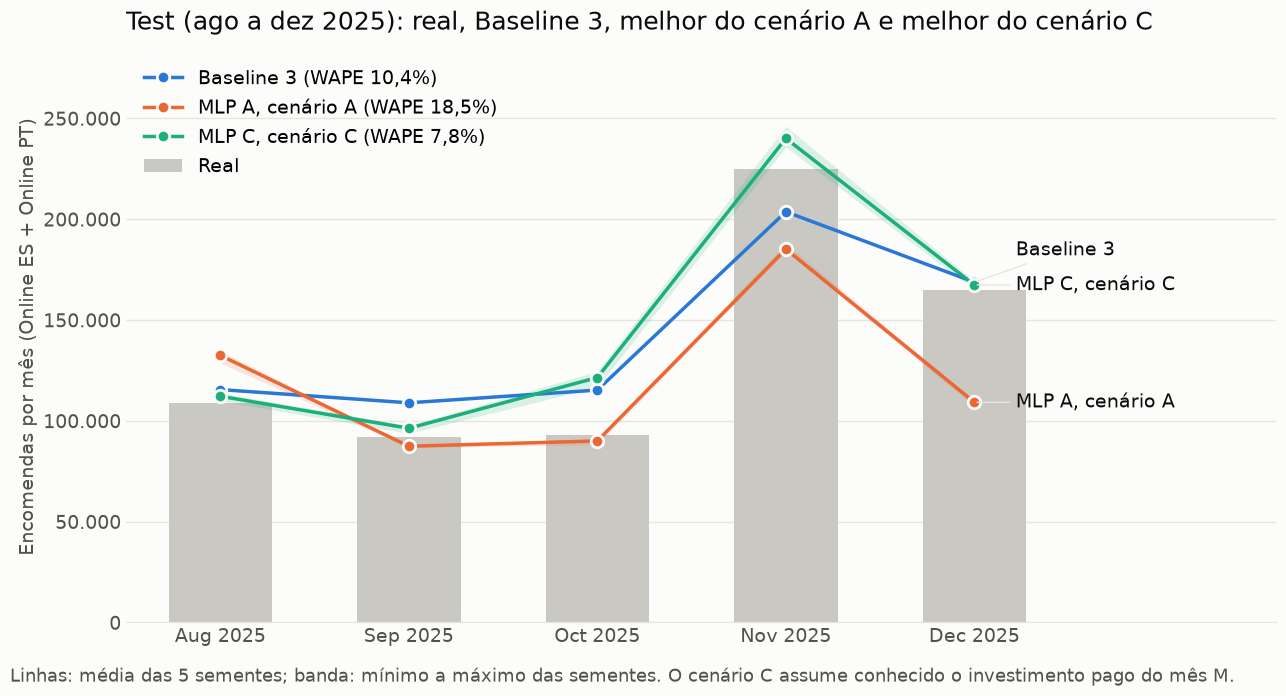

In [74]:
import numpy as np
import pandas as pd
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Gráfico do Test (ago a dez 2025): real, Baseline 3, melhor do cenário A e melhor do cenário C (totais mensais ES + PT).
# Usa as previsões guardadas no ponto 27 (só leitura) e a Baseline 3 já calculada no ponto 4. Não treina nada.
for nome in ['TEST', 'MARKETS', 'SEEDS', 'REAL', 'metricas', 'tot', 'rtot']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação e de recuperação.")

# ---------- 1. Baseline 3 mensal: procura a tabela já calculada no ponto 4 ----------
def acha_b3():
    for nome, v in list(globals().items()):
        if isinstance(v, pd.DataFrame) and {'method', 'month', 'forecast'} <= set(v.columns) and v['method'].astype(str).eq('B3 monthly').any():
            return f"variável '{nome}'", v[v['method'] == 'B3 monthly'].copy()
    for f in ['fc_baselines.parquet', 'fc_baselines.csv']:                                   # ficheiro gravado no notebook das baselines, se estiver na pasta
        if Path(f).exists():
            v = pd.read_parquet(f) if f.endswith('.parquet') else pd.read_csv(f)
            return f"ficheiro '{f}'", v[v['method'] == 'B3 monthly'].copy()
    return None, None
origem, b3_df = acha_b3()
if b3_df is None:
    cand = [(n, v.shape, list(v.columns)[:8]) for n, v in globals().items() if isinstance(v, pd.DataFrame) and 'method' in v.columns]
    print('Tabelas com coluna "method" no notebook:')
    for c in cand:
        print('  ', c)
    raise RuntimeError('Não encontrei a B3 mensal. Envia-me esta lista e o nome certo.')
b3_df['month'] = pd.PeriodIndex(b3_df['month'].astype(str), freq='M')
b3_df = b3_df[b3_df['mark'].isin(MARKETS)]
b3 = np.array([b3_df[b3_df['month'] == m]['forecast'].sum() for m in TEST], dtype=float)
assert all((b3_df['month'] == m).sum() == len(MARKETS) for m in TEST), 'faltam previsões da B3 em algum mês do Test'
print(f"B3 mensal lida de: {origem}")

# ---------- 2. séries dos modelos (média e amplitude das 5 sementes) ----------
MELHOR_A = 'MLP A (reference A)'           # troca por 'TFT base (headline A)' para o resultado principal declarado no protocolo
MELHOR_C = 'MLP C (headline C)'
prev = pickle.load(open('evidence_dl/test_forecasts.pkl', 'rb'))
def serie(nome):
    por_semente = np.array([[prev[(nome, s, str(m))]['forecast'].sum() for m in TEST] for s in SEEDS])      # (sementes, meses)
    wapes = [metricas({(m, mk): float(prev[(nome, s, str(m))].query('mark == @mk')['forecast'].sum()) for m in TEST for mk in MARKETS}, TEST)[0] for s in SEEDS]
    return por_semente.mean(0), por_semente.min(0), por_semente.max(0), float(np.mean(wapes))
real = np.array([rtot(m) for m in TEST])
b3_wape = np.abs(b3 - real).sum() / real.sum()
print(f"Controlo: WAPE da Baseline 3 recalculado: {100 * b3_wape:.1f}% (o protocolo diz 10,4%)".replace('.', ','))
assert abs(b3_wape - 0.104) < 0.0006, 'o WAPE da B3 não bate com o do protocolo: não uses este gráfico'
a_m, a_lo, a_hi, a_w = serie(MELHOR_A)
c_m, c_lo, c_hi, c_w = serie(MELHOR_C)
pt = lambda x: f"{100 * x:.1f}%".replace('.', ',')

# ---------- 3. gráfico ----------
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e6e5e1'
COR = {'real': '#c9c8c3', 'b3': '#2a78d6', 'a': '#eb6834', 'c': '#1baf7a'}        # azul, laranja, verde-água: as 3 primeiras cores categóricas, por ordem fixa
x = np.arange(len(TEST))
fig, ax = plt.subplots(figsize=(13, 7), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.bar(x, real, width=0.55, color=COR['real'], label='Real', zorder=1)
fins = []                                                                          # pontos finais das linhas, para afastar as etiquetas
for chave, y, lo, hi, nome in [('b3', b3, None, None, f'Baseline 3 (WAPE {pt(b3_wape)})'),
                               ('a', a_m, a_lo, a_hi, f"{MELHOR_A.split(' (')[0]}, cenário A (WAPE {pt(a_w)})"),
                               ('c', c_m, c_lo, c_hi, f"{MELHOR_C.split(' (')[0]}, cenário C (WAPE {pt(c_w)})")]:
    if lo is not None:
        ax.fill_between(x, lo, hi, color=COR[chave], alpha=0.15, linewidth=0, zorder=2)          # amplitude entre as 5 sementes
    ax.plot(x, y, color=COR[chave], linewidth=2.5, marker='o', markersize=9, markeredgecolor=SURFACE, markeredgewidth=2, label=nome, zorder=3)
    fins.append((float(y[-1]), nome.split(' (')[0]))
topo = max(real.max(), b3.max(), a_hi.max(), c_hi.max())
fins.sort()
pos = [f[0] for f in fins]
for i in range(1, len(pos)):
    if pos[i] - pos[i - 1] < 0.07 * topo:                                          # mínimo de afastamento entre etiquetas
        pos[i] = pos[i - 1] + 0.07 * topo
for (y0, txt), yp in zip(fins, pos):                                               # etiqueta direta em tinta de texto, ligada ao ponto por uma linha fina
    ax.annotate(txt, xy=(x[-1], y0), xytext=(x[-1] + 0.22, yp), textcoords='data', va='center', fontsize=14, color=INK,
                arrowprops=dict(arrowstyle='-', color=GRID, linewidth=1))
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %Y') for m in TEST], fontsize=14, color=INK2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}".replace(',', '.')))
ax.tick_params(axis='y', labelsize=14, colors=INK2, length=0); ax.tick_params(axis='x', length=0)
ax.set_ylabel('Encomendas por mês (Online ES + Online PT)', fontsize=14, color=INK2)
ax.set_xlim(-0.5, len(TEST) - 0.5 + 1.1); ax.set_ylim(0, topo * 1.15)
ax.grid(axis='y', color=GRID, linewidth=1); ax.set_axisbelow(True)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.spines['bottom'].set_color(GRID)
ax.set_title('Test (ago a dez 2025): real, Baseline 3, melhor do cenário A e melhor do cenário C', fontsize=18, color=INK, loc='left', pad=16)
ax.legend(frameon=False, fontsize=14, loc='upper left', ncol=1)
fig.text(0.01, 0.01, 'Linhas: média das 5 sementes; banda: mínimo a máximo das sementes. O cenário C assume conhecido o investimento pago do mês M.', fontsize=13, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

# Eficiência: tempo O(sementes · meses) e espaço O(sementes · meses) para somar as previsões guardadas; o desenho é O(meses).

### 28e. Exploratório: modelo semanal (posterior ao Test)

**Pergunta.** Prever por semana em vez de por dia melhora o cenário A ou o C? Mantêm-se os mesmos MLP (A: MSE, 32 unidades, 300 épocas; C: Huber, 32 unidades, 100 épocas), os mesmos grupos de variáveis, um modelo por mercado, 5 sementes e a regra de corte (dados até ao fim de M-2).

**O que muda.** Cada linha passa a ser uma semana completa (segunda a domingo): o alvo é a soma das encomendas da semana e as variáveis são a média dos dias da semana (por isso as campanhas, feriados e saldos passam a ser fração de dias). O treino usa só semanas completas até ao corte. A previsão do mês M soma as previsões das semanas que o tocam, repartidas pelos dias com o perfil médio do dia da semana de cada mercado (estimado só com dados até ao corte), e só conta os dias do mês M.

**Estatuto.** Corre nos 7 meses do Training e nos 5 do Test, para ler também a regra de substituição (WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes). Como o Test já está aberto, é exploratório e posterior ao Test. Não altera o resultado principal nem as conclusões dos pontos 27 e 28. Sem MLflow.

In [76]:
import time
import pickle
import numpy as np
import pandas as pd

# EXPLORATÓRIO, POSTERIOR AO TEST: MLP semanal nos cenários A e C (Training e Test). Sem MLflow; não altera o protocolo nem os ficheiros dos pontos anteriores.
# Usa feat, FEATURE_GROUPS, GA, GCC, CLIP_COLS, SEM_HISTORICO, design_full, fit_mlp, predict, CONFIGS, cfg_name, RES, REAL, MARKETS, SEEDS, ALL7, TEST, JF, GR3,
# metricas, tot, rtot, pc, fmt (células anteriores). A previsão diária do Test vem do ponto 27 (só leitura).
for nome in ['feat', 'FEATURE_GROUPS', 'GA', 'GCC', 'CLIP_COLS', 'SEM_HISTORICO', 'design_full', 'fit_mlp', 'predict', 'CONFIGS', 'cfg_name', 'RES', 'REAL', 'MARKETS', 'SEEDS',
             'ALL7', 'TEST', 'JF', 'GR3', 'metricas', 'tot', 'rtot', 'pc', 'fmt']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação, as do MLP e o ponto 27.")
por_nome = {cfg_name(c): c for c in CONFIGS}
SC = {'A': (GA + ['saldos'], por_nome['mse_32_e300'], ('A_saldos', 'per_market'), 'mse_32_e300', 'MLP A (reference A)'),
      'C': (GCC + ['saldos'], por_nome['huber_32_e100'], ('C_saldos', 'per_market'), 'huber_32_e100', 'MLP C (headline C)')}
COLS = sorted({c for g in (SC['A'][0] + SC['C'][0]) for c in FEATURE_GROUPS[g]})

# ---------- 1. tabela semanal (semanas de segunda a domingo) ----------
def semanal(feat_df):
    fd = feat_df.copy()
    fd['week'] = fd['day'] - pd.to_timedelta(fd['day'].dt.weekday, unit='D')
    wk = fd.groupby(['mark', 'week']).agg(orders=('orders', 'sum'), n=('day', 'count'), end=('day', 'max'), **{c: (c, 'mean') for c in COLS}).reset_index()
    return fd, wk

def perfil(fd, mk, cut):
    # peso médio de cada dia da semana dentro da semana, só com semanas completas até ao corte
    d = fd[(fd['mark'] == mk) & (fd['day'] <= cut)].copy()
    d['tw'], d['c'] = d.groupby('week')['orders'].transform('sum'), d.groupby('week')['day'].transform('count')
    d = d[(d['c'] == 7) & (d['tw'] > 0)]
    sh = (d['orders'] / d['tw']).groupby(d['day'].dt.weekday).mean()
    return (sh / sh.sum()).reindex(range(7)).to_numpy()

def prever_mes(m, T, groups, cfg, seed, oraculo=False):
    fd, wk = T
    m = pd.Period(m, 'M'); cut = (m - 2).end_time.normalize(); start, end = m.start_time, m.end_time.normalize()
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    out = {}
    for mk in MARKETS:
        w = wk[wk['mark'] == mk]
        tr = w[(w['n'] == 7) & (w['end'] <= cut)]
        tg = w[(w['week'] + pd.Timedelta(days=6) >= start) & (w['week'] <= end)].copy()          # semanas que tocam o mês M
        assert len(tr) > 20 and len(tg) >= 4, 'poucas semanas de treino ou de previsão'
        for c in [c for c in cols if c in CLIP_COLS]:
            tg[c] = tg[c].clip(tr[c].min(), tr[c].max())
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}
        Xtr, Xtg = design_full(tr, groups, False, fill), design_full(tg, groups, False, fill)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd < 1e-8] = 1.0                                                                  # colunas (quase) constantes no treino, por exemplo o dia da semana numa semana completa (1/7)
        assert np.abs((Xtg - mu) / sd).max() < 1e3, f'entrada de previsão muito fora do intervalo do treino ({m}, {mk}): máximo {np.abs((Xtg - mu) / sd).max():.1e}'
        ytr = tr['orders'].to_numpy(float)
        ymu, ysd = ytr.mean(), ytr.std()
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pred = np.maximum(predict(net, (Xtg - mu) / sd) * ysd + ymu, 0.0)
        if oraculo:
            pred = tg['orders'].to_numpy(float) * 7 / tg['n'].to_numpy(float)                # controlo: previsão perfeita da semana
        p = perfil(fd, mk, cut)
        out[mk] = float(sum(pw * sum(p[(wd + pd.Timedelta(days=i)).weekday()] for i in range(7) if start <= wd + pd.Timedelta(days=i) <= end) for wd, pw in zip(tg['week'], pred)))
    return out

# ---------- 2. controlos ----------
T = semanal(feat)
m_or = pd.Period('2025-10', 'M')
orc = prever_mes(m_or, T, SC['A'][0], SC['A'][1], 0, oraculo=True)
razao = sum(orc.values()) / rtot(m_or)
print(f"Controlo 1: com previsão semanal perfeita, a repartição pelos dias reconstrói o mês (out 2025): {razao:.3f} do real (esperado perto de 1)")
assert abs(razao - 1) < 0.05, 'a repartição semana, dia, mês não reconstrói o mês'
M0 = pd.Period('2025-12', 'M'); CUT0 = (M0 - 2).end_time.normalize()
f_leak = feat.copy(); f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
a = prever_mes(M0, T, SC['A'][0], SC['A'][1], 0); b = prever_mes(M0, semanal(f_leak), SC['A'][0], SC['A'][1], 0)
ok_leak = all(abs(a[mk] - b[mk]) < 1e-6 for mk in MARKETS)
print(f"Controlo 2: independente das encomendas depois do corte (dez 2025): {ok_leak}")
assert ok_leak, 'o controlo falhou: não avances; envia-me o output completo.'
print(f"Controlo 3: previsões de dez 2025 (cenário A, semente 0) em ordem de grandeza razoável: {a} contra o real {rtot(M0):,.0f}".replace(',', '.'))

# ---------- 3. correr: Training (7 meses) e Test (5 meses), 5 sementes ----------
t0 = time.time()
RESW = {sc: {s: {} for s in SEEDS} for sc in SC}
for sc, (groups, cfg, _, _, _) in SC.items():
    for s in SEEDS:
        for m in ALL7 + TEST:
            for mk, v in prever_mes(m, T, groups, cfg, s).items():
                RESW[sc][s][(m, mk)] = v
    print(f"cenário {sc} feito | {round((time.time() - t0) / 60, 1)} min", flush=True)

# ---------- 4. comparação com o MLP diário ----------
prev = pickle.load(open('evidence_dl/test_forecasts.pkl', 'rb'))
def diario(sc, s):
    _, _, chave, nome, nome_p = SC[sc]
    r = dict(RES[chave][nome][s])                                                          # Training (ponto 22/recuperação)
    r.update({(m, mk): float(prev[(nome_p, s, str(m))].query('mark == @mk')['forecast'].sum()) for m in TEST for mk in MARKETS})   # Test (ponto 27)
    return r
lin = []
for sc in SC:
    for split, steps in [('Training', ALL7), ('Test', TEST)]:
        wd = np.array([metricas(diario(sc, s), steps)[0] for s in SEEDS]); ww = np.array([metricas(RESW[sc][s], steps)[0] for s in SEEDS])
        for nome, r_list, w in [('daily MLP', [diario(sc, s) for s in SEEDS], wd), ('weekly MLP (exploratory)', [RESW[sc][s] for s in SEEDS], ww)]:
            Mx = [metricas(r, steps) for r in r_list]
            ext = {'Seeds better than daily': '-', 'Rule vs daily': '-'}
            if nome.startswith('weekly'):
                n = int((ww < wd).sum()); ext = {'Seeds better than daily': f"{n} of {len(SEEDS)}", 'Rule vs daily': 'weekly replaces' if ww.mean() < wd.mean() and n >= len(SEEDS) - 1 else 'weekly does not replace'}
            lin.append({'Scenario': sc, 'Split': split, 'Model': nome, 'WAPE (mean of seeds)': pc(w.mean()), 'WAPE (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'Bias': pc(np.mean([x[1] for x in Mx])),
                        'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), **ext})
print("\n--- EXPLORATÓRIO, posterior ao Test: modelo semanal contra o diário (ES + PT somados por mês; 5 sementes) ---")
display(pd.DataFrame(lin))
mes = []
for sc in SC:
    for nome, get in [('daily MLP', lambda s: diario(sc, s)), ('weekly MLP (exploratory)', lambda s: RESW[sc][s])]:
        r_list = [get(s) for s in SEEDS]
        mes.append({'Scenario': sc, 'Model': nome, **{m.strftime('%b %y'): pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m)) for m in ALL7 + TEST}})
print("\nErro por mês (previsão média menos o real, em % do real; ES + PT):")
display(pd.DataFrame(mes))

# Eficiência: tempo O(cenários · meses · sementes · mercados · custo de treino) = 2·12·5·2 = 240 treinos, cada um O(épocas · semanas · parâmetros) com poucas dezenas ou centenas de semanas; espaço O(semanas · variáveis).

Controlo 1: com previsão semanal perfeita, a repartição pelos dias reconstrói o mês (out 2025): 1.005 do real (esperado perto de 1)
Controlo 2: independente das encomendas depois do corte (dez 2025): True
Controlo 3: previsões de dez 2025 (cenário A. semente 0) em ordem de grandeza razoável: {'Online ES': 93313.86865529307. 'Online PT': 24759.472893085494} contra o real 164.657
cenário A feito | 1.0 min
cenário C feito | 1.4 min

--- EXPLORATÓRIO, posterior ao Test: modelo semanal contra o diário (ES + PT somados por mês; 5 sementes) ---


,Scenario,Split,Model,WAPE (mean of seeds),WAPE (min to max),Bias,RMSE,R2,Seeds better than daily,Rule vs daily
0,A,Training,daily MLP,"24,8%","24,2% to 25,7%","-23,9%",38.984,"-0,09",-,-
1,A,Training,weekly MLP (exploratory),"26,7%","26,1% to 27,7%","-25,8%",42.091,"-0,27",0 of 5,weekly does not replace
2,A,Test,daily MLP,"18,5%","18,2% to 19,0%","-11,7%",32.437,"0,60",-,-
3,A,Test,weekly MLP (exploratory),"18,4%","18,0% to 19,3%","-8,7%",31.860,"0,62",3 of 5,weekly does not replace
4,C,Training,daily MLP,"8,2%","5,4% to 11,3%","3,1%",12.002,"0,89",-,-
5,C,Training,weekly MLP (exploratory),"14,1%","9,8% to 15,6%","-0,7%",25.984,"0,51",0 of 5,weekly does not replace
6,C,Test,daily MLP,"7,8%","6,8% to 8,5%","7,8%",14.860,"0,92",-,-
7,C,Test,weekly MLP (exploratory),"15,6%","14,5% to 16,9%","7,5%",25.289,"0,76",0 of 5,weekly does not replace



Erro por mês (previsão média menos o real, em % do real; ES + PT):


,Scenario,Model,Jan 25,Feb 25,Mar 25,Apr 25,May 25,Jun 25,Jul 25,Aug 25,Sep 25,Oct 25,Nov 25,Dec 25
0,A,daily MLP,"-41,7%","-24,3%","4,4%","-11,2%","-15,4%","-29,5%","-25,2%","21,4%","-5,2%","-3,0%","-17,7%","-33,7%"
1,A,weekly MLP (exploratory),"-43,8%","-30,4%","5,0%","-14,6%","-11,4%","-28,0%","-30,1%","30,4%","-3,9%","-0,7%","-17,6%","-29,7%"
2,C,daily MLP,"6,7%","11,8%","4,1%","15,7%","4,7%","-5,4%","-8,6%","2,9%","4,5%","30,8%","6,7%","1,6%"
3,C,weekly MLP (exploratory),"-33,8%","6,6%","13,8%","15,9%","9,2%","8,1%","2,3%","10,5%","15,0%","47,5%","-12,3%","5,9%"


### 28e. Conclusões (exploratório, posterior ao Test)

**A granularidade semanal não ajudou.** Com o mesmo MLP e as mesmas variáveis, o modelo semanal não substitui o diário em nenhum dos cenários, pela regra de sempre (WAPE médio mais baixo e melhor em pelo menos 4 de 5 sementes).

**Cenário A.** No Training o semanal fica pior (WAPE de 26,7% contra 24,8%, 0 de 5 sementes). No Test fica praticamente igual (18,4% contra 18,5%, melhor em 3 de 5 sementes), com viés um pouco menor (-8,7% contra -11,7%) e R² mensal de 0,62 contra 0,60. Em dezembro continua a subestimar (-29,7% contra -33,7%), e em novembro fica igual (-17,6% contra -17,7%). A granularidade não corrige o erro de fim de ano do cenário A.

**Cenário C.** Piora claramente, no Training (14,1% contra 8,2%) e no Test (15,6% contra 7,8%), em 0 de 5 sementes, com R² mensal de 0,76 contra 0,92. O erro de outubro sobe para +47,5% (diário: +30,8%) e janeiro passa a -33,8% (diário: +6,7%).

**Leitura.** O erro do diário que desaparece ao agregar à semana ou ao mês não é o que limita os modelos. Mas esta experiência não prova que a semana não serve: o MLP semanal tem muito menos linhas de treino (cerca de 45 semanas por mercado em janeiro de 2025, contra mais de 300 dias), os hiperparâmetros foram os do diário sem afinação, e a repartição pelos dias usa um perfil médio do dia da semana que é uma aproximação.

**Limitações.** Análise posterior ao Test, hiperparâmetros do diário reaproveitados, poucas linhas de treino, repartição aproximada nas semanas parciais (em especial as do início e do fim de cada mês) e só dois modelos (MLP A e MLP C).

In [77]:
import pickle
estado = {k: globals()[k] for k in ['RES', 'RES_T', 'RES_TUNE', 'RESW'] if k in globals()}
pickle.dump(estado, open('evidence_dl/estado_final.pkl', 'wb'))
print('Guardado:', list(estado))

Guardado: ['RES', 'RES_T', 'RES_TUNE', 'RESW']


### 28f. Exploratório (posterior ao Test): LSTM do cenário C com campanhas

**Pergunta.** A rede com memória (LSTM) do cenário C, com saldos e campanhas fixas, generaliza no Test? Configuração fixada no Training: janela de 14 dias, 300 épocas, 1 camada de 32 unidades, perda Huber, um modelo por mercado, 5 sementes (`lstm_w14_e300`, WAPE de 9,9% no Training e 7,1% em maio a julho).

**Estatuto.** No Training não substituiu o MLP C (melhor em 2 de 5 sementes), por isso não entrava no Test pelo protocolo. Esta análise é exploratória e posterior ao Test, não altera o resultado principal nem as conclusões dos pontos 27 e 28. Compara-se com o MLP C (resultado principal) e com o MLP C com campanhas (sensibilidade), que tem as mesmas variáveis. Sem MLflow.

In [52]:
# Verificação: lista as variáveis que a 28f precisa e que ainda não existem no kernel
precisa = ['feat', 'FEATURE_GROUPS', 'design_full', 'SEM_HISTORICO', 'CLIP_COLS', 'LOSSES', 'FIXED',
           'GCC', 'MARKETS', 'SEEDS', 'TARGETS', 'split_of', 'REAL', 'metricas', 'tot', 'rtot', 'pc', 'fmt']
em_falta = [n for n in precisa if n not in globals()]
print("Em falta:", em_falta if em_falta else "nada, podes correr a 28f")

Em falta: nada, podes correr a 28f


In [60]:
import os, pickle, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from numpy.lib.stride_tricks import sliding_window_view

# EXPLORATÓRIO, POSTERIOR AO TEST: LSTM do cenário C com campanhas (lstm_w14_e300, perda Huber) no Test. Sem MLflow; não altera o protocolo nem o ponto 27.
# Autónoma em relação à célula 17a: copia as funções do LSTM. Usa feat, FEATURE_GROUPS, design_full, SEM_HISTORICO, CLIP_COLS, LOSSES, FIXED, GCC, MARKETS, SEEDS, TARGETS, split_of,
# REAL, metricas, tot, rtot, pc, fmt (células anteriores) e as previsões guardadas do ponto 27 (só leitura).
for nome in ['feat', 'FEATURE_GROUPS', 'design_full', 'SEM_HISTORICO', 'CLIP_COLS', 'LOSSES', 'FIXED', 'GCC', 'MARKETS', 'SEEDS', 'TARGETS', 'split_of', 'REAL', 'metricas', 'tot', 'rtot', 'pc', 'fmt']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro as células de preparação, de recuperação e as do MLP.")
torch.set_num_threads(1)
TEST = [t for t in TARGETS if split_of(t) == 'Test']
GROUPS = GCC + ['saldos', 'campaigns']; LOSS = 'huber'; HIDDEN = 32
CFG = {'window': 14, 'epochs': 300}

class LSTMNet(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.lstm = nn.LSTM(d, hidden, num_layers=1, batch_first=True)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.out(o[:, -1, :])

def lstm_fit(Xw, y, cfg, loss, seed):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = LSTMNet(Xw.shape[2], HIDDEN)
    opt = torch.optim.Adam(net.parameters(), lr=FIXED['lr'], weight_decay=FIXED['weight_decay'])
    lossf = LOSSES[loss]()
    Xt = torch.from_numpy(np.ascontiguousarray(Xw, dtype=np.float32)); yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), FIXED['batch']
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad(); lossf(net(Xt[idx]), yt[idx]).backward(); opt.step()
    return net

def lstm_prever(m, feat_df, groups, cfg, loss, seed):
    # Previsão diária do mês m, treinando só com dias até ao fim de M-2 (mesma lógica da célula 17a). Entradas: calendário, saldos, campanhas e pago; nunca encomendas depois do corte.
    m = pd.Period(m, 'M'); W = cfg['window']
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    out = []
    for mk in MARKETS:
        mdf = feat_df[feat_df['mark'] == mk].sort_values('day').reset_index(drop=True).copy()
        assert (mdf['day'].diff().dropna() == pd.Timedelta(days=1)).all(), 'a série diária tem de ser contínua'
        trm, tgm = (mdf['month'] <= m - 2).to_numpy(), (mdf['month'] == m).to_numpy()
        tr = mdf[trm]
        assert tr['day'].max() <= (m - 2).end_time.normalize(), 'fuga de informação: dias de treino depois do corte'
        for c in [c for c in cols if c in CLIP_COLS]:
            mdf[c] = mdf[c].clip(tr[c].min(), tr[c].max())
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}
        X = design_full(mdf, groups, False, fill)
        mu, sd = X[trm].mean(0), X[trm].std(0)
        sd[sd < 1e-8] = 1.0
        Xn = (X - mu) / sd
        Xp = np.vstack([np.zeros((W - 1, Xn.shape[1])), Xn])
        Xw = sliding_window_view(Xp, (W, Xn.shape[1]))[:, 0]
        y = mdf['orders'].to_numpy(float); ytr = y[trm]
        ymu, ysd = ytr.mean(), ytr.std()
        net = lstm_fit(Xw[trm], (ytr - ymu) / ysd, cfg, loss, seed)
        net.eval()
        with torch.no_grad():
            pred = net(torch.from_numpy(np.ascontiguousarray(Xw[tgm], dtype=np.float32))).numpy().ravel() * ysd + ymu
        out.append(pd.DataFrame({'mark': mk, 'day': mdf.loc[tgm, 'day'].to_numpy(), 'forecast': np.maximum(pred, 0.0)}))
    return pd.concat(out, ignore_index=True)

# ---------- controlo: as encomendas depois do corte não podem influenciar a previsão (configuração leve só para o controlo) ----------
M0 = pd.Period('2025-12', 'M'); CUT0 = (M0 - 2).end_time.normalize()
f_leak = feat.copy(); f_leak.loc[f_leak['day'] > CUT0, 'orders'] = f_leak.loc[f_leak['day'] > CUT0, 'orders'] * 10
ctrl = {'window': 14, 'epochs': 2}
ok = bool(np.allclose(lstm_prever(M0, feat, GROUPS, ctrl, LOSS, 0)['forecast'], lstm_prever(M0, f_leak, GROUPS, ctrl, LOSS, 0)['forecast']))
print(f"Controlo: independente das encomendas depois do corte (dez 2025): {ok}")
assert ok, 'o controlo falhou: não avances; envia-me o output completo.'

# ---------- correr no Test (5 sementes; retoma se for interrompido) ----------
fich = 'evidence_dl/test_explor_lstm_Ccamp.pkl'
ex = pickle.load(open(fich, 'rb')) if os.path.exists(fich) else {}
total, t0, novos = len(SEEDS) * len(TEST), time.time(), 0
for s in SEEDS:
    for m in TEST:
        if (s, str(m)) in ex:
            continue
        d = lstm_prever(m, feat, GROUPS, CFG, LOSS, s)
        assert set(d['mark']) == set(MARKETS) and d['day'].min() == m.start_time and d['day'].max() == m.end_time.normalize() and np.isfinite(d['forecast']).all()
        ex[(s, str(m))] = d
        pickle.dump(ex, open(fich, 'wb')); novos += 1
        print(f"semente {s} | {m.strftime('%b %Y')} | {round((time.time() - t0) / 60, 1)} min | faltam {total - len(ex)} (cerca de {(total - len(ex)) * (time.time() - t0) / novos / 60:.0f} min)", flush=True)

# ---------- comparação com o MLP C e o MLP C com campanhas (do ponto 27) ----------
prev = pickle.load(open('evidence_dl/test_forecasts.pkl', 'rb'))
real_d = feat[(feat['day'] >= TEST[0].start_time) & (feat['day'] <= TEST[-1].end_time.normalize())][['mark', 'day', 'orders']]
def mensal(by_month):
    return {(m, mk): float(by_month[str(m)].query('mark == @mk')['forecast'].sum()) for m in TEST for mk in MARKETS}
def r2(a, f):
    return 1 - ((f - a) ** 2).sum() / ((a - a.mean()) ** 2).sum()
fontes = {'LSTM C with campaigns (exploratory, post-Test)': lambda s: {str(m): ex[(s, str(m))] for m in TEST},
          'MLP C (headline C)': lambda s: {str(m): prev[('MLP C (headline C)', s, str(m))] for m in TEST},
          'MLP C + campaigns (sensitivity)': lambda s: {str(m): prev[('MLP C + campaigns (sensitivity)', s, str(m))] for m in TEST}}
lin, mes, nd = [], [], []
for nome, get in fontes.items():
    r_list = [mensal(get(s)) for s in SEEDS]
    Mx = [metricas(r, TEST) for r in r_list]
    w = np.array([x[0] for x in Mx])
    rd, wd = [], []
    for s in SEEDS:
        d = pd.concat(get(s).values(), ignore_index=True)[['mark', 'day', 'forecast']].merge(real_d, on=['mark', 'day'], validate='one_to_one').groupby('day')[['orders', 'forecast']].sum()
        rd.append(r2(d['orders'].to_numpy(), d['forecast'].to_numpy())); wd.append(np.abs(d['forecast'] - d['orders']).sum() / d['orders'].sum())
    lin.append({'Model': nome, 'WAPE monthly (mean of seeds)': pc(w.mean()), 'WAPE monthly (min to max)': f"{pc(w.min())} to {pc(w.max())}", 'Bias': pc(np.mean([x[1] for x in Mx])),
                'RMSE': fmt(np.mean([x[2] for x in Mx])), 'R2 monthly': f"{np.mean([x[3] for x in Mx]):.2f}".replace('.', ','), 'WAPE daily': pc(np.mean(wd)), 'R2 daily': f"{np.mean(rd):.2f}".replace('.', ',')})
    mes.append({'Model': nome, **{m.strftime('%b'): pc((np.mean([tot(x, m) for x in r_list]) - rtot(m)) / rtot(m)) for m in TEST}})
    for m in TEST[-2:]:
        nd.append({'Model': nome, 'Month': m.strftime('%b %Y'), **{f'Error {mk}': pc((np.mean([x[(m, mk)] for x in r_list]) - REAL[(mk, m)]) / REAL[(mk, m)]) for mk in MARKETS}})
print("\n--- EXPLORATÓRIO, posterior ao Test: LSTM do cenário C com campanhas (não é resultado principal) ---")
display(pd.DataFrame(lin))
print("\nErro por mês (previsão média menos o real, em % do real; ES + PT):")
display(pd.DataFrame(mes))
print("\nNovembro e dezembro por mercado:")
display(pd.DataFrame(nd))

# Eficiência: tempo O(sementes · meses · mercados · épocas · amostras · janela · h^2) = 50 treinos de LSTM (h = 32); espaço O(janelas · variáveis) por treino.

Controlo: independente das encomendas depois do corte (dez 2025): True
semente 0 | Aug 2025 | 0.5 min | faltam 24 (cerca de 12 min)
semente 0 | Sep 2025 | 1.1 min | faltam 23 (cerca de 13 min)
semente 0 | Oct 2025 | 1.7 min | faltam 22 (cerca de 13 min)
semente 0 | Nov 2025 | 2.3 min | faltam 21 (cerca de 12 min)
semente 0 | Dec 2025 | 3.0 min | faltam 20 (cerca de 12 min)
semente 1 | Aug 2025 | 3.5 min | faltam 19 (cerca de 11 min)
semente 1 | Sep 2025 | 4.1 min | faltam 18 (cerca de 11 min)
semente 1 | Oct 2025 | 4.7 min | faltam 17 (cerca de 10 min)
semente 1 | Nov 2025 | 5.4 min | faltam 16 (cerca de 10 min)
semente 1 | Dec 2025 | 6.0 min | faltam 15 (cerca de 9 min)
semente 2 | Aug 2025 | 6.5 min | faltam 14 (cerca de 8 min)
semente 2 | Sep 2025 | 7.0 min | faltam 13 (cerca de 8 min)
semente 2 | Oct 2025 | 7.5 min | faltam 12 (cerca de 7 min)
semente 2 | Nov 2025 | 8.2 min | faltam 11 (cerca de 6 min)
semente 2 | Dec 2025 | 8.8 min | faltam 10 (cerca de 6 min)
semente 3 | Aug 2025

,Model,WAPE monthly (mean of seeds),WAPE monthly (min to max),Bias,RMSE,R2 monthly,WAPE daily,R2 daily
0,"LSTM C with campaigns (exploratory, post-Test)","8,9%","6,2% to 12,3%","-7,0%",14.874,"0,91","21,2%","0,79"
1,MLP C (headline C),"7,8%","6,8% to 8,5%","7,8%",14.860,"0,92","27,0%","0,78"
2,MLP C + campaigns (sensitivity),"10,8%","9,4% to 12,5%","6,5%",18.687,"0,87","24,0%","0,82"



Erro por mês (previsão média menos o real, em % do real; ES + PT):


,Model,Aug,Sep,Oct,Nov,Dec
0,"LSTM C with campaigns (exploratory, post-Test)","-0,9%","-10,0%","-4,0%","-9,8%","-7,3%"
1,MLP C (headline C),"2,9%","4,5%","30,8%","6,7%","1,6%"
2,MLP C + campaigns (sensitivity),"4,7%","-0,1%","22,2%","14,6%","-8,7%"



Novembro e dezembro por mercado:


,Model,Month,Error Online ES,Error Online PT
0,"LSTM C with campaigns (exploratory, post-Test)",Nov 2025,"-17,1%","11,2%"
1,"LSTM C with campaigns (exploratory, post-Test)",Dec 2025,"-14,4%","18,8%"
2,MLP C (headline C),Nov 2025,"8,9%","0,3%"
3,MLP C (headline C),Dec 2025,"-7,2%","34,3%"
4,MLP C + campaigns (sensitivity),Nov 2025,"9,9%","28,0%"
5,MLP C + campaigns (sensitivity),Dec 2025,"-15,8%","17,5%"
